# Load, modality and the stability of category codes in the human cortex

**A unified representational model of the HCP Working-Memory and Language tasks.**

This notebook is the complete analysis for the project. It runs top to bottom, and it is organised as sixteen
numbered stages: the first three prepare the data, the next six ask the scientific questions, and the last seven
try to break the answers before we believe them.

| stage | what it does |
| --- | --- |
| 0–3 | setup, first-level GLM, one activation pattern per condition, ROI masks, shared figure style |
| 4 | split-half RSA — does a condition's pattern reproduce in the *other run of the same brain*? |
| 5 | leave-one-subject-out decoding — does a pattern mean the same thing in a *different brain*? |
| 6 | a matched resting-state null — what does this pipeline report when there is no task at all? |
| 7 | unit tests for the distance code, RDM inference, and a noise ceiling |
| 8 | the same decoding with a linear SVM, as a cross-check on the classifier |
| 9 | the central analysis: does the category code survive a change of memory load? |
| 10 | cross-task decoding and the shared demand axis (does *difficulty* have its own code?) |
| 11 | confound controls: shared event timing, one-category effects, resting-state decoding |
| 12 | is category information concentrated in the most selective grayordinates? |
| 13 | confirmatory checks on story-versus-math, especially in visual regions |
| 14 | the parietal category code — five checks on the one non-visual region that has one |
| 15 | what "category transfer across load" means, in words |
| 16 | evidence table, one-page summary figure and a plain-language readout |

**Before running.** Set `subject_dir` in Stage 0 to one subject's `Results` folder; everything else is derived from
it. Stage 2 is the slow one (a GLM at 91,282 grayordinates per subject, task and run) and caches its output in
`derivatives/`, so later runs only fit subjects that are new. Figures are written to `derivatives/figures/` and the
novelty tables to `derivatives/novelty/`.

**Conventions used throughout.** The participant is always the unit of replication — no test treats blocks or
grayordinates as independent samples. The two scanner runs are never merged in a reliability analysis: one is
always used to predict the other. Decisions that could be tuned to the data (the ROI definitions, the ridge
strength, the equivalence margins) were fixed before any result was looked at, and each is flagged where it appears.
Figures carry a two-line title that states what the panel shows, so nothing needs to be printed next to a plot.

## Stage 0 — Setup: paths, constants and the two building blocks of the GLM

In [1]:
# =============================================================================
# STAGE 0 - SETUP: paths, constants and the two building blocks of the GLM
# =============================================================================
# This cell only defines things; it reads no data and prints nothing.
#
#   subject_dir  one example subject's Results folder. Every later cell derives DATA_ROOT from it by going three
#                folders up, so the layout <DATA_ROOT>/<subject_id>/MNINonLinear/Results must hold. This is the
#                ONE path to change when the notebook moves to another machine (or set INCM_SUBJECT_DIR in the
#                environment and the line below picks it up automatically).
#   TR = 0.72 s  the real HCP repetition time. The CIFTI header of these files reports 1.0 s, which is wrong, so
#                every design matrix in this notebook uses this constant instead of the header value.
#   DT = 0.01 s  the fine time grid on which block boxcars are convolved with the HRF before being sampled at the TR.
#
# double_gamma_hrf: the canonical haemodynamic response - a positive gamma peaking around 6 s minus a smaller
#   gamma around 16 s that produces the post-stimulus undershoot, scaled so its maximum is 1. Convolving a block
#   with it turns "neurons were active during this block" into "this is the blood-flow signal we expect to measure".
# generate_dct_basis: a set of slow cosine waves used as high-pass filter regressors. Putting them in the design
#   lets the GLM absorb scanner drift (slow signal changes with no relation to the task) instead of mistaking it
#   for a response. hp_cutoff = 128 s keeps everything slower than that out of the condition estimates.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy.special import gamma

# Base path of ONE subject's Results folder. Cell 9 derives DATA_ROOT from it (three folders up), so it must follow
# <DATA_ROOT>/<subject_id>/MNINonLinear/Results
subject_dir = os.environ.get(
    "INCM_SUBJECT_DIR",                                   # set this environment variable to avoid editing the notebook
    "/Users/shwetharao/Downloads/103414/MNINonLinear/Results",
)

TR = 0.72      # HCP TR in seconds (the CIFTI header wrongly reports 1.0)
DT = 0.01


def double_gamma_hrf(t, peak_delay=6.0, undershoot_delay=16.0, peak_disp=1.0, undershoot_disp=1.0, ratio=1/6):
    a1, b1 = peak_delay / peak_disp, peak_disp
    a2, b2 = undershoot_delay / undershoot_disp, undershoot_disp
    peak_gamma = (t ** (a1 - 1) * np.exp(-t / b1)) / (gamma(a1) * (b1 ** a1))
    undershoot_gamma = (t ** (a2 - 1) * np.exp(-t / b2)) / (gamma(a2) * (b2 ** a2))
    hrf = peak_gamma - ratio * undershoot_gamma
    hrf[t < 0] = 0.0
    max_val = np.max(hrf)
    return hrf / max_val if max_val > 0 else hrf


def generate_dct_basis(n_trs=316, tr=0.72, hp_cutoff=128.0):
    k_max = int(np.floor(2 * n_trs * tr / hp_cutoff))
    t = np.arange(n_trs)
    cols = {f"cosine_drift_{k}": np.cos(np.pi * k * (2 * t + 1) / (2 * n_trs)) for k in range(1, k_max + 1)}
    return pd.DataFrame(cols, index=np.arange(n_trs))


## Stage 1 — First-level GLM and design checks

Before any representational analysis, the first-level model is shown to work. This stage fits WM (2-back > 0-back)
and Language (Story > Math) for one subject and produces the quality-control figures: the design matrices, the
motion traces, how well the two runs agree, and how the two contrasts overlap on the surface.

The stage is self-contained and can be skipped when re-running the notebook for the representational results —
nothing downstream depends on it. It is kept because a representational result computed on a badly specified GLM is
not worth checking.

WM_LR: 405 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s
WM_RL: 405 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s
LANGUAGE_LR: 316 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s
  solver check on 500 random grayordinates: r(binned, exact) = 1.00000, max |dt| = 0.014
LANGUAGE_RL: 316 frames x 91282 grayordinates | header TR = 1.000 s | using HCP_TR = 0.72 s

=== Grayordinates above threshold (uncorrected) ===
       map source  positive  negative  pct_pos  pct_neg
WM 2bk>0bk     LR      1062       486     1.16     0.53
WM 2bk>0bk     RL      1178       590     1.29     0.65
WM 2bk>0bk    FFX      2331      1090     2.55     1.19
Story>Math     LR      2873      5798     3.15     6.35
Story>Math     RL       269      1007     0.29     1.10
Story>Math    FFX      3229      6970     3.54     7.64

CROSS-TASK REPORT: WM (2-back > 0-back) vs Language (Story > Math)
Subject 103414 | runs ('LR', 'RL') combine

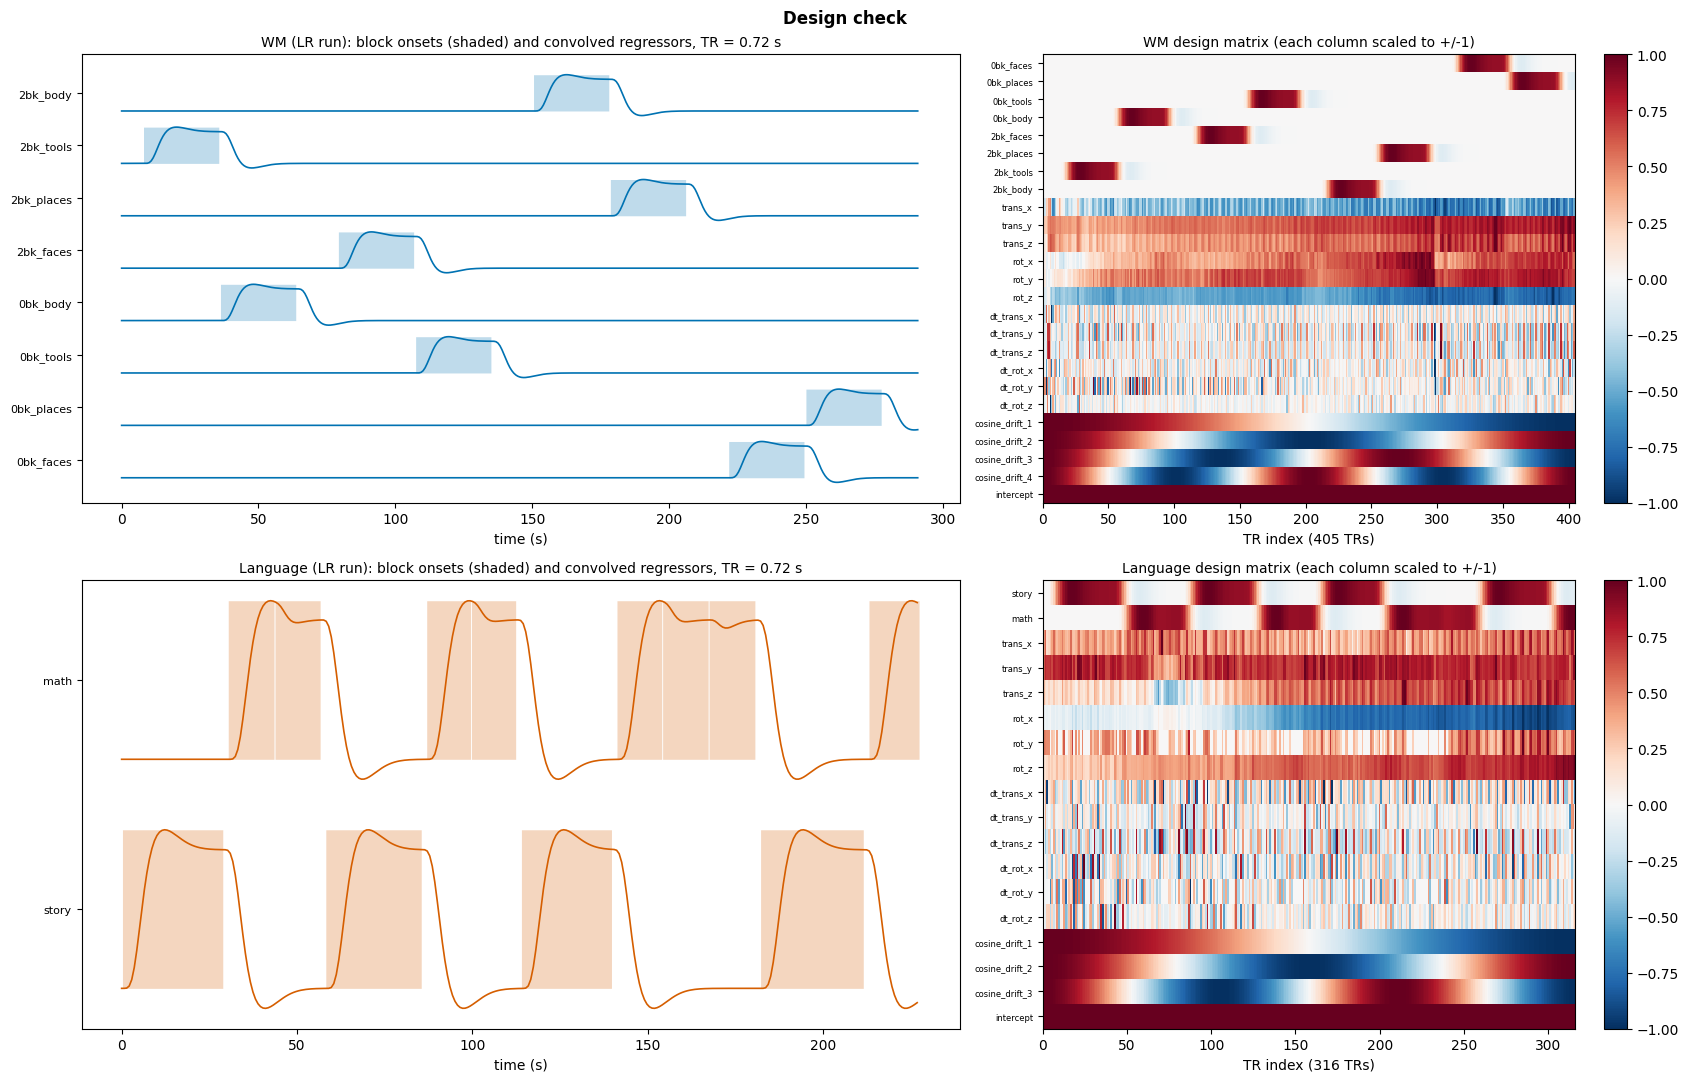

saved /Users/shwetharao/Downloads/figures_cell6/fig1_design_check.png


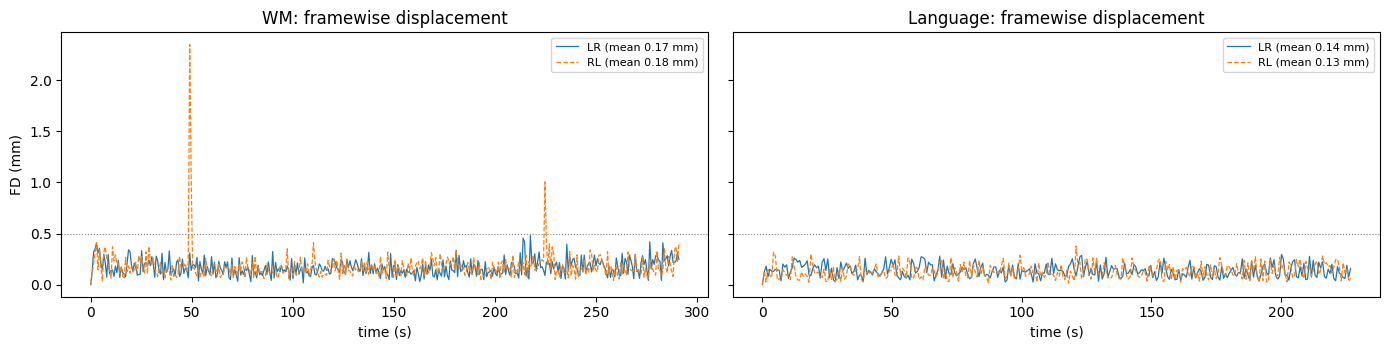

saved /Users/shwetharao/Downloads/figures_cell6/fig2_motion.png


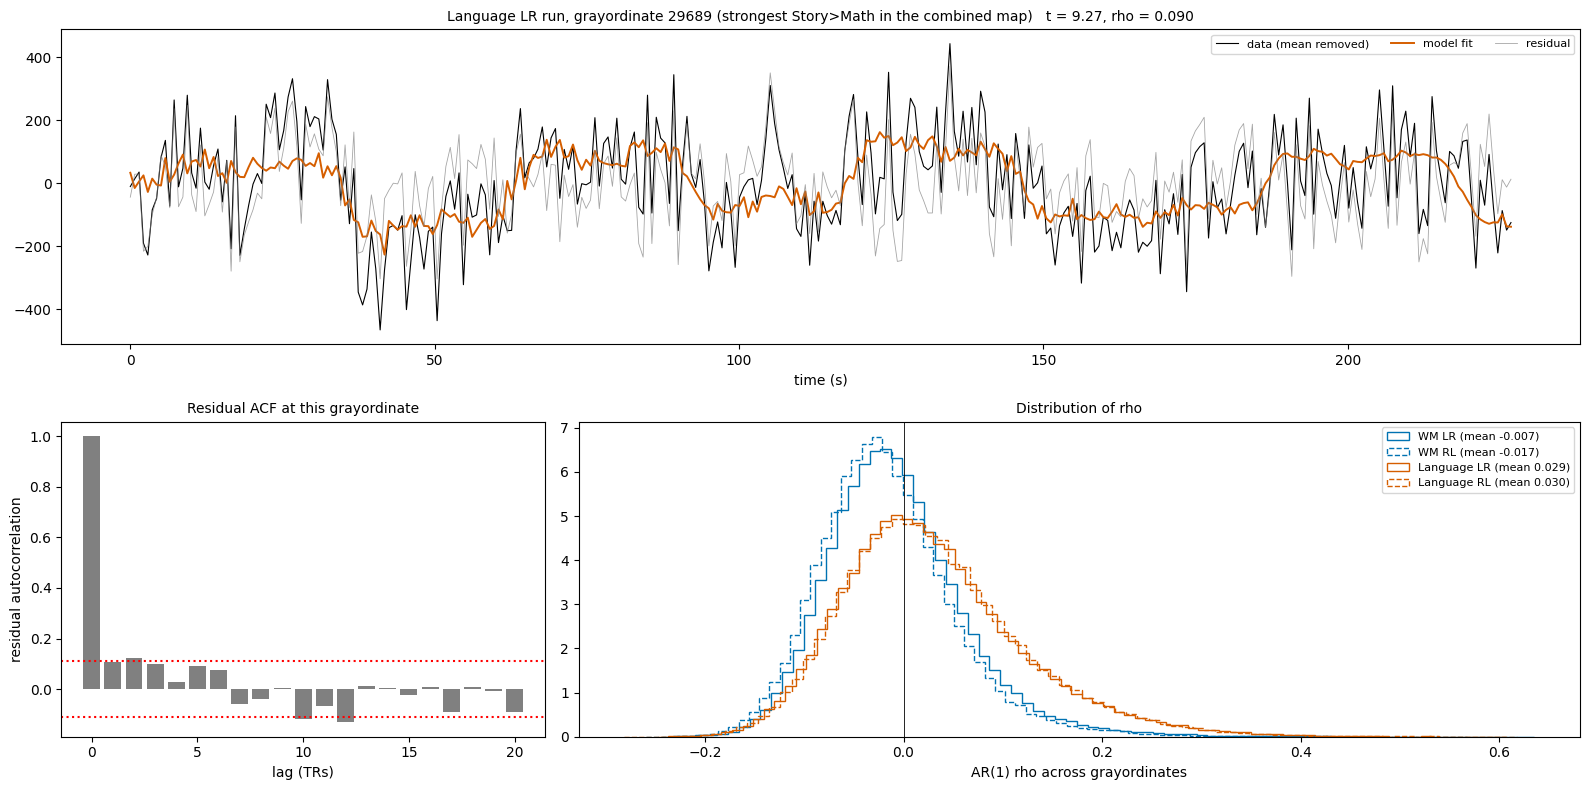

saved /Users/shwetharao/Downloads/figures_cell6/fig3_timecourse_and_rho.png


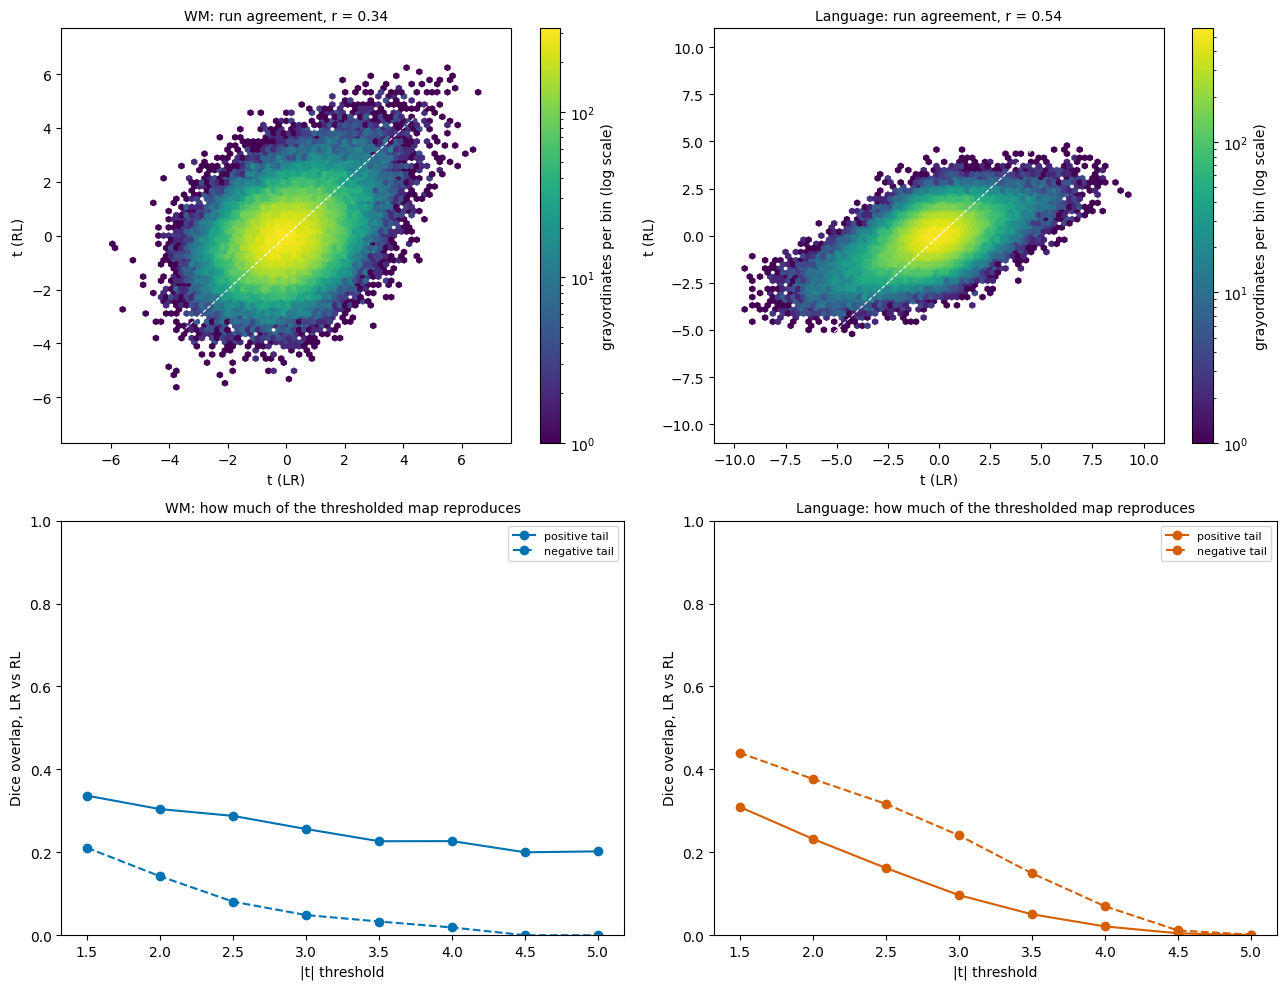

saved /Users/shwetharao/Downloads/figures_cell6/fig4_run_reproducibility.png


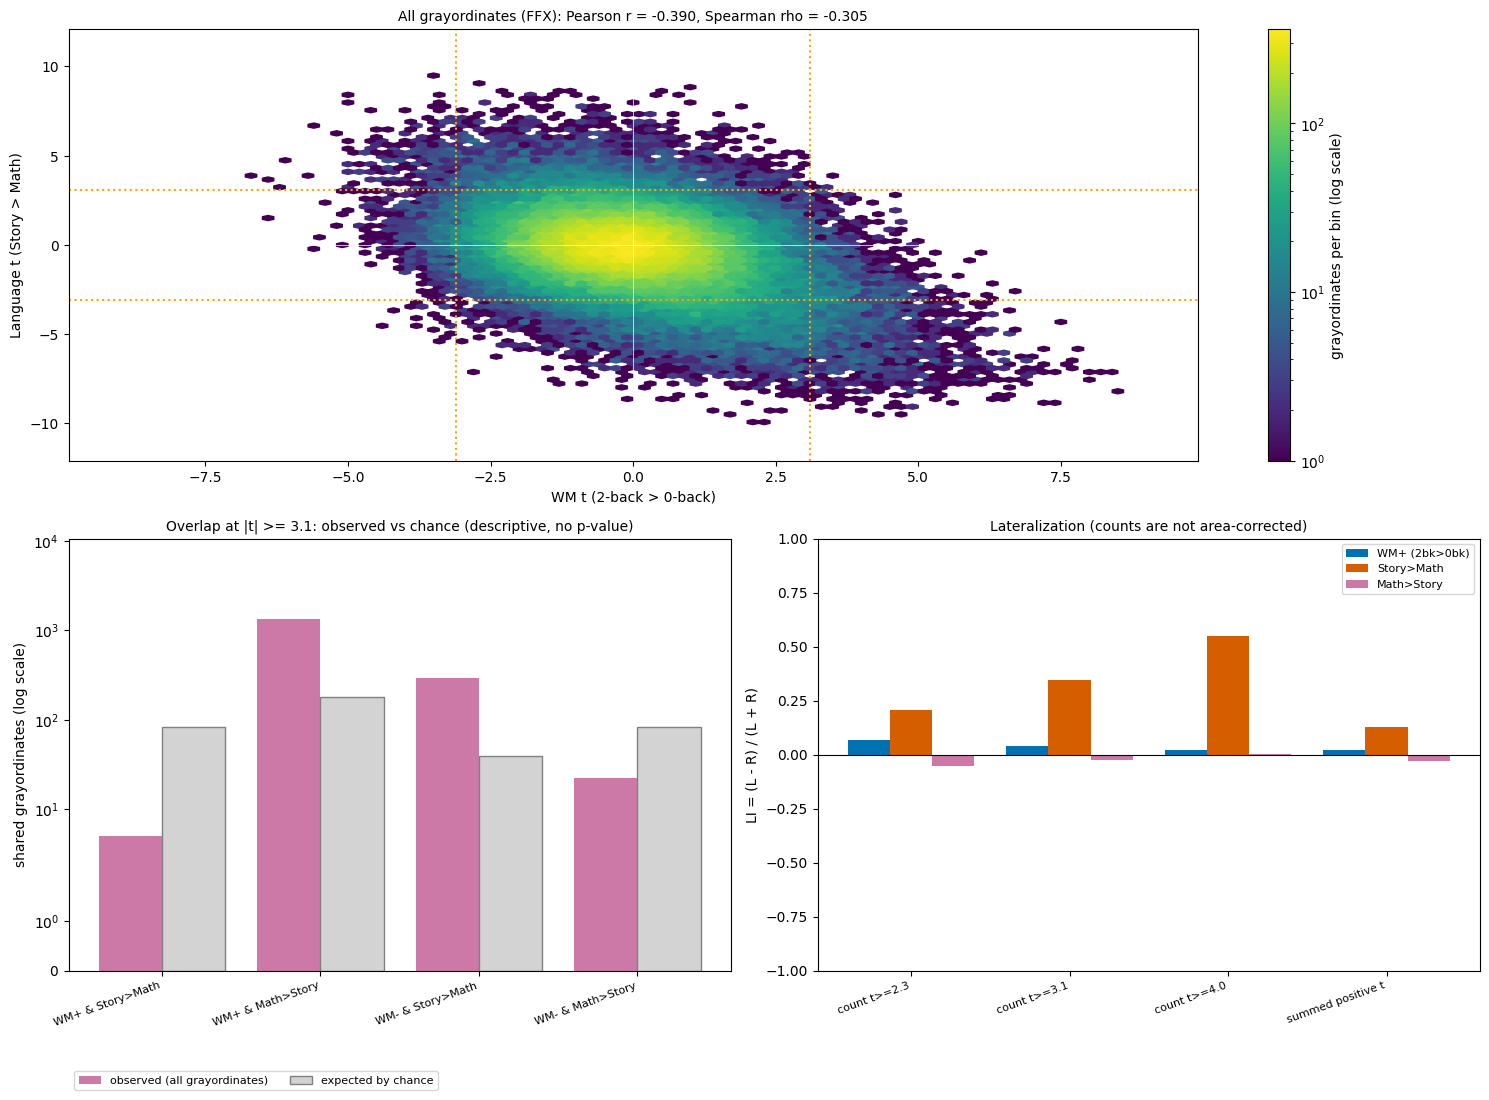

saved /Users/shwetharao/Downloads/figures_cell6/fig5_cross_task.png


In [2]:
# =============================================================================
# STAGE 1 - FIRST-LEVEL GLM AND DESIGN CHECKS (one subject, both tasks)
# =============================================================================
# Purpose: show that the first-level model is set up correctly before any representational analysis is run.
# It fits WM (2-back > 0-back) and Language (Story > Math) for ONE subject and draws the quality-control figures:
# the design matrices, the motion traces, the agreement between the two runs, and the overlap of the two contrasts.
# Self-contained: it needs no other cell.
#
# What this cell is careful about (the numbers refer to the items in our internal review document):
#   1  TR is one constant, HCP_TR = 0.72 s, used for every design matrix and every time axis
#   2  A missing EV, motion or CIFTI file raises an error. Nothing is filled with zeros and nothing is simulated
#   5  The printed report contains only numbers computed from the data; it states no conclusion of its own
#   6  No p-values are computed by treating the 91,282 grayordinates as independent samples, and no map-level
#      p-value is quoted at all: the spin test that would supply one is not run here (see the report's limitations)
#   7  The overlap table compares WM positive / negative against Story > Math and Math > Story, giving the observed
#      overlap and the overlap expected by chance. Both are descriptive, with no p-value attached
#   8  Lateralisation is reported at several thresholds and in a threshold-free form, because a single threshold
#      can manufacture an asymmetry
#   9  Both runs (LR and RL) are fitted separately and combined by inverse-variance (fixed-effects) weighting
#  10  One shared GLM solver is used everywhere (grayordinates binned by their autocorrelation), and it was checked
#      against an exact per-grayordinate solver
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy.special import gamma
from scipy.stats import pearsonr, spearmanr

# ------------------------------------------------------------------------------
# CONFIG  (edit only this block)
# ------------------------------------------------------------------------------
SUBJECT_ID = "103414"
RESULTS_DIR = "/Users/shwetharao/Downloads/103414/MNINonLinear/Results"   # contains tfMRI_WM_LR, ...
HCP_TR = 0.72                    # seconds. The CIFTI header of these files reports 1.0, which is wrong.
RUNS = ("LR", "RL")
T_THRESH = 3.1                   # uncorrected |t| threshold used for counts and overlaps
LI_THRESHOLDS = (2.3, 3.1, 4.0)  # thresholds for the lateralization index
SEED = 2026
FIG_DIR = "figures_cell6"        # every figure is also saved here as PNG

WM_CONDS = ["0bk_faces", "0bk_places", "0bk_tools", "0bk_body",
            "2bk_faces", "2bk_places", "2bk_tools", "2bk_body"]
LANG_CONDS = ["story", "math"]
CIFTI_SUFFIX = "Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii"
EXPECTED_TRS = {"WM": 405, "LANGUAGE": 316}

COL_WM, COL_LANG, COL_BOTH = "#0072B2", "#D55E00", "#CC79A7"    # colour-blind-safe palette

try:                                   # the notebook's working folder may have been deleted or moved
    os.getcwd()
except FileNotFoundError:
    os.chdir(os.path.expanduser("~"))
    print("Working directory no longer existed; switched to", os.getcwd())
FIG_DIR = os.path.abspath(FIG_DIR)
os.makedirs(FIG_DIR, exist_ok=True)


def _loadtxt(path):
    """np.loadtxt on an open file handle (avoids numpy's DataSource, which needs a valid working directory)."""
    with open(path) as fh:
        return np.loadtxt(fh)


def _finish(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", path)


# ------------------------------------------------------------------------------
# 1. DESIGN MATRIX  (HRF, drift, motion, task regressors). Missing files raise errors.
# ------------------------------------------------------------------------------
def double_gamma_hrf(t, peak_delay=6.0, undershoot_delay=16.0,
                     peak_disp=1.0, undershoot_disp=1.0, ratio=1 / 6):
    a1, b1 = peak_delay / peak_disp, peak_disp
    a2, b2 = undershoot_delay / undershoot_disp, undershoot_disp
    with np.errstate(divide="ignore", invalid="ignore"):
        g1 = (t ** (a1 - 1) * np.exp(-t / b1)) / (gamma(a1) * (b1 ** a1))
        g2 = (t ** (a2 - 1) * np.exp(-t / b2)) / (gamma(a2) * (b2 ** a2))
    hrf = np.nan_to_num(g1 - ratio * g2)
    hrf[t < 0] = 0.0
    m = np.max(hrf)
    return hrf / m if m > 0 else hrf


def generate_dct_basis(n_trs, tr, hp_cutoff=128.0):
    k_max = int(np.floor(2 * n_trs * tr / hp_cutoff))
    t = np.arange(n_trs)
    cols = {f"cosine_drift_{k}": np.cos(np.pi * k * (2 * t + 1) / (2 * n_trs)) for k in range(1, k_max + 1)}
    return pd.DataFrame(cols, index=np.arange(n_trs))


MOTION_COLS = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z",
               "dt_trans_x", "dt_trans_y", "dt_trans_z", "dt_rot_x", "dt_rot_y", "dt_rot_z"]


def load_motion_regressors(filepath, n_trs):
    if not os.path.isfile(filepath):
        raise FileNotFoundError(filepath)
    data = _loadtxt(filepath)
    if data.shape[0] < n_trs or data.shape[1] < 12:
        raise ValueError(f"{filepath}: shape {data.shape}, need at least ({n_trs}, 12)")
    return pd.DataFrame(data[:n_trs, :12], columns=MOTION_COLS, index=np.arange(n_trs))


def build_task_regressors(evs_dir, cond_names, n_trs, tr, dt=0.01):
    """Block boxcar (from EV files: onset, duration, amplitude) convolved with the HRF, sampled at the TR grid.
    Returns the regressors and the high-resolution boxcars (used by the timing plot)."""
    t_high = np.arange(0, n_trs * tr, dt)
    t_tr = np.arange(n_trs) * tr
    hrf = double_gamma_hrf(np.arange(0, 32.0, dt))
    regs, boxes = {}, {"t_high": t_high}
    for name in cond_names:
        f = os.path.join(evs_dir, name + ".txt")
        if not (os.path.isfile(f) and os.path.getsize(f) > 0):
            raise FileNotFoundError(f)
        ev = np.atleast_2d(_loadtxt(f))
        box = np.zeros_like(t_high)
        for onset, dur, amp in ev[:, :3]:
            box[(t_high >= onset) & (t_high < onset + dur)] = amp
        conv = np.convolve(box, hrf)[:len(t_high)] * dt
        regs[name] = np.interp(t_tr, t_high, conv)
        boxes[name] = box
    return pd.DataFrame(regs, index=np.arange(n_trs)), boxes


def assemble_design(run_dir, cond_names, n_trs, tr):
    X_task, boxes = build_task_regressors(os.path.join(run_dir, "EVs"), cond_names, n_trs, tr)
    X_motion = load_motion_regressors(os.path.join(run_dir, "Movement_Regressors.txt"), n_trs)
    X_drift = generate_dct_basis(n_trs, tr)
    X_int = pd.DataFrame({"intercept": np.ones(n_trs)}, index=np.arange(n_trs))
    return pd.concat([X_task, X_motion, X_drift, X_int], axis=1), boxes


def make_contrast(columns, weights):
    """Contrast vector built from column names, so it cannot silently point at the wrong column."""
    c = np.zeros(len(columns))
    for name, w in weights.items():
        c[list(columns).index(name)] = w
    return c


WM_WEIGHTS = {**{c: -0.25 for c in WM_CONDS[:4]}, **{c: +0.25 for c in WM_CONDS[4:]}}   # 2-back > 0-back
LANG_WEIGHTS = {"story": +1.0, "math": -1.0}                                              # Story > Math


# ------------------------------------------------------------------------------
# 2. GLM: ONE shared AR(1)-prewhitened solver + an exact per-voxel reference for checking it
# ------------------------------------------------------------------------------
def fit_glm_ar1_binned(Y, X, C, rho_step=0.005):
    """AR(1)-prewhitened GLM; grayordinates grouped by rounded rho so each whitening matrix is inverted once per group.
    Y: (T, V); X: (T, P); C: (K, P). Returns cope, varcope, t of shape (K, V), and rho (V,)."""
    n_t, p = X.shape
    dof = n_t - p
    C = np.atleast_2d(C)
    xtx_inv = np.linalg.pinv(X.T @ X)
    res = Y - X @ (xtx_inv @ (X.T @ Y))
    rho = np.clip((res[1:] * res[:-1]).sum(0) / ((res ** 2).sum(0) + 1e-12), -0.99, 0.99)
    rho_bin = np.round(rho / rho_step) * rho_step
    cope = np.zeros((C.shape[0], Y.shape[1]))
    varcope = np.zeros_like(cope)
    for r in np.unique(rho_bin):
        idx = np.where(rho_bin == r)[0]
        s0 = np.sqrt(1 - r ** 2)
        Ys = np.vstack([Y[:1, idx] * s0, Y[1:, idx] - r * Y[:-1, idx]])
        Xs = np.vstack([X[:1] * s0, X[1:] - r * X[:-1]])
        xi = np.linalg.pinv(Xs.T @ Xs)
        B = xi @ (Xs.T @ Ys)
        sigma2 = ((Ys - Xs @ B) ** 2).sum(0) / dof
        cope[:, idx] = C @ B
        varcope[:, idx] = sigma2[None, :] * np.einsum("ij,jk,ik->i", C, xi, C)[:, None]
    t = cope / np.sqrt(varcope + 1e-12)
    return dict(cope=cope, varcope=varcope, t=t, rho=rho, dof=dof)


def fit_glm_ar1_single(y, X, c):
    """Exact (unbinned) AR(1) fit for ONE grayordinate. Used to validate the binned solver and for the time-course plot."""
    n_t, p = X.shape
    dof = n_t - p
    y = np.asarray(y, float)
    b0 = np.linalg.pinv(X.T @ X) @ (X.T @ y)
    r0 = y - X @ b0
    rho = float(np.clip((r0[1:] * r0[:-1]).sum() / ((r0 ** 2).sum() + 1e-12), -0.99, 0.99))
    s0 = np.sqrt(1 - rho ** 2)
    ys = np.concatenate([[y[0] * s0], y[1:] - rho * y[:-1]])
    Xs = np.vstack([X[:1] * s0, X[1:] - rho * X[:-1]])
    xi = np.linalg.pinv(Xs.T @ Xs)
    b = xi @ (Xs.T @ ys)
    sigma2 = ((ys - Xs @ b) ** 2).sum() / dof
    cope = float(c @ b)
    var = float(sigma2 * (c @ xi @ c))
    fit = X @ b
    return dict(beta=b, rho=rho, cope=cope, varcope=var, t=cope / np.sqrt(var + 1e-12), fit=fit, resid=y - fit)


def validate_solver(Y, X, C, n_check=500, seed=0):
    """Compare binned vs exact solver on random grayordinates."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(Y.shape[1], size=min(n_check, Y.shape[1]), replace=False)
    fit = fit_glm_ar1_binned(Y[:, idx], X, C)
    ref = np.array([fit_glm_ar1_single(Y[:, i], X, C[0])["t"] for i in idx])
    r = np.corrcoef(fit["t"][0], ref)[0, 1]
    return dict(n=len(idx), corr=float(r), max_abs_diff=float(np.max(np.abs(fit["t"][0] - ref))))


def combine_fixed_effects(copes, varcopes):
    """Inverse-variance weighted fixed-effects combination across runs."""
    w = np.stack([1.0 / np.maximum(v, 1e-12) for v in varcopes])
    W = w.sum(0)
    cope = (w * np.stack(copes)).sum(0) / W
    var = 1.0 / W
    return cope, var, cope / np.sqrt(var + 1e-12)


# ------------------------------------------------------------------------------
# 3. CIFTI helpers
# ------------------------------------------------------------------------------
def load_cifti(path):
    if not os.path.isfile(path):
        raise FileNotFoundError(path)
    img = nib.load(path)
    series_axis, bm_axis = img.header.get_axis(0), img.header.get_axis(1)
    Y = np.asarray(img.dataobj, dtype=np.float32)          # float32 keeps memory about 1 GB for all four runs
    return Y, float(series_axis.step), bm_axis


def get_cortex_maps(bm_axis):
    """Where each hemisphere's cortical grayordinates sit, and which surface vertex each one is."""
    names = {"CIFTI_STRUCTURE_CORTEX_LEFT": "L", "CIFTI_STRUCTURE_CORTEX_RIGHT": "R"}
    out = {}
    for name, slc, bm in bm_axis.iter_structures():
        if name in names:
            out[names[name]] = dict(slice=slc, vertex=np.asarray(bm.vertex), nvert=int(bm.nvertices[name]))
    if set(out) != {"L", "R"}:
        raise ValueError("Could not find both cortical hemispheres in the CIFTI brain-model axis")
    return out


def cortex_vec(vec, cortex):
    """Cortical grayordinates only, left then right."""
    return np.concatenate([vec[cortex["L"]["slice"]], vec[cortex["R"]["slice"]]])


# ------------------------------------------------------------------------------
# 4. ANALYSES: overlap table, lateralization, reliability
# ------------------------------------------------------------------------------
def overlap_table(t_wm, t_lang, cortex, thr=T_THRESH):
    """WM +/- against Story>Math and Math>Story. Observed shared grayordinates vs the count expected by chance
    (all grayordinates). Descriptive only: a map-level p-value would need a spin test, which is not run here."""
    N = len(t_wm)
    masks = {"WM+": t_wm >= thr, "WM-": t_wm <= -thr, "Story>Math": t_lang >= thr, "Math>Story": t_lang <= -thr}
    pairs = [("WM+", "Story>Math"), ("WM+", "Math>Story"), ("WM-", "Story>Math"), ("WM-", "Math>Story")]
    rows = []
    for a, b in pairs:
        A, B = masks[a], masks[b]
        obs, exp = int((A & B).sum()), A.sum() * B.sum() / N
        row = dict(pair=f"{a} & {b}", n_A=int(A.sum()), n_B=int(B.sum()), observed=obs, expected_chance=round(exp, 1),
                   obs_over_exp=obs / exp if exp > 0 else np.nan, dice=2 * obs / max(A.sum() + B.sum(), 1))
        A_cx, B_cx = cortex_vec(A, cortex), cortex_vec(B, cortex)
        row["cortex_observed"] = int((A_cx & B_cx).sum())
        rows.append(row)
    return pd.DataFrame(rows), masks


def lateralization_table(maps, cortex, thresholds=LI_THRESHOLDS):
    """maps: {name: (t_vector, sign)}. LI = (L - R) / (L + R) from counts at each threshold, and from summed positive t
    (threshold-free). Not area-corrected (hemispheres have nearly equal vertex counts)."""
    rows = []
    for name, (t, sign) in maps.items():
        L, R = sign * t[cortex["L"]["slice"]], sign * t[cortex["R"]["slice"]]
        for thr in thresholds:
            nl, nr = int((L >= thr).sum()), int((R >= thr).sum())
            rows.append(dict(map=name, measure=f"count t>={thr}", left=nl, right=nr, LI=(nl - nr) / max(nl + nr, 1)))
        ml, mr = np.clip(L, 0, None).sum(), np.clip(R, 0, None).sum()
        rows.append(dict(map=name, measure="summed positive t", left=ml, right=mr, LI=(ml - mr) / max(ml + mr, 1e-12)))
    return pd.DataFrame(rows)


def framewise_displacement(X):
    """FD (mm). HCP motion columns: translations in mm, rotations in degrees (converted to a 50 mm sphere)."""
    d = np.abs(np.diff(X[MOTION_COLS[:6]].values, axis=0, prepend=X[MOTION_COLS[:6]].values[:1]))
    d[:, 3:] = np.deg2rad(d[:, 3:]) * 50.0
    return d.sum(1)


# ------------------------------------------------------------------------------
# 5. PLOTS
# ------------------------------------------------------------------------------
def plot_design_check(task_runs):
    """Fig 1. Block onsets and convolved regressors in SECONDS, plus the design matrices. Misalignment is visible here."""
    fig, axes = plt.subplots(2, 2, figsize=(17, 11), gridspec_kw=dict(width_ratios=[1.5, 1]))
    for row, (label, run, conds, color) in enumerate([("WM", task_runs["WM"]["LR"], WM_CONDS, COL_WM),
                                                      ("Language", task_runs["LANGUAGE"]["LR"], LANG_CONDS, COL_LANG)]):
        X, box = run["X"], run["boxcars"]
        t = np.arange(len(X)) * HCP_TR
        ax = axes[row, 0]
        for i, c in enumerate(conds):
            off = i * 1.3
            ax.fill_between(box["t_high"], off, off + box[c] * 0.9, step="mid", color=color, alpha=0.25, lw=0)
            reg = X[c].values
            ax.plot(t, off + reg / max(reg.max(), 1e-12) * 0.9, color=color, lw=1.2)
        ax.set_yticks([i * 1.3 + 0.45 for i in range(len(conds))])
        ax.set_yticklabels(conds, fontsize=8)
        ax.set_xlabel("time (s)")
        ax.set_title(f"{label} (LR run): block onsets (shaded) and convolved regressors, TR = {HCP_TR} s", fontsize=10)
        ax = axes[row, 1]
        Xn = X.values / np.maximum(np.abs(X.values).max(0), 1e-8)
        im = ax.imshow(Xn.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest",
                       extent=[0, len(X), len(X.columns), 0])
        ax.set_yticks(np.arange(len(X.columns)) + 0.5)
        ax.set_yticklabels(X.columns, fontsize=6)
        ax.set_xlabel(f"TR index ({len(X)} TRs)")
        ax.set_title(f"{label} design matrix (each column scaled to +/-1)", fontsize=10)
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.suptitle("Design check", fontweight="bold")
    fig.tight_layout()
    _finish(fig, "fig1_design_check.png")


def plot_motion(task_runs):
    """Fig 2. Framewise displacement for all four runs, for exclusion decisions."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
    for ax, (task, label) in zip(axes, [("WM", "WM"), ("LANGUAGE", "Language")]):
        for run, ls in zip(RUNS, ("-", "--")):
            fd = framewise_displacement(task_runs[task][run]["X"])
            ax.plot(np.arange(len(fd)) * HCP_TR, fd, ls, lw=0.9, label=f"{run} (mean {fd.mean():.2f} mm)")
        ax.axhline(0.5, color="gray", lw=0.8, ls=":")
        ax.set_xlabel("time (s)")
        ax.set_title(f"{label}: framewise displacement")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("FD (mm)")
    fig.tight_layout()
    _finish(fig, "fig2_motion.png")


def plot_timecourse(y, run, c, title):
    """Fig 3. Data, model fit and residuals at the strongest Story>Math grayordinate, residual autocorrelation, rho histograms."""
    X = run["X"].values
    f = fit_glm_ar1_single(y, X, c)
    t = np.arange(len(y)) * HCP_TR
    fig = plt.figure(figsize=(16, 8))
    gs = fig.add_gridspec(2, 3)
    ax = fig.add_subplot(gs[0, :])
    ax.plot(t, y - y.mean(), color="k", lw=0.8, label="data (mean removed)")
    ax.plot(t, f["fit"] - y.mean(), color=COL_LANG, lw=1.4, label="model fit")
    ax.plot(t, f["resid"] - 0, color="gray", lw=0.6, alpha=0.7, label="residual")
    ax.set_xlabel("time (s)")
    ax.set_title(title + f"   t = {f['t']:.2f}, rho = {f['rho']:.3f}", fontsize=10)
    ax.legend(ncol=3, fontsize=8)
    r = f["resid"] - f["resid"].mean()
    nlag = 20
    acf = [np.sum(r[:len(r) - k] * r[k:]) / np.sum(r ** 2) for k in range(nlag + 1)]
    ax = fig.add_subplot(gs[1, 0])
    ax.bar(range(nlag + 1), acf, color="gray")
    ax.axhline(1.96 / np.sqrt(len(r)), color="r", ls=":")
    ax.axhline(-1.96 / np.sqrt(len(r)), color="r", ls=":")
    ax.set_xlabel("lag (TRs)")
    ax.set_ylabel("residual autocorrelation")
    ax.set_title("Residual ACF at this grayordinate", fontsize=10)
    ax = fig.add_subplot(gs[1, 1:])
    for (label, rho, col, ls) in run["rho_list"]:
        ax.hist(rho, bins=80, histtype="step", color=col, ls=ls, density=True, label=f"{label} (mean {rho.mean():.3f})")
    ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("AR(1) rho across grayordinates")
    ax.set_title("Distribution of rho", fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    _finish(fig, "fig3_timecourse_and_rho.png")


def plot_reproducibility(rep):
    """Fig 4. LR vs RL agreement per task: t-map scatter and Dice overlap across thresholds."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    for col, (name, color) in enumerate([("WM", COL_WM), ("Language", COL_LANG)]):
        a, b = rep[name]["lr"], rep[name]["rl"]
        lim = np.ceil(max(np.abs(a).max(), np.abs(b).max()))
        ax = axes[0, col]
        hb = ax.hexbin(a, b, gridsize=80, bins="log", mincnt=1, cmap="viridis", extent=(-lim, lim, -lim, lim))
        ax.plot([-lim, lim], [-lim, lim], "w--", lw=0.8)
        ax.set_xlabel("t (LR)")
        ax.set_ylabel("t (RL)")
        ax.set_title(f"{name}: run agreement, r = {np.corrcoef(a, b)[0, 1]:.2f}", fontsize=10)
        fig.colorbar(hb, ax=ax, label="grayordinates per bin (log scale)")
        ax = axes[1, col]
        ths = np.arange(1.5, 5.01, 0.5)
        for sign, ls, lab in [(1, "-", "positive tail"), (-1, "--", "negative tail")]:
            d = []
            for th in ths:
                A, B = sign * a >= th, sign * b >= th
                d.append(2 * (A & B).sum() / (A.sum() + B.sum()) if (A.sum() + B.sum()) > 0 else np.nan)   # nan = nothing passes
            ax.plot(ths, d, ls, color=color, marker="o", label=lab)
        ax.set_xlabel("|t| threshold")
        ax.set_ylabel("Dice overlap, LR vs RL")
        ax.set_ylim(0, 1)
        ax.set_title(f"{name}: how much of the thresholded map reproduces", fontsize=10)
        ax.legend(fontsize=8)
    fig.tight_layout()
    _finish(fig, "fig4_run_reproducibility.png")


def plot_cross_task(t_wm, t_lang, summary, ovl, li):
    """Fig 5. Joint density of the two t-maps, overlap against chance, lateralization. There is no spin-test panel:
    the spin test is not run in this notebook, so no map-level p-value is shown anywhere."""
    fig = plt.figure(figsize=(15, 11))
    gs = fig.add_gridspec(2, 2)
    ax = fig.add_subplot(gs[0, :])
    lx, ly = np.ceil(np.abs(t_wm).max()), np.ceil(np.abs(t_lang).max())
    hb = ax.hexbin(t_wm, t_lang, gridsize=90, bins="log", mincnt=1, cmap="viridis", extent=(-lx, lx, -ly, ly))
    for v in (-T_THRESH, T_THRESH):
        ax.axvline(v, color="orange", ls=":")
        ax.axhline(v, color="orange", ls=":")
    ax.axhline(0, color="w", lw=0.5)
    ax.axvline(0, color="w", lw=0.5)
    ax.set_xlabel("WM t (2-back > 0-back)")
    ax.set_ylabel("Language t (Story > Math)")
    ax.set_title(f"All grayordinates (FFX): Pearson r = {summary['pearson']:+.3f}, Spearman rho = {summary['spearman']:+.3f}", fontsize=10)
    fig.colorbar(hb, ax=ax, label="grayordinates per bin (log scale)")
    ax = fig.add_subplot(gs[1, 0])
    x = np.arange(len(ovl))
    ax.bar(x - 0.2, ovl["observed"], 0.4, color=COL_BOTH, label="observed (all grayordinates)")
    ax.bar(x + 0.2, ovl["expected_chance"], 0.4, color="lightgray", edgecolor="gray", label="expected by chance")
    ax.set_xticks(x)
    ax.set_xticklabels(ovl["pair"], rotation=20, ha="right", fontsize=8)
    ax.set_yscale("symlog")
    ax.set_ylim(0, max(ovl["observed"].max(), ovl["expected_chance"].max(), 10) * 8)     # headroom for the p labels
    ax.set_ylabel("shared grayordinates (log scale)")
    ax.set_title(f"Overlap at |t| >= {T_THRESH}: observed vs chance (descriptive, no p-value)", fontsize=10)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
    ax = fig.add_subplot(gs[1, 1])
    meas = list(li["measure"].unique())
    maps = list(li["map"].unique())
    w = 0.8 / len(maps)
    for k, (m, col) in enumerate(zip(maps, [COL_WM, COL_LANG, COL_BOTH])):
        sub = li[li["map"] == m].set_index("measure").loc[meas]
        ax.bar(np.arange(len(meas)) + (k - (len(maps) - 1) / 2) * w, sub["LI"], w, color=col, label=m)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(np.arange(len(meas)))
    ax.set_xticklabels(meas, rotation=20, ha="right", fontsize=8)
    ax.set_ylabel("LI = (L - R) / (L + R)")
    ax.set_ylim(-1, 1)
    ax.set_title("Lateralization (counts are not area-corrected)", fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    _finish(fig, "fig5_cross_task.png")


# ------------------------------------------------------------------------------
# 6. DRIVER
# ------------------------------------------------------------------------------
def run_cell6():
    tasks = {"WM": dict(conds=WM_CONDS, weights=WM_WEIGHTS), "LANGUAGE": dict(conds=LANG_CONDS, weights=LANG_WEIGHTS)}
    task_runs, Y_keep, bm_axis = {}, None, None
    for task, spec in tasks.items():
        task_runs[task] = {}
        for run in RUNS:
            run_dir = os.path.join(RESULTS_DIR, f"tfMRI_{task}_{run}")
            Y, hdr_tr, bm = load_cifti(os.path.join(run_dir, f"tfMRI_{task}_{run}_{CIFTI_SUFFIX}"))
            if bm_axis is None:
                bm_axis = bm
            if Y.shape[0] != EXPECTED_TRS[task]:
                print(f"WARNING {task}_{run}: {Y.shape[0]} frames, expected {EXPECTED_TRS[task]}")
            print(f"{task}_{run}: {Y.shape[0]} frames x {Y.shape[1]} grayordinates | header TR = {hdr_tr:.3f} s | using HCP_TR = {HCP_TR} s")
            X, boxes = assemble_design(run_dir, spec["conds"], Y.shape[0], HCP_TR)
            C = make_contrast(X.columns, spec["weights"])
            if task == "LANGUAGE" and run == RUNS[0]:
                chk = validate_solver(Y, X.values, C[None, :])
                print(f"  solver check on {chk['n']} random grayordinates: r(binned, exact) = {chk['corr']:.5f}, "
                      f"max |dt| = {chk['max_abs_diff']:.3f}")
                Y_keep = Y
            fit = fit_glm_ar1_binned(Y, X.values, C[None, :])
            task_runs[task][run] = dict(X=X, boxcars=boxes, C=C, cope=fit["cope"][0], varcope=fit["varcope"][0],
                                        t=fit["t"][0], rho=fit["rho"])
            if Y is not Y_keep:
                del Y
    cortex = get_cortex_maps(bm_axis)

    # combine LR + RL (inverse-variance fixed effects) and report each run separately
    ffx = {}
    for task in tasks:
        r = task_runs[task]
        cope, var, t = combine_fixed_effects([r[k]["cope"] for k in RUNS], [r[k]["varcope"] for k in RUNS])
        ffx[task] = dict(cope=cope, var=var, t=t)
    t_wm, t_lang = ffx["WM"]["t"], ffx["LANGUAGE"]["t"]

    print("\n=== Grayordinates above threshold (uncorrected) ===")
    cnt = []
    for task, tag in (("WM", "WM 2bk>0bk"), ("LANGUAGE", "Story>Math")):
        for src, tt in [(k, task_runs[task][k]["t"]) for k in RUNS] + [("FFX", ffx[task]["t"])]:
            cnt.append(dict(map=tag, source=src, positive=int((tt >= T_THRESH).sum()), negative=int((tt <= -T_THRESH).sum()),
                            pct_pos=round(100 * (tt >= T_THRESH).mean(), 2), pct_neg=round(100 * (tt <= -T_THRESH).mean(), 2)))
    print(pd.DataFrame(cnt).to_string(index=False))

    # cross-task summary. No map-level p-value is computed: the correlation and the overlaps below are descriptive,
    # because grayordinates are not independent and the spin test that would give a valid null is not run here.
    pr, _ = pearsonr(t_wm, t_lang)
    sr, _ = spearmanr(t_wm, t_lang)
    a_cx, b_cx = cortex_vec(t_wm, cortex), cortex_vec(t_lang, cortex)
    summary = dict(pearson=pr, spearman=sr, cortex_pearson=pearsonr(a_cx, b_cx)[0])
    ovl, masks = overlap_table(t_wm, t_lang, cortex)
    li = lateralization_table({"WM+ (2bk>0bk)": (t_wm, +1), "Story>Math": (t_lang, +1), "Math>Story": (t_lang, -1)}, cortex)

    # reliability across runs
    rep = {"WM": dict(lr=task_runs["WM"]["LR"]["t"], rl=task_runs["WM"]["RL"]["t"]),
           "Language": dict(lr=task_runs["LANGUAGE"]["LR"]["t"], rl=task_runs["LANGUAGE"]["RL"]["t"])}

    # ---- report: numbers only, all computed from the data ----
    print("\n" + "=" * 78)
    print("CROSS-TASK REPORT: WM (2-back > 0-back) vs Language (Story > Math)")
    print(f"Subject {SUBJECT_ID} | runs {RUNS} combined with inverse-variance fixed effects | TR = {HCP_TR} s | uncorrected |t| >= {T_THRESH}")
    print("=" * 78)
    print(f"Run reliability (t-map correlation LR vs RL): WM r = {np.corrcoef(rep['WM']['lr'], rep['WM']['rl'])[0, 1]:.3f}, "
          f"Language r = {np.corrcoef(rep['Language']['lr'], rep['Language']['rl'])[0, 1]:.3f}")
    print(f"Spatial correlation, all {len(t_wm):,} grayordinates: Pearson r = {pr:+.4f}, Spearman rho = {sr:+.4f}  (no p-value: grayordinates are not independent)")
    print(f"Cortex only: Pearson r = {summary['cortex_pearson']:+.4f}  (no p-value: the spin test is not run in this notebook)")
    print("\nOverlap of thresholded maps (observed vs expected by chance across all grayordinates; no p-value attached):")
    print(ovl.round(4).to_string(index=False))
    print("\nLateralization (LI = (L-R)/(L+R); counts not area-corrected):")
    print(li.round(3).to_string(index=False))
    print("\nNotes: one subject, uncorrected threshold, positive-tail counts depend on the threshold. Treat as descriptive.")

    # ---- plots ----
    plot_design_check(task_runs)
    plot_motion(task_runs)
    peak = int(np.argmax(ffx["LANGUAGE"]["t"]))
    lang_lr = task_runs["LANGUAGE"][RUNS[0]]
    lang_lr["rho_list"] = [("WM LR", task_runs["WM"]["LR"]["rho"], COL_WM, "-"), ("WM RL", task_runs["WM"]["RL"]["rho"], COL_WM, "--"),
                           ("Language LR", task_runs["LANGUAGE"]["LR"]["rho"], COL_LANG, "-"),
                           ("Language RL", task_runs["LANGUAGE"]["RL"]["rho"], COL_LANG, "--")]
    plot_timecourse(Y_keep[:, peak].astype(float), lang_lr, lang_lr["C"],
                    f"Language LR run, grayordinate {peak} (strongest Story>Math in the combined map)")
    plot_reproducibility(rep)
    plot_cross_task(t_wm, t_lang, summary, ovl, li)

    # keep results available in the notebook (the old overlap snippet uses t_wm and t_lang)
    return dict(task_runs=task_runs, ffx=ffx, cortex=cortex, overlap=ovl, lateralization=li, summary=summary, masks=masks)


cell6 = run_cell6()
t_wm, t_lang = cell6["ffx"]["WM"]["t"], cell6["ffx"]["LANGUAGE"]["t"]

## Stage 2 — Condition patterns, input validation and regions of interest

Everything after this stage is built from one object: a matrix of **condition × grayordinate** activation patterns
for each subject and each run.

1. **Patterns.** A $t$-value per condition against the implicit baseline, at all 91,282 grayordinates, for WM
   (8 conditions) and Language (story, math), in runs LR and RL, for every subject in `SUBJECTS`. The GLM is the
   AR(1)-prewhitened model of Stage 1, with grayordinates grouped by rounded $\rho$ so that one whitening matrix is
   inverted per group instead of per grayordinate. Output goes to `derivatives/<subject>_patterns.npz`.
2. **Validation.** Every required time series, motion file and EV file is checked to exist and to be non-empty
   before the slow fitting starts, and all missing files are reported at once.
3. **Atlas.** The Glasser (2016) parcellation downloads automatically into `./atlas` on the first run.
4. **ROI masks.** Which of the 91,282 grayordinates belong to which of the eight named regions. The region
   definitions are a scientific choice and were frozen before any result was examined.

A single subject supports descriptive numbers only. The sign-flip test across $n$ subjects cannot give a p-value
below $2/2^n$ — 0.031 at six subjects, 0.0078 at eight — so with a small sample the effect sizes and intervals carry
the argument, not the stars.

In [3]:
# =============================================================================
# STAGE 2 - CONDITION PATTERNS: one activation pattern per condition, per run, per subject
# =============================================================================
# This is the slow cell: it fits the GLM at all 91,282 grayordinates for every subject, task and run.
# Needs Stage 0 (double_gamma_hrf, generate_dct_basis, subject_dir).
#
# For each subject it writes derivatives/<subject>_patterns.npz containing eight arrays:
#   WM_{LR,RL}_{t,beta}        (8, 91282)  - 0-back and 2-back x faces / places / tools / body
#   LANGUAGE_{LR,RL}_{t,beta}  (2, 91282)  - story, math
# A "pattern" here is one row: the response of the whole cortex to one condition in one run, as a t-value against
# the implicit baseline. Everything later in the notebook is built from these rows, never from the raw time series.
#
# Why t-values and not betas: a t-value divides the effect by its own standard error, so grayordinates with noisy
# estimates are automatically down-weighted. Both are saved, so the choice can be revisited.
# Why runs are kept apart: the two runs give statistically independent noise. Every reliability measure in this
# notebook compares LR against RL, which is what makes a positive result interpretable rather than a fit artefact.
#
# SUBJECTS is the list that every later cell loops over. Add an ID, re-run this cell, and only the new subject is
# fitted (existing .npz files are reused unless FORCE_REBUILD is set to True).
import os
import numpy as np
import pandas as pd
import nibabel as nib

DATA_ROOT = os.path.dirname(os.path.dirname(os.path.dirname(subject_dir)))   # folder holding <subject_id>/MNINonLinear/Results
SUBJECTS = [
    "103414",
    "105014",
    "103212",
    "115219",
    "101107",
    "107321",
    "139839",
    "108121"
]                                                        # add the other subject IDs here
OUT_DIR = "derivatives"
os.makedirs(OUT_DIR, exist_ok=True)

WM_CONDS = ["0bk_faces", "0bk_places", "0bk_tools", "0bk_body", "2bk_faces", "2bk_places", "2bk_tools", "2bk_body"]
LANG_CONDS = ["story", "math"]


def build_design(evs_dir, motion_path, cond_names, n_trs, tr, dt=0.01):
    """Same design as your cell 0 / cell 6 builders (block boxcar * double-gamma HRF, 12 motion, DCT drift,
    intercept) but TR and n_trs come from the file, and a missing EV file is an error, not a silent zero."""
    t_high, t_tr = np.arange(0, n_trs * tr, dt), np.arange(n_trs) * tr
    hrf = double_gamma_hrf(np.arange(0, 32.0, dt))
    cols = {}
    for name in cond_names:
        f = os.path.join(evs_dir, name + ".txt")
        if not (os.path.exists(f) and os.path.getsize(f) > 0):
            raise FileNotFoundError(f)
        box = np.zeros_like(t_high)
        for onset, dur, amp in np.atleast_2d(np.loadtxt(f)):
            box[(t_high >= onset) & (t_high < onset + dur)] = amp
        cols[name] = np.interp(t_tr, t_high, np.convolve(box, hrf)[:len(t_high)] * dt)
    motion_cols = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z",
                   "dt_trans_x", "dt_trans_y", "dt_trans_z", "dt_rot_x", "dt_rot_y", "dt_rot_z"]
    motion = pd.DataFrame(np.loadtxt(motion_path)[:n_trs, :12], columns=motion_cols)
    return pd.concat([pd.DataFrame(cols), motion, generate_dct_basis(n_trs, tr, 128.0),
                      pd.DataFrame({"intercept": np.ones(n_trs)})], axis=1)


def fit_glm_ar1_binned(Y, X, C, rho_step=0.005):
    """Your AR(1)-prewhitened GLM, but grayordinates are grouped by rounded rho so each whitening matrix is
    inverted once per group instead of once per grayordinate. C: (n_contrasts, n_regressors).
    Returns copes, t-stats (n_contrasts, n_grayordinates) and rho."""
    n_t, p = X.shape
    dof = n_t - p
    res = Y - X @ (np.linalg.pinv(X.T @ X) @ X.T @ Y)
    rho = np.clip((res[1:] * res[:-1]).sum(0) / ((res ** 2).sum(0) + 1e-12), -0.99, 0.99)
    rho_bin = np.round(rho / rho_step) * rho_step
    copes = np.zeros((C.shape[0], Y.shape[1]))
    tstats = np.zeros_like(copes)
    for r in np.unique(rho_bin):
        idx = np.where(rho_bin == r)[0]
        s0 = np.sqrt(1 - r ** 2)
        Ys = np.vstack([Y[:1, idx] * s0, Y[1:, idx] - r * Y[:-1, idx]])
        Xs = np.vstack([X[:1] * s0, X[1:] - r * X[:-1]])
        xtx_inv = np.linalg.pinv(Xs.T @ Xs)
        B = xtx_inv @ Xs.T @ Ys
        sigma2 = ((Ys - Xs @ B) ** 2).sum(0) / dof
        cope = C @ B
        var = sigma2[None, :] * np.einsum("ij,jk,ik->i", C, xtx_inv, C)[:, None]
        copes[:, idx], tstats[:, idx] = cope, cope / np.sqrt(var + 1e-12)
    return copes, tstats, rho


def subject_patterns(sid, force=False):
    path = os.path.join(OUT_DIR, f"{sid}_patterns.npz")
    if os.path.exists(path) and not force:
        return path
    out = {}
    for task, conds in (("WM", WM_CONDS), ("LANGUAGE", LANG_CONDS)):
        for run in ("LR", "RL"):
            d = os.path.join(DATA_ROOT, sid, "MNINonLinear", "Results", f"tfMRI_{task}_{run}")
            img = nib.load(os.path.join(d, f"tfMRI_{task}_{run}_Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii"))
            ax = img.header.get_axis(0)                      # SeriesAxis: how many frames this run actually has
            # The NUMBER OF FRAMES is read from the file; the TR is the constant 0.72 s set in Stage 0. It is not taken
            # from the header, because the header of these files reports 1.0 s, which is wrong and would stretch every
            # HRF-convolved regressor by a factor of 1.39.
            tr, n_trs = TR, int(ax.size)
            Y = img.get_fdata()
            X = build_design(os.path.join(d, "EVs"), os.path.join(d, "Movement_Regressors.txt"), conds, n_trs, tr)
            assert list(X.columns[:len(conds)]) == conds
            C = np.zeros((len(conds), X.shape[1]))
            C[np.arange(len(conds)), np.arange(len(conds))] = 1.0     # one contrast per condition (vs implicit baseline)
            copes, tstats, rho = fit_glm_ar1_binned(Y, X.values, C)
            out[f"{task}_{run}_t"], out[f"{task}_{run}_beta"] = tstats.astype(np.float32), copes.astype(np.float32)
            print(f"{sid} {task}_{run}: TR used = {tr:.3f} s (constant, not the header), frames = {n_trs} (from the file), "
                  f"mean rho = {rho.mean():.3f}")
    np.savez_compressed(path, **out)
    return path


FORCE_REBUILD = False      # True after changing the TR, the design or the GLM code; False fits only subjects without a pattern file
for sid in SUBJECTS:
    subject_patterns(sid, force=FORCE_REBUILD)


In [4]:
# =============================================================================
# STAGE 2b - INPUT VALIDATION: do all the files the analysis needs actually exist?
# =============================================================================
# A cheap check that fails loudly and early. For every subject in SUBJECTS it confirms that both runs of both tasks
# have a dense time series, a Movement_Regressors.txt, and a non-empty EV file for every condition, and prints the
# shape of each time series. If anything is missing it collects ALL the problems first and then raises, so one run
# of this cell tells you everything that needs downloading rather than one file at a time.
import os
import nibabel as nib
import numpy as np

REQUIRED_TASKS = {
    "WM": [
        "0bk_faces", "0bk_places", "0bk_tools", "0bk_body",
        "2bk_faces", "2bk_places", "2bk_tools", "2bk_body",
    ],
    "LANGUAGE": ["story", "math"],
}

RUNS = ["LR", "RL"]

print("Checking HCP input files for all subjects...\n")

validation_errors = []

for sid in SUBJECTS:
    print(f"Subject {sid}")

    for task, conditions in REQUIRED_TASKS.items():
        for run in RUNS:
            run_dir = os.path.join(
                DATA_ROOT, sid, "MNINonLinear", "Results",
                f"tfMRI_{task}_{run}"
            )

            dtseries = os.path.join(
                run_dir,
                f"tfMRI_{task}_{run}_Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii"
            )
            motion = os.path.join(run_dir, "Movement_Regressors.txt")
            ev_dir = os.path.join(run_dir, "EVs")

            for path in [dtseries, motion]:
                if not os.path.isfile(path):
                    validation_errors.append(
                        f"{sid} {task}_{run}: missing {path}"
                    )

            for cond in conditions:
                ev_file = os.path.join(ev_dir, f"{cond}.txt")
                if not os.path.isfile(ev_file) or os.path.getsize(ev_file) == 0:
                    validation_errors.append(
                        f"{sid} {task}_{run}: missing/empty EV {ev_file}"
                    )

            if os.path.isfile(dtseries):
                img = nib.load(dtseries)
                print(
                    f"  {task}_{run}: "
                    f"{img.shape[0]} time points, "
                    f"{img.shape[1]} grayordinates"
                )

if validation_errors:
    print("\nVALIDATION FAILED:")
    for err in validation_errors:
        print(" -", err)
    raise FileNotFoundError(
        "Fix the missing files above before running pattern extraction."
    )

print("\nAll required task, EV, and motion files were found.")

Checking HCP input files for all subjects...

Subject 103414
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 105014
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 103212
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 115219
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  LANGUAGE_LR: 316 time points, 91282 grayordinates
  LANGUAGE_RL: 316 time points, 91282 grayordinates
Subject 101107
  WM_LR: 405 time points, 91282 grayordinates
  WM_RL: 405 time points, 91282 grayordinates
  L

In [5]:
# =============================================================================
# STAGE 2c - ATLAS DOWNLOAD: the Glasser parcellation used to define the ROIs
# =============================================================================
# Downloads the two hemisphere label files of the Glasser et al. (2016) multimodal parcellation (about 300 KB each)
# into ./atlas the first time the notebook is run, then does nothing on later runs. Certificate checking stays ON;
# if the download fails with CERTIFICATE_VERIFY_FAILED on a python.org build of Python on macOS, run
# "Install Certificates.command" in the Python application folder once rather than disabling verification.
import os
import ssl
import urllib.request

# Verified HTTPS download (certificate checking stays ON). If this fails with CERTIFICATE_VERIFY_FAILED on a python.org install of
# Python on macOS, run "Install Certificates.command" in the Python application folder once; do not switch verification off.
try:
    import certifi
    _SSL_CTX = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    _SSL_CTX = ssl.create_default_context()

ATLAS_DIR = "atlas"
_BASE = "https://raw.githubusercontent.com/mcfreund/mfutils/master/data-raw/glasser2016/"
GLASSER_DLABELS = [os.path.join(ATLAS_DIR, f"Q1-Q6_RelatedParcellation210.{h}.CorticalAreas_dil_Colors.32k_fs_LR.dlabel.nii")
                   for h in ("L", "R")]
os.makedirs(ATLAS_DIR, exist_ok=True)
for path in GLASSER_DLABELS:
    if not os.path.exists(path):
        print("downloading", os.path.basename(path))
        with urllib.request.urlopen(_BASE + os.path.basename(path), context=_SSL_CTX) as resp, open(path, "wb") as fh:
            fh.write(resp.read())


In [6]:
# =============================================================================
# STAGE 2d - REGIONS OF INTEREST: which grayordinates belong to which region
# =============================================================================
# A pattern is 91,282 numbers. This cell builds, for each named region, a True/False array of that length saying
# which of those numbers belong to the region, so later cells can write pattern[:, roi_masks["EVC"]].
#
# The region lists below are a SCIENTIFIC choice, not a technical one. They were agreed once and frozen BEFORE any
# RSA or decoding result was looked at, so the choice of regions cannot have been tuned to make a result come out.
# Names are Glasser (2016) areas; every ROI is bilateral (left and right parcels are pooled).
#
#   EVC           early visual cortex - the low-level visual control region
#   OT_ventral    ventral occipito-temporal - classical category-selective cortex (fusiform, parahippocampal)
#   OT_lateral    lateral occipito-temporal - object- and body-selective cortex
#   AUD_early     early auditory cortex - should respond to the spoken Language task and not to pictures
#   AUD_assoc     auditory association cortex / superior temporal sulcus - speech and narrative
#   FP_dlpfc      dorsolateral prefrontal - frontoparietal control
#   FP_parietal   intraparietal sulcus and surrounding parietal cortex - frontoparietal control
#   Cing_preSMA   cingulate / pre-supplementary motor - the medial part of the control network
#
# If you already have one combined left+right Glasser .dlabel.nii (for example from BALSA), replace the download
# with a single path:
# GLASSER_DLABELS = ["/path/to/Q1-Q6_RelatedValidation210.CorticalAreas_dil_Final_Final_Areas_Group_Colors.32k_fs_LR.dlabel.nii"]
ROI_DEFS = {
    "EVC":          ["V1", "V2", "V3"],                                                      # low-level visual control
    "OT_ventral":   ["FFC", "VVC", "PIT", "V8", "VMV1", "VMV2", "VMV3", "PHA1", "PHA2", "PHA3"],
    "OT_lateral":   ["LO1", "LO2", "LO3", "V4t", "PH"],
    "AUD_early":    ["A1", "LBelt", "MBelt", "PBelt", "RI"],
    "AUD_assoc":    ["A4", "A5", "STSdp", "STSda", "STSvp", "STSva", "STGa", "TA2"],
    "FP_dlpfc":     ["46", "p9-46v", "a9-46v", "9-46d", "8C", "8Av", "8Ad", "FEF", "IFJp"],
    "FP_parietal":  ["IP1", "IP2", "IP0", "IPS1", "LIPd", "LIPv", "VIP", "MIP", "7PL"],
    "Cing_preSMA":  ["SCEF", "6ma", "24dd", "p32pr"],
}


def glasser_roi_masks(dlabel_paths, template_dtseries_path, roi_defs):
    """Boolean mask over the template's grayordinates for each ROI (both hemispheres).
    dlabel_paths: one combined left+right dlabel, or a [left, right] pair."""
    if isinstance(dlabel_paths, (str, os.PathLike)):
        dlabel_paths = [dlabel_paths]
    tmpl_bm = nib.load(template_dtseries_path).header.get_axis(1)
    surf_names = {}                                         # structure -> parcel name of every surface vertex
    for p in dlabel_paths:
        if not os.path.exists(p):
            raise FileNotFoundError(p)
        lab = nib.load(p)
        id_to_name = {k: v[0] for k, v in lab.header.get_axis(0).label[0].items()}
        vals = np.asarray(lab.get_fdata())[0].astype(int)
        for name, slc, bm in lab.header.get_axis(1).iter_structures():
            if name in bm.nvertices:
                arr = np.full(bm.nvertices[name], "", dtype=object)
                arr[bm.vertex] = [id_to_name[v] for v in vals[slc]]
                surf_names[name] = arr
    gray = np.full(len(tmpl_bm), "", dtype=object)          # parcel name of every grayordinate ('' = none)
    for name, slc, bm in tmpl_bm.iter_structures():
        if name in surf_names:
            gray[slc] = surf_names[name][bm.vertex]
    present = set(gray)
    masks = {}
    for roi, areas in roi_defs.items():
        wanted = [f"{h}_{a}_ROI" for h in "LR" for a in areas]
        missing = [w for w in wanted if w not in present]
        assert not missing, f"{roi}: not found in the parcellation: {missing[:6]}"
        masks[roi] = np.isin(gray, wanted)
        print(f"{roi:12s} {masks[roi].sum():5d} grayordinates from {len(wanted)} parcels")
    return masks


template = os.path.join(DATA_ROOT, SUBJECTS[0], "MNINonLinear", "Results", "tfMRI_WM_LR",
                        "tfMRI_WM_LR_Atlas_MSMAll_hp0_clean_rclean_tclean.dtseries.nii")
roi_masks = glasser_roi_masks(GLASSER_DLABELS, template, ROI_DEFS)
np.savez_compressed(os.path.join(OUT_DIR, "roi_masks.npz"), **roi_masks)


pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


EVC           3632 grayordinates from 6 parcels
OT_ventral    1850 grayordinates from 20 parcels
OT_lateral     788 grayordinates from 10 parcels
AUD_early     1187 grayordinates from 10 parcels
AUD_assoc     2274 grayordinates from 16 parcels
FP_dlpfc      3318 grayordinates from 18 parcels
FP_parietal   2460 grayordinates from 18 parcels
Cing_preSMA   1547 grayordinates from 8 parcels


## Stage 3 — Shared figure style

One visual vocabulary for every figure, so that any two panels in this notebook can be compared at a glance: a fixed
region order, one colour family per region family, one marker per subject, and a **two-line title** on every figure
— a plain-language question on the first line and how to read the panel on the second. Because figures explain
themselves, tables and diagnostics are printed *after* the plots rather than before them.

In [7]:
# =============================================================================
# STAGE 3 - FIGURE STYLE: one shared look for every figure in the notebook
# =============================================================================
# Defines the plotting vocabulary used from here on, so that any two figures can be compared at a glance:
#   - a fixed ROI order, and one colour family per ROI family (visual = blue, auditory = orange, control = green/purple)
#   - one marker shape per subject, so the same person can be followed from figure to figure
#   - left-aligned bold titles, a light horizontal grid, no top or right spine
#   - every figure is saved to derivatives/figures/ as a 220 dpi PNG and as an SVG
#
# Helper functions defined here and used throughout:
#   roi_ticks / group_dividers  label an axis with the ROIs and draw thin dividers between ROI families
#   strip                       one dot per subject with the group mean as a short bar
#   stars                       turns an FDR q-value into *, ** or ***
#   fig_title                   the TWO-LINE figure title used everywhere: a plain-language question on the first
#                               line and one grey line underneath saying how to read the panel. Figures carry their
#                               own explanation, so no text needs to be printed before them
#   save_fig                    saves and shows the figure (deliberately silent, so nothing is printed next to a plot)
#
# Needs roi_masks (Stage 2d) and SUBJECTS / OUT_DIR (Stage 2).
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import textwrap
import warnings
from cycler import cycler

# Helvetica has no glyph for the arrow used in some axis labels, so matplotlib emits a UserWarning for every
# figure it writes. The arrows are wanted in the labels, so the warning is silenced rather than the label changed.
warnings.filterwarnings("ignore", message=r"Glyph \d+ .* missing from current font")

ROI_ORDER = list(roi_masks)
ROI_GROUP = {"EVC": "Visual", "OT_ventral": "Visual", "OT_lateral": "Visual", "AUD_early": "Auditory", "AUD_assoc": "Auditory",
             "FP_dlpfc": "Control", "FP_parietal": "Control", "Cing_preSMA": "Control"}
ROI_SHORT = {"EVC": "EVC", "OT_ventral": "OT\nventral", "OT_lateral": "OT\nlateral", "AUD_early": "Aud.\nearly", "AUD_assoc": "Aud.\nassoc.",
             "FP_dlpfc": "dlPFC", "FP_parietal": "Parietal", "Cing_preSMA": "Cing./\npreSMA"}
ROI_NAME = {"EVC": "EVC", "OT_ventral": "OT ventral", "OT_lateral": "OT lateral", "AUD_early": "Auditory early", "AUD_assoc": "Auditory assoc.",
            "FP_dlpfc": "dlPFC", "FP_parietal": "Parietal (FP)", "Cing_preSMA": "Cingulate / preSMA"}
ROI_COLORS = {"EVC": "#1B4F8A", "OT_ventral": "#3A7DC9", "OT_lateral": "#86B6E8", "AUD_early": "#B85C00", "AUD_assoc": "#F0A53A",
              "FP_dlpfc": "#1F7A5C", "FP_parietal": "#4DB38F", "Cing_preSMA": "#8A5FA8"}
for _r in ROI_ORDER:                                      # unknown ROI names still get a colour
    ROI_COLORS.setdefault(_r, "#6B7685"); ROI_GROUP.setdefault(_r, "Other"); ROI_SHORT.setdefault(_r, _r); ROI_NAME.setdefault(_r, _r)
VISUAL_ROIS = [r for r in ("EVC", "OT_ventral", "OT_lateral") if r in ROI_ORDER]
CATS = ["faces", "places", "tools", "body"]
CAT_COLORS = {"faces": "#D55E00", "places": "#009E73", "tools": "#0072B2", "body": "#CC79A7"}
SUBJ_MARKERS = dict(zip(SUBJECTS, ["o", "s", "D", "^", "v", "P", "X", "<", ">", "h"] * 10))
SHORT_CONDS = ["0F", "0P", "0T", "0B", "2F", "2P", "2T", "2B"]          # load (0 or 2) + Faces/Places/Tools/Body
INK, MUTED, GRID = "#222B36", "#6B7685", "#E5E8EC"
C_FULL, C_PATTERN, C_MEAN = "#8A94A3", "#1B6CA8", "#D9822B"             # full pattern / ROI-mean removed / ROI mean only
PLOT_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(PLOT_DIR, exist_ok=True)

_rc = {"font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"], "font.size": 9,
       "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 8, "axes.labelsize": 9,
       "axes.labelcolor": INK, "axes.edgecolor": "#9AA5B1", "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
       "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
       "xtick.color": INK, "ytick.color": INK, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "xtick.major.size": 3, "ytick.major.size": 3,
       "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110, "savefig.dpi": 220, "figure.facecolor": "white",
       "axes.facecolor": "white", "svg.fonttype": "none", "pdf.fonttype": 42,
       "axes.prop_cycle": cycler(color=["#1B6CA8", "#D9822B", "#2C7A5B", "#8A5FA8", "#C0392B", "#6B7685"])}
mpl.rcParams.update({k: v for k, v in _rc.items() if k in mpl.rcParams})


def roi_ticks(ax, axis="x", short=True, rotation=0):
    """Label an axis with the ROIs in ROI_ORDER (two-line short names by default)."""
    labs = [ROI_SHORT[r] if short else ROI_NAME[r] for r in ROI_ORDER]
    if axis == "x":
        ax.set_xticks(range(len(ROI_ORDER))); ax.set_xticklabels(labs, rotation=rotation, ha="right" if rotation else "center")
        ax.set_xlim(-.6, len(ROI_ORDER) - .4)
    else:
        ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels([ROI_NAME[r] for r in ROI_ORDER]); ax.set_ylim(len(ROI_ORDER) - .4, -.6)


def group_dividers(ax, axis="x"):
    """Thin dividers between ROI families (visual | auditory | control)."""
    groups = [ROI_GROUP[r] for r in ROI_ORDER]
    for i in range(1, len(groups)):
        if groups[i] != groups[i - 1]:
            (ax.axvline if axis == "x" else ax.axhline)(i - .5, color="#C9CFD6", lw=.9, ls=(0, (3, 3)), zorder=0)


def stars(q):
    return "" if q is None or not np.isfinite(q) else "***" if q < .001 else "**" if q < .01 else "*" if q < .05 else ""


def panel_label(ax, letter):
    ax.text(-0.02, 1.06, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", color=INK, ha="right", va="bottom")


def fig_title(fig, title, sub=None, y=1.02, wrap_at=185):
    """The standard TWO-LINE figure title used by every figure in this notebook: a plain-language question in bold,
    and one grey line underneath saying how to read the panel (what the dots, bars and labels are, how many subjects,
    what counts as chance). Because every figure explains itself, no diagnostic text needs to be printed above it.
    A long second line is wrapped so that it stays inside the figure."""
    fig.suptitle(title, x=0.01, y=y, ha="left", fontsize=12.5, fontweight="bold", color=INK)
    if sub:
        if len(sub) > wrap_at:
            sub = "\n".join(textwrap.wrap(sub, wrap_at))
        fig.text(0.01, y - 0.30 / fig.get_figheight(), sub, ha="left", va="top", fontsize=8.5, color=MUTED)


def n_title(text, extra=""):
    return f"{text}  (n = {len(SUBJECTS)} subjects{extra})"


def save_fig(fig, name):
    base = os.path.join(PLOT_DIR, name)
    fig.savefig(base, dpi=220, bbox_inches="tight")
    try:
        fig.savefig(os.path.splitext(base)[0] + ".svg", bbox_inches="tight")
    except Exception:
        pass
    plt.show()
    # Deliberately silent. Printing the file name here would put a line of text immediately under every figure,
    # which is exactly what this notebook avoids; the path is PLOT_DIR plus `name`.


# ---- buffered diagnostics -------------------------------------------------------------------------------------
# Several cells compute a table and then draw a figure from it. Printing the table first pushes the figure far down
# the page and buries it in log text, so those cells call note() instead of print() while they work and release
# everything with show_notes() AFTER the figures. The text is identical; only its position changes.
_NOTES = []


def note(*parts, sep=" "):
    """Queue one line of diagnostic text instead of printing it now (released later by show_notes())."""
    _NOTES.append(sep.join(str(p) for p in parts))


def show_notes():
    """Print everything queued by note() since the last release, then clear the queue."""
    if _NOTES:
        print("\n".join(_NOTES))
        _NOTES.clear()


def strip(ax, x, vals, color, width=.16, seed=0, mean=True, size=26, subjects=None, horizontal=False):
    """Subject dots (one marker per subject) with the group mean as a short bar."""
    vals = np.asarray(vals, float)
    off = np.random.default_rng(seed).uniform(-width, width, len(vals))
    for k, (v, o) in enumerate(zip(vals, off)):
        mk = SUBJ_MARKERS[subjects[k]] if subjects is not None else "o"
        (ax.scatter(v, x + o, s=size, marker=mk, color=color, edgecolor="white", lw=.5, zorder=3, alpha=.95) if horizontal else
         ax.scatter(x + o, v, s=size, marker=mk, color=color, edgecolor="white", lw=.5, zorder=3, alpha=.95))
    if mean:
        m = np.nanmean(vals)
        (ax.plot([m, m], [x - .3, x + .3], color=INK, lw=2.2, zorder=4, solid_capstyle="butt") if horizontal else
         ax.plot([x - .3, x + .3], [m, m], color=INK, lw=2.2, zorder=4, solid_capstyle="butt"))


def load_patterns(sid):
    with np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz")) as P:
        return {k: P[k] for k in P.files}


def nonflat_pair(A, B):
    keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
    return A[:, keep], B[:, keep]


def jit(n, w=0.12, seed=0):
    return np.random.default_rng(seed).uniform(-w, w, n)


print("Plot style ready:", len(ROI_ORDER), "ROIs,", len(SUBJECTS), "subjects; figures go to", PLOT_DIR)


Plot style ready: 8 ROIs, 8 subjects; figures go to derivatives/figures


## Stage 4 — Split-half representational similarity

The first scientific question, and the most conservative one: **does a condition's activation pattern reproduce in
the other run of the same brain?** No classifier, no cross-subject alignment, no training — just whether the LR
pattern of a condition is most similar to its own RL pattern.

Three quantities come out of this stage:

- **identification accuracy** (chance 0.5) within 0-back, within 2-back, and across load;
- **cross-validated distances** between conditions, whose expected value is exactly zero when two conditions have
  the same true pattern, which is what makes a positive value meaningful and a negative value worth keeping;
- for the Language task, where two conditions leave no geometry to describe, the **cross-run reliability** of the
  story-minus-math pattern.

A positive control is included: the regions must respond where they should (pictures in visual cortex, speech in
auditory cortex) before anything built on top of the masks is interpretable.

In [8]:
# =============================================================================
# STAGE 4 - SPLIT-HALF RSA: the functions
# =============================================================================
# The representational-similarity toolkit, written from scratch in NumPy so that every step is visible.
# Rows of a WM pattern matrix always follow WM_CONDS: rows 0-3 are 0-back (faces, places, tools, body) and
# rows 4-7 are 2-back in the same order.
#
# The ideas, in order of use:
#   center_within_load  subtracts the mean over the four categories separately inside 0-back and inside 2-back.
#                       This removes the "any visual task" pattern and the overall load effect, leaving only what
#                       differs BETWEEN categories. Without it, every condition correlates with every other simply
#                       because they all activate visual cortex.
#   cross_run_corr      correlates each LR pattern with each RL pattern (8x8). Only cross-run entries are used, so
#                       a correlation cannot be inflated by noise shared within one run.
#   crossnobis_rdm      a cross-validated distance: (a_i - a_j) . (b_i - b_j) / V with a from one run and b from the
#                       other. Its expected value is exactly 0 when two conditions have the same true pattern, so a
#                       positive value means real separation and negative values are kept rather than clipped.
#   identification      Haxby-style pairwise identification: is a condition's own pattern in the other run its best
#                       match among a pair? Chance is 0.5. Computed within 0-back, within 2-back, and across load.
#   category_F /        rank grayordinates by how category-selective they are, remove the top ones, and see how much
#   removal_curve       identification survives - and compare that with removing the same number of RANDOM features,
#                       which controls for simply having fewer features to work with.
#   language_split_half with only two conditions an RDM is impossible, so Language is summarised by the cross-run
#                       reliability of the story-minus-math pattern and its cross-validated distance.
#   signflip_p /        group-level inference where the SUBJECT is the unit: a sign-flip test, a bootstrap interval
#   bootstrap_ci /      over subjects, and Benjamini-Hochberg FDR to control multiple comparisons across ROIs.
#   bh_fdr
import numpy as np
from itertools import combinations

ZERO_BACK, TWO_BACK = np.arange(0, 4), np.arange(4, 8)


def center_within_load(P):
    """Subtract the mean over the 4 categories separately inside 0-back and 2-back (removes the shared
    'any visual task' pattern and the load main effect)."""
    P = np.asarray(P, float).copy()
    for rows in (ZERO_BACK, TWO_BACK):
        P[rows] -= P[rows].mean(axis=0, keepdims=True)
    return P


def _unit(P):
    P = P - P.mean(axis=1, keepdims=True)
    return P / np.linalg.norm(P, axis=1, keepdims=True)


def cross_run_corr(A, B):
    """(8,8) Pearson r between pattern i of run A (LR) and pattern j of run B (RL); cross-run only."""
    return _unit(center_within_load(A)) @ _unit(center_within_load(B)).T


def crossnobis_rdm(A, B):
    """Cross-validated squared distances (two independent runs). Expected value 0 if two conditions do not differ."""
    n, v = A.shape
    D = np.zeros((n, n))
    for i, j in combinations(range(n), 2):
        D[i, j] = D[j, i] = (A[i] - A[j]) @ (B[i] - B[j]) / v
    return D


def identification(R, rows, cols):
    """Haxby-style pairwise identification (chance 0.5) from a cross-run correlation matrix.
    Within-load: rows == cols. Cross-load: rows = 0-back, cols = 2-back. Averaged over both directions."""
    sub = R[np.ix_(rows, cols)]
    one_way = lambda M: np.mean([M[c, c] > M[c, k] for c in range(4) for k in range(4) if k != c])
    return 0.5 * (one_way(sub) + one_way(sub.T))


def id_scores(A, B):
    """[within 0-back, within 2-back, cross-load] identification accuracy."""
    R = cross_run_corr(A, B)
    return np.array([identification(R, range(0, 4), range(0, 4)),
                     identification(R, range(4, 8), range(4, 8)),
                     identification(R, range(0, 4), range(4, 8))])


# ---- Haxby-style voxel removal: does category information survive without the most selective features? ----
def category_F(P):
    """One-way ANOVA F per feature across the 4 categories (2 samples each: 0-back and 2-back),
    computed on within-load-centred patterns."""
    Pc = center_within_load(P)
    g = np.tile(np.arange(4), 2)
    grand = Pc.mean(0)
    ssb = sum(2 * (Pc[g == c].mean(0) - grand) ** 2 for c in range(4))
    ssw = sum(((Pc[g == c] - Pc[g == c].mean(0)) ** 2).sum(0) for c in range(4))
    return (ssb / 3) / (ssw / 4 + 1e-12)


def _remove_top(A, B, frac, score):
    k = int(round(frac * A.shape[1]))
    if k == 0:
        return A, B
    keep = np.ones(A.shape[1], bool)
    keep[np.argsort(score)[-k:]] = False
    return A[:, keep], B[:, keep]


def removal_curve(A, B, fracs=(0, .1, .2, .3, .5, .7), n_rand=20, seed=0):
    """Identification after removing the top `frac` most category-selective features. Selection uses one run and
    evaluation uses the cross-run correlation, averaged over selecting on A and on B. Compared with removing the
    same number of RANDOM features, which controls for simply having fewer features.
    Returns (selective, random), each (n_fracs, 3): within-0back, within-2back, cross-load."""
    rng = np.random.default_rng(seed)
    FA, FB = category_F(A), category_F(B)
    sel, rnd = [], []
    for f in fracs:
        sel.append(np.mean([id_scores(*_remove_top(A, B, f, FA)), id_scores(*_remove_top(A, B, f, FB))], axis=0))
        rnd.append(np.mean([id_scores(*_remove_top(A, B, f, rng.random(A.shape[1]))) for _ in range(n_rand)], axis=0))
    return np.array(sel), np.array(rnd)


# ---- Language task (2 conditions) ----
def language_split_half(A2, B2):
    """A2, B2: (2, n) story / math patterns from LR and RL. With 2 conditions, identification reduces to the sign of
    the cross-run correlation of the story-minus-math pattern, so report that reliability r and the cross-validated
    story-vs-math distance."""
    dA, dB = A2[0] - A2[1], B2[0] - B2[1]
    keep = (np.abs(dA) + np.abs(dB)) > 0
    dA, dB = dA[keep], dB[keep]
    return float(np.corrcoef(dA, dB)[0, 1]), float(dA @ dB / len(dA))


# ---- group-level inference (subject is the unit) ----
def signflip_p(x, n_perm=10000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    null = np.abs((rng.choice([-1.0, 1.0], size=(n_perm, len(x))) * x).mean(axis=1))
    return (1 + np.sum(null >= abs(x.mean()))) / (n_perm + 1)


def bootstrap_ci(x, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x, float)
    return np.percentile(rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1), [2.5, 97.5])


def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p, float)
    m, order = len(p), np.argsort(p)
    q, prev = np.empty(m), 1.0
    for rank, i in zip(range(m, 0, -1), order[::-1]):
        prev = min(prev, p[i] * m / rank)
        q[i] = prev
    return q


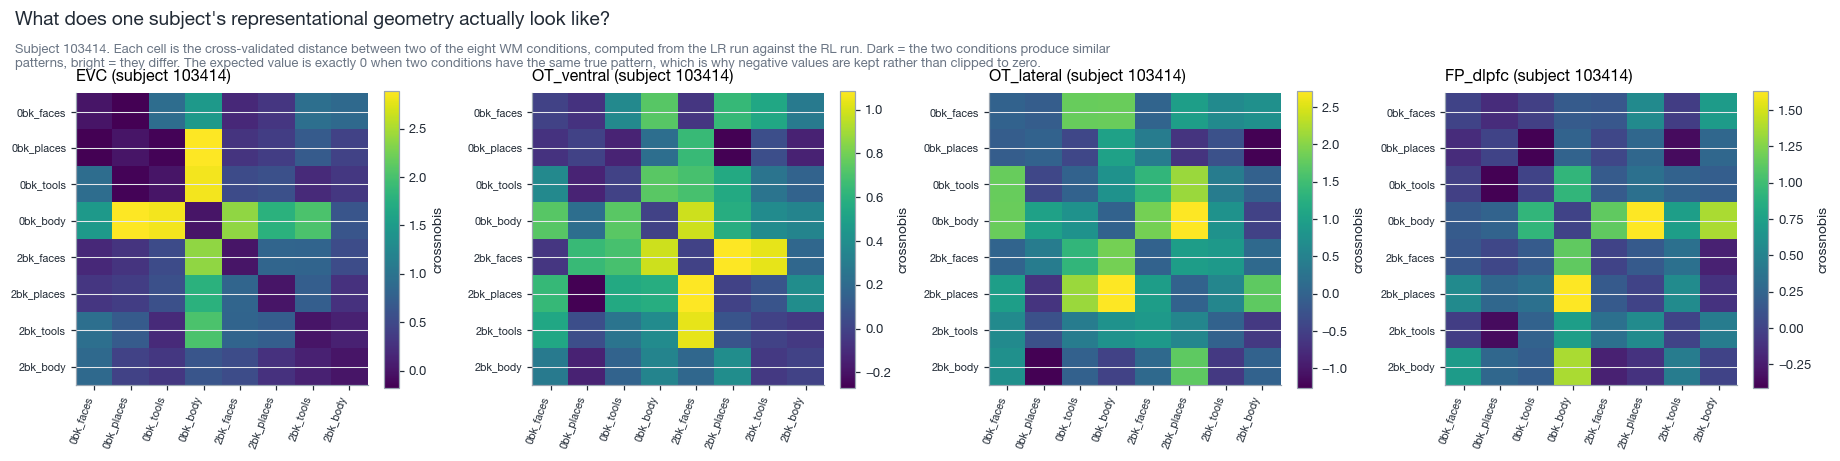

Pairwise identification accuracy (chance 0.50)
subject         roi  n_feat  id_0back  id_2back  id_cross_load
 103414         EVC    3632      0.92      0.96           0.83
 103414  OT_ventral    1850      0.88      0.75           1.00
 103414  OT_lateral     788      0.96      0.92           0.96
 103414   AUD_early    1187      0.46      0.46           0.42
 103414   AUD_assoc    2274      0.58      0.62           0.83
 103414    FP_dlpfc    3318      0.46      0.83           0.50
 103414 FP_parietal    2460      0.50      0.50           0.92
 103414 Cing_preSMA    1547      0.58      0.75           0.54
 105014         EVC    3632      0.83      0.71           0.75
 105014  OT_ventral    1850      0.75      0.58           0.92
 105014  OT_lateral     788      1.00      0.79           0.71
 105014   AUD_early    1187      0.62      0.33           0.38
 105014   AUD_assoc    2274      0.83      0.58           0.62
 105014    FP_dlpfc    3318      0.71      0.54           0.62
 105014 

In [9]:
# =============================================================================
# STAGE 4a - SPLIT-HALF RSA ON THE WM (VISUAL) TASK
# =============================================================================
# For every subject and ROI: take the eight WM patterns from the LR run and the eight from the RL run and ask how
# often a condition's own pattern in the other run is its best match (pairwise identification, chance 0.50), within
# 0-back, within 2-back, and across load. Flat features (zero variance in either run) are dropped first.
#
# Then the same question at the group level, with the subject as the unit of replication: a sign-flip test against
# chance, a bootstrap confidence interval over subjects, and FDR correction across ROIs. With fewer than five
# subjects no test is run at all and the cell says so, because one brain cannot support a hypothesis test.
#
# The figure shows the raw 8x8 cross-validated distance matrices for the first subject, which is the clearest single
# picture of what "representational geometry" means here: dark = two conditions look alike, bright = they differ.
import matplotlib.pyplot as plt

rows = []
for sid in SUBJECTS:
    P = np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz"))
    for roi, m in roi_masks.items():
        A, B = P["WM_LR_t"][:, m].astype(float), P["WM_RL_t"][:, m].astype(float)
        keep = (A.std(0) > 0) & (B.std(0) > 0)                      # drop flat features
        A, B = A[:, keep], B[:, keep]
        w0, w2, xl = id_scores(A, B)
        rows.append(dict(subject=sid, roi=roi, n_feat=A.shape[1], id_0back=w0, id_2back=w2, id_cross_load=xl))
wm_res = pd.DataFrame(rows)
note("Pairwise identification accuracy (chance 0.50)")
note(wm_res.round(2).to_string(index=False))

# ---- group statistics (only meaningful with enough subjects) ----
if len(SUBJECTS) >= 5:
    out = []
    for roi, g in wm_res.groupby("roi"):
        for metric in ("id_0back", "id_2back", "id_cross_load"):
            x = g[metric].values - 0.5
            lo, hi = bootstrap_ci(x)
            out.append(dict(roi=roi, metric=metric, mean_acc=0.5 + x.mean(), ci_lo=0.5 + lo, ci_hi=0.5 + hi, p=signflip_p(x)))
    wm_group = pd.DataFrame(out)
    wm_group["q_fdr"] = bh_fdr(wm_group["p"].values)          # restrict this family to the pre-specified ROIs before reporting
    note("\nGroup level (sign-flip test vs chance, BH-FDR):")
    note(wm_group.round(3).to_string(index=False))
else:
    note(f"\n{len(SUBJECTS)} subject(s): descriptive only. A single subject cannot support a hypothesis test.")

# ---- RDMs and voxel-removal curves for the first subject ----
sid = SUBJECTS[0]
P = np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz"))
show = [r for r in ("EVC", "OT_ventral", "OT_lateral", "FP_dlpfc") if r in roi_masks]
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4))
for ax, roi in zip(np.atleast_1d(axes), show):
    m = roi_masks[roi]
    A, B = P["WM_LR_t"][:, m].astype(float), P["WM_RL_t"][:, m].astype(float)
    im = ax.imshow(crossnobis_rdm(A, B), cmap="viridis")
    ax.set_title(f"{roi} (subject {sid})")
    ax.set_xticks(range(8)); ax.set_xticklabels(WM_CONDS, rotation=70, ha="right", fontsize=7)
    ax.set_yticks(range(8)); ax.set_yticklabels(WM_CONDS, fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.046, label="crossnobis")
plt.tight_layout()
fig_title(fig, "What does one subject's representational geometry actually look like?",
          f"Subject {sid}. Each cell is the cross-validated distance between two of the eight WM conditions, computed from the LR run "
          "against the RL run. Dark = the two conditions produce similar patterns, bright = they differ. The expected value is exactly 0 "
          "when two conditions have the same true pattern, which is why negative values are kept rather than clipped to zero.", y=1.06)
save_fig(fig, "rsa_subject_rdms.png")

# (Voxel-removal curves live in the Haxby cell and in the 'removal panels' cell, which use more random draws and all subjects.)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


### Stage 4b — RSA figures: every subject's value, and a positive control

The group means above are built from eight numbers, so these figures show all eight. The first gives identification
accuracy per region with one dot per subject, the group mean with its bootstrap interval, and how many subjects are
above chance — a mean carried by two people looks very different here than in a table. The second is the positive
control on the ROI masks themselves: visual regions must respond to the pictures and auditory regions must not. If
that fails, nothing downstream can be interpreted.

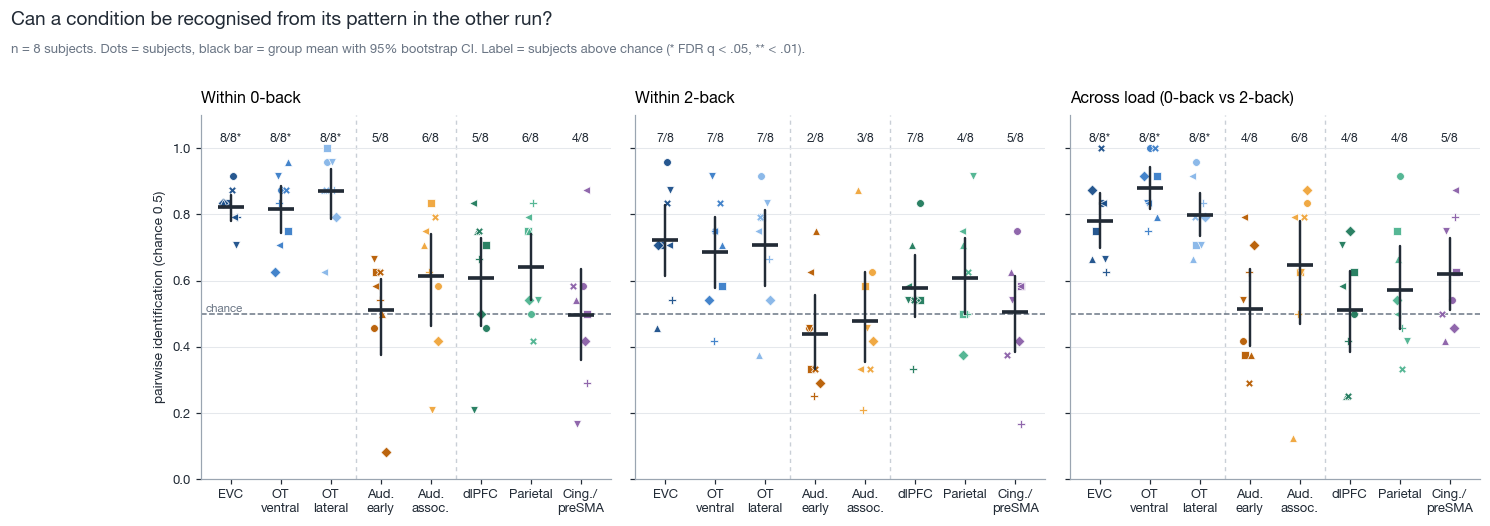

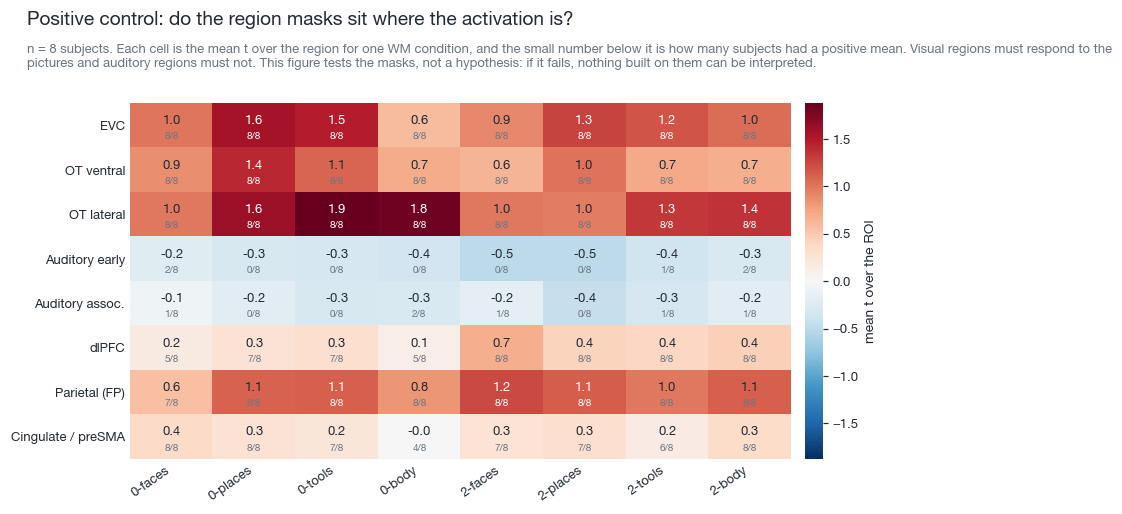

In [10]:
# =============================================================================
# STAGE 4b - RSA FIGURES: per-subject identification, and a positive control
# =============================================================================
# Two figures, both with the group numbers and the individual subjects visible:
#   1  Identification accuracy per ROI with one dot per subject, the group mean with its 95% bootstrap interval, the
#      number of subjects above chance, and FDR stars. Showing all eight subjects matters because a group mean built
#      from eight values can be carried by two of them.
#   2  A positive control. Before believing any pattern result, check that the ROI masks sit where the activation is:
#      visual ROIs should respond to the pictures and auditory ROIs should not. This figure is the test of the masks,
#      not of a hypothesis, and if it fails nothing downstream is interpretable.
#
# A third, optional figure (the cross-run correlation matrices that identification is computed from) is drawn only if
# SHOW_QC_FIGS is set to True, to keep the notebook readable.
# Needs wm_res and wm_group (Stage 4a), cross_run_corr (Stage 4) and the style cell.
PAT = {sid: load_patterns(sid) for sid in SUBJECTS}

# ---- 1. Identification: one dot per subject, group mean with 95% CI, subjects above chance, FDR stars ----
metrics = [("id_0back", "Within 0-back"), ("id_2back", "Within 2-back"), ("id_cross_load", "Across load (0-back vs 2-back)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True, gridspec_kw=dict(wspace=.06))
for ax, (col, label) in zip(axes, metrics):
    group_dividers(ax, "x")
    for i, roi in enumerate(ROI_ORDER):
        g = wm_res[wm_res.roi == roi].set_index("subject").loc[SUBJECTS]
        vals = g[col].values
        strip(ax, i, vals, ROI_COLORS[roi], seed=i, subjects=list(g.index), mean=False)
        lo, hi = bootstrap_ci(vals)
        ax.plot([i, i], [lo, hi], color=INK, lw=1.6, zorder=4, solid_capstyle="round")
        ax.plot([i - .26, i + .26], [vals.mean()] * 2, color=INK, lw=2.4, zorder=5, solid_capstyle="butt")
        q = wm_group[(wm_group.roi == roi) & (wm_group.metric == col)].q_fdr
        ax.text(i, 1.02, f"{int((vals > .5).sum())}/{len(vals)}{stars(float(q.iloc[0])) if len(q) else ''}", ha="center", fontsize=8,
                fontweight="bold" if len(q) and float(q.iloc[0]) < .05 else "normal", color=INK)
    ax.axhline(.5, color=MUTED, ls="--", lw=1)
    roi_ticks(ax, "x"); ax.set_ylim(0, 1.1); ax.set_title(label)
axes[0].set_ylabel("pairwise identification (chance 0.5)")
axes[0].text(-.5, .5, "chance", fontsize=7.5, color=MUTED, va="bottom")
fig_title(fig, "Can a condition be recognised from its pattern in the other run?",
          f"n = {len(SUBJECTS)} subjects. Dots = subjects, black bar = group mean with 95% bootstrap CI. Label = subjects above chance (* FDR q < .05, ** < .01).", y=1.1)
save_fig(fig, "rsa_identification_strip.png")

# ---- 2. Positive control: ROI mean activation per WM condition ----
act = np.zeros((len(SUBJECTS), len(ROI_ORDER), 8))
for si, sid in enumerate(SUBJECTS):
    for ri, roi in enumerate(ROI_ORDER):
        m = roi_masks[roi]
        act[si, ri] = 0.5 * (PAT[sid]["WM_LR_t"][:, m].mean(axis=1) + PAT[sid]["WM_RL_t"][:, m].mean(axis=1))
G = act.mean(axis=0)
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.grid(False)
lim = np.nanmax(np.abs(G))
im = ax.imshow(G, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(G):
    n_pos = int((act[:, i, j] > 0).sum())
    ax.text(j, i - .1, f"{v:.1f}", ha="center", va="center", fontsize=8.5, fontweight="bold", color="white" if abs(v) > .6 * lim else INK)
    ax.text(j, i + .25, f"{n_pos}/{len(SUBJECTS)}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > .6 * lim else MUTED)
ax.set_xticks(range(8)); ax.set_xticklabels([c.replace("bk_", "-") for c in WM_CONDS], rotation=35, ha="right")
ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels([ROI_NAME[r] for r in ROI_ORDER])
ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label("mean t over the ROI"); cb.outline.set_visible(False)
fig_title(fig, "Positive control: do the region masks sit where the activation is?",
          f"n = {len(SUBJECTS)} subjects. Each cell is the mean t over the region for one WM condition, and the small number below it is how many "
          "subjects had a positive mean. Visual regions must respond to the pictures and auditory regions must not. This figure tests the masks, "
          "not a hypothesis: if it fails, nothing built on them can be interpreted.", y=1.08)
save_fig(fig, "roi_mean_activation_positive_control.png")

# ---- 3. (quality control, off by default) cross-run correlation matrices ----
if globals().get("SHOW_QC_FIGS", False):
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.6), constrained_layout=True)
    for ax, roi in zip(axes.ravel(), ROI_ORDER):
        ax.grid(False)
        mats = []
        for sid in SUBJECTS:
            A, B = nonflat_pair(PAT[sid]["WM_LR_t"][:, roi_masks[roi]].astype(float), PAT[sid]["WM_RL_t"][:, roi_masks[roi]].astype(float))
            mats.append(cross_run_corr(A, B))
        M = np.mean(mats, axis=0)
        im = ax.imshow(M, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
        ax.axhline(3.5, color=INK, lw=.8); ax.axvline(3.5, color=INK, lw=.8)
        ax.set_title(f"{ROI_NAME[roi]}\ndiag {np.mean(np.diag(M)):+.2f} vs off-diag {np.mean(M[~np.eye(8, dtype=bool)]):+.2f}", fontsize=9)
        ax.set_xticks(range(8)); ax.set_xticklabels(SHORT_CONDS, fontsize=7); ax.set_yticks(range(8)); ax.set_yticklabels(SHORT_CONDS, fontsize=7)
    fig.colorbar(im, ax=axes, fraction=0.015, label="Pearson r (LR pattern i vs RL pattern j)")
    save_fig(fig, "rsa_cross_run_matrices.png")


In [11]:
# =============================================================================
# STAGE 4c - SPLIT-HALF RSA ON THE LANGUAGE (AUDITORY) TASK
# =============================================================================
# The Language task has only two conditions, so there is no 2x2 geometry to describe: with two conditions,
# identification reduces to the sign of one correlation. What is reported instead is
#   story_math_r  how well the story-minus-math pattern in the LR run reproduces in the RL run (the reliability of
#                 the Language pattern - used later as the ceiling for the demand-axis correlation), and
#   crossnobis_d  the cross-validated distance between story and math.
# Correlations are averaged after a Fisher z transform, because r is not additive.
lrows = []
for sid in SUBJECTS:
    P = np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz"))
    for roi, m in roi_masks.items():
        r, d = language_split_half(P["LANGUAGE_LR_t"][:, m].astype(float), P["LANGUAGE_RL_t"][:, m].astype(float))
        lrows.append(dict(subject=sid, roi=roi, n_feat=int(m.sum()), story_math_r=r, crossnobis_d=d))
lang_res = pd.DataFrame(lrows)
print("Story-vs-math pattern reliability across runs (r) and cross-validated distance")
print(lang_res.round(3).to_string(index=False))

if len(SUBJECTS) >= 5:
    out = []
    for roi, g in lang_res.groupby("roi"):
        z = np.arctanh(np.clip(g["story_math_r"].values, -0.999, 0.999))      # Fisher z before averaging r
        lo, hi = bootstrap_ci(z)
        out.append(dict(roi=roi, mean_r=np.tanh(z.mean()), ci_lo=np.tanh(lo), ci_hi=np.tanh(hi), p=signflip_p(z)))
    lang_group = pd.DataFrame(out)
    lang_group["q_fdr"] = bh_fdr(lang_group["p"].values)
    print("\nGroup level:"); print(lang_group.round(3).to_string(index=False))
else:
    print(f"\n{len(SUBJECTS)} subject(s): descriptive only.")


Story-vs-math pattern reliability across runs (r) and cross-validated distance
subject         roi  n_feat  story_math_r  crossnobis_d
 103414         EVC    3632         0.528         0.226
 103414  OT_ventral    1850         0.295         0.074
 103414  OT_lateral     788         0.629         0.283
 103414   AUD_early    1187         0.352         0.105
 103414   AUD_assoc    2274         0.664         0.584
 103414    FP_dlpfc    3318         0.611         0.607
 103414 FP_parietal    2460         0.776         1.531
 103414 Cing_preSMA    1547         0.591         0.344
 105014         EVC    3632         0.596         0.252
 105014  OT_ventral    1850         0.385         0.095
 105014  OT_lateral     788         0.569         0.206
 105014   AUD_early    1187         0.455         0.112
 105014   AUD_assoc    2274         0.817         1.481
 105014    FP_dlpfc    3318         0.782         0.942
 105014 FP_parietal    2460         0.690         1.536
 105014 Cing_preSMA    15

## Stage 5 — Leave-one-subject-out decoding

The question changes here. Stage 4 asked whether a pattern reproduces *in the same brain*; this stage asks whether
it means the same thing *in a different brain*. A classifier is trained on everyone else and tested on the held-out
participant, which is only possible because the data are MSMAll-aligned, so the same ROI feature is the same
cortical location in every subject. At least **five subjects** are needed (set `SUBJECTS` in Stage 2).

1. **Dataset.** Built from the saved patterns. For category decoding the four-category mean is removed inside each
   run *and* each load, so the classifier cannot use difficulty to guess the category; for load decoding only the
   subject mean is removed. Features are scaled within each subject, using that subject's own samples and never
   their labels.
2. **Decoder.** A linear ridge classifier in dual form, with the whole leave-one-subject-out analysis repeated under
   shuffled labels to obtain the p-values.
3. **WM.** Category within 0-back, category within 2-back, trained on one load and tested on the other in both
   directions, and load itself, in every region.
4. **Language.** Story versus math, in every region.

**Why the p-values come from label permutation.** A t-test or sign-flip test across subjects' accuracies is not
valid here, because the folds share training data: in our checks that test rejected 10–13% of null datasets at
$\alpha = 0.05$. `N_PERM` must be large enough for the smallest attainable q to pass — with 40 tests that means at
least 1000, and 5000 for final numbers. `LAM_REL` is fixed in advance; sensitivity is reported at 0.1 and 10 rather
than chosen by what works best.

In [12]:
# =============================================================================
# STAGE 5 - DECODING: build the cross-subject dataset
# =============================================================================
# From here the question changes from "does a pattern reproduce in the same brain?" (RSA) to "does a pattern mean the
# same thing in a DIFFERENT brain?". A classifier is trained on other people's brains and tested on a held-out person,
# which is only possible because the data are MSMAll-aligned: the same ROI feature is the same cortical location in
# every subject. At least MIN_SUBJ = 5 subjects are required, because a decoder cannot be trained on nobody.
#
# This cell first validates the saved pattern files (all arrays present, the expected number of conditions, no NaN or
# infinity, the same number of features in every subject), then defines how the patterns are turned into a dataset.
#
# The three preprocessing routines encode what each analysis is allowed to use:
#   prep_category  removes the mean over the four categories inside each run AND each load, so the classifier cannot
#                  use "how hard was this block" to guess the category. What is left is purely the category contrast.
#   prep_load      keeps the load difference and removes only the subject's own mean over all 16 samples.
#   prep_language  removes the story/math mean inside each run.
# All three then scale each feature by its standard deviation WITHIN the subject. Scaling uses only that subject's own
# samples and never their labels, so no information leaks from the training subjects into the test subject.
import os
import numpy as np

MIN_SUBJ = 5
# build_dataset() is called once per ROI by several cells, so its progress line used to produce eight to sixteen
# lines of log immediately above every decoding figure. Set this to True to get those lines back.
VERBOSE_DATASET = False

assert len(SUBJECTS) >= MIN_SUBJ, (
    f"MVPA requires at least {MIN_SUBJ} subjects; found {len(SUBJECTS)}."
)

EXPECTED_SHAPES = {
    "WM_LR_t": (8, 91282),
    "WM_RL_t": (8, 91282),
    "LANGUAGE_LR_t": (2, 91282),
    "LANGUAGE_RL_t": (2, 91282),
}

# First verify the files exist and contain all required arrays.
pattern_files = {}

for sid in SUBJECTS:
    path = os.path.join(OUT_DIR, f"{sid}_patterns.npz")

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing pattern file for subject {sid}: {path}\n"
            "Run Cell 8 after correcting DATA_ROOT."
        )

    with np.load(path) as P:
        missing = [key for key in EXPECTED_SHAPES if key not in P.files]
        if missing:
            raise KeyError(f"{sid}: missing arrays {missing} in {path}")

        for key, expected_shape in EXPECTED_SHAPES.items():
            actual_shape = P[key].shape

            # The expected grayordinate count may differ if your data use
            # a different space; all subjects must nevertheless match.
            if actual_shape != expected_shape:
                print(
                    f"Shape note: {sid} {key}: {actual_shape}; "
                    f"reference shape: {expected_shape}"
                )

            if actual_shape[0] != expected_shape[0]:
                raise ValueError(
                    f"{sid} {key}: expected {expected_shape[0]} conditions, "
                    f"found {actual_shape[0]}."
                )

            if not np.isfinite(P[key]).all():
                raise ValueError(f"{sid} {key} contains NaN or infinite values.")

    pattern_files[sid] = path
    print(f"Validated: {sid} -> {path}")

# Require a common feature space across subjects.
feature_counts = set()

for sid, path in pattern_files.items():
    with np.load(path) as P:
        feature_counts.update(
            P[key].shape[1] for key in EXPECTED_SHAPES
        )

if len(feature_counts) != 1:
    raise ValueError(
        f"Subjects have inconsistent feature counts: {feature_counts}. "
        "Check that all patterns use the same grayordinate space."
    )

N_FEATURES = feature_counts.pop()

assert all(
    mask.shape[0] == N_FEATURES for mask in roi_masks.values()
), "ROI masks do not match the pattern feature space."

print(f"\nValidated {len(pattern_files)} subjects and {N_FEATURES} features.")

LOAD_OF_ROW = np.repeat([0, 1], 4)        # WM rows: 0-3 = 0-back, 4-7 = 2-back
CAT_OF_ROW = np.tile(np.arange(4), 2)     # faces, places, tools, body at both loads


def _scale(X):
    """Per-subject feature scaling (uses only that subject's own unlabeled samples, so nothing leaks across subjects)."""
    sd = X.std(axis=0)
    return np.where(sd > 0, X / np.where(sd > 0, sd, 1.0), 0.0)


def prep_category(runs):
    """runs: [LR (8,F), RL (8,F)]. Remove the 4-category mean inside each run and load (kills the shared task pattern
    and the load main effect, so category classifiers cannot use load), then scale features."""
    out = []
    for P in runs:
        P = np.asarray(P, float).copy()
        for rows in (np.arange(0, 4), np.arange(4, 8)):
            P[rows] -= P[rows].mean(axis=0, keepdims=True)
        out.append(P)
    return _scale(np.vstack(out))


def prep_load(runs):
    """Keep the load difference: subtract this subject's mean over all 16 samples, then scale features."""
    X = np.vstack([np.asarray(P, float) for P in runs])
    return _scale(X - X.mean(axis=0, keepdims=True))


def prep_language(runs):
    """runs: [LR (2,F), RL (2,F)] story/math. Remove the story/math mean inside each run, then scale features."""
    out = []
    for P in runs:
        P = np.asarray(P, float)
        out.append(P - P.mean(axis=0, keepdims=True))
    return _scale(np.vstack(out))


def build_dataset(roi, task):
    """Build a cross-subject decoding dataset from all configured subjects."""
    if roi not in roi_masks:
        raise KeyError(f"Unknown ROI: {roi}")

    if task not in ("WM", "LANGUAGE"):
        raise ValueError("task must be 'WM' or 'LANGUAGE'")

    mask = roi_masks[roi]
    Xs, meta = [], []

    for subject_index, sid in enumerate(SUBJECTS):
        path = os.path.join(OUT_DIR, f"{sid}_patterns.npz")

        if not os.path.isfile(path):
            raise FileNotFoundError(
                f"Missing {path}. Run pattern extraction for subject {sid}."
            )

        with np.load(path) as P:
            lr_key = f"{task}_LR_t"
            rl_key = f"{task}_RL_t"

            for key in (lr_key, rl_key):
                if key not in P.files:
                    raise KeyError(f"{sid}: {key} is missing from {path}")

            lr = P[lr_key].astype(np.float64)
            rl = P[rl_key].astype(np.float64)

        expected_rows = 8 if task == "WM" else 2

        if lr.shape[0] != expected_rows or rl.shape[0] != expected_rows:
            raise ValueError(
                f"{sid} {task}: unexpected LR/RL shapes "
                f"{lr.shape} and {rl.shape}"
            )

        if lr.shape[1] != mask.size or rl.shape[1] != mask.size:
            raise ValueError(
                f"{sid} {task}: pattern features do not match ROI mask."
            )

        if not np.isfinite(lr).all() or not np.isfinite(rl).all():
            raise ValueError(f"{sid} {task}: patterns contain non-finite values.")

        runs = [lr[:, mask], rl[:, mask]]

        if task == "WM":
            X_category = prep_category(runs)
            X_load = prep_load(runs)
            Xs.append((X_category, X_load))

            for run_index in (0, 1):
                for k in range(8):
                    meta.append((
                        subject_index,
                        sid,
                        run_index,
                        LOAD_OF_ROW[k],
                        CAT_OF_ROW[k],
                    ))

        else:
            X_language = prep_language(runs)
            Xs.append((X_language, None))

            for run_index in (0, 1):
                for category in (0, 1):
                    meta.append((
                        subject_index,
                        sid,
                        run_index,
                        0,
                        category,
                    ))

    meta = np.asarray(meta, dtype=object)

    result = {
        "subj": meta[:, 0].astype(int),
        "subject_id": meta[:, 1],
        "run": meta[:, 2].astype(int),
        "load": meta[:, 3].astype(int),
        "y": meta[:, 4].astype(int),
        "X_main": np.vstack([x[0] for x in Xs]),
    }

    if task == "WM":
        result["X_load"] = np.vstack([x[1] for x in Xs])

    if VERBOSE_DATASET:
        print(
            f"{task} / {roi}: {len(SUBJECTS)} subjects, "
            f"{result['X_main'].shape[0]} samples, "
            f"{result['X_main'].shape[1]} ROI features"
        )

    return result


print(f"{len(SUBJECTS)} subjects; building decoding datasets for {len(roi_masks)} ROIs")


Validated: 103414 -> derivatives/103414_patterns.npz
Validated: 105014 -> derivatives/105014_patterns.npz
Validated: 103212 -> derivatives/103212_patterns.npz
Validated: 115219 -> derivatives/115219_patterns.npz
Validated: 101107 -> derivatives/101107_patterns.npz
Validated: 107321 -> derivatives/107321_patterns.npz
Validated: 139839 -> derivatives/139839_patterns.npz
Validated: 108121 -> derivatives/108121_patterns.npz

Validated 8 subjects and 91282 features.
8 subjects; building decoding datasets for 8 ROIs


In [13]:
# =============================================================================
# STAGE 5a - DECODER AND LEAVE-ONE-SUBJECT-OUT MACHINERY
# =============================================================================
# The decoder is a linear ridge classifier in dual (kernel) form: one-vs-rest with labels coded as +/- around zero.
# Dual form, because an ROI has thousands of features and at most 128 samples - with V >> n it is far cheaper to work
# with the n x n Gram matrix K = X X^T than with the features themselves, and the two are mathematically equivalent.
# Regularisation is strong by default (LAM_REL = 1 relative to the mean diagonal of K) for the same reason.
#
# LAM_REL is fixed in advance. Tuning it against test accuracy would invalidate the test, so the honest way to report
# sensitivity is to re-run at 0.1 and 10 and say what changed.
#
# The speed trick that makes the permutation test affordable: K is built once per ROI, and each fold's eigen-
# decomposition once per analysis. Permuting labels changes only the right-hand side, so a permutation costs one
# matrix multiply instead of a full refit. 1000 permutations then take seconds rather than hours.
#
# permutation_test shuffles the LABELS inside blocks that keep the design balanced (category labels within
# subject x run x load, load labels within subject x run x category) and repeats the WHOLE leave-one-subject-out
# analysis for each shuffle. This is the test we trust. A t-test or sign-flip test on the per-subject accuracies is
# NOT valid here, because the folds share training data; in our checks that test rejected 10-13% of null datasets at
# alpha = 0.05.
LAM_REL = 1.0      # ridge strength relative to the mean kernel diagonal. Fixed in advance; report a sensitivity check, do not tune on test accuracy.


class LosoModel:
    """Leave-one-subject-out ridge decoder. For each held-out subject: train on all OTHER subjects' samples in
    train_sel, test on the held-out subject's samples in test_sel."""

    def __init__(self, K, subj, train_sel, test_sel, lam_rel=LAM_REL):
        self.folds = []
        for s in np.unique(subj):
            tr = np.where((subj != s) & train_sel)[0]
            te = np.where((subj == s) & test_sel)[0]
            Ktr = K[np.ix_(tr, tr)]
            lam = lam_rel * np.trace(Ktr) / len(tr)
            w, U = np.linalg.eigh(Ktr)
            self.folds.append((tr, te, U, 1.0 / (np.maximum(w, 0) + lam), K[np.ix_(te, tr)]))

    def accuracy(self, y):
        """One accuracy per held-out subject. y: integer labels 0..k-1 for ALL samples (may be permuted)."""
        k = int(y.max()) + 1
        Y = np.eye(k)[y] - 1.0 / k
        out = []
        for tr, te, U, inv, Kte in self.folds:
            alpha = U @ (inv[:, None] * (U.T @ Y[tr]))
            out.append(np.mean((Kte @ alpha).argmax(axis=1) == y[te]))
        return np.array(out)


def wm_analyses(d):
    """The five WM questions: {name: (K, y, subj, train_sel, test_sel, chance, permutation_groups)}.
    Category labels are shuffled within subject x run x load; load labels within subject x run x category,
    so every permutation keeps the design balance."""
    Kc, Kl = d["X_main"] @ d["X_main"].T, d["X_load"] @ d["X_load"].T
    L, y_c, s, r = d["load"], d["y"], d["subj"], d["run"]
    allsel = np.ones(len(y_c), bool)
    gcat = s * 100 + r * 10 + L
    gload = s * 100 + r * 10 + y_c
    return {
        "category | 0-back -> 0-back": (Kc, y_c, s, L == 0, L == 0, 0.25, gcat),
        "category | 2-back -> 2-back": (Kc, y_c, s, L == 1, L == 1, 0.25, gcat),
        "category | 0-back -> 2-back": (Kc, y_c, s, L == 0, L == 1, 0.25, gcat),
        "category | 2-back -> 0-back": (Kc, y_c, s, L == 1, L == 0, 0.25, gcat),
        "load (0- vs 2-back)":         (Kl, L,   s, allsel, allsel, 0.50, gload),
    }


def permutation_test(model, y, groups, n_perm=1000, seed=0):
    """Label-permutation test of the group-mean leave-one-subject-out accuracy: shuffle labels inside the blocks given by
    `groups`, repeat the whole analysis, p = share of permutations with accuracy >= observed.
    Valid despite the folds sharing training data (the t-test / sign-flip on per-subject accuracies is not)."""
    rng = np.random.default_rng(seed)
    blocks = [np.where(groups == g)[0] for g in np.unique(groups)]
    obs = model.accuracy(y).mean()
    null = np.empty(n_perm)
    for i in range(n_perm):
        yp = y.copy()
        for idx in blocks:
            yp[idx] = y[rng.permutation(idx)]
        null[i] = model.accuracy(yp).mean()
    return obs, null, (1 + np.sum(null >= obs)) / (n_perm + 1)


In [14]:
# =============================================================================
# STAGE 5b - WM DECODING: category and load, in every ROI
# =============================================================================
# Five questions per ROI, all leave-one-subject-out:
#   category within 0-back, category within 2-back  - is there a category code at this load? (chance 0.25)
#   category 0-back -> 2-back, 2-back -> 0-back     - does the SAME code work at the other load? (chance 0.25)
#   load 0-back vs 2-back                           - is memory load itself decodable? (chance 0.50)
# Each one gets a label-permutation p-value, a bootstrap interval over subjects, and an FDR q-value computed across
# everything shown in the table.
#
# The second block prints within-load minus cross-load accuracy per ROI. This is the quantity the load-invariance
# argument rests on: 0 means the category code is unchanged by load, and a positive value means information was lost
# when the load changed. It is descriptive only - there is no valid label-permutation null for a DIFFERENCE between
# two accuracies, so the formal version of this comparison is the equivalence test in Stage 9.
#
# N_PERM = 1000 is enough to look at; use 5000 or more for final numbers, since the smallest attainable p-value is
# 1/(N_PERM + 1) and that has to be small enough to survive FDR correction across 40 tests.
import matplotlib.pyplot as plt

N_PERM = 1000       # permutations per test. 1000 is fine to look; use 5000+ for the final numbers (smallest possible p is 1/(N_PERM+1))
rows, subj_acc = [], {}
for roi in roi_masks:
    d = build_dataset(roi, "WM")
    for name, (K, y, s, tr, te, chance, groups) in wm_analyses(d).items():
        model = LosoModel(K, s, tr, te)
        _, _, p = permutation_test(model, y, groups, N_PERM)
        a = model.accuracy(y)
        subj_acc[(roi, name)] = a
        lo, hi = bootstrap_ci(a - chance)
        rows.append(dict(roi=roi, analysis=name, chance=chance, mean_acc=a.mean(), ci_lo=chance + lo, ci_hi=chance + hi, p_perm=p))
wm_dec = pd.DataFrame(rows)
wm_dec["q_fdr"] = bh_fdr(wm_dec["p_perm"].values)         # across every ROI x analysis shown; restrict to your pre-specified family before reporting
print("Leave-one-subject-out decoding. p_perm = label-permutation test; CI = bootstrap over subjects (descriptive, slightly optimistic)")
print(wm_dec.round(3).to_string(index=False))

# does category information survive the 0-back <-> 2-back change? (descriptive: no valid label-permutation null for this difference)
within = lambda r: np.mean([subj_acc[(r, "category | 0-back -> 0-back")], subj_acc[(r, "category | 2-back -> 2-back")]], axis=0)
across = lambda r: np.mean([subj_acc[(r, "category | 0-back -> 2-back")], subj_acc[(r, "category | 2-back -> 0-back")]], axis=0)
print("\nCategory decoding: within-load minus cross-load accuracy (0 = load-invariant; > 0 = information lost across load)")
for r in roi_masks:
    dlt = within(r) - across(r)
    lo, hi = bootstrap_ci(dlt)
    print(f"  {r:12s} mean {dlt.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

# (the bar chart that used to be here is replaced by the per-subject plots in the decoding-plots cell below)


Leave-one-subject-out decoding. p_perm = label-permutation test; CI = bootstrap over subjects (descriptive, slightly optimistic)
        roi                    analysis  chance  mean_acc  ci_lo  ci_hi  p_perm  q_fdr
        EVC category | 0-back -> 0-back    0.25     0.812  0.703  0.906   0.001  0.002
        EVC category | 2-back -> 2-back    0.25     0.719  0.562  0.859   0.001  0.002
        EVC category | 0-back -> 2-back    0.25     0.562  0.406  0.688   0.001  0.002
        EVC category | 2-back -> 0-back    0.25     0.656  0.531  0.781   0.001  0.002
        EVC         load (0- vs 2-back)    0.50     0.680  0.594  0.766   0.001  0.002
 OT_ventral category | 0-back -> 0-back    0.25     0.781  0.688  0.875   0.001  0.002
 OT_ventral category | 2-back -> 2-back    0.25     0.656  0.578  0.750   0.001  0.002
 OT_ventral category | 0-back -> 2-back    0.25     0.641  0.531  0.750   0.001  0.002
 OT_ventral category | 2-back -> 0-back    0.25     0.625  0.531  0.719   0.001  0.002
 

In [15]:
# =============================================================================
# STAGE 5c - LANGUAGE DECODING: story versus math, in every ROI
# =============================================================================
# The same leave-one-subject-out procedure applied to the Language task (chance 0.50). One detail matters for the
# interpretation: each run contributes a story and a math pattern which, after the within-run mean is removed, are
# exact mirror images of each other. A subject therefore has effectively two independent test observations (one per
# run), not four, and the permutation test is blocked by subject x run to respect that.
#
# Because this design makes the task easy, accuracies here run close to ceiling in almost every ROI - including
# visual ones, where a story/math difference is not obviously meaningful. Stage 13 takes that apart with a set of
# confirmatory checks instead of accepting the number at face value.
lrows = []
for roi in roi_masks:
    d = build_dataset(roi, "LANGUAGE")
    K = d["X_main"] @ d["X_main"].T
    all_s = np.ones(len(d["y"]), bool)
    model = LosoModel(K, d["subj"], all_s, all_s)
    groups = d["subj"] * 10 + d["run"]
    _, _, p = permutation_test(model, d["y"], groups, N_PERM)
    a = model.accuracy(d["y"])
    lo, hi = bootstrap_ci(a - 0.5)
    lrows.append(dict(roi=roi, mean_acc=a.mean(), ci_lo=0.5 + lo, ci_hi=0.5 + hi, p_perm=p))
lang_dec = pd.DataFrame(lrows)
lang_dec["q_fdr"] = bh_fdr(lang_dec["p_perm"].values)
print("Story vs math decoding (chance 0.50)")
print(lang_dec.round(3).to_string(index=False))


Story vs math decoding (chance 0.50)
        roi  mean_acc  ci_lo  ci_hi  p_perm  q_fdr
        EVC     0.750  0.375    1.0   0.084  0.084
 OT_ventral     1.000  1.000    1.0   0.001  0.002
 OT_lateral     0.938  0.812    1.0   0.003  0.003
  AUD_early     0.938  0.812    1.0   0.002  0.003
  AUD_assoc     1.000  1.000    1.0   0.001  0.002
   FP_dlpfc     1.000  1.000    1.0   0.001  0.002
FP_parietal     1.000  1.000    1.0   0.001  0.002
Cing_preSMA     0.938  0.812    1.0   0.001  0.002


### Stage 5d — Decoding figures

Per-subject accuracies against a permutation-null band, confusion matrices showing *which* categories get confused,
and a test of whether load decoding reflects the multivoxel pattern or just a stronger average response.

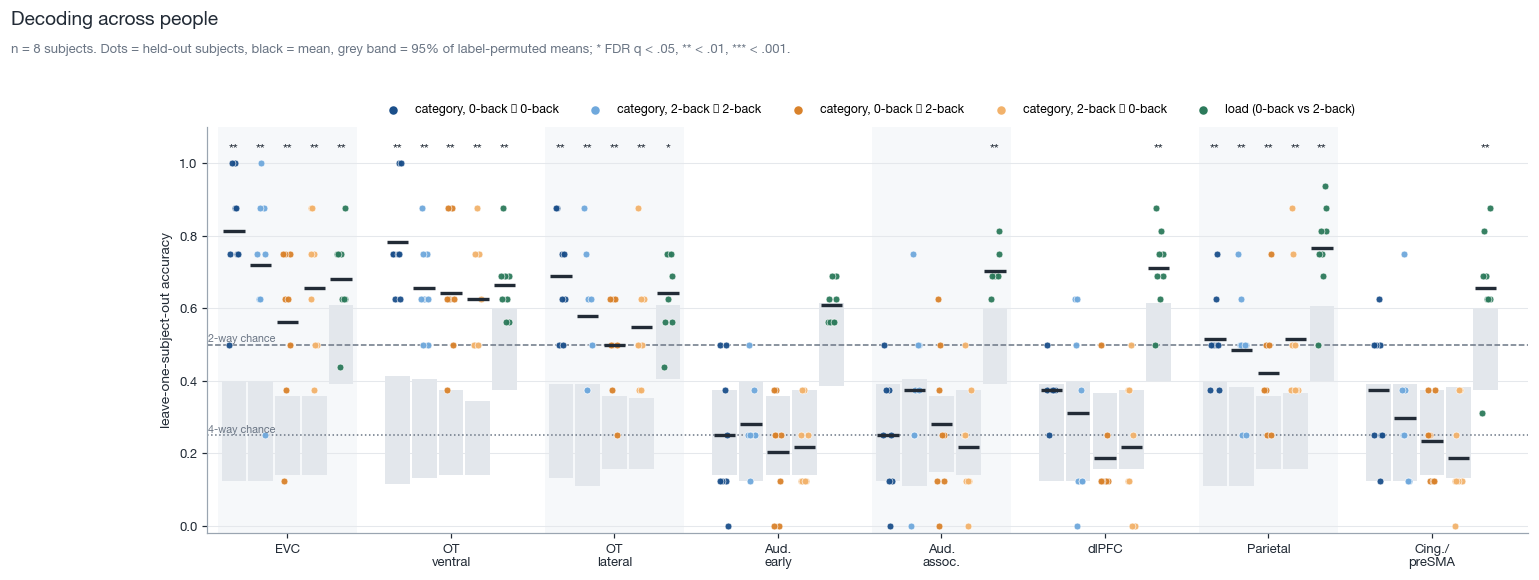

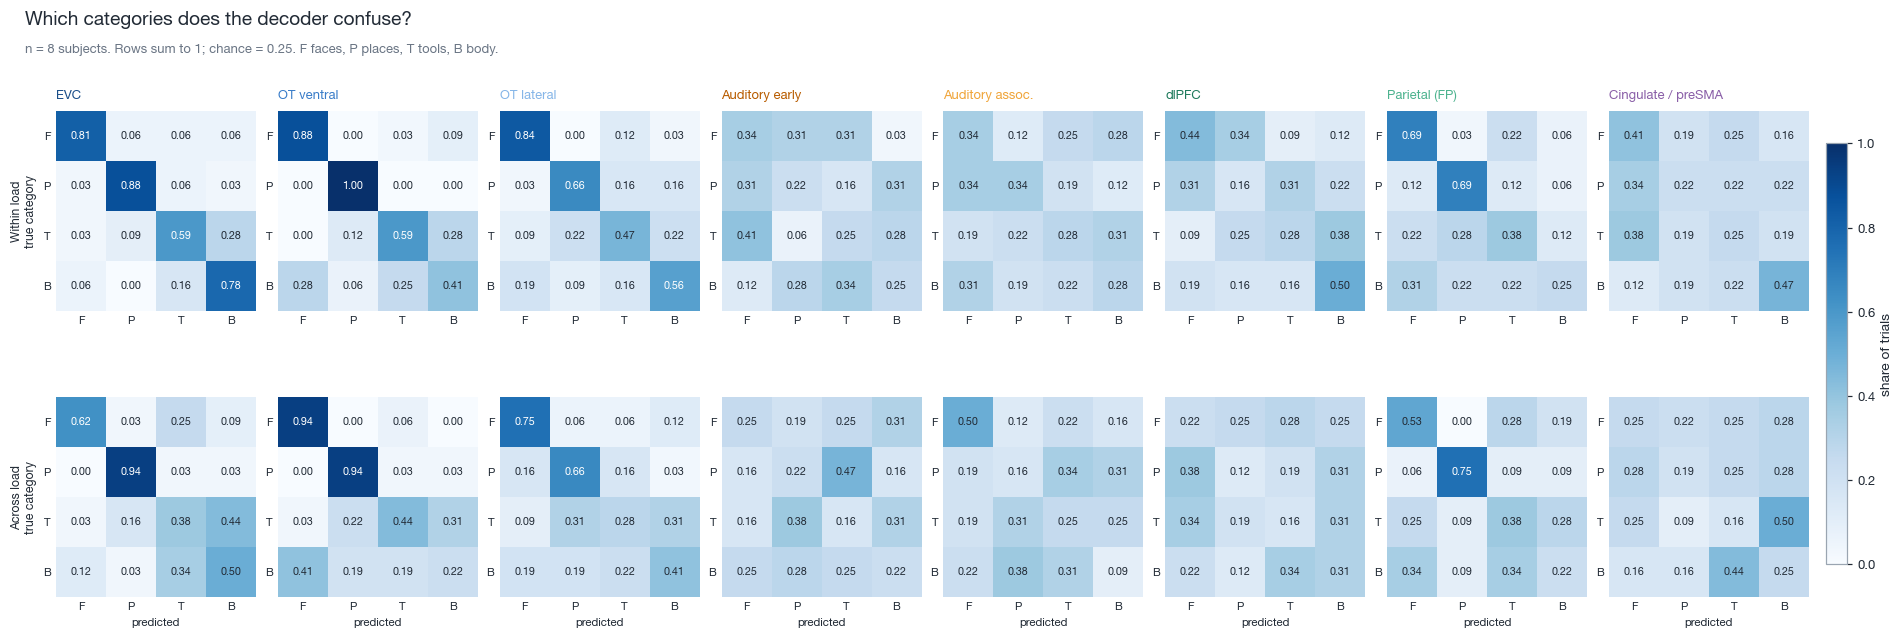

In [16]:
# =============================================================================
# STAGE 5d - DECODING FIGURES: per-subject accuracies and confusion matrices
# =============================================================================
# Two figures:
#   1  Every analysis in every ROI, with one dot per held-out subject, the group mean, and a grey band covering 95%
#      of the label-permuted means. The band is the honest reference: a dot above chance means little, a group mean
#      above the band means something. Stars are the FDR q-values from Stage 5b.
#   2  Confusion matrices for category decoding, pooled over held-out subjects, within load and across load. These
#      say WHICH categories the decoder confuses - a region can be above chance overall while really only
#      distinguishing one category from the rest, and the matrices make that visible.
#
# PLOT_NPERM is used only to draw the grey band; the reported p-values come from Stage 5b with more permutations.
# Needs wm_dec and subj_acc (Stage 5b), the dataset / model / permutation helpers, and the style cell.
PLOT_NPERM = 300        # permutations used only to draw the grey null band (the decoding cell already holds the reported p-values)
ANALYSES = list(wm_dec.analysis.unique())
AN_COLORS = ["#1B4F8A", "#6FA8DC", "#D9822B", "#F2B26B", "#2C7A5B"]
AN_LABELS = {"category | 0-back -> 0-back": "category, 0-back → 0-back", "category | 2-back -> 2-back": "category, 2-back → 2-back",
             "category | 0-back -> 2-back": "category, 0-back → 2-back", "category | 2-back -> 0-back": "category, 2-back → 0-back",
             "load (0- vs 2-back)": "load (0-back vs 2-back)"}
datasets, models, nulls = {}, {}, {}
for roi in ROI_ORDER:
    datasets[roi] = build_dataset(roi, "WM")
    for name, (K, y, s, tr, te, chance, groups) in wm_analyses(datasets[roi]).items():
        models[(roi, name)] = (LosoModel(K, s, tr, te), y)
        _, null, _ = permutation_test(models[(roi, name)][0], y, groups, PLOT_NPERM, seed=1)
        nulls[(roi, name)] = null

# ---- 1. Accuracy per held-out subject, group mean, null band, FDR stars ----
fig, ax = plt.subplots(figsize=(15.5, 4.8))
slot, gap = 1.0, 1.1
width = len(ANALYSES) * slot + gap
centers = {}
for ri, roi in enumerate(ROI_ORDER):
    for ai, name in enumerate(ANALYSES):
        x = ri * width + ai * slot
        centers[(roi, name)] = x
        null = nulls[(roi, name)]
        ax.fill_between([x - .46, x + .46], np.percentile(null, 2.5), np.percentile(null, 97.5), color="#E3E7EC", zorder=1, lw=0)
        acc = subj_acc[(roi, name)]
        ax.scatter(x + jit(len(acc), .17, seed=ai), acc, s=20, color=AN_COLORS[ai], edgecolor="white", lw=.4, zorder=3, alpha=.95)
        ax.plot([x - .4, x + .4], [acc.mean()] * 2, color=INK, lw=2.2, zorder=4, solid_capstyle="butt")
        q = float(wm_dec[(wm_dec.roi == roi) & (wm_dec.analysis == name)].q_fdr.iloc[0])
        ax.text(x, 1.03, stars(q), ha="center", fontsize=9, color=INK)
    if ri % 2 == 0:
        ax.axvspan(ri * width - .6, ri * width + len(ANALYSES) * slot - .4, color="#F6F8FA", zorder=0, lw=0)
for ai, name in enumerate(ANALYSES):
    ax.scatter([], [], color=AN_COLORS[ai], label=AN_LABELS.get(name, name), edgecolor="white", s=30)
ax.axhline(.25, color=MUTED, ls=":", lw=1); ax.axhline(.5, color=MUTED, ls="--", lw=1)
ax.text(-.95, .253, "4-way chance", fontsize=7, color=MUTED, ha="left", va="bottom"); ax.text(-.95, .503, "2-way chance", fontsize=7, color=MUTED, ha="left", va="bottom")
ax.set_xticks([np.mean([centers[(r, a)] for a in ANALYSES]) for r in ROI_ORDER]); ax.set_xticklabels([ROI_SHORT[r] for r in ROI_ORDER])
ax.set_xlim(-1, len(ROI_ORDER) * width - gap + .6); ax.set_ylim(-.02, 1.1); ax.set_ylabel("leave-one-subject-out accuracy")
ax.grid(False, axis="x"); ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(.5, 1.0), frameon=False, markerscale=1.2)
fig_title(fig, "Decoding across people", f"n = {len(SUBJECTS)} subjects. Dots = held-out subjects, black = mean, grey band = 95% of label-permuted means; * FDR q < .05, ** < .01, *** < .001.", y=1.1)
save_fig(fig, "decoding_subject_dots_null_band.png")


# ---- 2. Confusion matrices for category decoding: pooled over held-out subjects ----
def predictions(model, y):
    k = int(y.max()) + 1
    Y = np.eye(k)[y] - 1.0 / k
    true, pred = [], []
    for tr, te, U, inv, Kte in model.folds:
        alpha = U @ (inv[:, None] * (U.T @ Y[tr]))
        pred.append((Kte @ alpha).argmax(axis=1)); true.append(y[te])
    return np.concatenate(true), np.concatenate(pred)


def conf(true, pred, k=4):
    M = np.zeros((k, k))
    for t, p in zip(true, pred):
        M[t, p] += 1
    return M / np.maximum(M.sum(axis=1, keepdims=True), 1)


rows = [("Within load", ["category | 0-back -> 0-back", "category | 2-back -> 2-back"]),
        ("Across load", ["category | 0-back -> 2-back", "category | 2-back -> 0-back"])]
fig, axes = plt.subplots(2, len(ROI_ORDER), figsize=(2.15 * len(ROI_ORDER), 5.2), constrained_layout=True)
for r_i, (label, names) in enumerate(rows):
    for c_i, roi in enumerate(ROI_ORDER):
        T, Pd = [], []
        for nm in names:
            m, y = models[(roi, nm)]
            t, p = predictions(m, y); T.append(t); Pd.append(p)
        M = conf(np.concatenate(T), np.concatenate(Pd))
        ax = axes[r_i, c_i]; ax.grid(False)
        im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
        for (i, j), v in np.ndenumerate(M):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > .55 else INK)
        ax.set_xticks(range(4)); ax.set_xticklabels(["F", "P", "T", "B"], fontsize=7.5); ax.set_yticks(range(4)); ax.set_yticklabels(["F", "P", "T", "B"], fontsize=7.5)
        ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
        if r_i == 0:
            ax.set_title(ROI_NAME[roi], fontsize=8.5, color=ROI_COLORS[roi])
        if c_i == 0:
            ax.set_ylabel(label + "\ntrue category", fontsize=8)
        if r_i == 1:
            ax.set_xlabel("predicted", fontsize=7.5)
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label="share of trials")
fig_title(fig, "Which categories does the decoder confuse?", f"n = {len(SUBJECTS)} subjects. Rows sum to 1; chance = 0.25. F faces, P places, T tools, B body.", y=1.1)
save_fig(fig, "decoding_confusion_matrices.png")


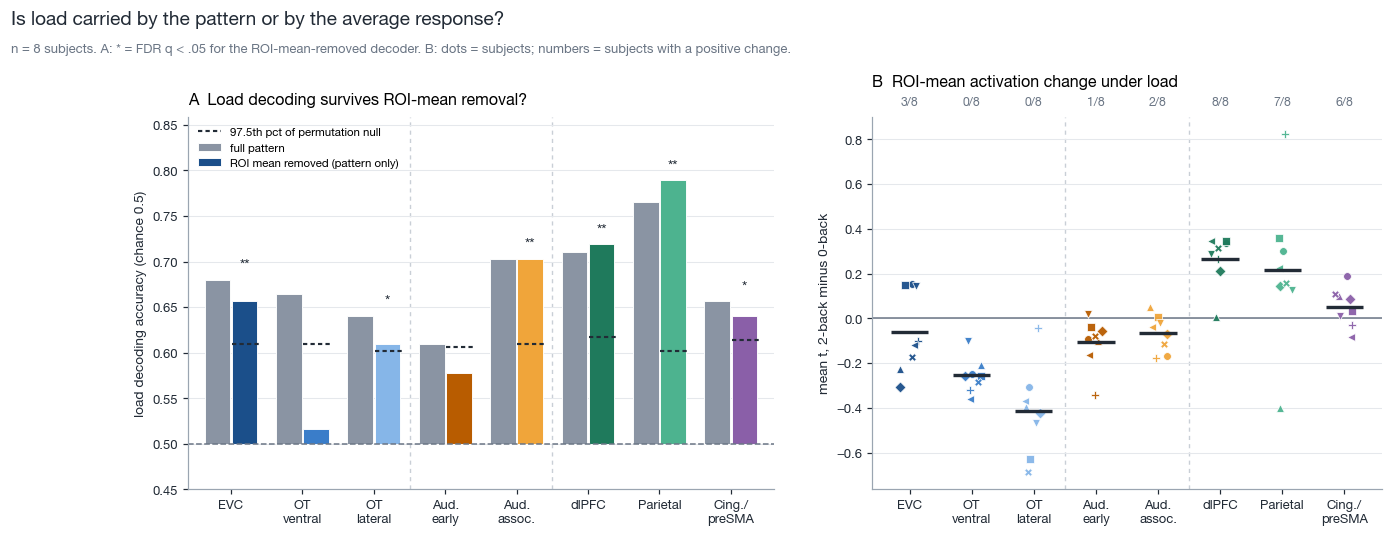

Load decoding: full pattern vs pattern with ROI-mean removed, and the ROI-mean activation difference
        roi  acc_full  acc_pattern_only  p_pattern_only  null_95  mean_activation_diff  n_subjects_positive  q_pattern_only
        EVC     0.680             0.656           0.003    0.609                -0.060                    3           0.007
 OT_ventral     0.664             0.516           0.372    0.609                -0.255                    0           0.372
 OT_lateral     0.641             0.609           0.020    0.602                -0.415                    0           0.027
  AUD_early     0.609             0.578           0.106    0.606                -0.107                    1           0.121
  AUD_assoc     0.703             0.703           0.003    0.609                -0.067                    2           0.007
   FP_dlpfc     0.711             0.719           0.003    0.617                 0.264                    8           0.007
FP_parietal     0.766          

In [17]:
# =============================================================================
# STAGE 5e - IS LOAD CARRIED BY THE PATTERN OR BY THE AVERAGE RESPONSE?
# =============================================================================
# A classifier that separates 2-back from 0-back may be using the spatial arrangement of activity inside the ROI
# (genuine multivoxel information), or it may just be noticing that the whole region is more active under 2-back.
# The two are scientifically different claims, and only the first supports a representational interpretation.
#
# The test follows Coutanche (2013): subtract, from every sample, that sample's mean across the ROI's grayordinates.
# That removes the overall activation level and leaves only the pattern. If accuracy survives, the code is spatial.
#   Panel A  load decoding with the full pattern versus with the ROI mean removed, against the permutation null
#   Panel B  the ROI-mean activation change itself (2-back minus 0-back) with one dot per subject, which says
#            whether the region simply goes up or down under load
# Needs the decoding helpers, wm_dec and the style cell.
LOAD_NAME = "load (0- vs 2-back)"
amp_rows, amp_subject = [], {}
for roi in ROI_ORDER:
    d = datasets[roi] if "datasets" in globals() and roi in datasets else build_dataset(roi, "WM")
    K, y, s, tr, te, chance, groups = wm_analyses(d)[LOAD_NAME]
    full = LosoModel(K, s, tr, te).accuracy(y)
    Xp = d["X_load"] - d["X_load"].mean(axis=1, keepdims=True)                   # remove each sample's ROI-mean
    model_p = LosoModel(Xp @ Xp.T, s, tr, te)
    obs, null, p = permutation_test(model_p, y, groups, PLOT_NPERM if "PLOT_NPERM" in globals() else 300, seed=2)
    pat = model_p.accuracy(y)
    amp = np.array([np.mean([load_patterns(sid)[f"WM_{run}_t"][4:8][:, roi_masks[roi]].mean() - load_patterns(sid)[f"WM_{run}_t"][:4][:, roi_masks[roi]].mean()
                             for run in ("LR", "RL")]) for sid in SUBJECTS])
    amp_subject[roi] = amp
    amp_rows.append(dict(roi=roi, acc_full=full.mean(), acc_pattern_only=pat.mean(), p_pattern_only=p, null_95=np.percentile(null, 97.5),
                         mean_activation_diff=amp.mean(), n_subjects_positive=int((amp > 0).sum())))
amp_df = pd.DataFrame(amp_rows)
amp_df["q_pattern_only"] = bh_fdr(amp_df.p_pattern_only.values)
note("Load decoding: full pattern vs pattern with ROI-mean removed, and the ROI-mean activation difference")
note(amp_df.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.15, 1], wspace=.18))
ax = axes[0]; w = .36
group_dividers(ax, "x")
for i, roi in enumerate(ROI_ORDER):
    r = amp_df[amp_df.roi == roi].iloc[0]
    ax.bar(i - w / 2 - .01, r.acc_full - .5, w, bottom=.5, color=C_FULL, edgecolor="white", lw=.6, label="full pattern" if i == 0 else None)
    ax.bar(i + w / 2 + .01, r.acc_pattern_only - .5, w, bottom=.5, color=ROI_COLORS[roi], edgecolor="white", lw=.6,
           label="ROI mean removed (pattern only)" if i == 0 else None)
    ax.plot([i + .01, i + w + .03], [r.null_95] * 2, color=INK, lw=1.4, ls=(0, (2, 1.5)), label="97.5th pct of permutation null" if i == 0 else None)
    ax.text(i + w / 2 + .01, max(r.acc_pattern_only, r.acc_full) + .012, stars(r.q_pattern_only), ha="center", fontsize=10, color=INK)
ax.axhline(.5, color=MUTED, ls="--", lw=1)
roi_ticks(ax, "x"); ax.set_ylim(.45, max(.6, float(np.nanmax(np.r_[amp_df.acc_full.values, amp_df.acc_pattern_only.values])) + .07)); ax.set_ylabel("load decoding accuracy (chance 0.5)")
ax.legend(loc="upper left", fontsize=7.5, ncol=1); ax.set_title("A  Load decoding survives ROI-mean removal?")
ax = axes[1]
group_dividers(ax, "x")
for i, roi in enumerate(ROI_ORDER):
    v = amp_subject[roi]
    strip(ax, i, v, ROI_COLORS[roi], seed=i, subjects=SUBJECTS)
    ax.text(i, 1.03, f"{int((v > 0).sum())}/{len(v)}", transform=ax.get_xaxis_transform(), ha="center", fontsize=8, color=MUTED)
ax.axhline(0, color=MUTED, lw=1)
roi_ticks(ax, "x"); ax.set_ylabel("mean t, 2-back minus 0-back"); ax.set_title("B  ROI-mean activation change under load", pad=20)
fig_title(fig, "Is load carried by the pattern or by the average response?",
          f"n = {len(SUBJECTS)} subjects. A: * = FDR q < .05 for the ROI-mean-removed decoder. B: dots = subjects; numbers = subjects with a positive change.", y=1.1)
save_fig(fig, "load_amplitude_vs_pattern.png")

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


## Stage 6 — Matched resting-state null

The question every pipeline should be asked: **what does it report when there is nothing to find?**

The helper cell defines the shared tools for the rest of the notebook (the equivalence test and the full 8×8 H1
statistics). The cell after it finds every subject in `SUBJECTS` that has resting-state files, draws random
405-frame windows of resting data, fits the real HRF-convolved WM design with the same AR(1) GLM used for the task
patterns, and compares the observed task statistics against that null — per subject, and for the group once two or
more subjects have resting runs. Draws are cached per subject, so adding a subject only computes the new one. Only
the four path templates need editing.

In [18]:
# =============================================================================
# STAGE 6 - SHARED HELPERS FOR THE NOVELTY ANALYSES
# =============================================================================
# Settings and functions used by everything from here to the end. Run after Stages 0-5. Everything in this section
# reads derivatives/<subject>_patterns.npz and writes tables and figures to derivatives/novelty/.
#
# The equivalence margins are the important lines. They are fixed HERE, before any result is seen, because an
# equivalence test only means something if the margin was not chosen to fit the answer:
#   EQUIV_MARGIN_ACC = 0.10       a loss of up to 10 accuracy points across load counts as negligible
#   EQUIV_MARGIN_TRANSFER = 0.25  a transfer ratio within 0.25 of 1 counts as the same code
#
# tost_one_sample    two one-sided t-tests. Ordinary tests can only fail to reject a difference, which is not
#                    evidence of equality; TOST asks the opposite question - is the effect small enough to be
#                    uninteresting? With eight subjects it is a weak test, so a failed TOST means "unresolved",
#                    never "the effect is real".
# h1_stats_from_rdm  reads the whole 8x8 distance matrix and returns the quantities the load-invariance claim is
#                    built on: within-load distinctness at each load, their ratio (gain), the cross-load transfer
#                    numerator, the normalised transfer ratio, and the original 6-pair Spearman statistic.
#                    The transfer numerator is cross-load-different-category distance minus cross-load-same-category
#                    distance: the overall load effect sits in both terms and cancels, so what is left is the
#                    category information that survived the change of load. Its expected value is 0 if the two loads
#                    use unrelated codes.
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NOVELTY_SEED = 2026
EQUIV_MARGIN_ACC = 0.10        # decoding-accuracy loss across load treated as "negligible" (fix BEFORE looking at results)
EQUIV_MARGIN_TRANSFER = 0.25   # loss in the category-code transfer ratio treated as "negligible"
N_PERM_GROUP = 5000            # random draws for group-level permutation nulls
NOVELTY_DIR = os.path.join(OUT_DIR, "novelty")
os.makedirs(NOVELTY_DIR, exist_ok=True)
TRI4 = np.triu_indices(4, 1)
ALL_PERMS = list(itertools.permutations(range(4)))      # 24 relabelings of the four categories

_pattern_cache = {}


def get_patterns(sid):
    """Load (and cache) one subject's pattern file as a plain dict of arrays."""
    if sid not in _pattern_cache:
        with np.load(os.path.join(OUT_DIR, f"{sid}_patterns.npz")) as P:
            _pattern_cache[sid] = {k: P[k] for k in P.files}
    return _pattern_cache[sid]


def nonflat(A, B):
    keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
    return A[:, keep], B[:, keep]


def tost_one_sample(x, margin, alpha=0.05):
    """Two one-sided t-tests (TOST): is the mean of x inside [-margin, +margin]?
    Equivalent to asking whether the (1 - 2*alpha) CI lies inside the margin. n is small, so the t distribution is used."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 3:
        return dict(n=n, mean=np.nan, ci90_lo=np.nan, ci90_hi=np.nan, p_tost=np.nan, equivalent=False)
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(n)
    if se == 0:
        inside = abs(m) < margin
        return dict(n=n, mean=m, ci90_lo=m, ci90_hi=m, p_tost=0.0 if inside else 1.0, equivalent=inside)
    dof = n - 1
    p_lo = 1 - stats.t.cdf((m + margin) / se, dof)     # H0: true mean <= -margin
    p_hi = stats.t.cdf((m - margin) / se, dof)         # H0: true mean >= +margin
    tcrit = stats.t.ppf(1 - alpha, dof)
    p = max(p_lo, p_hi)
    return dict(n=n, mean=m, ci90_lo=m - tcrit * se, ci90_hi=m + tcrit * se, p_tost=p, equivalent=bool(p < alpha))


def h1_stats_from_rdm(D, perm=None):
    """Full 8x8 view of H1 from a cross-validated RDM (rows 0-3 = 0-back, 4-7 = 2-back; categories faces, places, tools, body).
      within0 / within2 : mean category distinctness inside each load (6 pairs each)
      gain              : within2 / within0 (how much category geometry strengthens or weakens under load; unstable if within0 ~ 0)
      transfer_num      : cross-load DIFFERENT-category distance minus cross-load SAME-category distance. The load main effect
                          appears in both terms and cancels, so this is the category distinctness that survives the load change.
                          Expected value 0 if there is no shared category code.
      within            : mean of within0 and within2
      transfer          : transfer_num / within for ONE subject (1 = same code under both loads, 0 = none). Noisy when `within` is
                          small; the group analysis therefore divides every subject's numerator by the GROUP-mean `within` instead.
      rho               : the original H1 statistic (Spearman between the two 6-pair sub-RDMs)
    `perm` relabels the 2-back categories (used for the permutation null: breaking the category correspondence between loads)."""
    perm = np.arange(4) if perm is None else np.asarray(perm)
    w0, w2 = D[:4, :4][TRI4], D[4:, 4:][TRI4]
    cross = D[:4, 4:][:, perm]
    off = ~np.eye(4, dtype=bool)
    num = cross[off].mean() - np.diag(cross).mean()
    within = 0.5 * (w0.mean() + w2.mean())
    transfer = num / within if within > 0 else np.nan
    gain = w2.mean() / w0.mean() if w0.mean() > 0 else np.nan
    rho = stats.spearmanr(w0, w2)[0]
    return dict(rho=float(rho), transfer_num=float(num), within=float(within), transfer=float(transfer), gain=float(gain),
                within0=float(w0.mean()), within2=float(w2.mean()))


def transfer_num(D, perm):
    cross = D[:4, 4:][:, perm]
    off = ~np.eye(4, dtype=bool)
    return cross[off].mean() - np.diag(cross).mean()


def h1_stats(A, B):
    return h1_stats_from_rdm(crossnobis_rdm(A, B))


def signflip_mean_p(x, n_perm=10000, seed=0):
    """Two-sided sign-flip test across subjects. With n subjects the smallest possible p is 2 / 2**n (0.0625 at n = 5)."""
    return signflip_p(np.asarray(x, float)[np.isfinite(x)], n_perm=n_perm, seed=seed)


print("Helpers ready. Equivalence margins: accuracy", EQUIV_MARGIN_ACC, "| transfer ratio", EQUIV_MARGIN_TRANSFER)


Helpers ready. Equivalence margins: accuracy 0.1 | transfer ratio 0.25


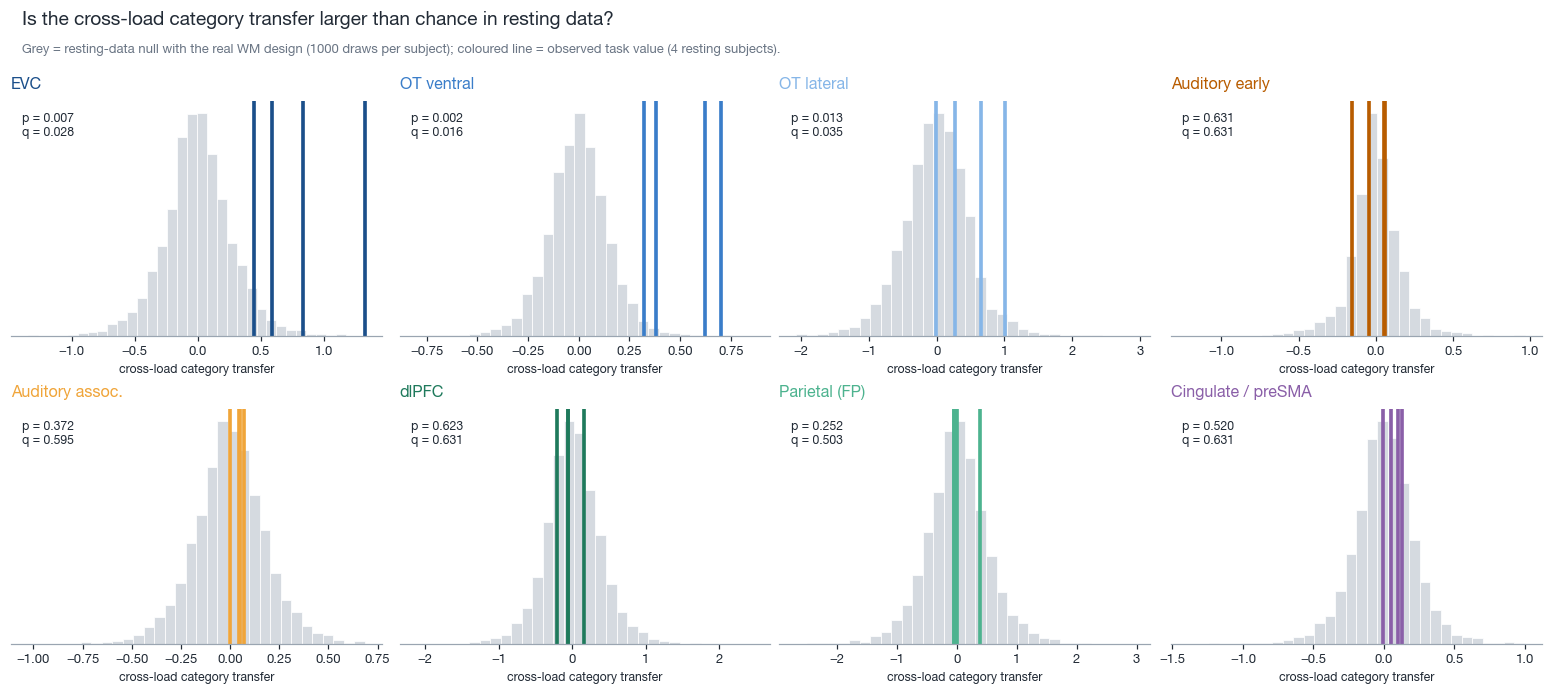

Resting data found for: ['103414', '107321', '139839', '108121']
No resting data (yet) for: ['105014', '103212', '115219', '101107'] -> they are skipped
103414: using saved draws (derivatives/novelty/rfmri_null_draws_103414.csv)
107321: using saved draws (derivatives/novelty/rfmri_null_draws_107321.csv)
139839: using saved draws (derivatives/novelty/rfmri_null_draws_139839.csv)
108121: using saved draws (derivatives/novelty/rfmri_null_draws_108121.csv)

Observed task statistic vs resting-state matched null (p = share of null draws >= observed; q = BH within statistic x level)
transfer_num is the primary statistic; rho (6-pair Spearman) is kept only to show how noisy it is.
     level         roi    statistic  observed  null_mean  null_sd  null_95  p_empirical  n_draws  q_fdr
    103414   AUD_assoc          rho    -0.486      0.059    0.460    0.771        0.874     1000  0.996
    103414   AUD_early          rho    -0.771      0.085    0.464    0.771        0.981     1000  0.996
    10

In [19]:
# =============================================================================
# STAGE 6a - RESTING-STATE MATCHED NULL
# =============================================================================
# The most honest question to ask about any pipeline is: what does it report when there is nothing to find?
# This cell answers it with the subject's own resting-state data. For each subject that has resting runs, it draws
# many random 405-frame windows of resting data, imposes the REAL HRF-convolved WM design on them, fits the same
# AR(1) GLM, and computes the same H1 statistics. There was no task during rest, so whatever the pipeline reports
# on those windows is what the design, the preprocessing and the noise structure produce on their own.
#
# The observed task statistic is then ranked inside that null, per subject, and - once two or more subjects have
# resting runs - against a GROUP null built by averaging over subjects within each draw, which is the comparison
# that matches a group-level claim.
#
# Practicalities: draws are cached per subject in derivatives/novelty/rfmri_null_draws_<sid>.csv, so adding a
# subject only computes the new one (delete the file to recompute). Edit only the four path templates below;
# {sid} and {run} are filled in automatically.
import os
import time
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

# ---- paths: {sid} and {run} are filled in; edit only these four lines ----
REST_DIR = "/Users/shwetharao/Downloads/{sid}_rest/MNINonLinear/Results/rfMRI_REST1_{run}"
REST_FILE = REST_DIR + "/rfMRI_REST1_{run}_Atlas_MSMAll_hp2000_clean_rclean_tclean.dtseries.nii"
REST_MOTION = REST_DIR + "/Movement_Regressors.txt"
TASK_EV_DIR = "/Users/shwetharao/Downloads/{sid}/MNINonLinear/Results/tfMRI_WM_{run}/EVs"

N_DRAWS = 1000                  # random windows per resting subject (both runs drawn independently); 100 is enough for a quick look
RECOMPUTE_NULL = False          # True: ignore saved draws and redo every subject
N_WM_TRS, TR_WM = 405, 0.72


def _ev_dir_for(sid, run):
    """The WM event files only define the design shape. Use the subject's own if present, otherwise any other subject's
    (a null design needs a realistic block structure, not the subject's own timing)."""
    for cand in [sid] + [s for s in SUBJECTS if s != sid]:
        d = TASK_EV_DIR.format(sid=cand, run=run)
        if os.path.isdir(d) and os.path.isfile(os.path.join(os.path.dirname(d), "Movement_Regressors.txt")):
            if cand != sid:
                print(f"  {sid} {run}: own WM EV folder not found, using {cand}'s block structure")
            return d
    raise FileNotFoundError(f"No WM EV folder found for any subject (template: {TASK_EV_DIR})")


def _load_rest(path, union_mask):
    Y = np.asarray(nib.load(path).get_fdata(dtype=np.float32))
    if Y.ndim != 2 or Y.shape[1] != union_mask.size:
        raise ValueError(f"Unexpected shape {Y.shape} for {path}")
    return Y[:, union_mask].astype(np.float64)


def _rest_motion(path, n_rows):
    with open(path) as fh:
        M = np.loadtxt(fh)[:, :12]
    if M.shape[0] != n_rows:
        raise ValueError(f"Motion rows ({M.shape[0]}) != rest frames ({n_rows}) in {path}")
    return M


def rest_available(sid):
    return all(os.path.isfile(REST_FILE.format(sid=sid, run=r)) and os.path.isfile(REST_MOTION.format(sid=sid, run=r)) for r in ("LR", "RL"))


def null_draws_for_subject(sid, n_draws=N_DRAWS):
    rng = np.random.default_rng(NOVELTY_SEED + int("".join(ch for ch in sid if ch.isdigit()) or 0))
    union = np.any(np.vstack(list(roi_masks.values())), axis=0)
    roi_in_union = {roi: m[union] for roi, m in roi_masks.items()}
    loaded = {}
    for run in ("LR", "RL"):
        Y = _load_rest(REST_FILE.format(sid=sid, run=run), union)
        M = _rest_motion(REST_MOTION.format(sid=sid, run=run), Y.shape[0])
        ev_dir = _ev_dir_for(sid, run)
        task_cols = build_design(ev_dir, os.path.join(os.path.dirname(ev_dir), "Movement_Regressors.txt"),
                                 WM_CONDS, N_WM_TRS, TR_WM).iloc[:, :8].values       # HRF-convolved WM regressors
        dct = generate_dct_basis(N_WM_TRS, TR_WM, 128.0).values
        loaded[run] = (Y, M, task_cols, dct)
        print(f"{sid} {run}: {Y.shape[0]} resting frames, {N_WM_TRS}-frame windows, {Y.shape[1]} ROI-union grayordinates")
    records, t0 = [], time.time()
    for d in range(n_draws):
        pats = {}
        for run, (Y, M, task_cols, dct) in loaded.items():
            start = int(rng.integers(0, Y.shape[0] - N_WM_TRS + 1))
            X = np.column_stack([task_cols, M[start:start + N_WM_TRS], dct, np.ones(N_WM_TRS)])
            Cm = np.zeros((8, X.shape[1])); Cm[np.arange(8), np.arange(8)] = 1.0
            _, tstats, _ = fit_glm_ar1_binned(Y[start:start + N_WM_TRS], X, Cm)
            pats[run] = tstats
        for roi, m in roi_in_union.items():
            A, B = nonflat(pats["LR"][:, m], pats["RL"][:, m])
            if A.shape[1] == 0:
                continue
            records.append(dict(subject=sid, draw=d, roi=roi, n_features=A.shape[1], **h1_stats(A, B)))
        if d == 0:
            print(f"  first draw took {time.time() - t0:.1f} s -> about {(time.time() - t0) * n_draws / 60:.0f} min for {n_draws} draws")
        elif (d + 1) % max(1, n_draws // 10) == 0:
            print(f"  {sid}: draw {d + 1}/{n_draws}")
    return pd.DataFrame(records)


# ---- run (or load) the null for every subject that has resting data ----
rest_subjects = [s for s in SUBJECTS if rest_available(s)]
missing = [s for s in SUBJECTS if s not in rest_subjects]
note("Resting data found for:", rest_subjects or "none")
if missing:
    note("No resting data (yet) for:", missing, "-> they are skipped")
if not rest_subjects:
    raise RuntimeError("No subject has resting-state files at the paths above.")
frames = []
for sid in rest_subjects:
    f = os.path.join(NOVELTY_DIR, f"rfmri_null_draws_{sid}.csv")
    if os.path.isfile(f) and not RECOMPUTE_NULL:
        note(f"{sid}: using saved draws ({f})")
        df = pd.read_csv(f, dtype={"subject": str})
    else:
        df = null_draws_for_subject(sid)
        df.to_csv(f, index=False)
    frames.append(df)
rfmri_null = pd.concat(frames, ignore_index=True)

# ---- observed task statistics for the same subjects ----
obs_rows = []
for sid in rest_subjects:
    P = get_patterns(sid)
    for roi, mask in roi_masks.items():
        A, B = nonflat(P["WM_LR_t"][:, mask].astype(float), P["WM_RL_t"][:, mask].astype(float))
        obs_rows.append(dict(subject=sid, roi=roi, **h1_stats(A, B)))
obs = pd.DataFrame(obs_rows)

# ---- per-subject comparison ----
cmp_rows = []
for roi in roi_masks:
    for stat in ("transfer_num", "rho"):
        for sid in rest_subjects:
            nul = rfmri_null[(rfmri_null.roi == roi) & (rfmri_null.subject == sid)][stat].dropna().values
            o = obs[(obs.roi == roi) & (obs.subject == sid)][stat].iloc[0]
            cmp_rows.append(dict(level=sid, roi=roi, statistic=stat, observed=o, null_mean=nul.mean(), null_sd=nul.std(ddof=1),
                                 null_95=np.percentile(nul, 95), p_empirical=(1 + np.sum(nul >= o)) / (len(nul) + 1), n_draws=len(nul)))
# ---- group comparison (needs 2+ resting subjects): mean over subjects inside each draw ----
if len(rest_subjects) >= 2:
    for roi in roi_masks:
        for stat in ("transfer_num", "rho"):
            piv = rfmri_null[rfmri_null.roi == roi].pivot(index="draw", columns="subject", values=stat)[rest_subjects].dropna()
            gnull = piv.mean(axis=1).values
            o = obs[obs.roi == roi].set_index("subject").loc[rest_subjects, stat].mean()
            cmp_rows.append(dict(level="GROUP(n=%d)" % len(rest_subjects), roi=roi, statistic=stat, observed=o, null_mean=gnull.mean(),
                                 null_sd=gnull.std(ddof=1), null_95=np.percentile(gnull, 95),
                                 p_empirical=(1 + np.sum(gnull >= o)) / (len(gnull) + 1), n_draws=len(gnull)))
null_cmp = pd.DataFrame(cmp_rows)
# FDR inside each family (statistic x level), not across unrelated tests
null_cmp["q_fdr"] = np.nan
for (stat, level), idx in null_cmp.groupby(["statistic", "level"]).groups.items():
    null_cmp.loc[idx, "q_fdr"] = bh_fdr(null_cmp.loc[idx, "p_empirical"].values)
note("\nObserved task statistic vs resting-state matched null (p = share of null draws >= observed; q = BH within statistic x level)")
note("transfer_num is the primary statistic; rho (6-pair Spearman) is kept only to show how noisy it is.")
note(null_cmp.sort_values(["statistic", "level", "roi"]).round(3).to_string(index=False))
if len(rest_subjects) < 2:
    note("\nCAUTION: only %d resting subject. These p-values apply to that subject only; add resting runs for more subjects for a group claim." % len(rest_subjects))
note("\nSmallest possible p with %d draws: %.4f" % (N_DRAWS, 1.0 / (N_DRAWS + 1)))

n_rest = len(rest_subjects)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6), constrained_layout=True)
for ax, roi in zip(axes.ravel(), ROI_ORDER):
    nul = rfmri_null[rfmri_null.roi == roi].transfer_num.dropna()
    ax.hist(nul, bins=32, color="#D5DAE0", edgecolor="white", lw=.5)
    for _, o in obs[obs.roi == roi].iterrows():
        ax.axvline(o.transfer_num, color=ROI_COLORS[roi], lw=2.4)
    cmp1 = null_cmp[(null_cmp.roi == roi) & (null_cmp.statistic == "transfer_num") & (null_cmp.level == rest_subjects[0])]
    if len(cmp1):
        c1 = cmp1.iloc[0]
        ax.text(.03, .95, f"p = {c1.p_empirical:.3f}\nq = {c1.q_fdr:.3f}", transform=ax.transAxes, ha="left", va="top", fontsize=8, color=INK, bbox=dict(fc="white", ec="none", alpha=.8, pad=1.5))
    ax.set_title(ROI_NAME[roi], color=ROI_COLORS[roi]); ax.set_yticks([]); ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("cross-load category transfer", fontsize=8)
fig_title(fig, "Is the cross-load category transfer larger than chance in resting data?",
          f"Grey = resting-data null with the real WM design ({N_DRAWS} draws per subject); coloured line = observed task value ({n_rest} resting subject{'s' if n_rest != 1 else ''}"
          + ("; applies to that subject only" if n_rest < 2 else "") + ").", y=1.1)
save_fig(fig, "rfmri_null_transfer.png")
null_cmp.to_csv(os.path.join(NOVELTY_DIR, "rfmri_null_vs_observed.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


## Stage 7 — RSA validation, RDM inference and the noise ceiling

Three cells that test the machinery rather than the hypothesis: synthetic unit tests for the distance code, a
Mantel-style permutation test for RDM similarity (permuting condition labels jointly on both axes, which keeps the
matrix a valid RDM), subject-level bootstrap intervals, and a descriptive leave-one-subject-out noise ceiling. They
use this notebook's own `crossnobis_rdm`, so a bug in it would show up here first. Run after Stage 2.

In [20]:
# =============================================================================
# STAGE 7 - RSA VALIDATION: unit tests for the distance code
# =============================================================================
# Before trusting the RDMs, test the function that produces them on data whose answer is known. The checks are:
# the matrix is square, symmetric and has a zero diagonal; two conditions with a genuine mean difference give a
# positive cross-validated distance; pure noise gives a mean distance near zero (the property that makes negative
# values meaningful rather than a bug); and the rank-correlation functions used later return the expected signs.
# A failed assertion here stops the notebook, which is the point.
import numpy as np
from scipy.stats import spearmanr, kendalltau

def run_rsa_unit_tests(seed=123):
    """Fast tests for symmetry/diagonal, crossnobis recovery, and rank correlation."""
    rng = np.random.default_rng(seed)
    # Same patterns in independent runs plus independent noise: distances should be symmetric with zero diagonal.
    base = rng.normal(size=(8, 30))
    A = base + rng.normal(scale=.15, size=base.shape)
    B = base + rng.normal(scale=.15, size=base.shape)
    D = crossnobis_rdm(A, B)
    assert D.shape == (8, 8), D.shape
    assert np.allclose(D, D.T, atol=1e-12), "crossnobis RDM must be symmetric"
    assert np.allclose(np.diag(D), 0), "crossnobis RDM diagonal must be zero"
    assert np.all(np.isfinite(D)), "crossnobis RDM contains non-finite values"
    # Distinct condition means should be recovered as positive cross-validated distances on average.
    assert np.mean(D[np.triu_indices(8, 1)]) > 0, "synthetic signal did not produce positive mean distance"
    assert spearmanr([1, 2, 3, 4], [4, 3, 2, 1]).statistic < -.99
    assert kendalltau([1, 2, 3], [1, 2, 3]).statistic > .99
    # Zero signal gives expected distance approximately zero in expectation; finite sample tolerance is broad.
    Z = rng.normal(size=(8, 2000))
    Dz = crossnobis_rdm(Z, rng.normal(size=Z.shape))
    assert abs(Dz[np.triu_indices(8, 1)].mean()) < .08
    return {"tests": 7, "status": "passed"}

print(run_rsa_unit_tests())


{'tests': 7, 'status': 'passed'}


### Stage 7a — Haxby-style identification and feature-removal robustness

`removal_curve` compares removing the most category-selective grayordinates against removing the same number at
random. Selection is computed in one run and scored across runs, so the selection cannot be fitted to the data it is
judged on. Read the result as robustness, not as a confirmatory p-value; Stage 12 turns it into a per-subject
excess-drop statistic with an interval.

In [21]:
# =============================================================================
# STAGE 7a - HAXBY-STYLE FEATURE REMOVAL: is the category code distributed?
# =============================================================================
# Haxby et al. (2001) asked whether category information survives after the most selective voxels are taken away.
# If it does, the code is distributed across the region rather than carried by a handful of specialised units.
#
# Two details make the test fair. First, the grayordinates to remove are chosen using ONE run and the accuracy is
# measured across runs, so the selection cannot be fitted to the data it is scored on. Second, removing any features
# lowers accuracy simply because there are fewer of them, so selective removal is always compared with removing the
# same NUMBER of randomly chosen features (100 random draws). The quantity of interest is the difference between
# the two, which Stage 12 turns into an "excess drop" per subject.
# Read the result as robustness, not as a confirmatory p-value.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REMOVAL_FRACS = (0, .1, .2, .3, .5, .7)
removal_rows = []
for sid in SUBJECTS:
    pfile = os.path.join(OUT_DIR, f"{sid}_patterns.npz")
    if not os.path.exists(pfile):
        print(f"Skipping {sid}: missing {pfile}"); continue
    P = np.load(pfile)
    Aall, Ball = P["WM_LR_t"], P["WM_RL_t"]
    for roi, mask in roi_masks.items():
        A, B = Aall[:, mask], Ball[:, mask]
        keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
        A, B = A[:, keep], B[:, keep]
        if A.shape[1] < 10:
            print(f"Skipping {sid}/{roi}: too few nonconstant features ({A.shape[1]})"); continue
        selective, random = removal_curve(A, B, fracs=REMOVAL_FRACS, n_rand=100, seed=2026)
        for j, frac in enumerate(REMOVAL_FRACS):
            for k, outcome in enumerate(("within_0back", "within_2back", "cross_load")):
                removal_rows.append({"subject": sid, "roi": roi, "removed_fraction": frac,
                                     "outcome": outcome, "selective_removal": selective[j, k],
                                     "random_removal": random[j, k], "n_features": A.shape[1]})
removal_df = pd.DataFrame(removal_rows)
if not removal_df.empty:
    display(removal_df.head(12))
    group_removal = removal_df.groupby(["roi", "removed_fraction", "outcome"], as_index=False).agg(
        selective_mean=("selective_removal", "mean"), random_mean=("random_removal", "mean"), n_subjects=("subject", "nunique"))
    # (the per-outcome curves that used to be drawn here are replaced by the per-ROI panels in the selective-voxel-removal cell)
    removal_df.to_csv(os.path.join(OUT_DIR, "haxby_removal_curve_subject_level.csv"), index=False)
else:
    print("No removal results: confirm pattern files and ROI masks are available.")


,subject,roi,removed_fraction,outcome,selective_removal,random_removal,n_features
0,103414,EVC,0.0,within_0back,0.916667,0.916667,3632
1,103414,EVC,0.0,within_2back,0.958333,0.958333,3632
2,103414,EVC,0.0,cross_load,0.833333,0.833333,3632
3,103414,EVC,0.1,within_0back,0.916667,0.916667,3632
4,103414,EVC,0.1,within_2back,0.875000,0.933750,3632
5,103414,EVC,0.1,cross_load,0.833333,0.833333,3632
6,103414,EVC,0.2,within_0back,0.895833,0.916667,3632
7,103414,EVC,0.2,within_2back,0.812500,0.930417,3632
8,103414,EVC,0.2,cross_load,0.791667,0.837083,3632
9,103414,EVC,0.3,within_0back,0.812500,0.915417,3632


### Stage 7b — RDM inference: Mantel test, bootstrap and noise ceiling

RDM vectors are the upper-triangular entries. The Mantel-style test permutes condition labels in one RDM, applying
the same permutation to rows and columns so that the result is still a valid RDM; it asks whether the two
load-specific 4×4 RDMs are more similar than relabelling would make them. With four categories there are only 24
relabelings, so the statistic is coarse and is reported as a companion, not as the primary test. Group summaries
resample subjects, never condition pairs. The noise ceiling is a descriptive lower and upper bound on how much
agreement is even available in each region, not a substitute for a hierarchical model.

In [22]:
# =============================================================================
# STAGE 7b - RDM INFERENCE: Mantel test, subject bootstrap and a noise ceiling
# =============================================================================
# Three descriptive tools applied to the 4x4 category RDMs at each load.
#   Mantel test     asks whether the 0-back and 2-back category RDMs are more similar than they would be if the
#                   category labels of one of them were shuffled. The permutation is applied jointly to rows and
#                   columns, which keeps the matrix a valid RDM - this is why an ordinary correlation test is wrong
#                   here. Note that with four categories there are only 24 relabelings, so the statistic is coarse.
#   subject bootstrap  resamples SUBJECTS, never individual condition pairs, because pairs within a subject are not
#                   independent observations.
#   noise ceiling   how much agreement is even possible: each subject's RDM against the mean of the OTHER subjects
#                   (lower bound) and against the mean including themselves (upper bound). A model cannot be
#                   expected to beat the upper bound, and in an ROI with a low ceiling no comparison is meaningful.
#                   This is a descriptive bound, not a substitute for a hierarchical model.
from itertools import permutations
from scipy.stats import spearmanr, kendalltau


def rdm_vector(D):
    D = np.asarray(D, float)
    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("RDM must be square")
    tri = np.triu_indices(D.shape[0], 1)
    return D[tri]


def mantel_rdm_test(D1, D2, n_perm=5000, seed=0, method="spearman"):
    """Two-sided label-permutation test of RDM association; labels permuted jointly on both axes of D2."""
    D1, D2 = np.asarray(D1, float), np.asarray(D2, float)
    if D1.shape != D2.shape or D1.ndim != 2 or D1.shape[0] != D1.shape[1]:
        raise ValueError("RDMs must be square and have identical shapes")
    n = D1.shape[0]
    tri = np.triu_indices(n, 1)
    def stat(X, Y):
        if method == "kendall": return float(kendalltau(X[tri], Y[tri], variant="b").statistic)
        return float(spearmanr(X[tri], Y[tri]).statistic)
    obs = stat(D1, D2)
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        ix = rng.permutation(n)
        null[i] = stat(D1, D2[np.ix_(ix, ix)])
    p = (1 + np.sum(np.abs(null) >= abs(obs))) / (n_perm + 1)
    return obs, p, null


def subject_bootstrap_ci(values, n_boot=10000, seed=0, confidence=95):
    """Percentile CI resampling subjects, never individual condition pairs."""
    x = np.asarray(values, float)
    x = x[np.isfinite(x)]
    if len(x) == 0: return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    boot = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    alpha = (100-confidence)/2
    return tuple(np.percentile(boot, [alpha, 100-alpha]))

# Build per-subject load-specific RDMs, Mantel p-values, and subject-level noise ceiling.
rdm_store, infer_rows = {}, []
tri4 = np.triu_indices(4, 1)
for sid in SUBJECTS:
    pfile = os.path.join(OUT_DIR, f"{sid}_patterns.npz")
    if not os.path.exists(pfile): continue
    P = np.load(pfile)
    for roi, mask in roi_masks.items():
        A, B = P["WM_LR_t"][:, mask].astype(float), P["WM_RL_t"][:, mask].astype(float)
        keep = (A.std(axis=0) > 1e-12) & (B.std(axis=0) > 1e-12)
        if keep.sum() < 2: continue
        D = crossnobis_rdm(A[:, keep], B[:, keep])
        D0, D2 = D[:4, :4], D[4:8, 4:8]
        rho, p_mantel, _ = mantel_rdm_test(D0, D2, n_perm=5000, seed=(sum(ord(ch) for ch in str(sid)) * 1009 + sum(ord(ch) for ch in str(roi))) % (2**32))
        tau = kendalltau(rdm_vector(D0), rdm_vector(D2), variant="b").statistic
        rdm_store[(sid, roi, "0back")] = D0
        rdm_store[(sid, roi, "2back")] = D2
        infer_rows.append({"subject": sid, "roi": roi, "spearman_structure": rho,
                           "kendall_structure": tau, "mantel_p": p_mantel,
                           "mean_abs_0back": np.mean(np.abs(rdm_vector(D0))),
                           "mean_abs_2back": np.mean(np.abs(rdm_vector(D2)))})
rdm_inference = pd.DataFrame(infer_rows)
if not rdm_inference.empty:
    # BH correction is across ROI-level Mantel tests in this table.
    rdm_inference["mantel_q_fdr"] = bh_fdr(rdm_inference["mantel_p"].values)
    display(rdm_inference.round(4))
    group_rows = []
    for roi, g in rdm_inference.groupby("roi"):
        for metric in ("spearman_structure", "kendall_structure"):
            lo, hi = subject_bootstrap_ci(g[metric].values)
            group_rows.append({"roi": roi, "metric": metric, "mean": g[metric].mean(), "ci_low": lo,
                               "ci_high": hi, "n_subjects": g.subject.nunique(),
                               "signflip_p": signflip_p(g[metric].values) if len(g) >= 2 else np.nan})
    rdm_group_summary = pd.DataFrame(group_rows)
    display(rdm_group_summary.round(4))

    # Descriptive noise ceiling for each load/ROI: subject RDM vs mean RDM of other subjects (lower),
    # and subject RDM vs mean RDM including itself (upper). Only meaningful with >=3 subjects.
    ceiling_rows = []
    for roi in roi_masks:
        for load in ("0back", "2back"):
            keys = [(sid, roi, load) for sid in SUBJECTS if (sid, roi, load) in rdm_store]
            if len(keys) < 3: continue
            vecs = {k[0]: rdm_vector(rdm_store[k]) for k in keys}
            for sid0 in vecs:
                others = [v for s, v in vecs.items() if s != sid0]
                allv = list(vecs.values())
                lower = spearmanr(vecs[sid0], np.mean(others, axis=0)).statistic
                upper = spearmanr(vecs[sid0], np.mean(allv, axis=0)).statistic
                ceiling_rows.append({"subject": sid0, "roi": roi, "load": load,
                                     "noise_ceiling_lower": lower, "noise_ceiling_upper": upper})
    noise_ceiling_df = pd.DataFrame(ceiling_rows)
    if not noise_ceiling_df.empty:
        display(noise_ceiling_df.groupby(["roi", "load"], as_index=False).agg(
            lower_mean=("noise_ceiling_lower", "mean"), upper_mean=("noise_ceiling_upper", "mean"),
            n_subjects=("subject", "nunique")).round(4))
    else:
        print("Noise ceiling not calculated: at least 3 subjects with usable RDMs per ROI/load are required.")
else:
    print("No RDM inference results. Ensure the pattern extraction and ROI cells ran first.")


,subject,roi,spearman_structure,kendall_structure,mantel_p,mean_abs_0back,mean_abs_2back,mantel_q_fdr
0,103414,EVC,-0.8857,-0.7333,0.0396,1.4067,0.5494,0.9012
1,103414,OT_ventral,-0.3714,-0.3333,0.7129,0.3786,0.4719,1.0000
2,103414,OT_lateral,-0.0857,-0.0667,0.9608,0.9828,0.8048,1.0000
3,103414,AUD_early,-0.7714,-0.6000,0.2448,0.1025,0.1468,0.9012
4,103414,AUD_assoc,-0.4857,-0.3333,0.5047,0.1263,0.2206,0.9012
...,...,...,...,...,...,...,...,...
59,108121,AUD_early,0.8857,0.7333,0.0822,0.4825,0.3730,0.9012
60,108121,AUD_assoc,-0.5429,-0.3333,0.3329,0.1855,0.1555,0.9012
61,108121,FP_dlpfc,0.1429,0.2000,0.7449,0.4930,0.3426,1.0000
62,108121,FP_parietal,0.6571,0.4667,0.3321,0.6963,0.5369,0.9012


,roi,metric,mean,ci_low,ci_high,n_subjects,signflip_p
0,AUD_assoc,spearman_structure,0.0857,-0.2071,0.3857,8,0.6016
1,AUD_assoc,kendall_structure,0.0833,-0.1167,0.2833,8,0.4547
2,AUD_early,spearman_structure,0.1929,-0.1929,0.5500,8,0.3664
3,AUD_early,kendall_structure,0.1667,-0.1333,0.4500,8,0.3288
4,Cing_preSMA,spearman_structure,0.0929,-0.2571,0.4071,8,0.6318
5,Cing_preSMA,kendall_structure,0.1000,-0.2167,0.3500,8,0.5349
6,EVC,spearman_structure,0.1071,-0.3571,0.5071,8,0.6338
7,EVC,kendall_structure,0.0500,-0.3167,0.3667,8,0.7638
8,FP_dlpfc,spearman_structure,0.0071,-0.2145,0.2357,8,0.9304
9,FP_dlpfc,kendall_structure,0.0333,-0.1667,0.2333,8,0.7977


,roi,load,lower_mean,upper_mean,n_subjects
0,AUD_assoc,0back,-0.3571,0.1286,8
1,AUD_assoc,2back,0.1286,0.3000,8
2,AUD_early,0back,0.2643,0.3429,8
3,AUD_early,2back,0.2357,0.4357,8
4,Cing_preSMA,0back,-0.0571,0.1571,8
5,Cing_preSMA,2back,0.5500,0.5786,8
6,EVC,0back,0.4286,0.5500,8
7,EVC,2back,0.6143,0.6214,8
8,FP_dlpfc,0back,0.1571,0.3357,8
9,FP_dlpfc,2back,0.3429,0.4000,8


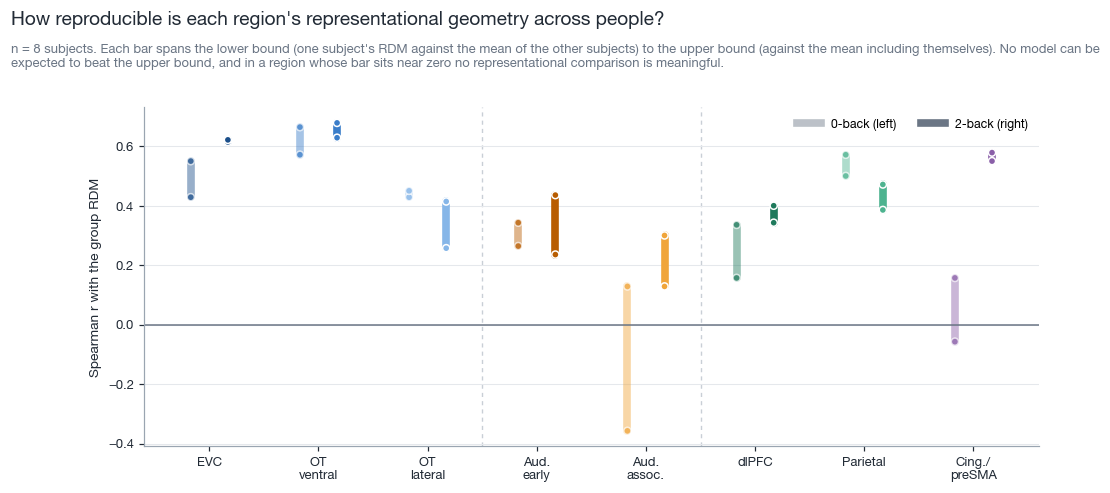

In [23]:
# =============================================================================
# STAGE 7c - NOISE-CEILING FIGURE
# =============================================================================
# Draws the ceiling computed above: one bar per ROI and load, spanning the lower to the upper bound. Read it as
# "how reproducible is this region's representational geometry across people?". Regions whose bar sits near zero
# have no consistent geometry, so any model comparison or transfer ratio computed in them is noise.
# Needs noise_ceiling_df (Stage 7b, which needs at least three subjects) and the style cell.
if "noise_ceiling_df" not in globals() or noise_ceiling_df.empty:
    print("Noise ceiling not available (needs at least 3 subjects with usable RDMs): skipped.")
else:
    fig, ax = plt.subplots(figsize=(10.5, 4))
    group_dividers(ax, "x")
    for i, roi in enumerate(ROI_ORDER):
        for k, load in enumerate(("0back", "2back")):
            g = noise_ceiling_df[(noise_ceiling_df.roi == roi) & (noise_ceiling_df.load == load)]
            if g.empty:
                continue
            x = i + (k - .5) * .34
            lo, hi = g.noise_ceiling_lower.mean(), g.noise_ceiling_upper.mean()
            ax.plot([x, x], [lo, hi], color=ROI_COLORS[roi], lw=5, solid_capstyle="round", alpha=.45 if k == 0 else 1.0)
            ax.scatter([x, x], [lo, hi], s=[22, 22], color=ROI_COLORS[roi], edgecolor="white", zorder=3, alpha=.7 if k == 0 else 1.0)
    ax.axhline(0, color=MUTED, lw=1)
    ax.plot([], [], color=MUTED, lw=5, alpha=.45, label="0-back (left)"); ax.plot([], [], color=MUTED, lw=5, label="2-back (right)")
    ax.legend(loc="upper right", ncol=2)
    roi_ticks(ax, "x"); ax.set_ylabel("Spearman r with the group RDM")
    fig_title(fig, "How reproducible is each region's representational geometry across people?",
              f"n = {len(SUBJECTS)} subjects. Each bar spans the lower bound (one subject's RDM against the mean of the other subjects) to the upper "
              "bound (against the mean including themselves). No model can be expected to beat the upper bound, and in a region whose bar sits near "
              "zero no representational comparison is meaningful.", y=1.10)
    save_fig(fig, "rdm_noise_ceiling_bands.png")


## Stage 8 — Cross-check with a linear SVM

The ridge decoder stays the primary analysis; this stage repeats the same folds with a linear SVM so that no
conclusion depends on one classifier. `StandardScaler` is fitted on the training subjects **inside each fold** —
standardising across all subjects before cross-validation leaks information about the test subject and is one of the
easiest ways to manufacture an inflated accuracy. The function returns one accuracy per held-out subject. It is a
cross-check, and it is slow across many regions and permutations; where it disagrees with ridge, Stage 9b finds out
why.

In [24]:
# =============================================================================
# STAGE 8 - CROSS-CHECK WITH A LINEAR SVM
# =============================================================================
# The ridge decoder above is kept as the primary analysis; this cell repeats the same leave-one-subject-out folds
# with a linear SVM so that no conclusion rests on one classifier. The pipeline fits StandardScaler on the TRAINING
# subjects only inside each fold - standardising over all subjects before cross-validation would leak information
# about the test subject into the training set, which is one of the easiest ways to get an inflated accuracy.
# This is a cross-check, not the headline result, and it is slow when run over many ROIs.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd


def svm_loso_accuracy(
    X, y, subj, train_sel=None, test_sel=None, C=1.0
):
    """
    Leave-one-subject-out linear SVM.
    StandardScaler is fitted only on training subjects.
    """

    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    subj = np.asarray(subj)

    train_sel = (
        np.ones(len(y), dtype=bool)
        if train_sel is None else np.asarray(train_sel, dtype=bool)
    )

    test_sel = (
        np.ones(len(y), dtype=bool)
        if test_sel is None else np.asarray(test_sel, dtype=bool)
    )

    if not (len(X) == len(y) == len(subj)):
        raise ValueError("X, y and subj must have matching sample counts.")

    scores = []
    held_subjects = []

    for s in np.unique(subj):

        train = (subj != s) & train_sel
        test = (subj == s) & test_sel

        if train.sum() == 0 or test.sum() == 0:
            continue

        if len(np.unique(y[train])) < 2:
            continue

        model = make_pipeline(
            StandardScaler(),
            LinearSVC(
                C=C,
                max_iter=20000,
                random_state=0,
                dual='auto'
            )
        )

        model.fit(X[train], y[train])

        predictions = model.predict(X[test])

        scores.append(accuracy_score(y[test], predictions))
        held_subjects.append(s)

    return np.asarray(scores), np.asarray(held_subjects)


# ============ RUN DECODING FOR EACH ROI ============

svm_results = []

for roi in roi_masks:

    print(f"\nProcessing ROI: {roi}")

    # Build the datasets
    wm = build_dataset(roi, "WM")
    language = build_dataset(roi, "LANGUAGE")

    # 1. 0-back category decoding
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 0),
        test_sel=(wm["load"] == 0)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "0-back category",
            "Subject": str(s),
            "Accuracy": a
        })

    # 2. 2-back category decoding
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 1),
        test_sel=(wm["load"] == 1)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "2-back category",
            "Subject": str(s),
            "Accuracy": a
        })

    # 3. Cross-load: train 0-back, test 2-back
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 0),
        test_sel=(wm["load"] == 1)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "0-back to 2-back",
            "Subject": str(s),
            "Accuracy": a
        })

    # 4. Cross-load: train 2-back, test 0-back
    acc, held = svm_loso_accuracy(
        wm["X_main"],
        wm["y"],
        wm["subj"],
        train_sel=(wm["load"] == 1),
        test_sel=(wm["load"] == 0)
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "2-back to 0-back",
            "Subject": str(s),
            "Accuracy": a
        })

    # 5. Binary load decoding
    acc, held = svm_loso_accuracy(
        wm["X_load"],
        wm["load"],
        wm["subj"]
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "Load decoding",
            "Subject": str(s),
            "Accuracy": a
        })

    # 6. Story vs Math decoding
    acc, held = svm_loso_accuracy(
        language["X_main"],
        language["y"],
        language["subj"]
    )

    for s, a in zip(held, acc):
        svm_results.append({
            "ROI": roi,
            "Analysis": "Story vs Math",
            "Subject": str(s),
            "Accuracy": a
        })


svm_results = pd.DataFrame(svm_results)

display(svm_results)

# Group-level summary
svm_summary = (
    svm_results
    .groupby(["ROI", "Analysis"])["Accuracy"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

display(svm_summary.round(4))

svm_results.to_csv(
    os.path.join(OUT_DIR, "MVPA_SVM_subject_results.csv"),
    index=False
)

svm_summary.to_csv(
    os.path.join(OUT_DIR, "MVPA_SVM_group_summary.csv"),
    index=False
)


Processing ROI: EVC

Processing ROI: OT_ventral

Processing ROI: OT_lateral

Processing ROI: AUD_early

Processing ROI: AUD_assoc

Processing ROI: FP_dlpfc

Processing ROI: FP_parietal

Processing ROI: Cing_preSMA


,ROI,Analysis,Subject,Accuracy
0,EVC,0-back category,0,1.000
1,EVC,0-back category,1,1.000
2,EVC,0-back category,2,0.875
3,EVC,0-back category,3,0.625
4,EVC,0-back category,4,0.750
...,...,...,...,...
379,Cing_preSMA,Story vs Math,3,1.000
380,Cing_preSMA,Story vs Math,4,1.000
381,Cing_preSMA,Story vs Math,5,0.500
382,Cing_preSMA,Story vs Math,6,1.000


,ROI,Analysis,mean,std,count
0,AUD_assoc,0-back category,0.2812,0.1736,8
1,AUD_assoc,0-back to 2-back,0.3125,0.2588,8
2,AUD_assoc,2-back category,0.2969,0.2106,8
3,AUD_assoc,2-back to 0-back,0.1719,0.1145,8
4,AUD_assoc,Load decoding,0.6484,0.0880,8
5,AUD_assoc,Story vs Math,1.0000,0.0000,8
6,AUD_early,0-back category,0.2812,0.1294,8
7,AUD_early,0-back to 2-back,0.1875,0.1494,8
8,AUD_early,2-back category,0.3281,0.1326,8
9,AUD_early,2-back to 0-back,0.1562,0.1294,8


## Stage 9 — Does the category code survive a change of memory load?

This is the central analysis. Each cell reads `derivatives/<subject>_patterns.npz` and writes its tables and figures
to `derivatives/novelty/`. Run them in order.

| cell | question | what it adds |
| --- | --- | --- |
| H1 full model | does category geometry survive 2-back? | uses all 8×8 distances: a transfer ratio for the shared code, a separate gain term for its strength, a re-pairing permutation test and an equivalence test. Regions with no measurable category geometry are flagged and given no ratio |
| Ridge vs SVM | why do the decoders disagree? | the same data through ridge and five SVM variants, one setting changed at a time |
| Decoding equivalence | is the category code load-invariant? | TOST on within-load minus cross-load accuracy, with a margin fixed in advance |
| Load-robustness figure | how much survives? | accuracy, retention, the loss with its equivalence interval, and the geometry transfer, side by side |

**Why a correlation was not enough.** The first version of H1 compared the two load-specific RDMs by a Spearman
correlation over six pairs. Six numbers is too few — the statistic is dominated by a single misordered pair, and the
resting-state null showed it could not separate signal from noise. Worse, a correlation confounds *the same shape*
with *the same strength*. The full 8×8 model separates them into transfer and gain.

**Why equivalence tests.** Failing to reject a difference is not evidence of equality. The margins
(`EQUIV_MARGIN_ACC`, `EQUIV_MARGIN_TRANSFER`) are set in the helper cell and were fixed before any result was seen;
the smallest margin at which equivalence would hold is reported as well, so the reader can apply a stricter one. The
smallest attainable sign-flip p-value is $2/2^n$ — 0.0625 at five subjects, 0.0078 at eight — so effect sizes and
intervals matter more here than significance stars.

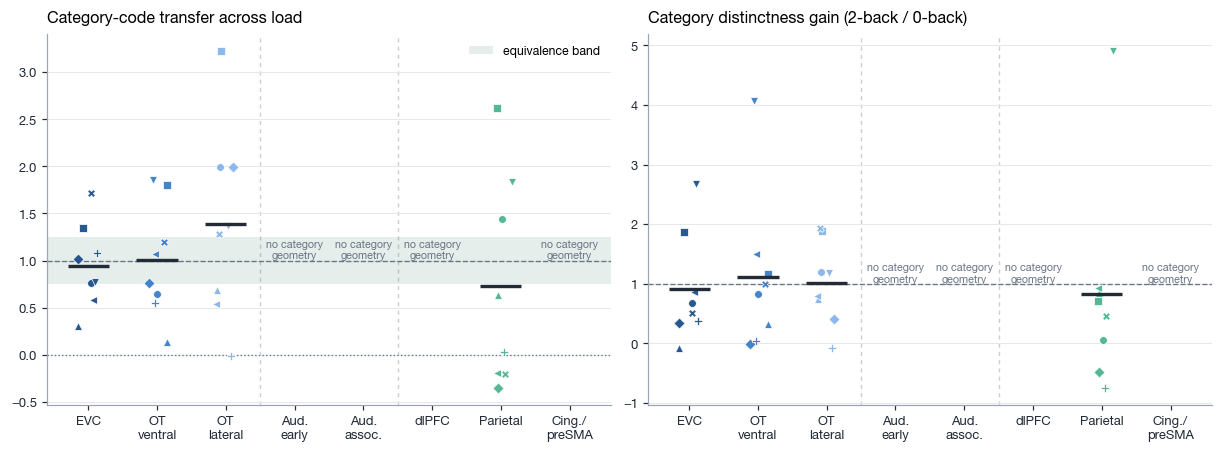

AUD_early: within-load category distinctness 0.028 (bootstrap CI [-0.049, 0.117] includes 0) -> no measurable category geometry, transfer ratio not computed
AUD_assoc: within-load category distinctness 0.027 (bootstrap CI [-0.120, 0.198] includes 0) -> no measurable category geometry, transfer ratio not computed
FP_dlpfc: within-load category distinctness 0.082 (bootstrap CI [-0.002, 0.157] includes 0) -> no measurable category geometry, transfer ratio not computed
Cing_preSMA: within-load category distinctness -0.010 (bootstrap CI [-0.082, 0.051] includes 0) -> no measurable category geometry, transfer ratio not computed
H1, full 8x8 model. transfer: 1 = same category code at both loads, 0 = none. gain: 2-back / 0-back category distinctness.
p_perm: re-pairing null (24 relabelings per subject, group mean). tost_p: equivalence to full invariance within +/-0.25.
        roi  n_subjects  group_within_distinctness  within_ci_lo  interpretable  transfer_mean  ci_lo  ci_hi  p_perm_transfer_

In [25]:
# =============================================================================
# STAGE 9 - H1 AS A FULL 8x8 MODEL: transfer, gain, and an equivalence test
# =============================================================================
# The original form of H1 was a Spearman correlation between the 0-back and 2-back category RDMs over six pairs.
# Six numbers is far too few: the statistic jumps between a handful of values and is dominated by a single
# misordered pair, and the resting-state null showed it could not separate signal from noise.
#
# This version uses all 8x8 cross-validated distances, including the cross-load block that the 6-pair version throws
# away, and separates two things the correlation confounds:
#   transfer  is it the SAME category code at both loads? (1 = identical geometry, 0 = unrelated)
#   gain      is the code STRONGER or WEAKER under load? (2-back distinctness divided by 0-back distinctness)
# A code can be perfectly shared and much weaker; the correlation cannot tell those apart, these two numbers can.
#
# Two safeguards:
#   Interpretability gate - the transfer ratio divides by within-load category distinctness. Where that denominator
#     is not reliably above zero there is no category geometry to preserve, so no ratio is computed and the ROI is
#     reported as "no measurable category geometry" rather than given a meaningless number.
#   Pooled normalisation - each subject's numerator is divided by the GROUP-mean denominator rather than their own,
#     so a subject who happens to have near-zero distinctness cannot blow the group ratio up.
# Inference: (a) a re-pairing permutation null for transfer > 0 (shuffle which 2-back category is matched to which
# 0-back category, 24 relabelings per subject), and (b) a TOST for "transfer is within +/- EQUIV_MARGIN_TRANSFER of 1".
rng = np.random.default_rng(NOVELTY_SEED)
h1_full_rows, h1_rdm_store = [], {}
_no_geometry = []        # regions that fail the interpretability gate, reported with the tables below the figure
for sid in SUBJECTS:
    P = get_patterns(sid)
    for roi, mask in roi_masks.items():
        A, B = nonflat(P["WM_LR_t"][:, mask].astype(float), P["WM_RL_t"][:, mask].astype(float))
        if A.shape[1] == 0:
            continue
        D = crossnobis_rdm(A, B)
        h1_rdm_store[(sid, roi)] = D
        h1_full_rows.append(dict(subject=sid, roi=roi, n_features=A.shape[1], **h1_stats_from_rdm(D)))
h1_full = pd.DataFrame(h1_full_rows)

# Pooled normalisation: every subject's numerator is divided by the GROUP-mean within-load distinctness of that ROI, so a subject
# with near-zero distinctness cannot blow the ratio up. The mean of these values equals mean(numerator) / mean(denominator).
h1_full["transfer_pooled"] = np.nan
h1_full["gain_pooled"] = np.nan
summary_rows = []
for roi in roi_masks:
    idx = h1_full.roi == roi
    sub = h1_full[idx]
    Ds = [h1_rdm_store[(s, roi)] for s in sub.subject]
    den = sub.within.mean()
    w_lo, w_hi = bootstrap_ci(sub.within.values)
    row = dict(roi=roi, n_subjects=len(sub), group_within_distinctness=den, within_ci_lo=w_lo, interpretable=bool(w_lo > 0))
    if not row["interpretable"]:
        # The ratio divides by the category distinctness inside each load; if that is indistinguishable from 0 the ratio is meaningless.
        _no_geometry.append(
            f"{roi}: within-load category distinctness {den:.3f} (bootstrap CI [{w_lo:.3f}, {w_hi:.3f}] includes 0) -> "
            "no measurable category geometry, transfer ratio not computed")
        summary_rows.append(row)
        continue
    h1_full.loc[idx, "transfer_pooled"] = sub.transfer_num.values / den
    h1_full.loc[idx, "gain_pooled"] = sub.within2.values / sub.within0.mean()
    tp = h1_full.loc[idx, "transfer_pooled"].values
    obs = tp.mean()
    null = np.empty(N_PERM_GROUP)
    for k in range(N_PERM_GROUP):
        null[k] = np.mean([transfer_num(D, ALL_PERMS[rng.integers(24)]) for D in Ds]) / den
    p_perm = (1 + np.sum(null >= obs)) / (N_PERM_GROUP + 1)
    lo, hi = bootstrap_ci(tp)
    eq = tost_one_sample(tp - 1.0, EQUIV_MARGIN_TRANSFER)
    row.update(transfer_mean=obs, ci_lo=lo, ci_hi=hi, p_perm_transfer_gt0=p_perm,
               gain_mean=sub.within2.mean() / sub.within0.mean() if sub.within0.mean() > 0 else np.nan,
               rho_mean=np.nanmean(sub.rho), tost_p_loss_within_margin=eq["p_tost"], equivalent_to_invariance=eq["equivalent"])
    summary_rows.append(row)
h1_full_summary = pd.DataFrame(summary_rows)
for col in ("transfer_mean", "ci_lo", "ci_hi", "p_perm_transfer_gt0", "gain_mean", "rho_mean", "tost_p_loss_within_margin"):
    if col not in h1_full_summary:
        h1_full_summary[col] = np.nan
if "equivalent_to_invariance" not in h1_full_summary:
    h1_full_summary["equivalent_to_invariance"] = np.nan
ok = h1_full_summary.interpretable.values.astype(bool)
h1_full_summary["q_perm"] = np.nan
if ok.any():
    h1_full_summary.loc[ok, "q_perm"] = bh_fdr(h1_full_summary.loc[ok, "p_perm_transfer_gt0"].values)   # FDR over interpretable ROIs only
note("\n".join(_no_geometry) if _no_geometry else "Every region passed the interpretability gate.")
note("H1, full 8x8 model. transfer: 1 = same category code at both loads, 0 = none. gain: 2-back / 0-back category distinctness.")
note("p_perm: re-pairing null (24 relabelings per subject, group mean). tost_p: equivalence to full invariance within +/-%.2f." % EQUIV_MARGIN_TRANSFER)
note(h1_full_summary.round(3).to_string(index=False))
note("\ninterpretable = False: the ROI has no measurable category distinctness inside a load, so a ratio against it has no meaning.")
note("Note: with few subjects a TOST can only succeed if between-subject spread is small; a failed TOST means 'unresolved', not 'invariance is false'.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, col, title, ref in ((axes[0], "transfer_pooled", "Category-code transfer across load", 1.0),
                            (axes[1], "gain_pooled", "Category distinctness gain (2-back / 0-back)", 1.0)):
    group_dividers(ax, "x")
    for i, roi in enumerate(ROI_ORDER):
        v = h1_full[h1_full.roi == roi][col].values
        if not np.isfinite(v).any():
            ax.text(i, ref, "no category\ngeometry", ha="center", va="bottom", fontsize=7, color=MUTED)
            continue
        strip(ax, i, v, ROI_COLORS[roi], seed=i, subjects=list(h1_full[h1_full.roi == roi].subject))
    ax.axhline(ref, color=MUTED, ls="--", lw=.9)
    if col == "transfer_pooled":
        ax.axhspan(ref - EQUIV_MARGIN_TRANSFER, ref + EQUIV_MARGIN_TRANSFER, color="#2C7A5B", alpha=.12, lw=0, label="equivalence band")
        ax.axhline(0, color=MUTED, ls=":", lw=.9); ax.legend(loc="upper right")
    roi_ticks(ax, "x"); ax.set_title(title)
save_fig(fig, "h1_transfer_gain.png")
h1_full.to_csv(os.path.join(NOVELTY_DIR, "h1_full_subject_level.csv"), index=False)
h1_full_summary.to_csv(os.path.join(NOVELTY_DIR, "h1_full_group_summary.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


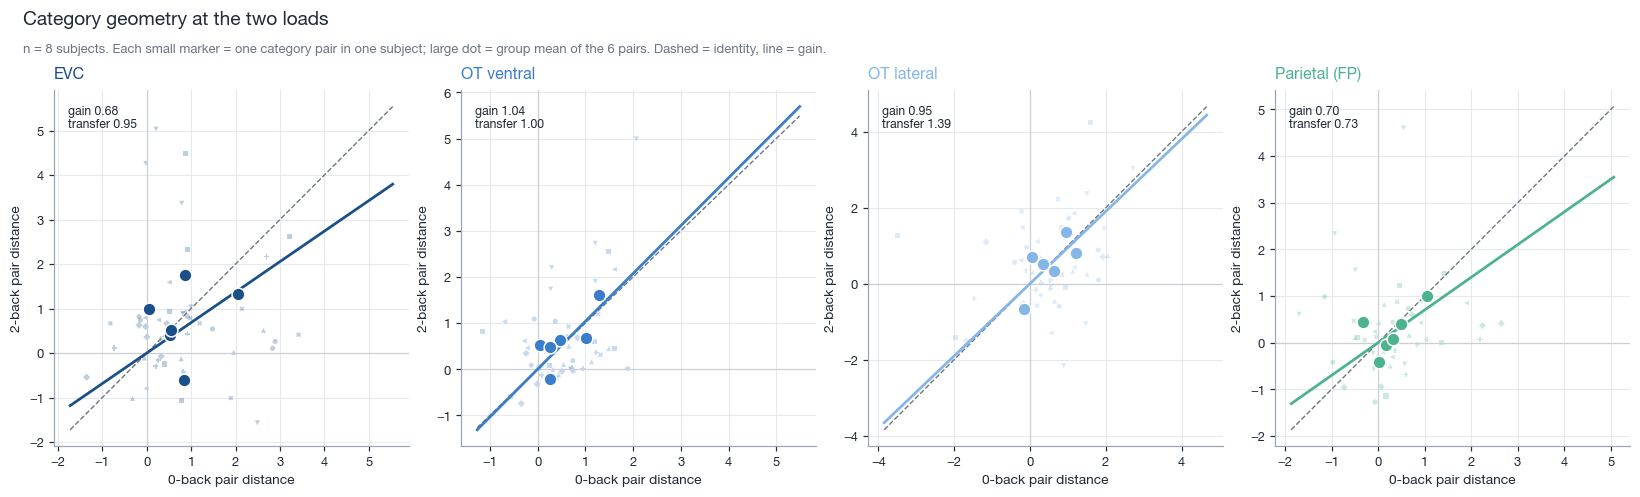

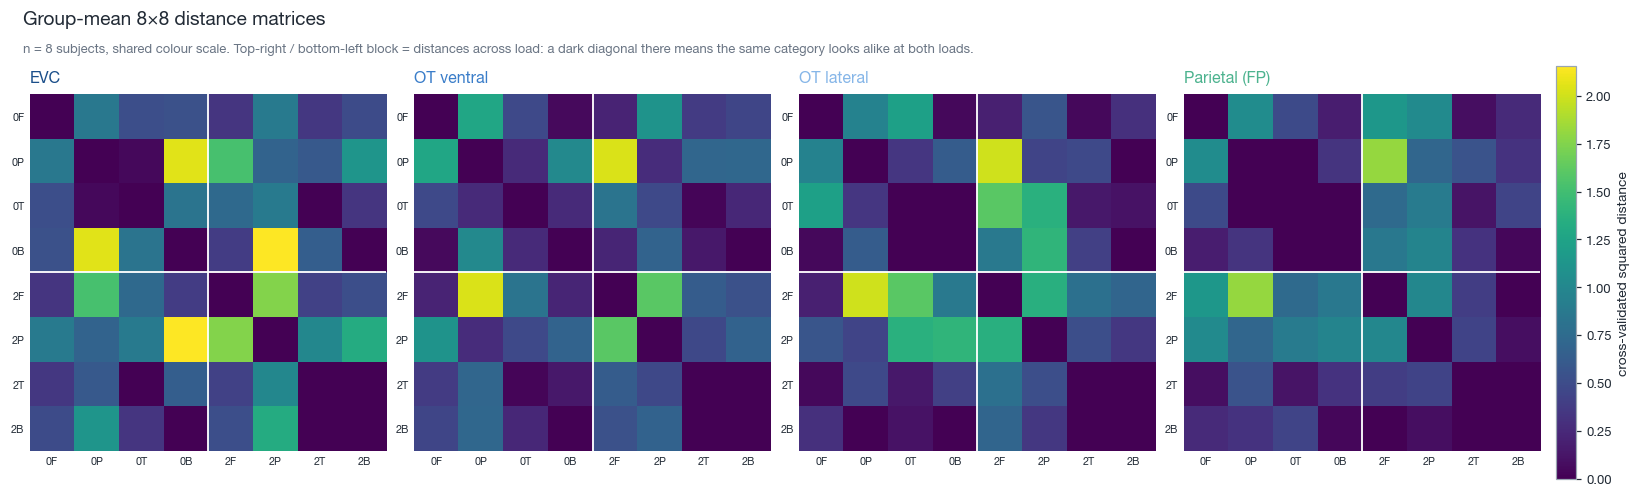

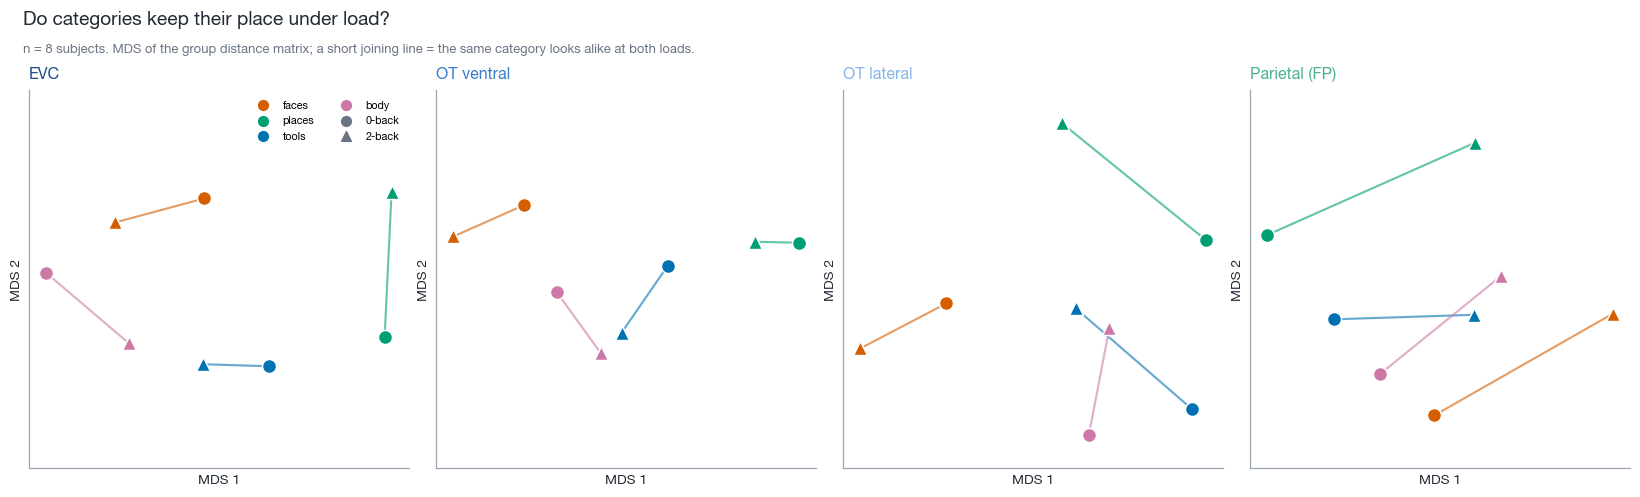

In [26]:
# =============================================================================
# STAGE 9a - WHAT THE TRANSFER RATIO ACTUALLY SUMMARISES (three figures)
# =============================================================================
# A ratio is easy to misread, so these three figures show the geometry it comes from.
#   1  The six category-pair distances at 0-back plotted against the same six at 2-back. If the code is shared and
#      equally strong the points sit on the identity line; a shared but weaker code puts them on a line with a
#      shallower slope (that slope IS the gain); an unrelated code scatters them.
#   2  The group-mean 8x8 distance matrices on a shared colour scale. The cross-load blocks are the ones to look at:
#      a dark diagonal there means the same category looks alike at both loads.
#   3  Classical multidimensional scaling of the group matrix, with colour for category and marker for load. A short
#      line joining the two markers of a category means that category keeps its place when load changes.
# Only ROIs that passed the interpretability gate are drawn, because the others have no geometry to show.
# Needs h1_rdm_store and h1_full_summary (Stage 9).
pair_idx = np.triu_indices(4, 1)
summ = h1_full_summary.set_index("roi")
GEO_ROIS = [r for r in ROI_ORDER if r in summ.index and bool(summ.loc[r, "interpretable"])]
group_D = {roi: np.mean([h1_rdm_store[(sid, roi)] for sid in SUBJECTS if (sid, roi) in h1_rdm_store], axis=0) for roi in GEO_ROIS}
nG = max(1, len(GEO_ROIS))

# ---- 1. The six category-pair distances at 0-back (x) against 2-back (y) ----
fig, axes = plt.subplots(1, nG, figsize=(3.7 * nG, 3.9), constrained_layout=True)
for ax, roi in zip(np.atleast_1d(axes), GEO_ROIS):
    per = np.array([[h1_rdm_store[(sid, roi)][:4, :4][pair_idx], h1_rdm_store[(sid, roi)][4:, 4:][pair_idx]]
                    for sid in SUBJECTS if (sid, roi) in h1_rdm_store])          # (subjects, 2, 6)
    for s_i in range(per.shape[0]):
        ax.scatter(per[s_i, 0], per[s_i, 1], s=11, color=ROI_COLORS[roi], alpha=.28, marker=SUBJ_MARKERS[SUBJECTS[s_i]], edgecolor="none")
    gm = per.mean(axis=0)
    ax.scatter(gm[0], gm[1], s=70, color=ROI_COLORS[roi], edgecolor="white", lw=1, zorder=3)
    lim = [min(per.min(), 0) * 1.1, per.max() * 1.1]
    ax.plot(lim, lim, color=MUTED, ls="--", lw=.9); ax.axhline(0, color="#C9CFD6", lw=.8); ax.axvline(0, color="#C9CFD6", lw=.8)
    slope = float((gm[0] @ gm[1]) / (gm[0] @ gm[0])) if (gm[0] @ gm[0]) > 0 else np.nan
    if np.isfinite(slope):
        xs = np.array(lim); ax.plot(xs, slope * xs, color=ROI_COLORS[roi], lw=1.8)
    ax.text(.04, .96, f"gain {slope:.2f}\ntransfer {summ.loc[roi, 'transfer_mean']:.2f}", transform=ax.transAxes, va="top", fontsize=8, color=INK)
    ax.set_title(ROI_NAME[roi], color=ROI_COLORS[roi]); ax.set_xlabel("0-back pair distance"); ax.set_ylabel("2-back pair distance")
    ax.grid(True, axis="both")
fig_title(fig, "Category geometry at the two loads", f"n = {len(SUBJECTS)} subjects. Each small marker = one category pair in one subject; large dot = group mean of the 6 pairs. "
          "Dashed = identity, line = gain.", y=1.12)
save_fig(fig, "h1_pair_distances_0_vs_2back.png")

# ---- 2. Group RDMs on one shared colour scale ----
vmax = max(np.abs(D).max() for D in group_D.values())
fig, axes = plt.subplots(1, nG, figsize=(3.7 * nG, 3.9), constrained_layout=True)
for ax, roi in zip(np.atleast_1d(axes), GEO_ROIS):
    ax.grid(False)
    im = ax.imshow(group_D[roi], cmap="viridis", vmin=0, vmax=vmax)
    ax.axhline(3.5, color="white", lw=1.2); ax.axvline(3.5, color="white", lw=1.2)
    ax.set_xticks(range(8)); ax.set_xticklabels(SHORT_CONDS, fontsize=7); ax.set_yticks(range(8)); ax.set_yticklabels(SHORT_CONDS, fontsize=7)
    ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
    ax.set_title(ROI_NAME[roi], color=ROI_COLORS[roi])
fig.colorbar(im, ax=np.atleast_1d(axes), fraction=0.02, pad=0.01, label="cross-validated squared distance")
fig_title(fig, "Group-mean 8×8 distance matrices", f"n = {len(SUBJECTS)} subjects, shared colour scale. Top-right / bottom-left block = distances across load: "
          "a dark diagonal there means the same category looks alike at both loads.", y=1.12)
save_fig(fig, "h1_group_rdms.png")


# ---- 3. MDS of the group RDM: category = colour, load = marker, line joins the same category across load ----
def classical_mds(D, k=2):
    n = D.shape[0]; J = np.eye(n) - np.ones((n, n)) / n
    w, V = np.linalg.eigh(-0.5 * J @ D @ J)
    top = np.argsort(w)[::-1][:k]
    return V[:, top] * np.sqrt(np.maximum(w[top], 0))


fig, axes = plt.subplots(1, nG, figsize=(3.7 * nG, 3.9), constrained_layout=True)
for ax, roi in zip(np.atleast_1d(axes), GEO_ROIS):
    X = classical_mds(group_D[roi])
    for c, name in enumerate(CATS):
        ax.plot([X[c, 0], X[4 + c, 0]], [X[c, 1], X[4 + c, 1]], color=CAT_COLORS[name], lw=1.4, alpha=.6)
        ax.scatter(*X[c], s=85, marker="o", color=CAT_COLORS[name], edgecolor="white", lw=1, zorder=3)
        ax.scatter(*X[4 + c], s=85, marker="^", color=CAT_COLORS[name], edgecolor="white", lw=1, zorder=3)
    ax.set_title(ROI_NAME[roi], color=ROI_COLORS[roi]); ax.set_xlabel("MDS 1"); ax.set_ylabel("MDS 2"); ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([]); ax.set_yticks([])
a0 = np.atleast_1d(axes)[0]
for name in CATS:
    a0.scatter([], [], color=CAT_COLORS[name], label=name, s=40)
a0.scatter([], [], color=MUTED, marker="o", label="0-back", s=40); a0.scatter([], [], color=MUTED, marker="^", label="2-back", s=40)
a0.legend(fontsize=7, ncol=2, loc="best")
fig_title(fig, "Do categories keep their place under load?", f"n = {len(SUBJECTS)} subjects. MDS of the group distance matrix; a short joining line = the same category looks alike at both loads.", y=1.12)
save_fig(fig, "h1_mds.png")


In [27]:
# =============================================================================
# STAGE 9b - WHY DID RIDGE AND SVM DISAGREE?
# =============================================================================
# The SVM cross-check produced story-vs-math accuracies far from the ridge results in some ROIs (0.30 against 1.00 in
# one case). A disagreement that large has to be explained before either number is quoted, so this cell runs both
# decoders on IDENTICAL data and then changes the SVM one setting at a time - rescaling, the intercept, and the
# regularisation strength - to find which one is responsible.
#
# How to read the table: if the stripped-down SVM variants agree with ridge but the original pipeline does not, the
# cause is in that pipeline (most often re-scaling features that were already scaled, or a regularised intercept).
# If ALL variants disagree, the problem is in the data or the sample ordering, not in the classifier.
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeClassifier


def svm_variant(X, y, subj, train_sel, test_sel, scaler=True, intercept=True, C=1.0):
    steps = ([StandardScaler()] if scaler else []) + [LinearSVC(C=C, fit_intercept=intercept, dual=True, max_iter=50000, random_state=0)]
    out = []
    for s in np.unique(subj):
        tr, te = (subj != s) & train_sel, (subj == s) & test_sel
        m = make_pipeline(*steps).fit(X[tr], y[tr])
        out.append(np.mean(m.predict(X[te]) == y[te]))
    return np.array(out)


def ridge_sklearn(X, y, subj, train_sel, test_sel):
    out = []
    for s in np.unique(subj):
        tr, te = (subj != s) & train_sel, (subj == s) & test_sel
        K = X[tr] @ X[tr].T
        m = RidgeClassifier(alpha=float(LAM_REL * np.trace(K) / tr.sum())).fit(X[tr], y[tr])
        out.append(np.mean(m.predict(X[te]) == y[te]))
    return np.array(out)


VARIANTS = {
    "ridge (this notebook)": None,
    "ridge (sklearn)": "sk",
    "SVM as in Stage 8": dict(scaler=True, intercept=True, C=1.0),
    "SVM no rescale": dict(scaler=False, intercept=True, C=1.0),
    "SVM no intercept": dict(scaler=False, intercept=False, C=1.0),
    "SVM C=1e-4": dict(scaler=False, intercept=True, C=1e-4),
}
cmp_rows = []
for roi in roi_masks:
    wm, lg = build_dataset(roi, "WM"), build_dataset(roi, "LANGUAGE")
    L = wm["load"]
    jobs = {
        "0-back category": (wm["X_main"], wm["y"], wm["subj"], L == 0, L == 0),
        "load": (wm["X_load"], L, wm["subj"], np.ones(len(L), bool), np.ones(len(L), bool)),
        "story vs math": (lg["X_main"], lg["y"], lg["subj"], np.ones(len(lg["y"]), bool), np.ones(len(lg["y"]), bool)),
    }
    for an, (X, y, s, tr, te) in jobs.items():
        for name, cfg in VARIANTS.items():
            if cfg is None:
                acc = LosoModel(X @ X.T, s, tr, te).accuracy(y)
            elif cfg == "sk":
                acc = ridge_sklearn(X, y, s, tr, te)
            else:
                acc = svm_variant(X, y, s, tr, te, **cfg)
            cmp_rows.append(dict(roi=roi, analysis=an, method=name, mean_acc=acc.mean(), min_subject=acc.min(), max_subject=acc.max()))
cmp = pd.DataFrame(cmp_rows)
table = cmp.pivot_table(index=["analysis", "roi"], columns="method", values="mean_acc")[list(VARIANTS)]
table["max |SVM - ridge|"] = (table.drop(columns=["ridge (this notebook)", "ridge (sklearn)"]).sub(table["ridge (this notebook)"], axis=0)).abs().max(axis=1)
print("Mean leave-one-subject-out accuracy by decoder variant (same data in every column)")
print(table.round(2).to_string())
bad = table[table["max |SVM - ridge|"] > 0.15]
print("\nROI x analysis where an SVM variant differs from ridge by > 0.15: %d of %d" % (len(bad), len(table)))
print("Read it as: if 'SVM no rescale' / 'no intercept' / 'C=1e-4' agree with ridge but 'SVM as in Stage 8' does not, the Stage 8 pipeline"
      " (re-scaling already-scaled features, or the regularised intercept) is the cause. If ALL variants differ, check labels and sample order.")
table.to_csv(os.path.join(NOVELTY_DIR, "decoder_reconciliation.csv"))


Mean leave-one-subject-out accuracy by decoder variant (same data in every column)
method                       ridge (this notebook)  ridge (sklearn)  SVM as in Stage 8  SVM no rescale  SVM no intercept  SVM C=1e-4  max |SVM - ridge|
analysis        roi                                                                                                                                    
0-back category AUD_assoc                     0.25             0.25               0.28            0.30              0.30        0.23               0.05
                AUD_early                     0.25             0.25               0.28            0.27              0.25        0.20               0.05
                Cing_preSMA                   0.38             0.38               0.36            0.38              0.36        0.39               0.02
                EVC                           0.81             0.81               0.83            0.83              0.83        0.81               0.02
     

In [28]:
# =============================================================================
# STAGE 9c - IS THE CATEGORY CODE LOAD-INVARIANT? (equivalence test on decoding)
# =============================================================================
# The decoding counterpart of the geometry analysis above. loss = within-load accuracy minus cross-load accuracy,
# per subject. Two different questions are then asked of the same numbers:
#   sign-flip test  is any loss detectable at all?            (a significant result means the code DID change)
#   TOST            is the loss small enough to be negligible? (a significant result means the code is load-invariant)
# Both can fail, and that is the honest third outcome: "unresolved", printed as such in the verdict column. With
# eight subjects the tests are weak, so the size of the loss and its interval matter more than the stars.
# Uses subj_acc from Stage 5b and the margin fixed in Stage 6.
rows = []
for r in roi_masks:
    loss = within(r) - across(r)
    eq = tost_one_sample(loss, EQUIV_MARGIN_ACC)
    lo, hi = bootstrap_ci(loss)
    rows.append(dict(roi=r, mean_loss=loss.mean(), boot_ci_lo=lo, boot_ci_hi=hi, ci90_lo=eq["ci90_lo"], ci90_hi=eq["ci90_hi"],
                     p_loss_detectable=signflip_mean_p(loss), p_tost=eq["p_tost"], equivalent=eq["equivalent"]))
dec_equiv = pd.DataFrame(rows)
dec_equiv["verdict"] = np.where(dec_equiv.equivalent, "no meaningful loss (equivalent)",
                         np.where(dec_equiv.ci90_lo > 0, "loss across load", "unresolved"))
print("Category decoding, within-load minus cross-load accuracy; equivalence margin +/-%.2f" % EQUIV_MARGIN_ACC)
print(dec_equiv.round(3).to_string(index=False))
# (the equivalence plot now lives in the load-robustness cell that follows)
dec_equiv.to_csv(os.path.join(NOVELTY_DIR, "decoding_load_invariance_tost.csv"), index=False)


Category decoding, within-load minus cross-load accuracy; equivalence margin +/-0.10
        roi  mean_loss  boot_ci_lo  boot_ci_hi  ci90_lo  ci90_hi  p_loss_detectable  p_tost  equivalent                         verdict
        EVC      0.156       0.094       0.227    0.089    0.223              0.008   0.922       False                loss across load
 OT_ventral      0.086       0.062       0.133    0.042    0.130              0.008   0.284       False                loss across load
 OT_lateral      0.109       0.016       0.203    0.010    0.209              0.098   0.568       False                loss across load
  AUD_early      0.055      -0.031       0.141   -0.036    0.145              0.366   0.188       False                      unresolved
  AUD_assoc      0.062      -0.016       0.148   -0.024    0.149              0.295   0.220       False                      unresolved
   FP_dlpfc      0.141       0.008       0.266    0.005    0.276              0.117   0.706       F

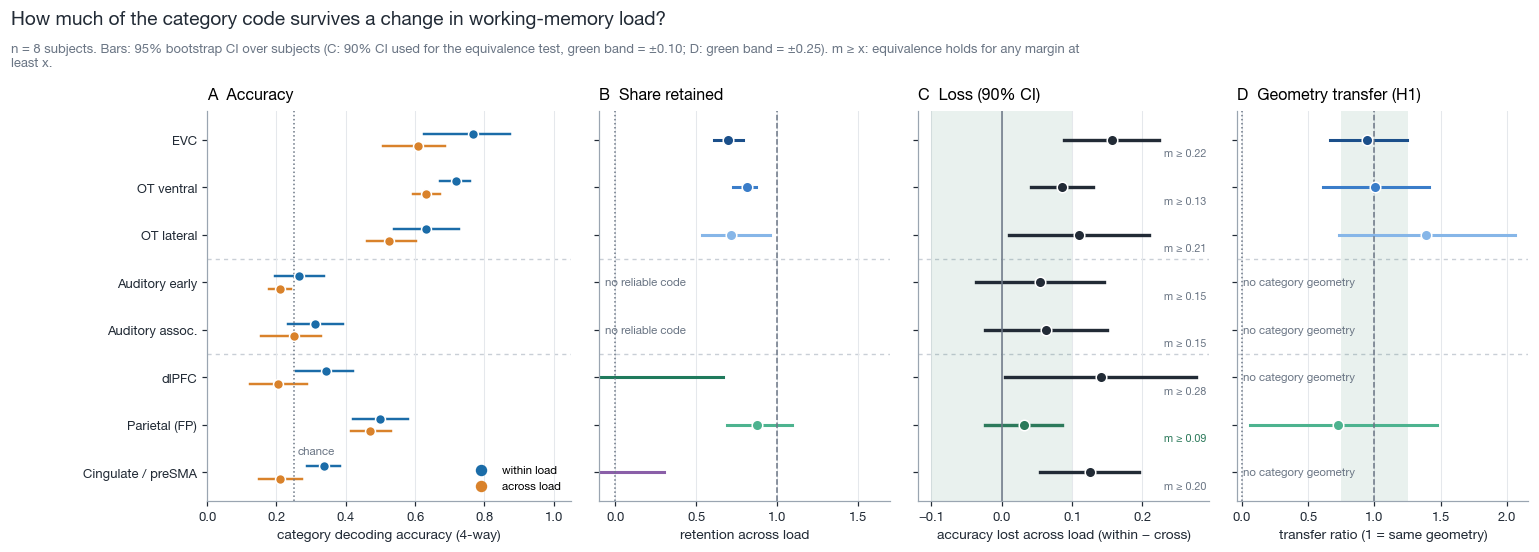

Category code across load. retention = share of the above-chance accuracy that survives the 0-back <-> 2-back change.
m_min = smallest equivalence margin (accuracy units) for which the loss would count as negligible; compare with the margin you consider small.
        roi  within_acc  cross_acc  within_code_reliable  retention  retention_ci_lo  retention_ci_hi  loss  m_min  p_tost
        EVC       0.766      0.609                  True      0.697            0.609            0.788 0.156  0.223   0.922
 OT_ventral       0.719      0.633                  True      0.817            0.726            0.871 0.086  0.130   0.284
 OT_lateral       0.633      0.523                  True      0.714            0.534            0.957 0.109  0.209   0.568
  AUD_early       0.266      0.211                 False     -2.500              NaN              NaN 0.055  0.145   0.188
  AUD_assoc       0.312      0.250                 False      0.000              NaN              NaN 0.062  0.149   0.220
 

In [29]:
# =============================================================================
# STAGE 9d - HOW MUCH OF THE CATEGORY CODE SURVIVES A CHANGE IN LOAD?
# =============================================================================
# One figure that brings together everything about load invariance, per ROI, with the subject as the unit:
#   A  category accuracy inside a load against accuracy across loads (train on one load, test on the other)
#   B  retention = (cross-load accuracy - chance) / (within-load accuracy - chance). 1 means the whole code
#      transfers, 0 means none of it does. Shown only where the within-load code is reliably above chance, because
#      a region with no code has nothing to retain and the ratio would be noise divided by noise.
#   C  the accuracy lost across load with the 90% interval used by the equivalence test, plus m_min - the smallest
#      margin at which "no meaningful loss" would be accepted. Quoting m_min means the conclusion does not depend on
#      the margin we happened to fix in advance; the reader can apply their own.
#   D  the geometry transfer ratio from Stage 9, which answers the same question from the RSA side.
# A and B measure a decoder's ability to generalise; C is the formal test; D is the representational geometry.
# Agreement between them is what makes the claim credible, which is why they are shown side by side.
N_BOOT_RET = 5000
CHANCE_CAT = 0.25
rng_ret = np.random.default_rng(NOVELTY_SEED)


def retention_ci(w_ex, c_ex, n_boot=N_BOOT_RET):
    n = len(w_ex)
    idx = rng_ret.integers(0, n, size=(n_boot, n))
    den = w_ex[idx].mean(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.where(den > 0, c_ex[idx].mean(axis=1) / den, np.nan)
    return np.nanpercentile(r, [2.5, 97.5])


ret_rows = []
for roi in ROI_ORDER:
    w, c = within(roi), across(roi)
    w_ex, c_ex = w - CHANCE_CAT, c - CHANCE_CAT
    w_lo, w_hi = bootstrap_ci(w)
    c_lo, c_hi = bootstrap_ci(c)
    informative = bool(bootstrap_ci(w_ex)[0] > 0)
    ret = c_ex.mean() / w_ex.mean() if w_ex.mean() > 0 else np.nan
    r_lo, r_hi = retention_ci(w_ex, c_ex) if informative else (np.nan, np.nan)
    e = dec_equiv[dec_equiv.roi == roi].iloc[0]
    ret_rows.append(dict(roi=roi, within_acc=w.mean(), within_ci_lo=w_lo, within_ci_hi=w_hi, cross_acc=c.mean(), cross_ci_lo=c_lo,
                         cross_ci_hi=c_hi, within_code_reliable=informative, retention=ret, retention_ci_lo=r_lo, retention_ci_hi=r_hi,
                         loss=e.mean_loss, loss_ci90_lo=e.ci90_lo, loss_ci90_hi=e.ci90_hi, p_tost=e.p_tost,
                         m_min=max(abs(e.ci90_lo), abs(e.ci90_hi)), n_subjects=len(w)))
retention_df = pd.DataFrame(ret_rows)
note("Category code across load. retention = share of the above-chance accuracy that survives the 0-back <-> 2-back change.")
note("m_min = smallest equivalence margin (accuracy units) for which the loss would count as negligible; compare with the margin you consider small.")
note(retention_df[["roi", "within_acc", "cross_acc", "within_code_reliable", "retention", "retention_ci_lo", "retention_ci_hi",
                    "loss", "m_min", "p_tost"]].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.6), sharey=True, gridspec_kw=dict(width_ratios=[1.25, 1, 1, 1], wspace=0.09))
yy = np.arange(len(ROI_ORDER))
for ax in axes:
    ax.grid(False, axis="y"); ax.grid(True, axis="x"); ax.set_ylim(len(ROI_ORDER) - .4, -.6)
    group_dividers(ax, "y")
# A: within vs cross accuracy
ax = axes[0]
for i, r in retention_df.iterrows():
    ax.plot([r.within_ci_lo, r.within_ci_hi], [i - .13] * 2, color=C_PATTERN, lw=1.6)
    ax.plot([r.cross_ci_lo, r.cross_ci_hi], [i + .13] * 2, color=C_MEAN, lw=1.6)
    ax.scatter(r.within_acc, i - .13, s=42, color=C_PATTERN, edgecolor="white", zorder=3)
    ax.scatter(r.cross_acc, i + .13, s=42, color=C_MEAN, edgecolor="white", zorder=3)
ax.axvline(CHANCE_CAT, color=MUTED, ls=":", lw=1); ax.text(CHANCE_CAT + .01, 6.55, "chance", color=MUTED, fontsize=7.5, ha="left", va="center")
ax.set_yticks(yy); ax.set_yticklabels([ROI_NAME[r] for r in ROI_ORDER]); ax.set_xlim(0, 1.05)
ax.set_xlabel("category decoding accuracy (4-way)")
ax.scatter([], [], s=42, color=C_PATTERN, label="within load"); ax.scatter([], [], s=42, color=C_MEAN, label="across load")
ax.legend(loc="lower right", fontsize=7.5); ax.set_title("A  Accuracy")
# B: retention
ax = axes[1]
for i, r in retention_df.iterrows():
    if r.within_code_reliable and np.isfinite(r.retention):
        ax.plot([r.retention_ci_lo, r.retention_ci_hi], [i, i], color=ROI_COLORS[r.roi], lw=2)
        ax.scatter(r.retention, i, s=48, color=ROI_COLORS[r.roi], edgecolor="white", zorder=3)
    else:
        ax.text(0.02, i, "no reliable code", color=MUTED, fontsize=7.5, va="center", transform=ax.get_yaxis_transform())
ax.axvline(1, color=MUTED, ls="--", lw=1); ax.axvline(0, color=MUTED, ls=":", lw=1)
ax.set_xlim(-.1, 1.7); ax.set_xlabel("retention across load"); ax.set_title("B  Share retained")
# C: loss and equivalence
ax = axes[2]
ax.axvspan(-EQUIV_MARGIN_ACC, EQUIV_MARGIN_ACC, color="#2C7A5B", alpha=.10, lw=0)
for i, r in retention_df.iterrows():
    eq = bool(r.p_tost < .05)
    ax.plot([r.loss_ci90_lo, r.loss_ci90_hi], [i, i], color="#2C7A5B" if eq else INK, lw=2.2)
    ax.scatter(r.loss, i, s=48, color="#2C7A5B" if eq else INK, edgecolor="white", zorder=3)
    ax.text(.99, i + .28, f"m ≥ {r.m_min:.2f}", transform=ax.get_yaxis_transform(), fontsize=7, va="center", ha="right",
            color="#2C7A5B" if eq else MUTED, fontweight="bold" if eq else "normal")
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("accuracy lost across load (within − cross)"); ax.set_title("C  Loss (90% CI)")
# D: H1 geometry transfer
ax = axes[3]
ax.axvspan(1 - EQUIV_MARGIN_TRANSFER, 1 + EQUIV_MARGIN_TRANSFER, color="#2C7A5B", alpha=.10, lw=0)
hs = h1_full_summary.set_index("roi")
for i, roi in enumerate(ROI_ORDER):
    if roi in hs.index and bool(hs.loc[roi, "interpretable"]) and np.isfinite(hs.loc[roi, "transfer_mean"]):
        h = hs.loc[roi]
        ax.plot([h.ci_lo, h.ci_hi], [i, i], color=ROI_COLORS[roi], lw=2)
        ax.scatter(h.transfer_mean, i, s=48, color=ROI_COLORS[roi], edgecolor="white", zorder=3)
    else:
        ax.text(0.02, i, "no category geometry", color=MUTED, fontsize=7.5, va="center", transform=ax.get_yaxis_transform())
ax.axvline(1, color=MUTED, ls="--", lw=1); ax.axvline(0, color=MUTED, ls=":", lw=1)
ax.set_xlabel("transfer ratio (1 = same geometry)"); ax.set_title("D  Geometry transfer (H1)")
fig_title(fig, "How much of the category code survives a change in working-memory load?",
          f"n = {len(SUBJECTS)} subjects. Bars: 95% bootstrap CI over subjects (C: 90% CI used for the equivalence test, green band = ±{EQUIV_MARGIN_ACC:.2f}; "
          f"D: green band = ±{EQUIV_MARGIN_TRANSFER:.2f}). m ≥ x: equivalence holds for any margin at least x.", y=1.08)
save_fig(fig, "load_robustness_forest.png")
retention_df.to_csv(os.path.join(NOVELTY_DIR, "load_robustness_table.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


## Stage 10 — Cross-task decoding and the shared demand axis

Stages 4 to 9 asked what a region knows about *the stimulus*. This stage asks whether some regions instead encode
*how hard the task is* — a quantity that should be shared between two tasks that have nothing else in common.

The test is deliberately strict: a classifier trained to separate 2-back from 0-back in a **visual** memory task is
applied, unchanged, to **auditory** Story versus Math blocks, and in the reverse direction. The mapping
Math ↔ 2-back is fixed before the analysis, so an accuracy below 0.5 is informative too. Each result is then
repeated with the ROI mean removed and with the ROI mean alone, because transfer that works only through overall
activation is an amplitude effect and not a shared representation. The stage closes with the correlational version
of the same question: the WM load pattern correlated with the Math-minus-Story pattern *across different scanner
runs*, so that shared within-run noise cannot produce the effect.

In [30]:
# =============================================================================
# STAGE 10 - CROSS-TASK DECODING: does a WM-load decoder separate Math from Story?
# =============================================================================
# This is the test of a shared "demand" code: if a region represents how hard a task is rather than what the task is
# about, then a classifier trained to tell 2-back from 0-back in a visual memory task should also tell Math from
# Story in an auditory language task.
#   Direction A  train on WM load in the other subjects, test on the held-out subject's Language blocks
#   Direction B  train on Language in the other subjects, test on the held-out subject's WM blocks
# The mapping Math <-> 2-back (the more demanding condition of each pair) is fixed BEFORE the analysis, so an
# accuracy below 0.5 is interpretable too: it would mean the mapping is reversed.
#
# Inference, revised: the SUBJECT is the unit. The story-minus-math pattern is nearly identical in every subject, so
# the blocks inside a subject - and across subjects, where the schedule is shared - are not independent samples;
# flipping individual block labels gave p-values that were far too small. Instead each subject's accuracy is flipped
# as a whole (acc -> 1 - acc), which is an exact sign-flip test of (accuracy - 0.5) across subjects. The smallest
# attainable two-sided p is 2 / 2^n: 0.0625 at five subjects, 0.0078 at eight.
def _ridge_scores(Xtr, ytr, Xte, lam_rel=LAM_REL):
    K = Xtr @ Xtr.T
    lam = lam_rel * np.trace(K) / len(K)
    t = np.where(ytr == 1, 1.0, -1.0)
    alpha = np.linalg.solve(K + lam * np.eye(len(K)), t - t.mean())
    return (Xte @ Xtr.T) @ alpha


def _acc(scores, y):
    return float(np.mean((scores > 0) == (y == 1)))


def subject_flip_pvalues(acc, n_perm=N_PERM_GROUP, seed=NOVELTY_SEED):
    """Exact (n <= 14) or sampled sign-flip null over subjects: flip a subject's accuracy to 1 - accuracy."""
    acc = np.asarray(acc, float)
    n, obs = len(acc), acc.mean()
    if n <= 14:
        flips = np.array(list(itertools.product([0, 1], repeat=n)), bool)
        null = np.where(flips, 1 - acc, acc).mean(axis=1)
        p_one = np.mean(null >= obs - 1e-12)
        p_two = np.mean(np.abs(null - .5) >= abs(obs - .5) - 1e-12)
    else:
        flips = np.random.default_rng(seed).integers(0, 2, size=(n_perm, n)).astype(bool)
        null = np.where(flips, 1 - acc, acc).mean(axis=1)
        p_one = (1 + np.sum(null >= obs - 1e-12)) / (n_perm + 1)
        p_two = (1 + np.sum(np.abs(null - .5) >= abs(obs - .5) - 1e-12)) / (n_perm + 1)
    return float(p_one), float(p_two)


def cross_task_roi(roi):
    wm, lg = build_dataset(roi, "WM"), build_dataset(roi, "LANGUAGE")
    res = {}
    for direction in ("WM load -> Language (Math=2-back)", "Language -> WM load (Math=2-back)"):
        per_subject = []
        for s in np.unique(wm["subj"]):
            if direction.startswith("WM"):
                tr, te = wm["subj"] != s, lg["subj"] == s
                sc = _ridge_scores(wm["X_load"][tr], wm["load"][tr], lg["X_main"][te])
                per_subject.append(_acc(sc, lg["y"][te]))
            else:
                tr, te = lg["subj"] != s, wm["subj"] == s
                sc = _ridge_scores(lg["X_main"][tr], lg["y"][tr], wm["X_load"][te])
                per_subject.append(_acc(sc, wm["load"][te]))
        a = np.array(per_subject)
        p_one, p_two = subject_flip_pvalues(a)
        res[direction] = dict(acc=a.mean(), per_subject=a, n_subjects=len(a), p_one=p_one, p_two=p_two)
    return res


ct_rows = []
for roi in roi_masks:
    for direction, r in cross_task_roi(roi).items():
        lo, hi = bootstrap_ci(r["per_subject"] - .5)
        ct_rows.append(dict(roi=roi, direction=direction, mean_acc=r["acc"], ci_lo=.5 + lo, ci_hi=.5 + hi,
                            n_subjects_above_chance=int((r["per_subject"] > .5).sum()), n_subjects=r["n_subjects"],
                            min_possible_p=2.0 / 2 ** r["n_subjects"], p_one_sided=r["p_one"], p_two_sided=r["p_two"]))
cross_task = pd.DataFrame(ct_rows)
cross_task["q_fdr"] = bh_fdr(cross_task.p_two_sided.values)
print("Cross-task decoding (chance 0.50). p: exact subject-level sign-flip test; q: BH across ROIs x directions.")
print(cross_task.round(3).to_string(index=False))
print("\nHow to read it: above chance in FP_parietal / FP_dlpfc / Cing_preSMA but not in EVC or AUD_early supports a shared demand axis."
      " Below chance with a small p means the mapping is reversed (Math looks like 0-back)."
      "\nCheck n_subjects_above_chance as well: a mean driven by one or two subjects is not a group effect.")

# (the cross-task bar chart now lives in the pattern-versus-amplitude cell that follows)
cross_task.to_csv(os.path.join(NOVELTY_DIR, "cross_task_decoding.csv"), index=False)


Cross-task decoding (chance 0.50). p: exact subject-level sign-flip test; q: BH across ROIs x directions.
        roi                         direction  mean_acc  ci_lo  ci_hi  n_subjects_above_chance  n_subjects  min_possible_p  p_one_sided  p_two_sided  q_fdr
        EVC WM load -> Language (Math=2-back)     0.875  0.688  1.000                        6           8           0.008        0.016        0.031  0.056
        EVC Language -> WM load (Math=2-back)     0.578  0.508  0.648                        6           8           0.008        0.066        0.133  0.142
 OT_ventral WM load -> Language (Math=2-back)     0.750  0.500  1.000                        5           8           0.008        0.109        0.219  0.219
 OT_ventral Language -> WM load (Math=2-back)     0.672  0.625  0.727                        8           8           0.008        0.004        0.008  0.025
 OT_lateral WM load -> Language (Math=2-back)     0.812  0.562  1.000                        6           8        

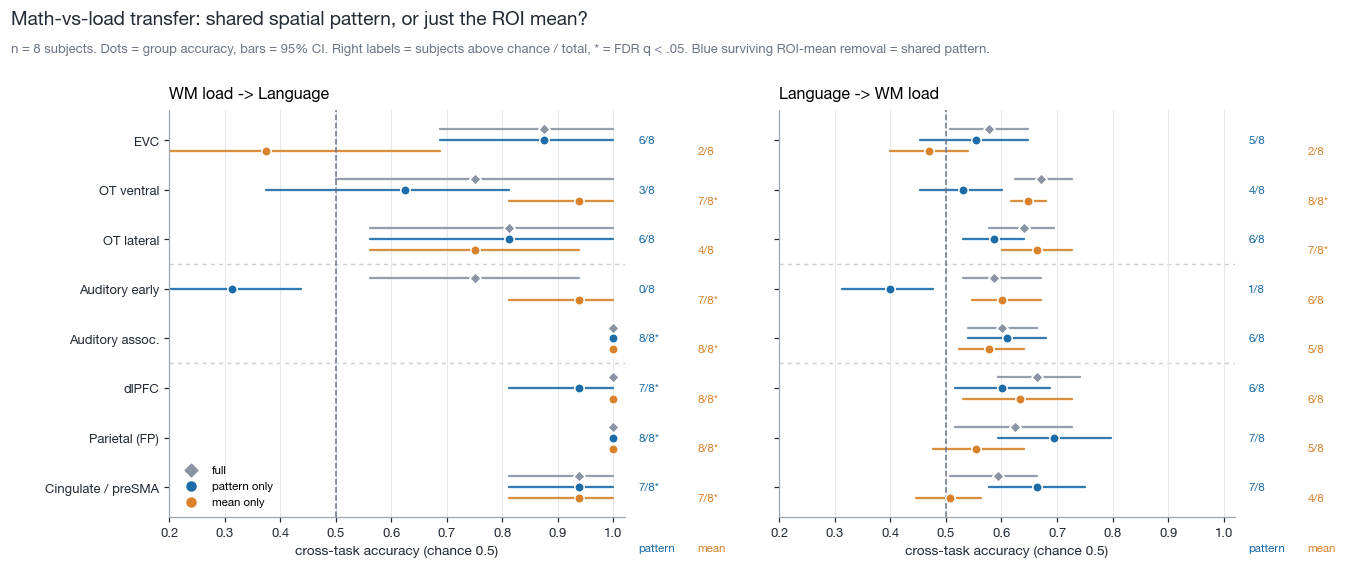

Cross-task decoding, three versions (chance 0.50). p = exact subject-level sign-flip (smallest possible p = 0.0078); q = BH over all rows.
        roi           direction      version  mean_acc  ci_lo  ci_hi  n_above_chance  n_subjects  p_two_sided  q_fdr
        EVC WM load -> Language         full     0.875  0.688  1.000               6           8        0.031  0.060
        EVC Language -> WM load         full     0.578  0.508  0.648               6           8        0.133  0.163
        EVC WM load -> Language pattern only     0.875  0.688  1.000               6           8        0.031  0.060
        EVC Language -> WM load pattern only     0.555  0.453  0.648               5           8        0.406  0.453
        EVC WM load -> Language    mean only     0.375  0.125  0.688               2           8        0.688  0.702
        EVC Language -> WM load    mean only     0.469  0.398  0.539               2           8        0.625  0.652
 OT_ventral WM load -> Language         fu

In [31]:
# =============================================================================
# STAGE 10a - IS THE MATH/LOAD LINK A SHARED PATTERN OR A SHARED ACTIVATION LEVEL?
# =============================================================================
# Transfer between two tasks is only evidence for a shared representation if it survives removal of the simplest
# alternative: both tasks making the region more active overall. Three versions of the same cross-task analysis,
# following the sufficiency / necessity logic of Coutanche (2013):
#   full          pattern and mean together (the original analysis)
#   pattern only  each sample's ROI mean is subtracted first, so only the spatial arrangement is left (sufficiency)
#   mean only     the classifier sees ONE number per sample, the ROI mean                              (necessity)
#
# The verdict rule is descriptive, not a test: a version "works" if accuracy is at least 0.60 AND at least 75% of
# subjects are above chance - the second condition matters because a group mean carried by two subjects is not a
# group effect. pattern works and mean does not -> a shared multivoxel code; mean works and pattern does not -> an
# amplitude shift; both -> redundant; neither -> no transfer.
# Needs the cross-task helpers from Stage 10, build_dataset (Stage 5) and the style cell.
VERSIONS = ("full", "pattern only", "mean only")
DIRECTIONS = ("WM load -> Language", "Language -> WM load")
WORKS_ACC, WORKS_FRAC = 0.60, 0.75


def _transform(X, version):
    if version == "full":
        return X
    mu = X.mean(axis=1, keepdims=True)                  # one value per sample: the ROI-mean activation
    return X - mu if version == "pattern only" else mu


def cross_task_versions(roi):
    wm, lg = build_dataset(roi, "WM"), build_dataset(roi, "LANGUAGE")
    out = {}
    for version in VERSIONS:
        Xw, Xl = _transform(wm["X_load"], version), _transform(lg["X_main"], version)
        for direction in DIRECTIONS:
            accs = []
            for s in np.unique(wm["subj"]):
                if direction.startswith("WM"):
                    tr, te = wm["subj"] != s, lg["subj"] == s
                    accs.append(_acc(_ridge_scores(Xw[tr], wm["load"][tr], Xl[te]), lg["y"][te]))
                else:
                    tr, te = lg["subj"] != s, wm["subj"] == s
                    accs.append(_acc(_ridge_scores(Xl[tr], lg["y"][tr], Xw[te]), wm["load"][te]))
            out[(version, direction)] = np.array(accs)
    return out


rows = []
for roi in roi_masks:
    for (version, direction), a in cross_task_versions(roi).items():
        p_one, p_two = subject_flip_pvalues(a)
        lo, hi = bootstrap_ci(a - .5)
        rows.append(dict(roi=roi, direction=direction, version=version, mean_acc=a.mean(), ci_lo=.5 + lo, ci_hi=.5 + hi,
                         n_above_chance=int((a > .5).sum()), n_subjects=len(a), p_two_sided=p_two))
xt_mean = pd.DataFrame(rows)
xt_mean["q_fdr"] = bh_fdr(xt_mean.p_two_sided.values)

verd = []
for (roi, direction), grp in xt_mean.groupby(["roi", "direction"], sort=False):
    grp = grp.set_index("version")
    full, pat, mea = grp.loc["full"], grp.loc["pattern only"], grp.loc["mean only"]
    works = lambda r: bool(r.mean_acc >= WORKS_ACC and r.n_above_chance >= int(np.ceil(WORKS_FRAC * r.n_subjects)))
    pw, mw = works(pat), works(mea)
    v = ("shared PATTERN + mean (redundant)" if pw and mw else "shared PATTERN" if pw else "AMPLITUDE shift only" if mw else "no transfer")
    verd.append(dict(roi=roi, direction=direction, full=full.mean_acc, pattern_only=pat.mean_acc, pattern_k_of_n=f"{pat.n_above_chance}/{pat.n_subjects}",
                     pattern_q=pat.q_fdr, mean_only=mea.mean_acc, mean_k_of_n=f"{mea.n_above_chance}/{mea.n_subjects}", mean_q=mea.q_fdr, verdict=v))
xt_verdict = pd.DataFrame(verd)

pd.set_option("display.width", 220)
note(f"Cross-task decoding, three versions (chance 0.50). p = exact subject-level sign-flip (smallest possible p = {2 / 2 ** len(SUBJECTS):.4f}); q = BH over all rows.")
note(xt_mean.round(3).to_string(index=False))
note("\nVerdict per ROI and direction (descriptive rule above):")
note(xt_verdict.round(3).to_string(index=False))
note("\nHow to read it: the 'pattern only' rows answer the question. A pattern that survives mean removal is a shared multivoxel code;"
      " a ROI where only 'mean only' works shares an overall activation direction. Check the k/n columns: a mean carried by one or two subjects is not a group effect.")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True, gridspec_kw=dict(wspace=.34))
vc = {"full": C_FULL, "pattern only": C_PATTERN, "mean only": C_MEAN}
for ax, direction in zip(axes, DIRECTIONS):
    ax.grid(False, axis="y"); ax.grid(True, axis="x"); ax.set_ylim(len(ROI_ORDER) - .4, -.6); group_dividers(ax, "y")
    for i, roi in enumerate(ROI_ORDER):
        for k, version in enumerate(VERSIONS):
            r = xt_mean[(xt_mean.roi == roi) & (xt_mean.direction == direction) & (xt_mean.version == version)].iloc[0]
            yv = i + (k - 1) * .22
            ax.plot([r.ci_lo, r.ci_hi], [yv, yv], color=vc[version], lw=1.5, alpha=.9, solid_capstyle="round")
            ax.scatter(r.mean_acc, yv, s=38 if version != "full" else 28, color=vc[version], edgecolor="white", zorder=3,
                       marker="o" if version != "full" else "D")
            if version != "full":
                lab = f"{r.n_above_chance}/{r.n_subjects}{stars(r.q_fdr)}"
                ax.text(1.03 if version == "pattern only" else 1.16, yv, lab, transform=ax.get_yaxis_transform(), fontsize=7.5, va="center",
                        color=vc[version], fontweight="bold" if r.q_fdr < .05 else "normal")
    ax.axvline(.5, color=MUTED, ls="--", lw=1); ax.set_xlim(.2, 1.02); ax.set_xlabel("cross-task accuracy (chance 0.5)")
    ax.set_title(direction)
    ax.text(1.03, -.09, "pattern", transform=ax.transAxes, fontsize=7.5, color=C_PATTERN, ha="left", va="bottom")
    ax.text(1.16, -.09, "mean", transform=ax.transAxes, fontsize=7.5, color=C_MEAN, ha="left", va="bottom")
axes[0].set_yticks(range(len(ROI_ORDER))); axes[0].set_yticklabels([ROI_NAME[r] for r in ROI_ORDER])
for v in VERSIONS:
    axes[0].scatter([], [], s=34, color=vc[v], label=v, marker="D" if v == "full" else "o")
axes[0].legend(loc="lower left", fontsize=7.5, ncol=1)
fig_title(fig, "Math-vs-load transfer: shared spatial pattern, or just the ROI mean?",
          f"n = {len(SUBJECTS)} subjects. Dots = group accuracy, bars = 95% CI. Right labels = subjects above chance / total, * = FDR q < .05. "
          "Blue surviving ROI-mean removal = shared pattern.", y=1.07)
save_fig(fig, "cross_task_pattern_vs_mean.png")
xt_mean.to_csv(os.path.join(NOVELTY_DIR, "cross_task_mean_removed.csv"), index=False)
xt_verdict.to_csv(os.path.join(NOVELTY_DIR, "cross_task_mean_removed_verdict.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


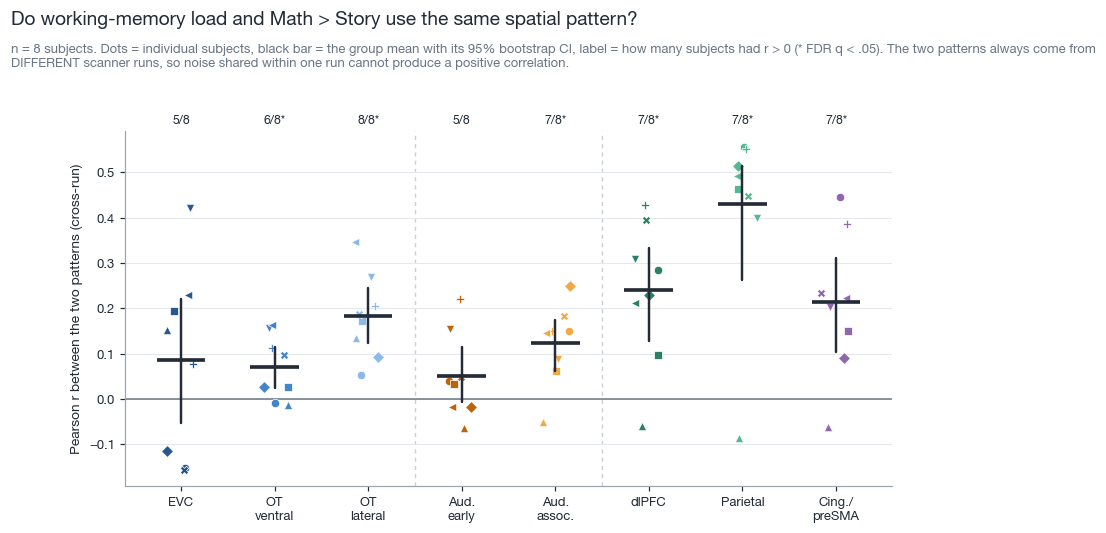

Pattern correlation between WM load (2-back > 0-back) and Language Math > Story, by ROI (positive = same direction)
        roi  mean_r  ci_lo  ci_hi  n_positive  n_subjects  p_signflip  mean_rel_wm  mean_rel_lang  mean_r_corrected  q_fdr
        EVC   0.085 -0.052  0.220           5           8       0.344        0.162          0.441               NaN  0.344
 OT_ventral   0.070  0.024  0.116           6           8       0.031        0.060          0.342               NaN  0.041
 OT_lateral   0.184  0.123  0.246           8           8       0.008        0.095          0.575               NaN  0.023
  AUD_early   0.050 -0.007  0.114           5           8       0.210        0.055          0.426               NaN  0.240
  AUD_assoc   0.123  0.061  0.175           7           8       0.014        0.095          0.709               NaN  0.023
   FP_dlpfc   0.241  0.128  0.332           7           8       0.014        0.291          0.728               NaN  0.023
FP_parietal   0.430  0.

In [32]:
# =============================================================================
# STAGE 10b - SHARED DEMAND AXIS: do WM load and Math > Story use the same pattern?
# =============================================================================
# The correlational counterpart of the cross-task decoder. Per subject and ROI, correlate the WM load pattern
# (mean 2-back minus mean 0-back) with the Language Math-minus-Story pattern across grayordinates.
#
# The key methodological point is that the two patterns are taken from DIFFERENT scanner runs - WM LR against
# Language RL, and WM RL against Language LR, then averaged. Patterns from the same run share noise (motion, drift,
# physiology), which alone would produce a positive correlation; using different runs removes that explanation.
#
# r_corrected divides r by the geometric mean of the two within-task LR/RL reliabilities, i.e. how large the
# correlation is compared with the most it could possibly be given the noise. It is reported only where the WM load
# pattern is itself reliable (>= 0.2), because dividing by a near-zero reliability makes the number explode; the
# uncorrected r is the one to quote.
def _r(a, b):
    return float(np.corrcoef(a, b)[0, 1])


def _fz(r):
    return np.arctanh(np.clip(r, -.999, .999))


da_rows = []
for sid in SUBJECTS:
    P = get_patterns(sid)
    wm = {run: P[f"WM_{run}_t"][4:8].mean(0) - P[f"WM_{run}_t"][:4].mean(0) for run in ("LR", "RL")}
    lg = {run: P[f"LANGUAGE_{run}_t"][1] - P[f"LANGUAGE_{run}_t"][0] for run in ("LR", "RL")}      # rows: story, math
    for roi, mask in roi_masks.items():
        a1, b1, a2, b2 = wm["LR"][mask], lg["RL"][mask], wm["RL"][mask], lg["LR"][mask]
        r = float(np.tanh(.5 * (_fz(_r(a1, b1)) + _fz(_r(a2, b2)))))
        rel_wm, rel_lg = _r(wm["LR"][mask], wm["RL"][mask]), _r(lg["LR"][mask], lg["RL"][mask])
        r_corr = r / np.sqrt(rel_wm * rel_lg) if rel_wm > 0 and rel_lg > 0 else np.nan
        da_rows.append(dict(subject=sid, roi=roi, r_cross=r, rel_wm_load=rel_wm, rel_lang=rel_lg, r_corrected=r_corr))
demand = pd.DataFrame(da_rows)
demand["rel_ok"] = demand.rel_wm_load >= 0.2          # the reliability correction is only trustworthy when the WM load pattern is reliable

g_rows = []
for roi in roi_masks:
    sub = demand[demand.roi == roi]
    v = sub.r_cross.values
    lo, hi = bootstrap_ci(v)
    g_rows.append(dict(roi=roi, mean_r=float(np.tanh(np.mean(_fz(v)))), ci_lo=lo, ci_hi=hi, n_positive=int((v > 0).sum()), n_subjects=len(v),
                       p_signflip=signflip_mean_p(v), mean_rel_wm=sub.rel_wm_load.mean(), mean_rel_lang=sub.rel_lang.mean(),
                       mean_r_corrected=np.nanmean(sub.r_corrected) if sub.rel_ok.all() else np.nan))
demand_group = pd.DataFrame(g_rows)
demand_group["q_fdr"] = bh_fdr(demand_group.p_signflip.values)
note("Pattern correlation between WM load (2-back > 0-back) and Language Math > Story, by ROI (positive = same direction)")
note(demand_group.round(3).to_string(index=False))
note(f"\nWith {len(SUBJECTS)} subjects the smallest possible sign-flip p is {2 / 2 ** len(SUBJECTS):.4f}.")
note("mean_r_corrected (r divided by the geometric mean of the two within-task reliabilities) is shown only where every subject's WM load"
      " reliability is >= 0.2; elsewhere it explodes because the WM load pattern is barely reliable. Quote the uncorrected mean_r.")

fig, ax = plt.subplots(figsize=(9, 4.2))
group_dividers(ax, "x")
for i, roi in enumerate(ROI_ORDER):
    v = demand[demand.roi == roi].r_cross.values
    strip(ax, i, v, ROI_COLORS[roi], seed=i, subjects=SUBJECTS, mean=False, size=30)
    r = demand_group[demand_group.roi == roi].iloc[0]
    ax.plot([i, i], [r.ci_lo, r.ci_hi], color=INK, lw=1.6, zorder=4, solid_capstyle="round")
    ax.plot([i - .26, i + .26], [r.mean_r] * 2, color=INK, lw=2.4, zorder=5, solid_capstyle="butt")
    ax.text(i, 1.02, f"{r.n_positive}/{r.n_subjects}{stars(r.q_fdr)}", transform=ax.get_xaxis_transform(), ha="center", fontsize=8,
            fontweight="bold" if r.q_fdr < .05 else "normal", color=INK)
ax.axhline(0, color=MUTED, lw=1)
roi_ticks(ax, "x"); ax.set_ylabel("Pearson r between the two patterns (cross-run)")
fig_title(fig, "Do working-memory load and Math > Story use the same spatial pattern?",
          f"n = {len(SUBJECTS)} subjects. Dots = individual subjects, black bar = the group mean with its 95% bootstrap CI, label = how many subjects "
          "had r > 0 (* FDR q < .05). The two patterns always come from DIFFERENT scanner runs, so noise shared within one run cannot produce a "
          "positive correlation.", y=1.14)
save_fig(fig, "demand_axis_pattern_correlation.png")
demand.to_csv(os.path.join(NOVELTY_DIR, "demand_axis_subject_level.csv"), index=False)
demand_group.to_csv(os.path.join(NOVELTY_DIR, "demand_axis_group.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


## Stage 11 — Confound controls

Three controls, each aimed at one way the cross-subject results above could be produced without any of the brain
processes we are claiming.

1. **Shared event timing.** HCP presents the same block schedule to every participant. If it is shared, anything
   locked to the schedule — scanner drift, slow physiological fluctuation, simply the position of a block in the run
   — becomes a predictor of the condition label for *every* subject at once, and a leave-one-subject-out decoder
   will report it as a category or load code.
2. **One-category effects.** A four-way decoder can be above chance while separating only one category from the
   rest. Dropping each category in turn says whether the code is genuinely four-way, and it matters here because
   "places" blocks sit late in both runs of that shared schedule.
3. **Resting-state decoding.** The decisive version of control 1: run the whole decoding pipeline on resting data
   with the real task design imposed on it. There were no faces and no memory load in those data, so anything above
   chance is the design and the preprocessing talking.

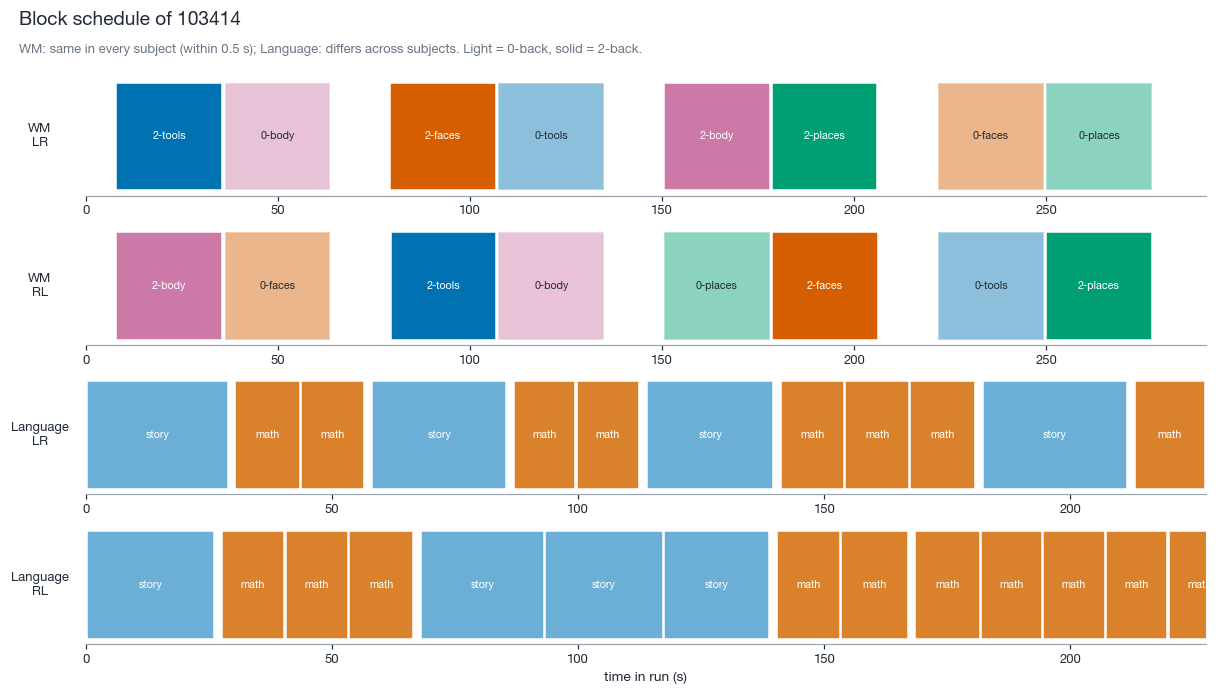

Event onsets/durations of each subject compared with 103414 (tolerance 0.5 s):
status        different  different number of blocks  same schedule
task     run                                                      
LANGUAGE LR           9                           5              0
         RL          11                           0              3
WM       LR           0                           0             56
         RL           0                           0             56

VERDICT per task:
  WM: the same block schedule in every subject (largest onset/duration difference 0.32 s, under 0.5 s) -> shared timing-locked signals are possible.
  LANGUAGE: timing differs across subjects (25 of 28 comparisons; largest difference 36.7 s, 5 with a different number of blocks) -> there is no shared schedule for a cross-subject decoder to exploit.

Correlation between each condition label and block onset time (|r| near 1 = the label is confounded with time in the run; only 8 WM blocks per run, s

In [33]:
# =============================================================================
# STAGE 11 - CONTROL B: do all subjects share the same event schedule?
# =============================================================================
# This is the control that a cross-subject decoder most needs. HCP task timing is usually identical across subjects.
# If it is, then anything locked to the block schedule - scanner drift, a cue-locked response, slow fatigue, simply
# the position of a block in the run - is SHARED by every subject, and a leave-one-subject-out decoder can pick it
# up and present it as a category or load code. This cell measures how large that risk is. It reads only EV files,
# so it is fast and needs no imaging data.
#
# Four steps:
#   1  compare every subject's onsets and durations with the first subject's (tolerance 0.5 s, about 0.7 TR)
#   2  reconstruct the reference subject's block schedule
#   3  correlate each condition label with time in the run - a label that drifts with time is confounded with drift
#   4  correlate each convolved WM regressor with a linear ramp, which is the regressor-level version of the same risk
# The figure draws the schedule itself, which is the clearest way to see whether a condition sits late or early in
# every run. Edit EV_ROOT if the folder layout differs.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EV_ROOT = "/Users/shwetharao/Downloads/{sid}/MNINonLinear/Results/tfMRI_{task}_{run}/EVs"
EV_CONDS = {"WM": ["0bk_faces", "0bk_places", "0bk_tools", "0bk_body", "2bk_faces", "2bk_places", "2bk_tools", "2bk_body"],
            "LANGUAGE": ["story", "math"]}
EV_NTR = {"WM": 405, "LANGUAGE": 316}
EV_TR = 0.72
ONSET_TOL = 0.5      # seconds (about 0.7 TR): onsets / durations closer than this count as the same schedule


def read_ev(sid, task, run, cond):
    f = os.path.join(EV_ROOT.format(sid=sid, task=task, run=run), cond + ".txt")
    if not (os.path.isfile(f) and os.path.getsize(f) > 0):
        return None
    with open(f) as fh:
        return np.atleast_2d(np.loadtxt(fh))[:, :3]          # onset, duration, amplitude


# ---- 1. load every EV file and compare each subject with the first subject ----
ref_sid = SUBJECTS[0]
audit, events = [], {}
for task, conds in EV_CONDS.items():
    for run in ("LR", "RL"):
        for sid in SUBJECTS:
            for c in conds:
                events[(sid, task, run, c)] = read_ev(sid, task, run, c)
        for sid in SUBJECTS[1:]:
            for c in conds:
                a, b = events[(ref_sid, task, run, c)], events[(sid, task, run, c)]
                if a is None or b is None:
                    status, dmax = "missing file", np.nan
                elif a.shape != b.shape:
                    status, dmax = "different number of blocks", np.nan
                else:
                    dmax = float(np.abs(a[:, :2] - b[:, :2]).max())
                    status = "same schedule" if dmax <= ONSET_TOL else "different"
                audit.append(dict(task=task, run=run, subject=sid, condition=c, vs=ref_sid, max_abs_diff_s=dmax, status=status))
audit = pd.DataFrame(audit)
note(f"Event onsets/durations of each subject compared with {ref_sid} (tolerance {ONSET_TOL} s):")
note(audit.groupby(["task", "run"]).status.value_counts().unstack(fill_value=0).to_string())
note("\nVERDICT per task:")
shared = {}
for task in EV_CONDS:
    a = audit[audit.task == task]
    shared[task] = bool((a.status == "same schedule").all())
    dmax = a.max_abs_diff_s.max()
    if shared[task]:
        note(f"  {task}: the same block schedule in every subject (largest onset/duration difference {dmax:.2f} s, under {ONSET_TOL} s)"
              " -> shared timing-locked signals are possible.")
    else:
        bad = a[a.status != "same schedule"]
        note(f"  {task}: timing differs across subjects ({len(bad)} of {len(a)} comparisons; largest difference {np.nanmax(bad.max_abs_diff_s):.1f} s,"
              f" {int((bad.status == 'different number of blocks').sum())} with a different number of blocks)"
              " -> there is no shared schedule for a cross-subject decoder to exploit.")

# ---- 2. block schedule of the reference subject ----
sched = []
for task in EV_CONDS:
    for run in ("LR", "RL"):
        for c in EV_CONDS[task]:
            ev = events[(ref_sid, task, run, c)]
            if ev is None:
                continue
            for k, (on, du, _) in enumerate(ev):
                sched.append(dict(task=task, run=run, condition=c, block=k, onset_s=on, duration_s=du, onset_frac_of_run=on / (EV_NTR[task] * EV_TR)))
sched = pd.DataFrame(sched)

# ---- 3. confound check: is a condition label correlated with time in the run? ----
conf = []
for task in EV_CONDS:
    for run in ("LR", "RL"):
        s = sched[(sched.task == task) & (sched.run == run)]
        if len(s) < 3:
            continue
        if task == "WM":
            conf.append(dict(task=task, run=run, label="load (2-back = 1)",
                             corr_with_onset=float(np.corrcoef(s.condition.str.startswith("2bk").astype(float).values, s.onset_s.values)[0, 1])))
            for cat in CATS:
                conf.append(dict(task=task, run=run, label=f"category = {cat}",
                                 corr_with_onset=float(np.corrcoef(s.condition.str.endswith(cat).astype(float).values, s.onset_s.values)[0, 1])))
        else:
            conf.append(dict(task=task, run=run, label="math = 1",
                             corr_with_onset=float(np.corrcoef((s.condition == "math").astype(float).values, s.onset_s.values)[0, 1])))
conf = pd.DataFrame(conf)
note("\nCorrelation between each condition label and block onset time (|r| near 1 = the label is confounded with time in the run;"
      " only 8 WM blocks per run, so |r| < 0.7 is not significant on its own):")
note(conf.round(2).to_string(index=False))

# ---- 4. regressor level: how much of each convolved WM regressor is slow drift? ----
dt = 0.01
t_high = np.arange(0, EV_NTR["WM"] * EV_TR, dt)
t_tr = np.arange(EV_NTR["WM"]) * EV_TR
hrf = double_gamma_hrf(np.arange(0, 32.0, dt))
ramp = np.linspace(-1, 1, EV_NTR["WM"])
reg_rows = []
for run in ("LR", "RL"):
    for c in EV_CONDS["WM"]:
        ev = events[(ref_sid, "WM", run, c)]
        box = np.zeros_like(t_high)
        for on, du, am in ev:
            box[(t_high >= on) & (t_high < on + du)] = am
        reg = np.interp(t_tr, t_high, np.convolve(box, hrf)[:len(t_high)] * dt)
        reg_rows.append(dict(run=run, condition=c, corr_with_linear_drift=float(np.corrcoef(reg, ramp)[0, 1])))
reg_rows = pd.DataFrame(reg_rows)
note("\nCorrelation of each convolved WM regressor with a linear drift (the GLM also contains cosine drift terms, so this overstates the risk):")
note(reg_rows.round(2).to_string(index=False))

# ---- 5. figure: WM schedule of the reference subject (shared by all subjects) and the Language schedule ----
pal = {"faces": CAT_COLORS["faces"], "places": CAT_COLORS["places"], "tools": CAT_COLORS["tools"], "body": CAT_COLORS["body"],
       "story": "#6BAED6", "math": "#D9822B"}
panels = [("WM", "LR"), ("WM", "RL"), ("LANGUAGE", "LR"), ("LANGUAGE", "RL")]
fig, axes = plt.subplots(4, 1, figsize=(11, 5.6), constrained_layout=True)
for ax, (task, run) in zip(axes, panels):
    s = sched[(sched.task == task) & (sched.run == run)]
    ax.grid(False)
    for _, r in s.iterrows():
        key = r.condition.split("_")[-1]
        two = r.condition.startswith("2bk")
        ax.barh(0, r.duration_s, left=r.onset_s, height=.8, color=pal.get(key, "gray"), alpha=1.0 if (two or task == "LANGUAGE") else .45, edgecolor="white", lw=1)
        if r.duration_s > 11:
            ax.text(r.onset_s + r.duration_s / 2, 0, r.condition.replace("bk_", "-").replace("story", "story").replace("math", "math"),
                    ha="center", va="center", fontsize=7, color="white" if (two or task == "LANGUAGE") else INK)
    ax.set_xlim(0, EV_NTR[task] * EV_TR); ax.set_yticks([]); ax.set_ylabel(f"{ {'WM': 'WM'}.get(task, task.title()) }\n{run}", rotation=0, labelpad=30, fontsize=8.5, va="center")
    ax.spines["left"].set_visible(False)
axes[-1].set_xlabel("time in run (s)")
fig_title(fig, f"Block schedule of {ref_sid}",
          "WM: " + ("same in every subject (within %.1f s)" % ONSET_TOL if shared["WM"] else "differs across subjects") + "; Language: "
          + ("same in every subject" if shared["LANGUAGE"] else "differs across subjects") + ". Light = 0-back, solid = 2-back.", y=1.1)
save_fig(fig, "event_timing_schedule.png")
audit.to_csv(os.path.join(NOVELTY_DIR, "event_timing_audit.csv"), index=False)
conf.to_csv(os.path.join(NOVELTY_DIR, "event_timing_confounds.csv"), index=False)
note("\nWhat to do with the result:")
note(" - WM schedule shared AND a label is strongly correlated with onset (|r| > 0.5): a shared drift could masquerade as that label."
      "\n   See the leave-one-category-out cell and, with resting runs, the resting-data decoding control.")
note(" - Labels balanced in time in BOTH runs (|r| small): the risk is small; say so in the methods.")
note(" - Language timing differs across subjects: a shared timing artifact cannot create Language effects in a cross-subject decoder.")

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


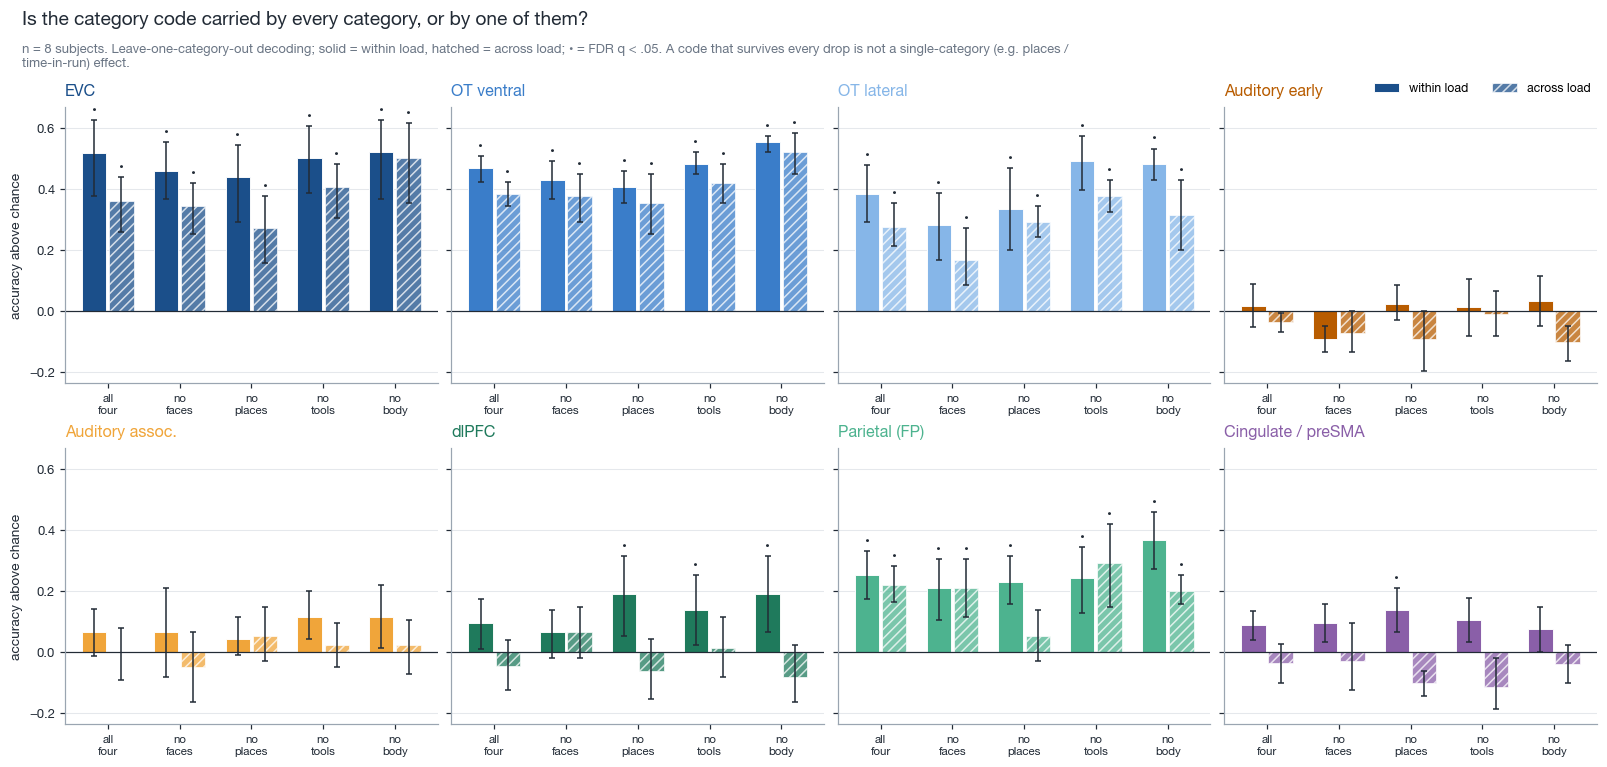

Leave-one-category-out decoding (excess = accuracy minus chance; chance is 0.25 for four categories, 0.333 for three).
        roi    subset        kind  n_categories  chance  mean_acc  excess  excess_ci_lo  excess_ci_hi  n_above_chance  n_subjects  p_perm  q_fdr
        EVC  all four within load             4   0.250     0.766   0.516         0.375         0.625               8           8   0.003  0.008
        EVC  all four across load             4   0.250     0.609   0.359         0.258         0.438               8           8   0.003  0.008
        EVC  no faces within load             3   0.333     0.792   0.458         0.365         0.552               8           8   0.003  0.008
        EVC  no faces across load             3   0.333     0.677   0.344         0.250         0.417               8           8   0.003  0.008
        EVC no places within load             3   0.333     0.771   0.438         0.292         0.542               7           8   0.003  0.008
        EVC

In [34]:
# =============================================================================
# STAGE 11a - CONTROL C: is the category code carried by all four categories, or by one?
# =============================================================================
# The timing audit shows that "places" blocks sit late in both runs of the shared schedule, so a slow drift common
# to all subjects could masquerade as a places signal. Two checks:
#   1  Leave-one-category-out decoding: drop one category at a time and decode the remaining three (chance 1/3).
#      A code that survives dropping each category in turn, places included, is not a one-category effect.
#   2  Per-category recall (the diagonal of the confusion matrix), within and across load, which shows directly
#      which categories the region actually distinguishes.
# Note that chance changes from 0.25 to 0.333 when a category is dropped, so accuracies are compared as EXCESS over
# chance, not as raw numbers.
# Needs LosoModel, get_patterns, _scale, bh_fdr, bootstrap_ci and the style cell.
N_PERM_LOCO = 300
SUBSETS = [("all four", [0, 1, 2, 3]), ("no faces", [1, 2, 3]), ("no places", [0, 2, 3]), ("no tools", [0, 1, 3]), ("no body", [0, 1, 2])]
_MODELS = {"0->0": (0, 0), "2->2": (1, 1), "0->2": (0, 1), "2->0": (1, 0)}


def wm_category_dataset(get_M, roi, keep, subjects=None):
    """Category dataset restricted to the categories in `keep`. get_M(sid, run, roi) -> (8, n_features) WM t-patterns.
    The category mean inside each run x load is removed from the KEPT categories only, then features are scaled per subject."""
    X, subj, run, load, y = [], [], [], [], []
    for si, sid in enumerate(subjects if subjects is not None else SUBJECTS):
        blocks = []
        for ri, rn in enumerate(("LR", "RL")):
            M = np.asarray(get_M(sid, rn, roi), float)
            for L in (0, 1):
                R = M[[L * 4 + c for c in keep]]
                blocks.append(R - R.mean(axis=0, keepdims=True))
                subj += [si] * len(keep); run += [ri] * len(keep); load += [L] * len(keep); y += list(range(len(keep)))
        X.append(_scale(np.vstack(blocks)))
    return dict(X=np.vstack(X), subj=np.array(subj), run=np.array(run), load=np.array(load), y=np.array(y))


def _task_getter(sid, rn, roi):
    return get_patterns(sid)[f"WM_{rn}_t"][:, roi_masks[roi]]


def _perm_p_mean(models, y, groups, n_perm, seed):
    """Permutation p for the MEAN of several LOSO models (e.g. within-load = mean of 0->0 and 2->2), one shared label shuffle per draw."""
    rng = np.random.default_rng(seed)
    blocks = [np.where(groups == g)[0] for g in np.unique(groups)]
    obs = np.mean([m.accuracy(y).mean() for m in models])
    null = np.empty(n_perm)
    for i in range(n_perm):
        yp = y.copy()
        for idx in blocks:
            yp[idx] = y[rng.permutation(idx)]
        null[i] = np.mean([m.accuracy(yp).mean() for m in models])
    return (1 + np.sum(null >= obs)) / (n_perm + 1)


def _fold_predictions(model, y):
    k = int(y.max()) + 1
    Y = np.eye(k)[y] - 1.0 / k
    true, pred = [], []
    for tr, te, U, inv, Kte in model.folds:
        alpha = U @ (inv[:, None] * (U.T @ Y[tr]))
        pred.append((Kte @ alpha).argmax(axis=1)); true.append(y[te])
    return np.concatenate(true), np.concatenate(pred)


loco_rows, recall_rows, loco_subj = [], [], {}
for roi in ROI_ORDER:
    for sname, keep in SUBSETS:
        d = wm_category_dataset(_task_getter, roi, keep)
        K = d["X"] @ d["X"].T
        groups = d["subj"] * 100 + d["run"] * 10 + d["load"]
        models = {n: LosoModel(K, d["subj"], d["load"] == a, d["load"] == b) for n, (a, b) in _MODELS.items()}
        chance = 1.0 / len(keep)
        for kind, names in (("within load", ("0->0", "2->2")), ("across load", ("0->2", "2->0"))):
            acc = np.mean([models[n].accuracy(d["y"]) for n in names], axis=0)
            loco_subj[(roi, sname, kind)] = acc
            p = _perm_p_mean([models[n] for n in names], d["y"], groups, N_PERM_LOCO, seed=11)
            lo, hi = bootstrap_ci(acc - chance)
            loco_rows.append(dict(roi=roi, subset=sname, kind=kind, n_categories=len(keep), chance=chance, mean_acc=acc.mean(),
                                  excess=acc.mean() - chance, excess_ci_lo=lo, excess_ci_hi=hi, n_above_chance=int((acc > chance).sum()),
                                  n_subjects=len(acc), p_perm=p))
            if sname == "all four":
                T, Pd = [], []
                for n in names:
                    t, pr = _fold_predictions(models[n], d["y"]); T.append(t); Pd.append(pr)
                T, Pd = np.concatenate(T), np.concatenate(Pd)
                for c, cname in enumerate(CATS):
                    recall_rows.append(dict(roi=roi, kind=kind, category=cname, recall=float(np.mean(Pd[T == c] == c)), chance=.25))
loco = pd.DataFrame(loco_rows)
loco["q_fdr"] = bh_fdr(loco.p_perm.values)
category_recall = pd.DataFrame(recall_rows)

# ---- summary: does the code survive dropping each category? ----
sum_rows = []
for roi in ROI_ORDER:
    for kind in ("within load", "across load"):
        q = loco[(loco.roi == roi) & (loco.kind == kind)].set_index("subset")
        full = q.loc["all four"]
        drops = q.drop(index="all four")
        worst = drops.excess.idxmin()
        sum_rows.append(dict(roi=roi, kind=kind, excess_all_four=full.excess, worst_drop=worst, excess_after_worst_drop=drops.excess.min(),
                             survives_every_drop=bool(((drops.q_fdr < .05) & (drops.excess_ci_lo > 0)).all()),
                             all_four_reliable=bool(full.q_fdr < .05 and full.excess_ci_lo > 0)))
loco_summary = pd.DataFrame(sum_rows)
pd.set_option("display.width", 200)
note("Leave-one-category-out decoding (excess = accuracy minus chance; chance is 0.25 for four categories, 0.333 for three).")
note(loco.round(3).to_string(index=False))
note("\nDoes the category code survive dropping each category in turn?")
note(loco_summary.round(3).to_string(index=False))
note("\nPer-category recall (4-way, chance 0.25):")
note(category_recall.pivot_table(index=["roi", "kind"], columns="category", values="recall").round(2).to_string())
note("\nHow to read it: 'survives_every_drop = True' means the code is not a one-category effect. If a ROI is reliable with all four"
      " categories but collapses when 'no places' is dropped, treat that ROI's category result as a places effect, and as possibly"
      " time-confounded (places sits late in both runs of the shared schedule).")

fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.2), sharey=True, constrained_layout=True)
xs = np.arange(len(SUBSETS))
for ax, roi in zip(axes.ravel(), ROI_ORDER):
    for k, (kind, hatch, alpha) in enumerate((("within load", None, 1.0), ("across load", "////", .75))):
        q = loco[(loco.roi == roi) & (loco.kind == kind)].set_index("subset").loc[[s for s, _ in SUBSETS]]
        pos = xs + (k - .5) * .38
        ax.bar(pos, q.excess, .34, color=ROI_COLORS[roi], alpha=alpha, hatch=hatch, edgecolor="white", lw=.6, label=kind)
        ax.errorbar(pos, q.excess, yerr=[np.maximum(q.excess - q.excess_ci_lo, 0), np.maximum(q.excess_ci_hi - q.excess, 0)],
                    fmt="none", ecolor=INK, lw=1, capsize=2)
        for xp, (_, row) in zip(pos, q.iterrows()):
            if row.q_fdr < .05:
                ax.text(xp, row.excess_ci_hi + .012, "•", ha="center", va="bottom", fontsize=9, color=INK)
    ax.axhline(0, color=INK, lw=.8)
    ax.set_xticks(xs); ax.set_xticklabels([s.replace(" ", "\n") for s, _ in SUBSETS], fontsize=7.5)
    ax.set_title(ROI_NAME[roi], color=ROI_COLORS[roi])
axes[0, 0].set_ylabel("accuracy above chance"); axes[1, 0].set_ylabel("accuracy above chance")
h_, l_ = axes[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, fontsize=8, loc="upper right", ncol=2, frameon=False, bbox_to_anchor=(1, 1.01))
fig_title(fig, "Is the category code carried by every category, or by one of them?",
          f"n = {len(SUBJECTS)} subjects. Leave-one-category-out decoding; solid = within load, hatched = across load; • = FDR q < .05. "
          "A code that survives every drop is not a single-category (e.g. places / time-in-run) effect.", y=1.1)
save_fig(fig, "category_leave_one_out.png")
loco.to_csv(os.path.join(NOVELTY_DIR, "category_leave_one_out.csv"), index=False)
loco_summary.to_csv(os.path.join(NOVELTY_DIR, "category_leave_one_out_summary.csv"), index=False)
category_recall.to_csv(os.path.join(NOVELTY_DIR, "category_recall.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


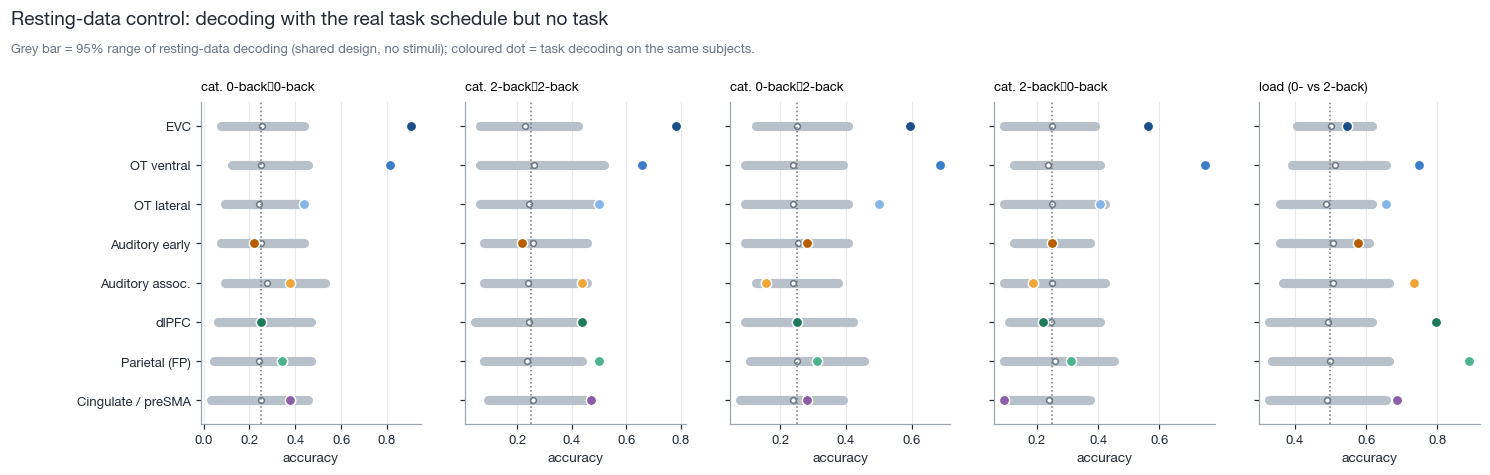

Using saved draws: derivatives/novelty/rest_decoding_null_draws.csv
Task decoding vs resting-data decoding with the same design (4 subjects, 100 draws).
If the rest null sits at chance and the task value is far above it, the shared schedule does not explain the result.
        roi                    analysis  task_acc  rest_null_mean  rest_null_95  rest_null_max  p_rest  n_draws  n_subjects  q_fdr
        EVC category | 0-back -> 0-back     0.906           0.257         0.406          0.500   0.010      100           4  0.028
        EVC category | 2-back -> 2-back     0.781           0.230         0.406          0.500   0.010      100           4  0.028
        EVC category | 0-back -> 2-back     0.594           0.252         0.377          0.438   0.010      100           4  0.028
        EVC category | 2-back -> 0-back     0.562           0.248         0.375          0.406   0.010      100           4  0.028
        EVC         load (0- vs 2-back)     0.547           0.500         0

In [35]:
# =============================================================================
# STAGE 11b - CONTROL D: does the shared schedule produce decoding in RESTING data?
# =============================================================================
# The strongest available answer to "could a time-locked artefact shared by every subject explain the cross-subject
# decoding?". For every subject with resting runs, draw random 405-frame windows, fit the REAL WM design to them
# (each subject's own event times, the same AR(1) GLM), and run the same leave-one-subject-out decoders on the
# resulting "patterns". There was no task, no faces and no memory load in those data, so any accuracy above chance
# can only come from the shared design and the preprocessing. The task decoding is recomputed on the SAME subjects
# so the two columns are comparable.
# Needs resting runs for at least MIN_REST_SUBJECTS subjects (paths are set in Stage 6a). With fewer, the cell
# explains what is missing and skips rather than producing a number that cannot be interpreted.
MIN_REST_SUBJECTS = 4
N_DRAWS_DEC = 100               # each draw = new windows for every resting subject; 100 gives p down to about 0.01
RECOMPUTE_DEC_NULL = False
DEC_ANALYSES = ["category | 0-back -> 0-back", "category | 2-back -> 2-back", "category | 0-back -> 2-back", "category | 2-back -> 0-back",
                "load (0- vs 2-back)"]


def dataset_from_patterns(get_M, roi, subjects):
    """Same layout as build_dataset(roi, 'WM'), but from any pattern source: get_M(sid, run, roi) -> (8, n_features)."""
    Xc, Xl, meta = [], [], []
    for si, sid in enumerate(subjects):
        runs = [np.asarray(get_M(sid, rn, roi), float) for rn in ("LR", "RL")]
        Xc.append(prep_category(runs)); Xl.append(prep_load(runs))
        for ri in (0, 1):
            for k in range(8):
                meta.append((si, ri, LOAD_OF_ROW[k], CAT_OF_ROW[k]))
    meta = np.asarray(meta)
    return dict(subj=meta[:, 0], run=meta[:, 1], load=meta[:, 2], y=meta[:, 3], X_main=np.vstack(Xc), X_load=np.vstack(Xl))


def group_accuracies(get_M, subjects):
    out = {}
    for roi in ROI_ORDER:
        d = dataset_from_patterns(get_M, roi, subjects)
        for name, (K, y, s, tr, te, chance, groups) in wm_analyses(d).items():
            out[(roi, name)] = LosoModel(K, s, tr, te).accuracy(y).mean()
    return out


def rest_patterns_for_draw(inputs, rng):
    pats = {}
    for sid, (union, loaded) in inputs.items():
        for run, (Y, M, task_cols, dct) in loaded.items():
            start = int(rng.integers(0, Y.shape[0] - N_WM_TRS + 1))
            X = np.column_stack([task_cols, M[start:start + N_WM_TRS], dct, np.ones(N_WM_TRS)])
            Cm = np.zeros((8, X.shape[1])); Cm[np.arange(8), np.arange(8)] = 1.0
            _, tstats, _ = fit_glm_ar1_binned(Y[start:start + N_WM_TRS], X, Cm)
            pats[(sid, run)] = tstats
    return pats


rest_dec_subjects = [s for s in SUBJECTS if rest_available(s)]
if len(rest_dec_subjects) < MIN_REST_SUBJECTS:
    note(f"Skipped: resting runs found for {len(rest_dec_subjects)} subject(s) ({rest_dec_subjects}); this control needs at least "
          f"{MIN_REST_SUBJECTS} (decoding is trained on the other subjects). Download rfMRI_REST1_LR/RL for more subjects to the paths in the "
          "rfMRI-null cell and run this cell again.")
else:
    import time
    cache = os.path.join(NOVELTY_DIR, "rest_decoding_null_draws.csv")
    union = np.any(np.vstack(list(roi_masks.values())), axis=0)
    roi_in_union = {roi: m[union] for roi, m in roi_masks.items()}
    if os.path.isfile(cache) and not RECOMPUTE_DEC_NULL:
        null_df = pd.read_csv(cache)
        note("Using saved draws:", cache)
    else:
        inputs = {}
        for sid in rest_dec_subjects:
            loaded = {}
            for run in ("LR", "RL"):
                Y = _load_rest(REST_FILE.format(sid=sid, run=run), union)
                M = _rest_motion(REST_MOTION.format(sid=sid, run=run), Y.shape[0])
                ev_dir = _ev_dir_for(sid, run)
                task_cols = build_design(ev_dir, os.path.join(os.path.dirname(ev_dir), "Movement_Regressors.txt"),
                                         WM_CONDS, N_WM_TRS, TR_WM).iloc[:, :8].values
                loaded[run] = (Y, M, task_cols, generate_dct_basis(N_WM_TRS, TR_WM, 128.0).values)
            inputs[sid] = (union, loaded)
        rng = np.random.default_rng(NOVELTY_SEED + 7)
        recs, t0 = [], time.time()
        for dr in range(N_DRAWS_DEC):
            pats = rest_patterns_for_draw(inputs, rng)
            acc = group_accuracies(lambda sid, rn, roi: pats[(sid, rn)][:, roi_in_union[roi]], rest_dec_subjects)
            recs += [dict(draw=dr, roi=r, analysis=a, acc=v) for (r, a), v in acc.items()]
            if dr == 0:
                note(f"first draw took {time.time() - t0:.0f} s -> about {(time.time() - t0) * N_DRAWS_DEC / 60:.0f} min for {N_DRAWS_DEC} draws")
        null_df = pd.DataFrame(recs)
        null_df.to_csv(cache, index=False)
    obs_acc = group_accuracies(_task_getter, rest_dec_subjects)
    rows = []
    for (roi, name), o in obs_acc.items():
        nul = null_df[(null_df.roi == roi) & (null_df.analysis == name)].acc.values
        rows.append(dict(roi=roi, analysis=name, task_acc=o, rest_null_mean=nul.mean(), rest_null_95=np.percentile(nul, 95),
                         rest_null_max=nul.max(), p_rest=(1 + np.sum(nul >= o)) / (len(nul) + 1), n_draws=len(nul),
                         n_subjects=len(rest_dec_subjects)))
    rest_dec = pd.DataFrame(rows)
    rest_dec["q_fdr"] = bh_fdr(rest_dec.p_rest.values)
    note(f"Task decoding vs resting-data decoding with the same design ({len(rest_dec_subjects)} subjects, {N_DRAWS_DEC} draws).")
    note("If the rest null sits at chance and the task value is far above it, the shared schedule does not explain the result.")
    note(rest_dec.round(3).to_string(index=False))
    fig, axes = plt.subplots(1, len(DEC_ANALYSES), figsize=(3.0 * len(DEC_ANALYSES), 3.8), sharey=False)
    for ax, name in zip(axes, DEC_ANALYSES):
        for i, roi in enumerate(ROI_ORDER):
            nul = null_df[(null_df.roi == roi) & (null_df.analysis == name)].acc.values
            ax.plot([np.percentile(nul, 2.5), np.percentile(nul, 97.5)], [i, i], color="#B8C0CA", lw=6, solid_capstyle="round", zorder=1)
            ax.scatter(np.mean(nul), i, s=14, color="white", edgecolor=MUTED, zorder=2)
            ax.scatter(obs_acc[(roi, name)], i, s=46, color=ROI_COLORS[roi], edgecolor="white", zorder=3)
        ax.axvline(.5 if name.startswith("load") else .25, color=MUTED, ls=":", lw=1)
        ax.set_ylim(len(ROI_ORDER) - .4, -.6); ax.set_yticks(range(len(ROI_ORDER)))
        ax.set_yticklabels([ROI_NAME[r] for r in ROI_ORDER] if ax is axes[0] else []); ax.grid(False, axis="y"); ax.grid(True, axis="x")
        ax.set_title(name.replace("category | ", "cat. ").replace(" -> ", "→"), fontsize=8.5); ax.set_xlabel("accuracy")
    fig_title(fig, "Resting-data control: decoding with the real task schedule but no task",
              "Grey bar = 95% range of resting-data decoding (shared design, no stimuli); coloured dot = task decoding on the same subjects.", y=1.1)
    save_fig(fig, "rest_decoding_control.png")
    rest_dec.to_csv(os.path.join(NOVELTY_DIR, "rest_decoding_control.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


### Stage 11c — Schedule-shift null and block-position removal

Follow-up to Stage 11b for the parietal question. All subjects saw the same block order, so a signal locked to that order looks like a category code to a cross-subject decoder. Using the resting subjects available, this cell (1) compares task decoding with the resting null on exactly the same subjects, (2) builds the null from many random circular shifts of the real schedule on resting data (1000 draws, cached and resumable), and (3) removes each block's position in the run from the patterns, in task and resting data alike, before decoding. Existing results are not changed; this adds evidence beside them.

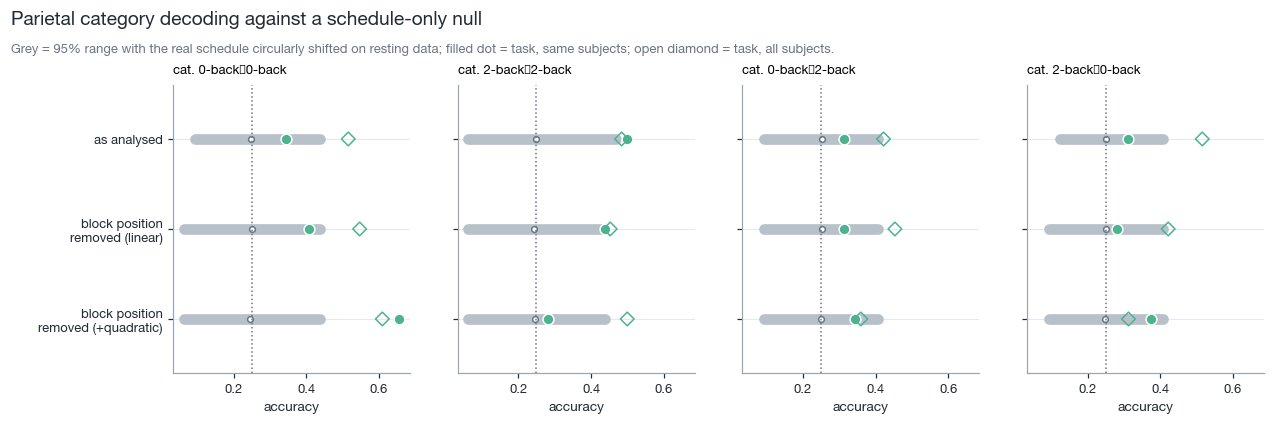

first draw 6 s -> about 99 min for the remaining draws
Schedule-shift null on 4 resting subjects, 1000 draws; task decoding recomputed on the same subjects.
Parietal, category analyses (task_all_subjects = all subjects for reference; task_matched = the resting subjects only):
   variant                    analysis  task_all_subjects  task_matched  null_mean  null_95  null_max  p_shift  n_draws  q_fdr
       raw category | 0-back -> 0-back              0.516         0.344      0.249    0.406     0.562    0.211     1000  0.337
       raw category | 2-back -> 2-back              0.484         0.500      0.248    0.438     0.531    0.014     1000  0.034
       raw category | 0-back -> 2-back              0.422         0.312      0.251    0.375     0.562    0.273     1000  0.420
       raw category | 2-back -> 0-back              0.516         0.312      0.249    0.375     0.531    0.271     1000  0.420
pos_linear category | 0-back -> 0-back              0.547         0.406      0.252    0.

In [36]:
# =============================================================================
# STAGE 11c - CONTROL E: schedule-shift null on resting data, and block-position (drift) removal
# =============================================================================
# Follow-up to Stage 11b. Every subject saw the same block order, so a schedule-locked signal (drift, slow arousal,
# block-onset transients) is shared across subjects and a leave-one-subject-out decoder reads it as a "category" code.
# With only the resting subjects we have, three things are done here. NOTHING upstream is changed: the main
# results stay as they are and this cell only adds columns of evidence beside them.
#
#   1  MATCHED COMPARISON   Task decoding is recomputed on exactly the resting subjects (same n, same folds), so the
#                           task number and the resting null are compared like with like. The all-subject task
#                           number is kept for reference in the table.
#   2  SCHEDULE-SHIFT NULL  Each draw gives every resting run (a) a random window and (b) a random CIRCULAR SHIFT of the
#                           real convolved schedule (np.roll of the 8 task regressors), then the full AR(1) GLM and the
#                           same leave-one-subject-out decoders. The block structure is intact, only its alignment with
#                           the data is destroyed, so this is the null "the schedule alone, with no task". Draws are
#                           cached in chunks and resumable (a killed run continues where it stopped).
#   3  BLOCK-POSITION REMOVAL  Within every (subject, run), regress the block's position in the run (1..8, taken
#                           from the EV onsets) out of the 8 condition patterns - linear, and linear + quadratic -
#                           and decode again. The SAME removal is applied to the resting-data patterns, so the null is
#                           matched. This removes slow drift tied to position; it cannot remove fast physiological
#                           fluctuations that happen to line up with the schedule.
#
# Reading it: if task accuracy (raw or after removal) is above the 95th percentile of the matching resting null, the
# schedule alone does not reproduce it. If it sits inside the null, call it compatible with a schedule effect.
# With 4 resting subjects this speaks for those subjects only; it is not a population claim.
N_SHIFT_DRAWS = 1000            # total draws wanted; the cache is extended up to this number
CHUNK = 50                      # draws saved per write
RECOMPUTE_SHIFT_NULL = False
VARIANTS = ["raw", "pos_linear", "pos_quad"]
FOCUS_ROI = [r for r in ROI_ORDER if "parie" in r.lower()]
FOCUS_ANALYSES = [a for a in DEC_ANALYSES if a.startswith("category")]


def block_positions(sid, run):
    """Rank (0..7) of each of the 8 WM conditions' block onset within the run, in WM_CONDS row order."""
    on = []
    for c in WM_CONDS:
        ev = read_ev(sid, "WM", run, c)
        if ev is None:
            ev = read_ev(ref_sid, "WM", run, c)          # same schedule in every subject (Stage 11 audit)
        on.append(float(ev[0, 0]))
    return np.argsort(np.argsort(on)).astype(float)


def remove_position(M, pos, order):
    """Residualise the (8, F) pattern matrix on block position (order 1 = linear, 2 = linear + quadratic), keeping the mean."""
    z = (pos - pos.mean()) / pos.std()
    Z = np.column_stack([z ** k for k in range(1, order + 1)])
    Zc = Z - Z.mean(axis=0)
    beta, *_ = np.linalg.lstsq(Zc, M - M.mean(axis=0), rcond=None)
    return M - Zc @ beta


def with_variant(get_M, variant, positions):
    if variant == "raw":
        return get_M
    order = {"pos_linear": 1, "pos_quad": 2}[variant]
    return lambda sid, rn, roi: remove_position(np.asarray(get_M(sid, rn, roi), float), positions[(sid, rn)], order)


def shifted_rest_patterns(inputs, rng):
    pats = {}
    for sid, (union, loaded) in inputs.items():
        for run, (Y, M, task_cols, dct) in loaded.items():
            start = int(rng.integers(0, Y.shape[0] - N_WM_TRS + 1))
            shift = int(rng.integers(0, N_WM_TRS))
            X = np.column_stack([np.roll(task_cols, shift, axis=0), M[start:start + N_WM_TRS], dct, np.ones(N_WM_TRS)])
            Cm = np.zeros((8, X.shape[1])); Cm[np.arange(8), np.arange(8)] = 1.0
            _, tstats, _ = fit_glm_ar1_binned(Y[start:start + N_WM_TRS], X, Cm)
            pats[(sid, run)] = tstats
    return pats


rest_subj = [s for s in SUBJECTS if rest_available(s)]
if len(rest_subj) < MIN_REST_SUBJECTS:
    note(f"Skipped: resting runs for {len(rest_subj)} subject(s); this control needs at least {MIN_REST_SUBJECTS}.")
else:
    import time
    positions = {(s, r): block_positions(s, r) for s in SUBJECTS for r in ("LR", "RL")}
    cache = os.path.join(NOVELTY_DIR, "rest_shift_null_draws.csv")
    union = np.any(np.vstack(list(roi_masks.values())), axis=0)
    roi_in_union = {roi: m[union] for roi, m in roi_masks.items()}
    done = pd.DataFrame(columns=["draw", "variant", "roi", "analysis", "acc"])
    if os.path.isfile(cache) and not RECOMPUTE_SHIFT_NULL:
        done = pd.read_csv(cache)
    first = int(done.draw.max()) + 1 if len(done) else 0
    if first < N_SHIFT_DRAWS:
        inputs = {}
        for sid in rest_subj:
            loaded = {}
            for run in ("LR", "RL"):
                Y = _load_rest(REST_FILE.format(sid=sid, run=run), union)
                Mo = _rest_motion(REST_MOTION.format(sid=sid, run=run), Y.shape[0])
                ev_dir = _ev_dir_for(sid, run)
                cols = build_design(ev_dir, os.path.join(os.path.dirname(ev_dir), "Movement_Regressors.txt"),
                                    WM_CONDS, N_WM_TRS, TR_WM).iloc[:, :8].values
                loaded[run] = (Y, Mo, cols, generate_dct_basis(N_WM_TRS, TR_WM, 128.0).values)
            inputs[sid] = (union, loaded)
        recs, t0 = [], time.time()
        for dr in range(first, N_SHIFT_DRAWS):
            rng = np.random.default_rng([NOVELTY_SEED + 11, dr])          # per-draw seed -> resumable and reproducible
            pats = shifted_rest_patterns(inputs, rng)
            get = lambda sid, rn, roi: pats[(sid, rn)][:, roi_in_union[roi]]
            for v in VARIANTS:
                acc = group_accuracies(with_variant(get, v, positions), rest_subj)
                recs += [dict(draw=dr, variant=v, roi=r, analysis=a, acc=x) for (r, a), x in acc.items()]
            if dr == first:
                note(f"first draw {time.time() - t0:.0f} s -> about {(time.time() - t0) * (N_SHIFT_DRAWS - first) / 60:.0f} min for the remaining draws")
            if (dr + 1) % CHUNK == 0 or dr == N_SHIFT_DRAWS - 1:
                done = pd.concat([done, pd.DataFrame(recs)], ignore_index=True); recs = []
                done.to_csv(cache, index=False)
    shift_df = done

    # ---- task decoding: all subjects (reference) and the matched rest subjects, raw and position-removed ----
    rows = []
    for v in VARIANTS:
        t_match = group_accuracies(with_variant(_task_getter, v, positions), rest_subj)
        t_all = group_accuracies(with_variant(_task_getter, v, positions), SUBJECTS)
        for (roi, name), o in t_match.items():
            nul = shift_df[(shift_df.variant == v) & (shift_df.roi == roi) & (shift_df.analysis == name)].acc.values
            rows.append(dict(variant=v, roi=roi, analysis=name, task_all_subjects=t_all[(roi, name)], task_matched=o,
                             null_mean=nul.mean(), null_95=np.percentile(nul, 95), null_max=nul.max(),
                             p_shift=(1 + np.sum(nul >= o)) / (len(nul) + 1), n_draws=len(nul), n_subjects=len(rest_subj)))
    ctrl = pd.DataFrame(rows)
    ctrl["q_fdr"] = bh_fdr(ctrl.p_shift.values)
    ctrl.to_csv(os.path.join(NOVELTY_DIR, "rest_shift_and_position_control.csv"), index=False)
    note(f"Schedule-shift null on {len(rest_subj)} resting subjects, {int(ctrl.n_draws.max())} draws; task decoding recomputed on the same subjects.")
    note("Parietal, category analyses (task_all_subjects = all subjects for reference; task_matched = the resting subjects only):")
    note(ctrl[ctrl.roi.isin(FOCUS_ROI) & ctrl.analysis.isin(FOCUS_ANALYSES)].drop(columns=["roi", "n_subjects"]).round(3).to_string(index=False))
    note("\nHow to read p_shift: small = task accuracy exceeds what the schedule alone gives on resting data; "
         "large = compatible with a schedule effect. The smallest possible p is 1/(n_draws+1).")

    # ---- figure: parietal category analyses, three variants, task dot against the matching resting-null band ----
    fig, axes = plt.subplots(1, len(FOCUS_ANALYSES), figsize=(3.2 * len(FOCUS_ANALYSES), 3.4), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, FOCUS_ANALYSES):
        for i, v in enumerate(VARIANTS):
            r = ctrl[(ctrl.variant == v) & (ctrl.analysis == name) & (ctrl.roi == FOCUS_ROI[0])].iloc[0]
            nul = shift_df[(shift_df.variant == v) & (shift_df.roi == FOCUS_ROI[0]) & (shift_df.analysis == name)].acc.values
            ax.plot([np.percentile(nul, 2.5), np.percentile(nul, 97.5)], [i, i], color="#B8C0CA", lw=7, solid_capstyle="round", zorder=1)
            ax.scatter(r.null_mean, i, s=14, color="white", edgecolor=MUTED, zorder=2)
            ax.scatter(r.task_matched, i, s=50, color=ROI_COLORS[FOCUS_ROI[0]], edgecolor="white", zorder=3)
            ax.scatter(r.task_all_subjects, i, s=40, marker="D", color="none", edgecolor=ROI_COLORS[FOCUS_ROI[0]], zorder=3)
        ax.axvline(.25, color=MUTED, ls=":", lw=1)
        ax.set_yticks(range(len(VARIANTS))); ax.set_ylim(len(VARIANTS) - .4, -.6)
        ax.set_yticklabels(["as analysed", "block position\nremoved (linear)", "block position\nremoved (+quadratic)"] if ax is axes[0] else [])
        ax.set_title(name.replace("category | ", "cat. ").replace(" -> ", "→"), fontsize=8.5); ax.set_xlabel("accuracy")
    fig_title(fig, "Parietal category decoding against a schedule-only null",
              "Grey = 95% range with the real schedule circularly shifted on resting data; filled dot = task, same subjects; open diamond = task, all subjects.", y=1.08)
    save_fig(fig, "rest_shift_position_control.png")

show_notes()


## Stage 12 — Is category information concentrated in the most selective grayordinates?

Haxby's question, with the control that makes it fair. Removing the most category-selective grayordinates lowers
accuracy — but so does removing *any* grayordinates, simply because there are fewer features left. The quantity
that matters is therefore the **excess** drop: how much more accuracy is lost by removing the most selective
features than by removing the same number at random. A clear excess means the information lives in a small
specialised set; an excess near zero means it is distributed across the region.

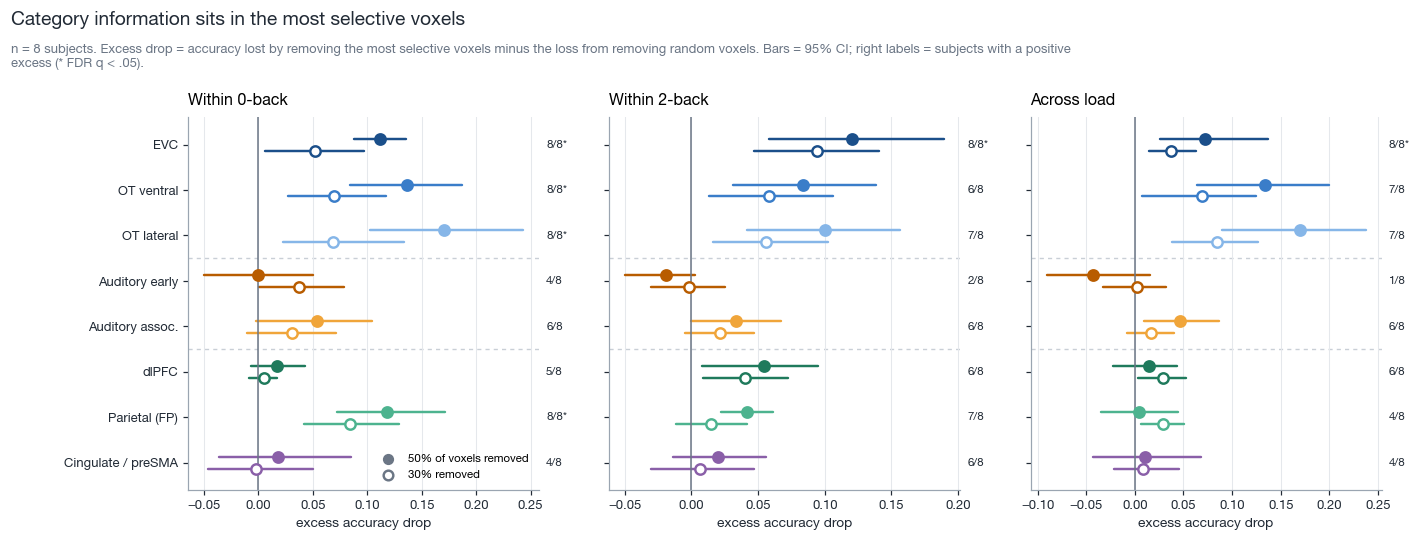

Excess accuracy drop from removing the most selective voxels, beyond random removal (positive = information concentrated in them)
     outcome         roi  fraction  selective_drop  random_drop  excess_drop  ci_lo  ci_hi  n_pos  n_subjects  p_signflip  q_fdr
within_0back         EVC       0.3           0.049       -0.003        0.052  0.006  0.097      6           8       0.097  0.179
within_0back         EVC       0.5           0.109       -0.003        0.112  0.088  0.136      8           8       0.008  0.049
within_0back  OT_ventral       0.3           0.065       -0.004        0.070  0.027  0.117      7           8       0.023  0.078
within_0back  OT_ventral       0.5           0.133       -0.004        0.137  0.085  0.187      8           8       0.008  0.049
within_0back  OT_lateral       0.3           0.063       -0.006        0.069  0.023  0.133      8           8       0.008  0.049
within_0back  OT_lateral       0.5           0.172        0.002        0.170  0.103  0.243      

In [37]:
# =============================================================================
# STAGE 12 - IS CATEGORY INFORMATION CONCENTRATED IN THE MOST SELECTIVE VOXELS?
# =============================================================================
# Turns the removal curves of Stage 7a into one number per subject: the EXCESS drop, which is the accuracy lost by
# removing the most category-selective grayordinates minus the accuracy lost by removing the same number at random.
# Subtracting the random-removal loss is what makes the comparison fair, because any removal costs accuracy.
#   excess clearly positive  the information lives in a small set of selective grayordinates (a localised code)
#   excess around zero       the information is spread across the region (a distributed code in Haxby's sense)
# Reported at 30% and 50% removal, with a sign-flip test and a bootstrap interval over subjects.
# Needs removal_df (Stage 7a).
if "removal_df" not in globals() or removal_df.empty:
    raise RuntimeError("Run the Haxby removal cell first (removal_df is missing or empty).")
OUTCOMES = [("within_0back", "Within 0-back"), ("within_2back", "Within 2-back"), ("cross_load", "Across load")]
roi_list = list(roi_masks)
ex_rows = []
for outcome, _ in OUTCOMES:
    for roi in roi_list:
        q = removal_df[(removal_df.roi == roi) & (removal_df.outcome == outcome)]
        base = q[q.removed_fraction == 0].set_index("subject").selective_removal
        for frac in (.3, .5):
            f = q[q.removed_fraction == frac].set_index("subject")
            if f.empty:
                continue
            excess = (base - f.selective_removal) - (base - f.random_removal)          # selective drop minus random drop (per subject)
            lo, hi = bootstrap_ci(excess.values)
            ex_rows.append(dict(outcome=outcome, roi=roi, fraction=frac, selective_drop=(base - f.selective_removal).mean(),
                                random_drop=(base - f.random_removal).mean(), excess_drop=excess.mean(), ci_lo=lo, ci_hi=hi,
                                n_pos=int((excess > 0).sum()), n_subjects=len(excess), p_signflip=signflip_mean_p(excess.values)))
removal_excess = pd.DataFrame(ex_rows)
removal_excess["q_fdr"] = bh_fdr(removal_excess.p_signflip.values)
note("Excess accuracy drop from removing the most selective voxels, beyond random removal (positive = information concentrated in them)")
note(removal_excess.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True, gridspec_kw=dict(wspace=.2))
for ax, (outcome, label) in zip(axes, OUTCOMES):
    ax.grid(False, axis="y"); ax.grid(True, axis="x"); ax.set_ylim(len(roi_list) - .4, -.6); group_dividers(ax, "y")
    for i, roi in enumerate(roi_list):
        for frac, dy, filled in ((.5, -.12, True), (.3, .14, False)):
            r = removal_excess[(removal_excess.outcome == outcome) & (removal_excess.roi == roi) & (removal_excess.fraction == frac)]
            if r.empty:
                continue
            r = r.iloc[0]
            ax.plot([r.ci_lo, r.ci_hi], [i + dy] * 2, color=ROI_COLORS[roi], lw=1.6, solid_capstyle="round")
            ax.scatter(r.excess_drop, i + dy, s=46, facecolor=ROI_COLORS[roi] if filled else "white", edgecolor=ROI_COLORS[roi], lw=1.6, zorder=3)
            if filled:
                ax.text(1.02, i, f"{r.n_pos}/{r.n_subjects}{stars(r.q_fdr)}", transform=ax.get_yaxis_transform(), fontsize=7.5, va="center",
                        fontweight="bold" if r.q_fdr < .05 else "normal", color=INK)
    ax.axvline(0, color=MUTED, lw=1); ax.set_title(label); ax.set_xlabel("excess accuracy drop")
axes[0].set_yticks(range(len(roi_list))); axes[0].set_yticklabels([ROI_NAME[r] for r in roi_list])
axes[0].scatter([], [], s=40, color=MUTED, label="50% of voxels removed"); axes[0].scatter([], [], s=40, facecolor="white", edgecolor=MUTED, lw=1.6, label="30% removed")
axes[0].legend(loc="lower right", fontsize=7.5)
fig_title(fig, "Category information sits in the most selective voxels",
          f"n = {len(SUBJECTS)} subjects. Excess drop = accuracy lost by removing the most selective voxels minus the loss from removing random voxels. "
          "Bars = 95% CI; right labels = subjects with a positive excess (* FDR q < .05).", y=1.1)
save_fig(fig, "selective_voxel_removal.png")
removal_excess.to_csv(os.path.join(NOVELTY_DIR, "removal_excess_drop.csv"), index=False)

show_notes()      # the tables above were queued while the cell ran; they are released here so that
                  # the figure, not the log, is what sits directly under the code.


## Stage 13 — Confirmatory checks on story-versus-math, especially in visual regions

Stage 5c decoded Story from Math at or near ceiling in almost every region, **including the visual ones**
(OT ventral 1.00, OT lateral 0.94, EVC 0.75). Read literally, that says early visual cortex can tell a spoken story
from spoken arithmetic, which is not a claim worth making on the strength of one accuracy number.

Two features of the design explain why that accuracy is so easy to get, and both are reasons for caution:

1. Each run contributes exactly two blocks, story and math. Once the within-run mean is removed they are exact
   mirror images, so a subject contributes **one direction in pattern space per run**, not two independent samples.
   The classifier only has to get the sign of a single group-mean difference pattern right — so a difference that is
   tiny but consistent in direction decodes at 1.00.
2. Story and Math differ in much more than language: arithmetic is harder, the blocks differ in length and in button
   pressing, and a brain-wide arousal or global-signal shift between them is entirely plausible. A global shift
   reaches every region, visual cortex included.

This stage therefore runs the same decoder four ways — the full pattern, the pattern with each block's ROI mean
removed, the ROI mean alone, and the pattern after the mean over all eight regions is removed — under two
cross-validation schemes, one of which never lets training and test data come from the same scanner run. Inference
is the **exact subject-level sign-flip test**, not the block permutation of Stage 5c, which is far too liberal when
two of the four samples are mirror images of the other two. The last panel adds the measurement a decoder cannot
give: how well a subject's own math-minus-story pattern reproduces between their two runs.

Only one combination would support a genuine visual story/math representation: *pattern only* still high, in a
visual region, and still high after global-signal removal.

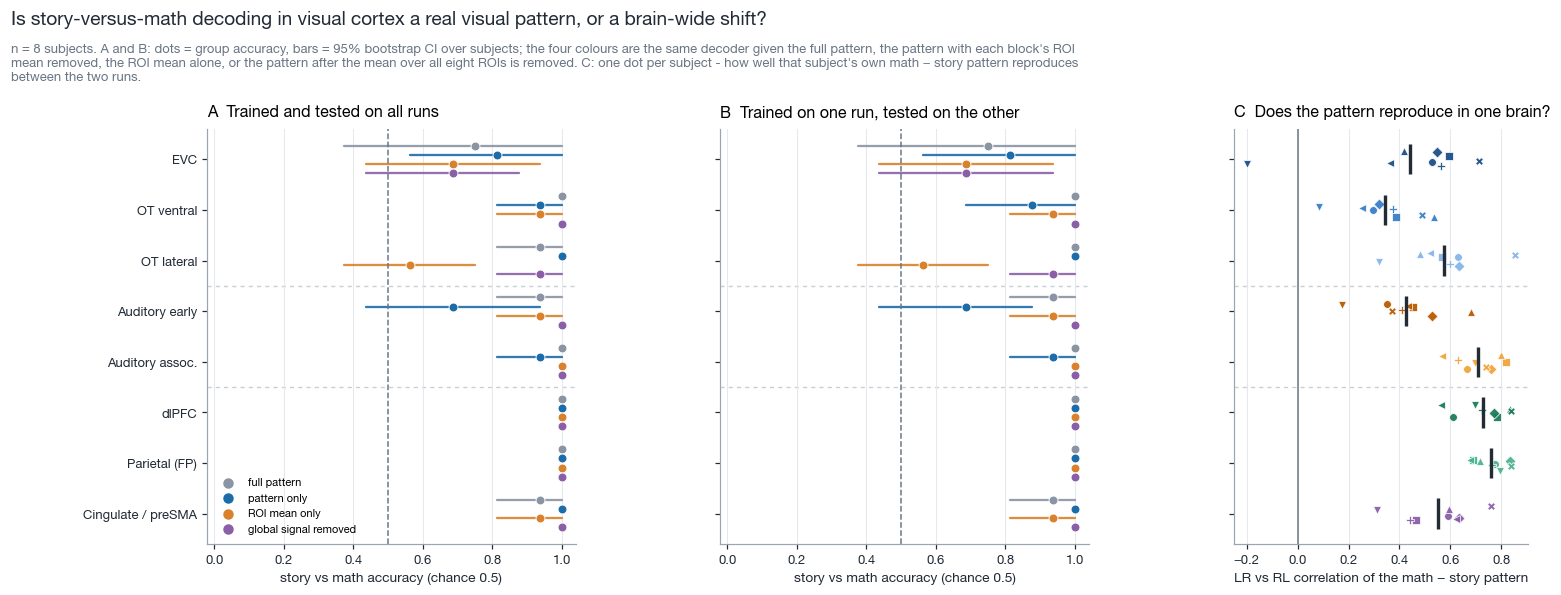

Story vs math, four versions x two cross-validation schemes (chance 0.50).
p = exact subject-level sign-flip test; q = BH-FDR within each scheme.
        roi               version    scheme  mean_acc  ci_lo  ci_hi  n_above_chance  n_subjects  p_two_sided  q_fdr
        EVC          full pattern  all runs     0.750  0.375  1.000               6           8        0.289  0.330
        EVC          full pattern cross-run     0.750  0.375  1.000               6           8        0.289  0.330
        EVC          pattern only  all runs     0.812  0.562  1.000               6           8        0.125  0.148
        EVC          pattern only cross-run     0.812  0.562  1.000               6           8        0.125  0.148
        EVC         ROI mean only  all runs     0.688  0.438  0.938               4           8        0.375  0.387
        EVC         ROI mean only cross-run     0.688  0.438  0.938               4           8        0.375  0.387
        EVC global signal removed  all run

In [38]:
# =============================================================================
# STAGE 13 - CONFIRMATORY CHECKS ON STORY-VERSUS-MATH, ESPECIALLY IN VISUAL REGIONS
# =============================================================================
# Why this cell exists. Stage 5c decoded Story from Math at or near ceiling in almost every ROI, including the
# visual ones (OT_ventral 1.00, OT_lateral 0.94, EVC 0.75). Taken at face value that would say early visual cortex
# distinguishes a spoken story from spoken arithmetic, which is not a claim we want to make on the strength of one
# accuracy. Before it goes in the report the number has to survive a set of harder tests.
#
# Two features of the Language design explain why that accuracy is so easy to obtain, and both are reasons for
# caution rather than for celebration:
#   1. Each run contributes exactly two samples, story and math. After the within-run mean is removed they are exact
#      mirror images (story = -math), so a subject contributes one direction in pattern space per run, not two
#      independent observations. A classifier only has to get the SIGN of a single group-mean difference pattern
#      right, so if the Math-minus-Story difference points the same way in most people, accuracy jumps to 1.00
#      regardless of how small or how uninteresting that difference is.
#   2. Story and Math blocks differ in far more than linguistic content: arithmetic is more demanding, the blocks
#      differ in length and in the amount of button pressing, and a whole-brain arousal or global-signal shift
#      between the two is entirely plausible. A global shift reaches every ROI, visual cortex included.
#
# The four versions below separate those explanations. Each is the SAME leave-one-subject-out decoder on the same
# blocks, differing only in what the classifier is allowed to see:
#   full pattern            the original analysis (spatial pattern and overall level together)
#   pattern only            each block's mean across the ROI's grayordinates is subtracted first, so only the
#                           spatial arrangement remains. Survives -> there is a genuine multivoxel difference
#   ROI mean only           the classifier sees ONE number per block, the ROI mean. Works -> the effect is a rise
#                           or fall of the whole region, not a pattern
#   global signal removed   the mean over ALL ROI grayordinates (our proxy for a brain-wide shift) is subtracted
#                           from every block first. If visual-ROI accuracy collapses here, it was riding on a
#                           global Story/Math difference and is not a visual representation of anything
#
# and two cross-validation schemes, because the schemes answer different questions:
#   all runs    train on every block of the other subjects, test on both blocks of the held-out subject
#   cross-run   train on the other subjects' LR blocks only and test the held-out subject's RL blocks (and the
#               reverse, averaged). Nothing the two sides share can come from the same scanner run, so a result
#               that survives this is not a run-specific artefact
#
# Inference is the exact subject-level sign-flip test (each subject's accuracy is exchangeable with 1 - accuracy),
# NOT the block-label permutation of Stage 5c. With two mirror-image samples per run the block permutation null is
# far too narrow, which is exactly the problem we hit with the cross-task decoder in Stage 10.
#
# Panel C adds the measurement that decoding cannot give: how reliable the Math-minus-Story pattern is within a
# subject (LR against RL). A region can be decoded at 1.00 across subjects while its own pattern barely reproduces
# between two runs of the same brain, and that combination is the signature of a weak but highly consistent
# difference - most likely a global one.
#
# Needs: get_patterns, roi_masks, _scale (Stage 5), _ridge_scores / _acc / subject_flip_pvalues (Stage 10),
# bootstrap_ci / bh_fdr (Stage 4) and the style cell.

LANG_VERSIONS = ("full pattern", "pattern only", "ROI mean only", "global signal removed")
LANG_SCHEMES = ("all runs", "cross-run")
N_PERM_LANG = N_PERM_GROUP          # only used for the sampled fallback inside subject_flip_pvalues

# Our stand-in for a brain-wide signal change: the union of all eight ROIs (about 17,000 grayordinates spread over
# visual, auditory and control cortex). A shift that is common to all of them is not specific to any one region.
UNION_MASK = np.any(np.vstack([roi_masks[r] for r in ROI_ORDER]), axis=0)


def language_version_dataset(roi, version):
    """Story / math blocks for every subject, transformed according to `version`.

    Rows per subject are LR-story, LR-math, RL-story, RL-math. The story/math mean is removed inside each run (as in
    prep_language), and features are then scaled using that subject's own samples only, so nothing about the held-out
    subject's labels can leak into training."""
    X, subj, run, y = [], [], [], []
    for si, sid in enumerate(SUBJECTS):
        P = get_patterns(sid)
        rows = []
        for ri, rn in enumerate(("LR", "RL")):
            M = P[f"LANGUAGE_{rn}_t"][:, roi_masks[roi]].astype(float)              # (2, V): row 0 story, row 1 math
            if version == "global signal removed":
                g = P[f"LANGUAGE_{rn}_t"][:, UNION_MASK].astype(float).mean(axis=1, keepdims=True)
                M = M - g                                                            # same number taken off every feature
            if version == "pattern only":
                M = M - M.mean(axis=1, keepdims=True)                                # this block's own ROI mean
            if version == "ROI mean only":
                M = M.mean(axis=1, keepdims=True)                                    # collapse the ROI to one number
            M = M - M.mean(axis=0, keepdims=True)                                    # centre story/math within the run
            rows.append(M)
            subj += [si, si]
            run += [ri, ri]
            y += [0, 1]
        X.append(_scale(np.vstack(rows)))
    return dict(X=np.vstack(X), subj=np.asarray(subj), run=np.asarray(run), y=np.asarray(y))


def loso_binary_accuracy(X, y, subj, train_sel, test_sel):
    """One accuracy per held-out subject for a two-class ridge decoder (same solver as Stage 10)."""
    out = []
    for s in np.unique(subj):
        tr = (subj != s) & train_sel
        te = (subj == s) & test_sel
        if tr.sum() == 0 or te.sum() == 0 or len(np.unique(y[tr])) < 2:
            out.append(np.nan)
            continue
        out.append(_acc(_ridge_scores(X[tr], y[tr], X[te]), y[te]))
    return np.asarray(out, float)


def language_scheme_accuracy(d, scheme):
    """`all runs`: train on all of the other subjects' blocks, test on both of the held-out subject's runs.
    `cross-run`: train on one run of the other subjects and test the OTHER run of the held-out subject, both
    directions averaged, so training and test data never come from the same scanner run."""
    allsel = np.ones(len(d["y"]), bool)
    if scheme == "all runs":
        return loso_binary_accuracy(d["X"], d["y"], d["subj"], allsel, allsel)
    a = loso_binary_accuracy(d["X"], d["y"], d["subj"], d["run"] == 0, d["run"] == 1)
    b = loso_binary_accuracy(d["X"], d["y"], d["subj"], d["run"] == 1, d["run"] == 0)
    return np.nanmean([a, b], axis=0)


# ---- 1 & 2. decode story vs math under every version and both cross-validation schemes ----
lang_check_rows, lang_check_acc = [], {}
for roi in ROI_ORDER:
    for version in LANG_VERSIONS:
        d = language_version_dataset(roi, version)
        for scheme in LANG_SCHEMES:
            acc = language_scheme_accuracy(d, scheme)
            lang_check_acc[(roi, version, scheme)] = acc
            p_one, p_two = subject_flip_pvalues(acc[np.isfinite(acc)])
            lo, hi = bootstrap_ci(acc - 0.5)
            lang_check_rows.append(dict(roi=roi, version=version, scheme=scheme, mean_acc=np.nanmean(acc),
                                        ci_lo=0.5 + lo, ci_hi=0.5 + hi, n_above_chance=int(np.nansum(acc > 0.5)),
                                        n_subjects=int(np.isfinite(acc).sum()), p_two_sided=p_two))
lang_check = pd.DataFrame(lang_check_rows)
# FDR is applied inside each cross-validation scheme, because the two schemes answer different questions and are not
# one family of tests.
lang_check["q_fdr"] = np.nan
for scheme, idx in lang_check.groupby("scheme").groups.items():
    lang_check.loc[idx, "q_fdr"] = bh_fdr(lang_check.loc[idx, "p_two_sided"].values)

# ---- 3. how reliable is the Math-minus-Story pattern inside one brain? (LR against RL) ----
lang_rel_rows = []
for sid in SUBJECTS:
    P = get_patterns(sid)
    for roi in ROI_ORDER:
        m = roi_masks[roi]
        dLR = (P["LANGUAGE_LR_t"][1] - P["LANGUAGE_LR_t"][0])[m].astype(float)       # math minus story, LR run
        dRL = (P["LANGUAGE_RL_t"][1] - P["LANGUAGE_RL_t"][0])[m].astype(float)       # math minus story, RL run
        keep = (np.abs(dLR) + np.abs(dRL)) > 0
        r_full = float(np.corrcoef(dLR[keep], dRL[keep])[0, 1])
        # the same reliability after each run's ROI mean is taken out, i.e. the reliability of the PATTERN alone
        pLR, pRL = dLR[keep] - dLR[keep].mean(), dRL[keep] - dRL[keep].mean()
        r_pattern = float(np.corrcoef(pLR, pRL)[0, 1])
        lang_rel_rows.append(dict(subject=sid, roi=roi, r_cross_run=r_full, r_cross_run_pattern=r_pattern,
                                  roi_mean_math_minus_story=float(0.5 * (dLR.mean() + dRL.mean()))))
lang_reliability = pd.DataFrame(lang_rel_rows)

lang_rel_group = []
for roi in ROI_ORDER:
    g = lang_reliability[lang_reliability.roi == roi]
    z = np.arctanh(np.clip(g.r_cross_run.values, -0.999, 0.999))                     # Fisher z before averaging r
    lo, hi = bootstrap_ci(z)
    amp = g.roi_mean_math_minus_story.values
    lang_rel_group.append(dict(roi=roi, mean_r=float(np.tanh(z.mean())), ci_lo=float(np.tanh(lo)),
                               ci_hi=float(np.tanh(hi)), n_positive=int((g.r_cross_run.values > 0).sum()),
                               mean_r_pattern=float(np.tanh(np.arctanh(np.clip(g.r_cross_run_pattern.values, -.999, .999)).mean())),
                               roi_mean_diff=float(amp.mean()), n_subjects=len(g),
                               p_signflip=signflip_mean_p(z), p_signflip_roi_mean=signflip_mean_p(amp)))
lang_rel_group = pd.DataFrame(lang_rel_group)
lang_rel_group["q_fdr"] = bh_fdr(lang_rel_group.p_signflip.values)

# ---- verdict per ROI: what does the story-vs-math result in this region actually rest on? ----
lang_verdict_rows = []
for roi in ROI_ORDER:
    def _acc_of(version, scheme="cross-run"):
        r = lang_check[(lang_check.roi == roi) & (lang_check.version == version) & (lang_check.scheme == scheme)]
        return float(r.mean_acc.iloc[0]), float(r.q_fdr.iloc[0]), int(r.n_above_chance.iloc[0]), int(r.n_subjects.iloc[0])
    full_a, _, _, n = _acc_of("full pattern")
    pat_a, pat_q, pat_k, _ = _acc_of("pattern only")
    mean_a, _, mean_k, _ = _acc_of("ROI mean only")
    glob_a, _, _, _ = _acc_of("global signal removed")
    # "works" uses the same descriptive rule as Stage 10a: a clear effect in most subjects, not just a high mean.
    works = lambda a, k: bool(a >= 0.60 and k >= int(np.ceil(0.75 * n)))
    pw, mw = works(pat_a, pat_k), works(mean_a, mean_k)
    survives_global = bool(glob_a >= 0.60 and full_a - glob_a <= 0.15)
    verdict = ("shared PATTERN + level (redundant)" if pw and mw else
               "spatial PATTERN" if pw else
               "activation LEVEL only" if mw else "no reliable story/math separation")
    lang_verdict_rows.append(dict(roi=roi, family=ROI_GROUP[roi], acc_full=full_a, acc_pattern_only=pat_a,
                                 acc_mean_only=mean_a, acc_global_removed=glob_a,
                                 survives_global_removal=survives_global,
                                 cross_run_pattern_reliability=float(lang_rel_group[lang_rel_group.roi == roi].mean_r.iloc[0]),
                                 verdict=verdict))
lang_verdict = pd.DataFrame(lang_verdict_rows)

# ---- figure (drawn before any text, so the panels are the first thing seen) ----
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.9), gridspec_kw=dict(width_ratios=[1.25, 1.25, 1], wspace=0.42))
ver_colors = {"full pattern": C_FULL, "pattern only": C_PATTERN, "ROI mean only": C_MEAN, "global signal removed": "#8A5FA8"}
for ax, scheme in zip(axes[:2], LANG_SCHEMES):
    ax.grid(False, axis="y"); ax.grid(True, axis="x")
    ax.set_ylim(len(ROI_ORDER) - .4, -.6)
    group_dividers(ax, "y")
    for i, roi in enumerate(ROI_ORDER):
        for k, version in enumerate(LANG_VERSIONS):
            r = lang_check[(lang_check.roi == roi) & (lang_check.version == version) & (lang_check.scheme == scheme)].iloc[0]
            yv = i + (k - 1.5) * .18
            ax.plot([r.ci_lo, r.ci_hi], [yv, yv], color=ver_colors[version], lw=1.5, solid_capstyle="round", alpha=.9)
            ax.scatter(r.mean_acc, yv, s=34, color=ver_colors[version], edgecolor="white", lw=.6, zorder=3)
    ax.axvline(.5, color=MUTED, ls="--", lw=1)
    ax.set_xlim(-.02, 1.04)      # a two-class accuracy can legitimately fall to 0, so do not clip the low end
    ax.set_xlabel("story vs math accuracy (chance 0.5)")
    ax.set_title(("A  Trained and tested on all runs" if scheme == "all runs" else
                  "B  Trained on one run, tested on the other"))
axes[0].set_yticks(range(len(ROI_ORDER))); axes[0].set_yticklabels([ROI_NAME[r] for r in ROI_ORDER])
axes[1].set_yticks(range(len(ROI_ORDER))); axes[1].set_yticklabels([])
for version in LANG_VERSIONS:
    axes[0].scatter([], [], s=34, color=ver_colors[version], label=version)
axes[0].legend(loc="lower left", fontsize=7.2, ncol=1)

ax = axes[2]
ax.grid(False, axis="y"); ax.grid(True, axis="x")
ax.set_ylim(len(ROI_ORDER) - .4, -.6)
group_dividers(ax, "y")
for i, roi in enumerate(ROI_ORDER):
    v = lang_reliability[lang_reliability.roi == roi].r_cross_run.values
    strip(ax, i, v, ROI_COLORS[roi], seed=i, subjects=SUBJECTS, size=26, horizontal=True)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels([])
ax.set_xlabel("LR vs RL correlation of the math − story pattern")
ax.set_title("C  Does the pattern reproduce in one brain?")
fig_title(fig, "Is story-versus-math decoding in visual cortex a real visual pattern, or a brain-wide shift?",
          f"n = {len(SUBJECTS)} subjects. A and B: dots = group accuracy, bars = 95% bootstrap CI over subjects; the four colours are the same decoder "
          "given the full pattern, the pattern with each block's ROI mean removed, the ROI mean alone, or the pattern after the mean over all eight ROIs "
          "is removed. C: one dot per subject - how well that subject's own math − story pattern reproduces between the two runs.", y=1.10)
save_fig(fig, "language_story_math_confirmatory.png")

# ---- tables and the reasoning, printed after the figure ----
print("Story vs math, four versions x two cross-validation schemes (chance 0.50).")
print("p = exact subject-level sign-flip test; q = BH-FDR within each scheme.")
print(lang_check.round(3).to_string(index=False))
print("\nReliability of the math − story pattern within a subject (LR vs RL), and the ROI-mean difference:")
print(lang_rel_group.round(3).to_string(index=False))
print("\nWhat the story/math result rests on, by ROI (cross-run scheme, the stricter one):")
print(lang_verdict.round(3).to_string(index=False))
print("\nHow to read this:")
print(" - 'pattern only' still high in a VISUAL ROI, and still high after global-signal removal, would be the only")
print("   combination that supports a genuine visual story/math representation.")
print(" - 'ROI mean only' as high as the full pattern says the region simply goes up or down between the two")
print("   conditions. That is a plausible attention / arousal / global-signal effect and is NOT evidence that the")
print("   region represents linguistic content.")
print(" - A large drop from 'full pattern' to 'global signal removed' in visual ROIs is the clearest sign that the")
print("   ceiling-level accuracy of Stage 5c was carried by a brain-wide difference between Story and Math blocks.")
print(" - Panel C is the sanity check the decoder cannot provide: with only two mirror-image samples per run, a")
print("   consistent-but-tiny difference decodes at 1.00 across subjects. A low cross-run reliability next to a")
print("   perfect accuracy means 'consistent in direction, weak in size', which should be reported as such.")
print(f"\nNote on the design: after the within-run mean is removed, story = −math exactly, so each subject contributes")
print(f"two directions in pattern space (one per run), not four samples. The smallest attainable two-sided p from the")
print(f"subject-level sign-flip test is therefore {2 / 2 ** len(SUBJECTS):.4f} with {len(SUBJECTS)} subjects.")

lang_check.to_csv(os.path.join(NOVELTY_DIR, "language_story_math_confirmatory.csv"), index=False)
lang_reliability.to_csv(os.path.join(NOVELTY_DIR, "language_pattern_reliability_subject_level.csv"), index=False)
lang_rel_group.to_csv(os.path.join(NOVELTY_DIR, "language_pattern_reliability_group.csv"), index=False)
lang_verdict.to_csv(os.path.join(NOVELTY_DIR, "language_story_math_verdict.csv"), index=False)

## Stage 14 — The parietal category code: four checks on the one non-visual region that has one

FP parietal is the most interesting result in the project and therefore the one that deserves the most scepticism.
It is the **only region outside visual cortex** where stimulus category is decodable, it is decodable in all four
load pairings (0.52, 0.48, 0.42, 0.52; every $q \le 0.006$), and it has both the smallest loss across load
(+0.03, 95% CI [−0.02, +0.09]) and the only loss that passes the equivalence test ($p_{\mathrm{TOST}} = 0.025$),
with a retention of 0.88. A category code in control cortex that barely cares about memory load is exactly what an
abstract, load-independent stimulus code should look like.

Before that is written down, four ordinary explanations have to be removed, one per panel:

1. **Which categories?** A four-way decoder can be above chance while separating only faces from places. All six
   category pairs are decoded separately. (The Stage 11a recall table already hinted at this: faces 0.69,
   places 0.69, tools 0.38, body 0.25.)
2. **Pattern or activation level?** Removing each block's ROI mean leaves only the spatial arrangement; the
   mean-only decoder is the mirror test.
3. **Spillover from vision?** Intraparietal cortex borders V3A/V7. Grayordinates are split at the median of their
   overall response to the pictures, and a code surviving in the *least* driven half cannot be leakage.
4. **Just a bigger region?** Every region is subsampled to the same number of grayordinates. (FP dlPFC already has
   *more* features and no category code, so size was never a likely story.)
A fifth check — comparing parietal and visual category geometry with a Mantel test — was dropped. With six
category pairs per RDM it has almost no power: in the version that was run, no comparison came close to
significance ($p = 0.126$ to $0.631$), so it could separate an inherited code from an independent one in neither
direction. Whether parietal cortex echoes the visual geometry is carried into the report as an open question, not
as a null result.

None of this re-tests whether the code exists — Stage 5b did that with a permutation test. These checks decide how
the result should be **described**.

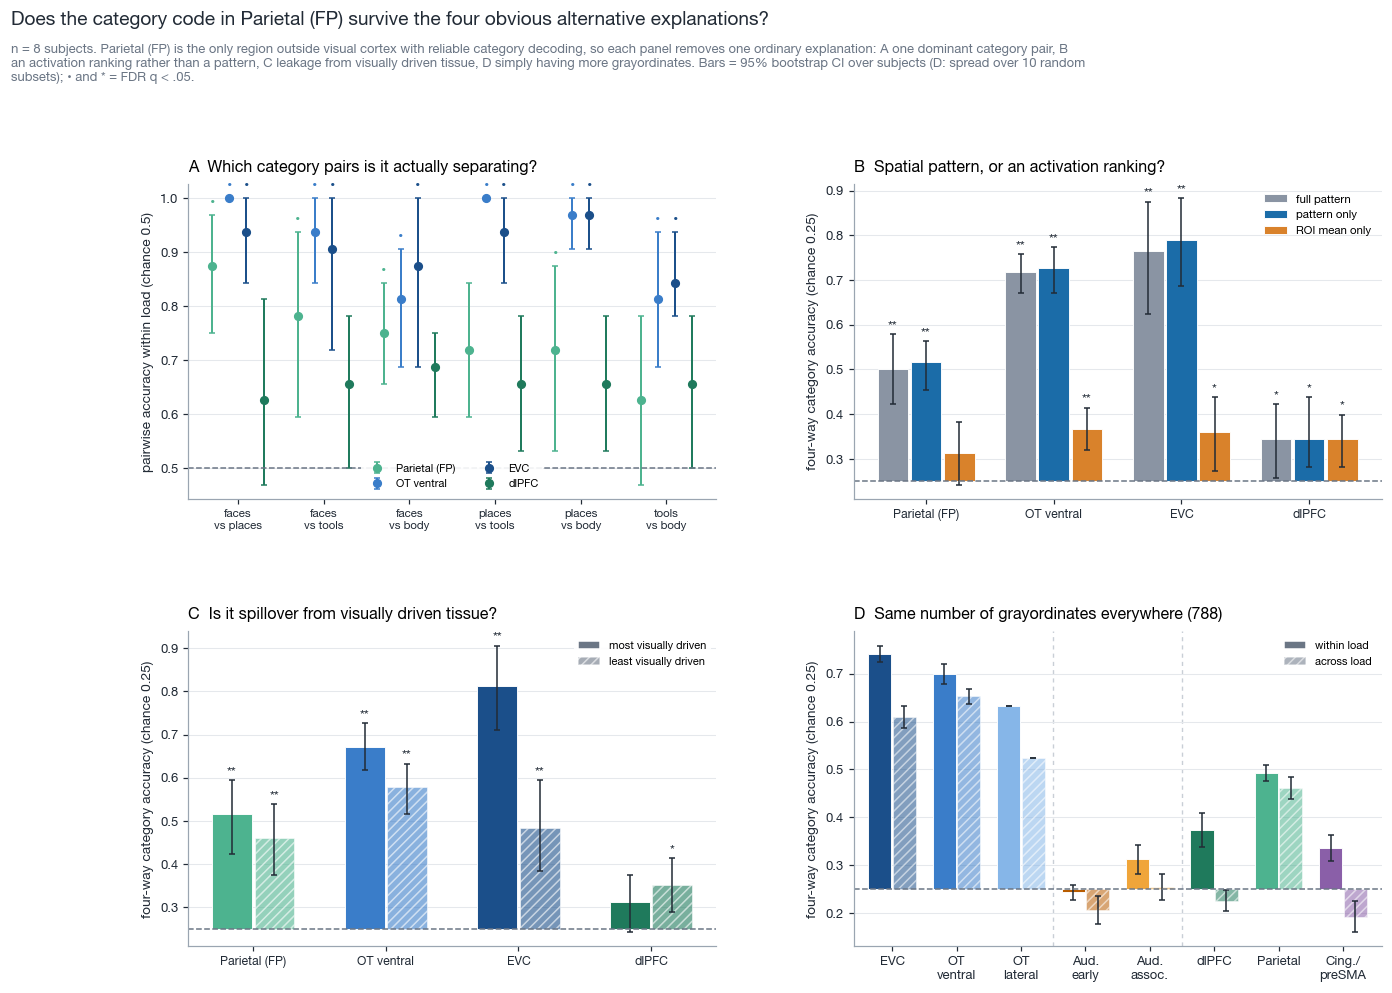

CHECK 1 - pairwise category decoding, all six pairs (chance 0.50), FP_parietal and reference regions:
        roi            pair        kind  chance  mean_acc  ci_lo  ci_hi  n_above_chance  n_subjects  p_perm  q_fdr
FP_parietal faces vs places within load     0.5     0.875  0.750  0.969               7           8   0.003  0.006
FP_parietal faces vs places across load     0.5     0.875  0.750  0.969               7           8   0.003  0.006
FP_parietal  faces vs tools within load     0.5     0.781  0.594  0.938               6           8   0.010  0.017
FP_parietal  faces vs tools across load     0.5     0.562  0.500  0.688               1           8   0.346  0.405
FP_parietal   faces vs body within load     0.5     0.750  0.656  0.844               7           8   0.023  0.037
FP_parietal   faces vs body across load     0.5     0.594  0.438  0.750               3           8   0.259  0.311
FP_parietal places vs tools within load     0.5     0.719  0.594  0.844               5      

In [39]:
# =============================================================================
# STAGE 14 - THE PARIETAL CATEGORY CODE: four checks on the one non-visual region that has one
# =============================================================================
# Why this cell exists. In Stage 5b, FP_parietal is the only region outside visual cortex where stimulus category is
# decodable, and it is decodable in all four load pairings (0.52, 0.48, 0.42, 0.52; every q <= 0.006). It is also
# the region with the smallest loss across load (+0.03, 95% CI [-0.02, +0.09]) and the only one whose loss passes
# the equivalence test (TOST p = 0.025), with a retention of 0.88. If that holds up it is the most interesting
# result in the project: a category code in control cortex that barely cares about memory load, which is what an
# abstract, load-independent stimulus code should look like.
#
# "If it holds up" is the whole point of this cell. A category effect in parietal cortex has four boring
# explanations that have to be ruled out one at a time, and each check below targets exactly one of them.
#
#   Check 1  WHICH categories?            A region can be above chance overall while really only separating faces
#            (pairwise decoding)          from places. Decoding all six category pairs separately says whether the
#                                         code is a genuine four-way code or one or two dominant contrasts. The
#                                         Stage 11a recall table already hinted at this (faces 0.69, places 0.69,
#                                         tools 0.38, body 0.25), so the pairwise test makes it explicit.
#   Check 2  PATTERN or activation level? The region could simply be more active for some categories than others.
#            (pattern vs ROI mean)        Removing each block's ROI mean leaves only the spatial arrangement; if
#                                         accuracy survives that, the code is multivoxel. The ROI-mean-only decoder
#                                         is the mirror test: if it works on its own, the "code" is an amplitude
#                                         ranking of the four categories, not a representation.
#   Check 3  Is it spillover from vision? Parietal ROIs border visual cortex (IPS0/IPS1 sit next to V3A/V7), and
#            (visual-drive split)         MSMAll alignment plus the smoothness of the data could let a strong
#                                         occipital category signal leak in. Grayordinates are split at the median
#                                         of their overall WM response: the half that responds most to the pictures
#                                         (most likely to be visually driven, most likely to be contaminated) and
#                                         the half that responds least. A code present in the LOW-drive half cannot
#                                         be explained by leakage from visually driven tissue. The split uses the
#                                         mean over all eight conditions, which prep_category removes, so the
#                                         selection carries no information about the category labels themselves.
#   Check 4  Is it just a bigger ROI?     FP_parietal has 2,460 grayordinates against 788 in OT_lateral, and more
#            (feature-count matching)     features generally means more accuracy. Every ROI is subsampled to the
#                                         same number of features, several times, and category decoding repeated.
#                                         If FP_parietal still stands out among the non-visual ROIs, size is not
#                                         the explanation. (Note that FP_dlpfc has MORE features and shows no
#                                         category code, which already argues against the size story.)
# A fifth check - comparing parietal and visual category geometry with a Mantel test - was dropped: with six
# category pairs per RDM that test has almost no power, and in the version that was run no comparison came close
# to significance (p = 0.126 to 0.631), so it could not distinguish an inherited code from an independent one
# either way. It is listed as an open question in the report rather than reported as a null result.
#
# Nothing here is a new hypothesis test of "is there a category code in parietal cortex" - Stage 5b already answered
# that with a permutation test. These are the controls that decide how the answer should be DESCRIBED.
#
# Needs: wm_category_dataset / _task_getter / _MODELS / _perm_p_mean (Stage 11a), LosoModel / permutation_test /
# prep_category / _scale (Stage 5) and the style cell.

from matplotlib.patches import Patch      # neutral legend handles: the bars are ROI-coloured, so a legend built
                                          # from them would show one region's colour for every region

FOCUS_ROI = "FP_parietal"
# Reference regions: the strongest visual category region, the low-level visual control, and the other
# frontoparietal region, which has MORE grayordinates but no category code.
REF_ROIS = [r for r in ("OT_ventral", "EVC", "FP_dlpfc") if r in roi_masks]
PAR_ROIS = [FOCUS_ROI] + REF_ROIS
CAT_PAIRS = [(a, b) for a in range(4) for b in range(a + 1, 4)]      # faces/places, faces/tools, ... 6 pairs
N_PERM_PAR = 300
N_MATCH_DRAWS = 10                                                  # random feature subsets for Check 4


def _loso_models_for(d):
    """The four train/test combinations of load, from a dataset built by wm_category_dataset."""
    K = d["X"] @ d["X"].T
    return {n: LosoModel(K, d["subj"], d["load"] == a, d["load"] == b) for n, (a, b) in _MODELS.items()}


def _within_across(models, y, groups, chance, n_perm=N_PERM_PAR, seed=23):
    """Mean accuracy within load (0->0 and 2->2) and across load (0->2 and 2->0), each with a permutation p."""
    out = {}
    for kind, names in (("within load", ("0->0", "2->2")), ("across load", ("0->2", "2->0"))):
        acc = np.mean([models[n].accuracy(y) for n in names], axis=0)
        p = _perm_p_mean([models[n] for n in names], y, groups, n_perm, seed=seed)
        lo, hi = bootstrap_ci(acc - chance)
        out[kind] = dict(acc=acc, mean_acc=acc.mean(), excess=acc.mean() - chance, ci_lo=chance + lo,
                         ci_hi=chance + hi, n_above=int((acc > chance).sum()), p_perm=p)
    return out


# ---- Check 1: all six category pairs, within and across load ----
pair_rows = []
for roi in PAR_ROIS:
    for (a, b) in CAT_PAIRS:
        d = wm_category_dataset(_task_getter, roi, [a, b])
        groups = d["subj"] * 100 + d["run"] * 10 + d["load"]
        res = _within_across(_loso_models_for(d), d["y"], groups, 0.5)
        for kind, r in res.items():
            pair_rows.append(dict(roi=roi, pair=f"{CATS[a]} vs {CATS[b]}", kind=kind, chance=0.5,
                                  mean_acc=r["mean_acc"], ci_lo=r["ci_lo"], ci_hi=r["ci_hi"],
                                  n_above_chance=r["n_above"], n_subjects=len(r["acc"]), p_perm=r["p_perm"]))
par_pairs = pd.DataFrame(pair_rows)
par_pairs["q_fdr"] = bh_fdr(par_pairs.p_perm.values)

# ---- Check 2: full pattern versus ROI mean, four-way category decoding ----
def category_dataset_version(roi, version):
    """Four-way category dataset with the same centring as prep_category, but with the ROI mean handled three ways:
    kept (full pattern), removed from every block (pattern only), or used as the single feature (ROI mean only)."""
    X, subj, run, load, y = [], [], [], [], []
    for si, sid in enumerate(SUBJECTS):
        blocks = []
        for ri, rn in enumerate(("LR", "RL")):
            M = get_patterns(sid)[f"WM_{rn}_t"][:, roi_masks[roi]].astype(float)      # (8, V)
            if version == "pattern only":
                M = M - M.mean(axis=1, keepdims=True)
            elif version == "ROI mean only":
                M = M.mean(axis=1, keepdims=True)
            for L in (0, 1):
                R = M[L * 4:(L + 1) * 4]
                blocks.append(R - R.mean(axis=0, keepdims=True))                      # remove the 4-category mean
                subj += [si] * 4; run += [ri] * 4; load += [L] * 4; y += list(range(4))
        X.append(_scale(np.vstack(blocks)))
    return dict(X=np.vstack(X), subj=np.asarray(subj), run=np.asarray(run), load=np.asarray(load), y=np.asarray(y))


par_version_rows = []
for roi in PAR_ROIS:
    for version in ("full pattern", "pattern only", "ROI mean only"):
        d = category_dataset_version(roi, version)
        groups = d["subj"] * 100 + d["run"] * 10 + d["load"]
        res = _within_across(_loso_models_for(d), d["y"], groups, 0.25, seed=24)
        for kind, r in res.items():
            par_version_rows.append(dict(roi=roi, version=version, kind=kind, mean_acc=r["mean_acc"],
                                         ci_lo=r["ci_lo"], ci_hi=r["ci_hi"], n_above_chance=r["n_above"],
                                         n_subjects=len(r["acc"]), p_perm=r["p_perm"]))
par_versions = pd.DataFrame(par_version_rows)
par_versions["q_fdr"] = bh_fdr(par_versions.p_perm.values)

# ---- Check 3: split FP_parietal by how strongly each grayordinate responds to the pictures ----
# Visual drive = mean t over all eight WM conditions, averaged over runs and subjects. prep_category removes the
# mean over the four categories, so this ranking cannot carry information about which category a block was.
drive_rows = []
for roi in PAR_ROIS:
    m = roi_masks[roi]
    drive = np.mean([get_patterns(sid)[f"WM_{rn}_t"][:, m].astype(float).mean(axis=0)
                     for sid in SUBJECTS for rn in ("LR", "RL")], axis=0)             # (V,) overall task response
    median_drive = np.median(drive)
    halves = {"most visually driven": drive >= median_drive, "least visually driven": drive < median_drive}
    for half_name, sel in halves.items():
        sub_mask = np.zeros_like(m)
        sub_mask[np.where(m)[0][sel]] = True                                          # a mask over all grayordinates
        getter = lambda sid, rn, _roi, _sm=sub_mask: get_patterns(sid)[f"WM_{rn}_t"][:, _sm]
        d = wm_category_dataset(getter, roi, [0, 1, 2, 3])
        groups = d["subj"] * 100 + d["run"] * 10 + d["load"]
        res = _within_across(_loso_models_for(d), d["y"], groups, 0.25, seed=25)
        for kind, r in res.items():
            drive_rows.append(dict(roi=roi, half=half_name, kind=kind, n_features=int(sel.sum()),
                                   mean_drive=float(drive[sel].mean()), mean_acc=r["mean_acc"], ci_lo=r["ci_lo"],
                                   ci_hi=r["ci_hi"], n_above_chance=r["n_above"], p_perm=r["p_perm"]))
par_drive = pd.DataFrame(drive_rows)
par_drive["q_fdr"] = bh_fdr(par_drive.p_perm.values)

# ---- Check 4: give every ROI the same number of features ----
N_MATCH = int(min(int(roi_masks[r].sum()) for r in ROI_ORDER))
rng_match = np.random.default_rng(NOVELTY_SEED + 31)
match_rows = []
for roi in ROI_ORDER:
    idx_all = np.where(roi_masks[roi])[0]
    accs_within, accs_across = [], []
    for draw in range(N_MATCH_DRAWS):
        take = rng_match.choice(idx_all, size=min(N_MATCH, len(idx_all)), replace=False)
        sub_mask = np.zeros(len(roi_masks[roi]), bool)
        sub_mask[take] = True
        getter = lambda sid, rn, _roi, _sm=sub_mask: get_patterns(sid)[f"WM_{rn}_t"][:, _sm]
        d = wm_category_dataset(getter, roi, [0, 1, 2, 3])
        models = _loso_models_for(d)
        accs_within.append(np.mean([models[n].accuracy(d["y"]) for n in ("0->0", "2->2")], axis=0).mean())
        accs_across.append(np.mean([models[n].accuracy(d["y"]) for n in ("0->2", "2->0")], axis=0).mean())
    match_rows.append(dict(roi=roi, family=ROI_GROUP[roi], n_features_full=int(roi_masks[roi].sum()),
                           n_features_matched=min(N_MATCH, len(idx_all)), n_draws=N_MATCH_DRAWS,
                           within_load_acc=float(np.mean(accs_within)), within_load_sd=float(np.std(accs_within)),
                           across_load_acc=float(np.mean(accs_across)), across_load_sd=float(np.std(accs_across))))
par_matched = pd.DataFrame(match_rows)

# ---- figure: the four decoding checks on one page (drawn before any printed text) ----
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw=dict(hspace=.42, wspace=.26))

# A: the six category pairs in each region
ax = axes[0, 0]
ax.grid(False, axis="x"); ax.grid(True, axis="y")
pair_names = [f"{CATS[a]} vs {CATS[b]}" for a, b in CAT_PAIRS]
xs = np.arange(len(pair_names))
for k, roi in enumerate(PAR_ROIS):
    q = par_pairs[(par_pairs.roi == roi) & (par_pairs.kind == "within load")].set_index("pair").loc[pair_names]
    off = (k - (len(PAR_ROIS) - 1) / 2) * .2
    ax.errorbar(xs + off, q.mean_acc, yerr=[np.maximum(q.mean_acc - q.ci_lo, 0), np.maximum(q.ci_hi - q.mean_acc, 0)], fmt="o", ms=5,
                color=ROI_COLORS[roi], ecolor=ROI_COLORS[roi], lw=1.3, capsize=2, label=ROI_NAME[roi])
    for x, (_, row) in zip(xs + off, q.iterrows()):
        if row.q_fdr < .05:
            ax.text(x, row.ci_hi + .015, "•", ha="center", fontsize=10, color=ROI_COLORS[roi])
ax.axhline(.5, color=MUTED, ls="--", lw=1)
ax.set_xticks(xs); ax.set_xticklabels([p.replace(" vs ", "\nvs ") for p in pair_names], fontsize=7.5)
ax.set_ylabel("pairwise accuracy within load (chance 0.5)")
ax.legend(fontsize=7.2, ncol=2, loc="best", frameon=True, facecolor="white", framealpha=.9, edgecolor="none")
ax.set_title("A  Which category pairs is it actually separating?")

# B: full pattern vs pattern-only vs ROI-mean-only
ax = axes[0, 1]
ax.grid(False, axis="x"); ax.grid(True, axis="y")
vcol = {"full pattern": C_FULL, "pattern only": C_PATTERN, "ROI mean only": C_MEAN}
xs = np.arange(len(PAR_ROIS))
for k, version in enumerate(("full pattern", "pattern only", "ROI mean only")):
    q = par_versions[(par_versions.version == version) & (par_versions.kind == "within load")].set_index("roi").loc[PAR_ROIS]
    off = (k - 1) * .26
    ax.bar(xs + off, q.mean_acc - .25, .24, bottom=.25, color=vcol[version], edgecolor="white", lw=.6, label=version)
    ax.errorbar(xs + off, q.mean_acc, yerr=[np.maximum(q.mean_acc - q.ci_lo, 0), np.maximum(q.ci_hi - q.mean_acc, 0)], fmt="none", ecolor=INK, lw=1, capsize=2)
    for x, (_, row) in zip(xs + off, q.iterrows()):
        ax.text(x, row.ci_hi + .012, stars(row.q_fdr), ha="center", fontsize=9, color=INK)
ax.axhline(.25, color=MUTED, ls="--", lw=1)
ax.set_xticks(xs); ax.set_xticklabels([ROI_NAME[r] for r in PAR_ROIS], fontsize=8)
ax.set_ylabel("four-way category accuracy (chance 0.25)")
ax.legend(fontsize=7.5, loc="upper right")
ax.set_title("B  Spatial pattern, or an activation ranking?")

# C: visually driven half against the rest
ax = axes[1, 0]
ax.grid(False, axis="x"); ax.grid(True, axis="y")
xs = np.arange(len(PAR_ROIS))
for k, (half, hatch) in enumerate((("most visually driven", None), ("least visually driven", "////"))):
    q = par_drive[(par_drive.half == half) & (par_drive.kind == "within load")].set_index("roi").loc[PAR_ROIS]
    off = (k - .5) * .32
    ax.bar(xs + off, q.mean_acc - .25, .3, bottom=.25, color=[ROI_COLORS[r] for r in PAR_ROIS], alpha=1.0 if k == 0 else .6,
           hatch=hatch, edgecolor="white", lw=.6)
    ax.errorbar(xs + off, q.mean_acc, yerr=[np.maximum(q.mean_acc - q.ci_lo, 0), np.maximum(q.ci_hi - q.mean_acc, 0)], fmt="none", ecolor=INK, lw=1, capsize=2)
    for x, (_, row) in zip(xs + off, q.iterrows()):
        ax.text(x, row.ci_hi + .012, stars(row.q_fdr), ha="center", fontsize=9, color=INK)
ax.axhline(.25, color=MUTED, ls="--", lw=1)
ax.set_xticks(xs); ax.set_xticklabels([ROI_NAME[r] for r in PAR_ROIS], fontsize=8)
ax.set_ylabel("four-way category accuracy (chance 0.25)")
ax.legend(handles=[Patch(facecolor=MUTED, edgecolor="white", label="most visually driven"),
                   Patch(facecolor=MUTED, edgecolor="white", alpha=.6, hatch="////", label="least visually driven")],
          fontsize=7.2, loc="upper right", frameon=True, facecolor="white", framealpha=.9, edgecolor="none")
ax.set_title("C  Is it spillover from visually driven tissue?")

# D: every ROI cut down to the same number of grayordinates
ax = axes[1, 1]
ax.grid(False, axis="x"); ax.grid(True, axis="y")
xs = np.arange(len(ROI_ORDER))
q = par_matched.set_index("roi").loc[ROI_ORDER]
ax.bar(xs - .19, q.within_load_acc - .25, .36, bottom=.25, color=[ROI_COLORS[r] for r in ROI_ORDER],
       edgecolor="white", lw=.6)
ax.bar(xs + .19, q.across_load_acc - .25, .36, bottom=.25, color=[ROI_COLORS[r] for r in ROI_ORDER], alpha=.55,
       hatch="////", edgecolor="white", lw=.6)
ax.errorbar(xs - .19, q.within_load_acc, yerr=q.within_load_sd, fmt="none", ecolor=INK, lw=1, capsize=2)
ax.errorbar(xs + .19, q.across_load_acc, yerr=q.across_load_sd, fmt="none", ecolor=INK, lw=1, capsize=2)
ax.axhline(.25, color=MUTED, ls="--", lw=1)
group_dividers(ax, "x")
roi_ticks(ax, "x")
ax.set_ylabel("four-way category accuracy (chance 0.25)")
ax.legend(handles=[Patch(facecolor=MUTED, edgecolor="white", label="within load"),
                   Patch(facecolor=MUTED, edgecolor="white", alpha=.55, hatch="////", label="across load")],
          fontsize=7.2, loc="upper right", frameon=True, facecolor="white", framealpha=.9, edgecolor="none")
ax.set_title(f"D  Same number of grayordinates everywhere ({N_MATCH})")

fig_title(fig, f"Does the category code in {ROI_NAME[FOCUS_ROI]} survive the four obvious alternative explanations?",
          f"n = {len(SUBJECTS)} subjects. {ROI_NAME[FOCUS_ROI]} is the only region outside visual cortex with reliable category decoding, so each panel removes one "
          "ordinary explanation: A one dominant category pair, B an activation ranking rather than a pattern, C leakage from visually driven tissue, "
          f"D simply having more grayordinates. Bars = 95% bootstrap CI over subjects (D: spread over {N_MATCH_DRAWS} random subsets); "
          "• and * = FDR q < .05.", y=1.055)
save_fig(fig, "parietal_category_code_checks.png")

# ---- tables and reasoning, printed after the figure ----
print(f"CHECK 1 - pairwise category decoding, all six pairs (chance 0.50), {FOCUS_ROI} and reference regions:")
print(par_pairs.round(3).to_string(index=False))
print(f"\nCHECK 2 - four-way category decoding with the ROI mean kept, removed, or used alone (chance 0.25):")
print(par_versions.round(3).to_string(index=False))
print(f"\nCHECK 3 - the half of each region that responds most to the pictures against the half that responds least:")
print(par_drive.round(3).to_string(index=False))
print(f"\nCHECK 4 - every region cut down to {N_MATCH} grayordinates, {N_MATCH_DRAWS} random subsets each:")
print(par_matched.round(3).to_string(index=False))

print(f"\nHow to read the four checks for {FOCUS_ROI}:")
print(" 1. Several pairs above chance, not just one, means a four-way category code. If only faces-vs-places")
print("    survives, say 'faces and places are separable' rather than 'category is decodable'.")
print(" 2. 'pattern only' holding up while 'ROI mean only' stays at chance is what makes this a representation")
print("    rather than a region that is simply more active for some pictures than others.")
print(" 3. A code that is still there in the LEAST visually driven half cannot be explained by signal bleeding in")
print("    from neighbouring occipital cortex, which is the main anatomical worry for an intraparietal ROI.")
print(" 4. FP_dlpfc has MORE grayordinates than FP_parietal and no category code, so size was never a likely")
print("    explanation; this panel makes that explicit by giving every region the same number.")
print("\nStill open: whether parietal echoes the visual category geometry or arranges the same four categories")
print("differently. Comparing the two RDMs has too little power with six category pairs to answer it here.")
print("\nCaveat to carry into the report: the across-load category code in this region does not survive dropping")
print("'places' (Stage 11a: excess falls from 0.219 to 0.052), and 'places' blocks sit late in both runs of the")
print("shared WM schedule. The within-load code survives every drop. So the load-invariance claim for this region")
print("should be stated as resting mainly on the faces and places contrasts, and the resting-state decoding control")
print("of Stage 11b is the test that would settle it once more subjects have resting runs.")

par_pairs.to_csv(os.path.join(NOVELTY_DIR, "parietal_pairwise_category.csv"), index=False)
par_versions.to_csv(os.path.join(NOVELTY_DIR, "parietal_pattern_vs_mean.csv"), index=False)
par_drive.to_csv(os.path.join(NOVELTY_DIR, "parietal_visual_drive_split.csv"), index=False)
par_matched.to_csv(os.path.join(NOVELTY_DIR, "parietal_feature_matched_category.csv"), index=False)

## Stage 15 — What "category transfer across load" actually means

This section adds no new test. It is here so that the central quantity of the project is not quoted without being
understood, and so that the wording used in the report is the wording that the numbers support.

### The question behind the number

The WM task shows the same four picture categories (faces, places, tools, body parts) under two very different
mental conditions: 0-back, where the participant only has to watch, and 2-back, where every picture must be held
and compared with the one two steps earlier. The question is whether the brain's description of *what the picture
is* stays the same when the job changes, or whether the extra memory demand rewrites it.

Three outcomes are genuinely possible, and they mean different things:

| outcome | what it looks like in the numbers | what it would mean |
| --- | --- | --- |
| **The same code, reused** | cross-load accuracy ≈ within-load accuracy; transfer ratio ≈ 1 | the category representation is *about the stimulus*, and the task does not change it. A decoder trained in one state reads the other state correctly |
| **The same code, weaker** | transfer ratio ≈ 1 but gain < 1 (2-back distances smaller than 0-back) | the representation keeps its shape but loses contrast — the geometry is preserved and scaled down, which is what divided attention is usually assumed to do |
| **A different code** | cross-load accuracy near chance while within-load accuracy is high; transfer ratio ≈ 0 | the region re-describes the stimulus depending on the task. Category information in that region is state-dependent, not a stable stimulus code |

### The two measurements, in words

Both are computed per subject and then averaged with the subject as the unit of replication.

**Retention (decoding side, Stage 9d).** Train the classifier on 0-back blocks of other people and test it on the
held-out person's 2-back blocks, and the reverse. Retention is
`(cross-load accuracy − chance) / (within-load accuracy − chance)`: the share of the *above-chance* accuracy that
survives the change of load. Chance is subtracted on both sides because 0.25 of the accuracy is free; a raw ratio of
accuracies would flatter every region. Retention of 1 means a decoder built in one state works just as well in the
other; 0 means it works no better than guessing. The ratio is reported only where the within-load code is reliably
above chance, because where there is no code, there is nothing to retain and the ratio is noise divided by noise.

**Transfer ratio (geometry side, Stage 9).** The same question asked of the representational geometry rather than of
a classifier. In the 8×8 cross-validated distance matrix, compare two kinds of cross-load distance:

- *different* category across load — e.g. a face at 0-back against a place at 2-back
- *same* category across load — e.g. a face at 0-back against a face at 2-back

The numerator is the first minus the second. This subtraction is the whole trick: the overall effect of load (2-back
patterns differ from 0-back patterns in every region, simply because the task is harder) is present in *both* terms
and cancels. What is left is only the part of the distance that depends on which category it was — in other words,
the category information that is still legible after the state changed. Dividing that by the within-load
distinctness puts it on a scale where 1 means "the same geometry at both loads" and 0 means "no shared geometry at
all". Its expected value is exactly 0 if the two loads use unrelated codes, which is what makes it testable.

**Gain** is the companion number: 2-back within-load distinctness divided by 0-back within-load distinctness. Gain
answers *how strong*, transfer answers *the same shape or not*. A single correlation between the two load-specific
RDMs — the statistic we started with and abandoned (see "Approaches tried and abandoned" in the report) — confounds
exactly these two things, which is why it was replaced.

### What the number does **not** mean

- **Transfer ≈ 1 is not evidence that load has no effect anywhere.** Load is strongly decodable in every ROI we
  looked at. The claim is specific: the *category* dimension of the representation is preserved, while the
  representation as a whole also moves along a separate load dimension.
- **It is not a statement about maintenance.** These are block-level estimates covering stimulus presentation and
  response. Nothing here distinguishes a stimulus-driven code from one held during a delay, and no delay-period
  analysis is possible in this design.
- **A high transfer ratio in a region with no category geometry means nothing.** The denominator is near zero there,
  so the ratio is unstable. This is why the interpretability gate exists and why four of the eight regions are
  printed as "no measurable category geometry" instead of being given a number.
- **A failed equivalence test is not a refutation.** With eight subjects, TOST can only succeed when the
  between-subject spread is small. "Unresolved" is the honest third verdict and is reported as such.
- **Cross-load generalisation is a sufficient, not a necessary, sign of a shared code.** A code could be shared but
  rotated, and a linear decoder would miss it. The geometry measure is less sensitive to that than the decoder is,
  which is one reason both are reported.

### What to watch out for when reporting it

Cross-load transfer in a region is only as trustworthy as the categories it rests on. The leave-one-category-out
control (Stage 11a) is the relevant check: if a region's across-load code collapses when one category is dropped,
the result should be described in terms of that contrast rather than as a general category code — and because
"places" blocks sit late in both runs of the shared WM schedule, a places-driven effect carries an extra
time-in-run worry that the resting-state decoding control (Stage 11b) is designed to settle.

The cell below writes out the statement for our own data, computed from the tables above so that it cannot go out of
date if a number changes.

In [40]:
# =============================================================================
# STAGE 15 - THE CATEGORY-TRANSFER STATEMENT, WRITTEN OUT FROM THE TABLES
# =============================================================================
# Turns the load-invariance numbers into the sentences we would actually write, one region at a time, with the
# wording chosen by the data rather than by us. No new test and no new threshold: "reliable" is FDR q < 0.05 exactly
# as in the tables above, and the equivalence margins are the ones fixed in Stage 6 before any result was seen.
#
# The classification rule, which is the whole content of this cell:
#   no reliable code   the within-load category code is not reliably above chance -> there is nothing to transfer
#                      and no ratio is quoted
#   shared code        the loss across load is equivalent to zero (TOST) AND cross-load decoding is reliable
#                      AND the across-load code survives dropping each category in turn (Stage 11a)
#                      -> the same four-way category code is readable at both loads
#   narrow code        the loss is equivalent to zero and cross-load decoding is reliable, but the across-load
#                      code collapses when one category is removed -> load-invariant, but it is one contrast
#                      rather than a general category code, and "load-invariant" must not be said unqualified
#   weakened but       cross-load decoding is reliable but the loss is reliably greater than zero
#   partly shared      -> part of the code survives; quote the retention and the gain, not "invariant"
#   state-dependent    within-load decoding is reliable but cross-load decoding is not
#                      -> the region re-describes the stimulus depending on the task
#   unresolved         neither the loss nor its absence can be established with this sample size
#
# Each sentence also carries the two caveats that decide how far the claim can be pushed: whether the across-load
# code survives dropping every category in turn (Stage 11a), and the gain, which says whether a preserved geometry
# is also preserved in strength.
# Needs retention_df and dec_equiv (Stage 9), h1_full_summary (Stage 9), wm_dec (Stage 5b) and loco_summary (Stage 11a).

transfer_rows, transfer_text = [], []
for roi in ROI_ORDER:
    ret = retention_df[retention_df.roi == roi].iloc[0]
    eq = dec_equiv[dec_equiv.roi == roi].iloc[0]
    hs = h1_full_summary[h1_full_summary.roi == roi]
    hs = hs.iloc[0] if len(hs) else None

    # reliability of the within-load and the across-load category code, straight from the decoding table
    cat = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.str.startswith("category")]
    within_reliable = bool((cat[cat.analysis.str.contains(r"0-back -> 0-back|2-back -> 2-back", regex=True)].q_fdr < .05).all())
    across_reliable = bool((cat[cat.analysis.str.contains(r"0-back -> 2-back|2-back -> 0-back", regex=True)].q_fdr < .05).all())
    equivalent = bool(eq.p_tost < .05)
    loss_detected = bool(eq.ci90_lo > 0)

    # does the across-load code depend on one single category? (computed before the verdict, because it gates it)
    one_category_flag = ""
    if "loco_summary" in globals():
        ls = loco_summary[(loco_summary.roi == roi) & (loco_summary.kind == "across load")]
        if len(ls) and bool(ls.all_four_reliable.iloc[0]) and not bool(ls.survives_every_drop.iloc[0]):
            one_category_flag = str(ls.worst_drop.iloc[0])
    general_across_load = not bool(one_category_flag)

    if not within_reliable:
        verdict = "no reliable code"
    elif equivalent and across_reliable and general_across_load:
        verdict = "shared code (load-invariant)"
    elif equivalent and across_reliable:
        # the loss across load is equivalent to zero, but what transfers is one contrast, not a four-way code
        verdict = "narrow code (load-invariant, one contrast)"
    elif across_reliable and loss_detected:
        verdict = "weakened but partly shared"
    elif across_reliable:
        verdict = "partly shared, size of the loss unresolved"
    elif loss_detected:
        verdict = "state-dependent (code changes with load)"
    else:
        verdict = "unresolved"

    transfer_rows.append(dict(roi=roi, family=ROI_GROUP[roi], within_acc=ret.within_acc, cross_acc=ret.cross_acc,
                              within_code_reliable=within_reliable, across_code_reliable=across_reliable,
                              retention=ret.retention if ret.within_code_reliable else np.nan,
                              retention_ci_lo=ret.retention_ci_lo, retention_ci_hi=ret.retention_ci_hi,
                              geometry_transfer=float(hs.transfer_mean) if hs is not None and np.isfinite(hs.get("transfer_mean", np.nan)) else np.nan,
                              gain=float(hs.gain_mean) if hs is not None and np.isfinite(hs.get("gain_mean", np.nan)) else np.nan,
                              loss=eq.mean_loss, loss_ci90_lo=eq.ci90_lo, loss_ci90_hi=eq.ci90_hi,
                              m_min=ret.m_min, p_tost=eq.p_tost, equivalent=equivalent,
                              general_across_load=general_across_load,
                              depends_on_one_category=one_category_flag, verdict=verdict))

    # ---- the sentence ----
    s = [f"{ROI_NAME[roi]} ({ROI_GROUP[roi].lower()}): {verdict}."]
    if verdict == "no reliable code":
        s.append(f"Within-load category decoding is {ret.within_acc:.2f} against a chance level of 0.25 and does not survive FDR "
                 "correction, so no transfer ratio is quoted: there is no code here that we can say is present, and therefore "
                 "nothing to preserve or lose.")
        if ret.within_acc - 0.25 > 0.10:
            # a high mean with a non-significant q is usually a permutation-count problem, not a null result
            s.append(f"Note that the mean is well above chance ({ret.within_acc:.2f}): if that looks wrong, check N_PERM in Stage 5b, "
                     "because the smallest attainable permutation p-value is 1/(N_PERM + 1) and with a small N_PERM it cannot survive "
                     "FDR correction across the whole table.")
    else:
        s.append(f"A classifier trained and tested at the same load reaches {ret.within_acc:.2f} (chance 0.25); trained at one "
                 f"load and tested at the other it reaches {ret.cross_acc:.2f}.")
        if ret.within_code_reliable and np.isfinite(ret.retention):
            s.append(f"That is {100 * ret.retention:.0f}% of the above-chance accuracy carried over to the other load "
                     f"(95% CI {100 * ret.retention_ci_lo:.0f}-{100 * ret.retention_ci_hi:.0f}%).")
        if hs is not None and np.isfinite(hs.get("transfer_mean", np.nan)):
            s.append(f"The representational geometry agrees: the transfer ratio is {hs.transfer_mean:.2f} "
                     f"(95% CI {hs.ci_lo:.2f}-{hs.ci_hi:.2f}), where 1 means the same category geometry at both loads, "
                     f"and the gain is {hs.gain_mean:.2f}, so the geometry is "
                     + ("about as strong under 2-back as under 0-back." if abs(hs.gain_mean - 1) < .15 else
                        ("weaker under 2-back." if hs.gain_mean < 1 else "stronger under 2-back.")))
        if equivalent:
            s.append(f"The accuracy lost across load is {eq.mean_loss:+.3f} (90% CI {eq.ci90_lo:+.3f} to {eq.ci90_hi:+.3f}) and is "
                     f"equivalent to zero for any margin of {ret.m_min:.2f} accuracy points or wider (TOST p = {eq.p_tost:.3f}): "
                     "not merely 'no significant loss', but a loss small enough to be uninteresting."
                     + ("" if general_across_load else
                        " That equivalence is about the SIZE of the loss only, and it is measured on the four-way code; it does "
                        "not license the word 'invariant' on its own, because the next sentence shows what is actually being "
                        "carried across load."))
        elif loss_detected:
            s.append(f"The loss across load is {eq.mean_loss:+.3f} (90% CI {eq.ci90_lo:+.3f} to {eq.ci90_hi:+.3f}), reliably above "
                     f"zero, so part of the category information does not survive the change of load. Equivalence would need a "
                     f"margin of at least {ret.m_min:.2f}.")
        else:
            s.append(f"The loss across load is {eq.mean_loss:+.3f} (90% CI {eq.ci90_lo:+.3f} to {eq.ci90_hi:+.3f}): with "
                     f"{len(SUBJECTS)} subjects this neither establishes a loss nor rules one out, so the honest word is "
                     "'unresolved' rather than 'invariant'.")
        if one_category_flag:
            s.append(f"Caveat that decides the wording: the across-load code does not survive the leave-one-category-out check "
                     f"- it collapses under '{one_category_flag}' (Stage 11a) - so what transfers across load is that contrast, "
                     "not a general four-way category code. The region should be described in those terms, and the invariance "
                     "claim re-tested on the reduced set of categories before it is repeated.")
    transfer_text.append(" ".join(s))

transfer_statement = pd.DataFrame(transfer_rows)

print("WHAT THE CATEGORY TRANSFER ACROSS LOAD MEANS, REGION BY REGION")
print("=" * 110)
for t in transfer_text:
    print("\n" + t)

print("\n" + "=" * 110)
print("Summary table (retention and geometry transfer are blank where the within-load code is not reliable):")
print(transfer_statement[["roi", "family", "within_acc", "cross_acc", "retention", "geometry_transfer", "gain",
                          "loss", "m_min", "p_tost", "general_across_load", "depends_on_one_category",
                          "verdict"]].round(3).to_string(index=False))

# ---- the one-paragraph version for the report ----
inv = transfer_statement[transfer_statement.verdict.str.startswith("shared code")]
narrow = transfer_statement[transfer_statement.verdict.str.startswith("narrow code")]
partial = transfer_statement[transfer_statement.verdict.str.startswith("weakened")]
nocode = transfer_statement[transfer_statement.verdict == "no reliable code"]
print("\n" + "=" * 110)
print("ONE PARAGRAPH FOR THE REPORT (computed, not written by hand):")
para = (f"Across {len(SUBJECTS)} participants, a category code was reliably decodable within load in "
        f"{int(transfer_statement.within_code_reliable.sum())} of {len(ROI_ORDER)} regions "
        f"({', '.join(ROI_NAME[r] for r in transfer_statement[transfer_statement.within_code_reliable].roi) or 'none'}). "
        f"Of those, {len(partial)} lost a reliable share of that code when memory load changed "
        f"({', '.join(ROI_NAME[r] for r in partial.roi) if len(partial) else 'none'}), "
        f"while in {len(inv)} the loss was equivalent to zero at the pre-registered margin of {EQUIV_MARGIN_ACC:.2f} "
        f"and the across-load code survived dropping each category in turn "
        f"({', '.join(ROI_NAME[r] for r in inv.roi) if len(inv) else 'none'}). "
        + (f"In {len(narrow)} further region(s) the loss was equivalent to zero but the across-load code collapsed when one "
           f"category was removed ({', '.join(ROI_NAME[r] + ' (' + str(d) + ')' for r, d in zip(narrow.roi, narrow.depends_on_one_category))}), "
           "so what is load-invariant there is a single contrast and not a four-way category code. " if len(narrow) else "")
        + f"The remaining {len(nocode)} regions had no measurable category code to preserve. "
        "Transfer is therefore graded rather than all-or-none: category information is strongest in visual cortex but "
        "most load-independent outside it, which is the dissociation the project set out to test.")
print(para)

transfer_statement.to_csv(os.path.join(NOVELTY_DIR, "category_transfer_statement.csv"), index=False)
with open(os.path.join(NOVELTY_DIR, "category_transfer_statement.txt"), "w") as fh:
    fh.write("\n\n".join(transfer_text) + "\n\n" + para + "\n")

WHAT THE CATEGORY TRANSFER ACROSS LOAD MEANS, REGION BY REGION

EVC (visual): weakened but partly shared. A classifier trained and tested at the same load reaches 0.77 (chance 0.25); trained at one load and tested at the other it reaches 0.61. That is 70% of the above-chance accuracy carried over to the other load (95% CI 61-79%). The representational geometry agrees: the transfer ratio is 0.95 (95% CI 0.67-1.24), where 1 means the same category geometry at both loads, and the gain is 0.91, so the geometry is about as strong under 2-back as under 0-back. The loss across load is +0.156 (90% CI +0.089 to +0.223), reliably above zero, so part of the category information does not survive the change of load. Equivalence would need a margin of at least 0.22.

OT ventral (visual): weakened but partly shared. A classifier trained and tested at the same load reaches 0.72 (chance 0.25); trained at one load and tested at the other it reaches 0.63. That is 82% of the above-chance accuracy carried 

## Stage 16 — Evidence table, summary figure and plain-language readout

Nothing new is computed here. The three cells collect every result above into one claim-by-region table, one
summary figure, and a paragraph per region written from the tables rather than by hand — so that the prose in the
report cannot drift away from the numbers it describes.

In [41]:
# =============================================================================
# STAGE 16 - EVIDENCE TABLE: one row per ROI, one column per claim
# =============================================================================
# Collects the results of every stage above into a single claim-by-ROI table and flags the dissociation pattern
# automatically ("category only", "load only", "both", "neither"), so the pattern across regions can be read
# without scrolling back through the notebook. Nothing is recomputed here and no new test is run; any piece that was
# not computed is left blank rather than filled with a default.
#
# The two invariance columns are qualified by the leave-one-category-out check of Stage 11a. "equivalent" and "no
# meaningful loss" describe the SIZE of the across-load loss for the four-way code; where that code collapses once a
# single category is dropped, the qualifier " (one contrast only)" is appended, so the table cannot be read as
# saying a region carries a general load-invariant category code when it does not.
# Needs wm_dec, h1_full_summary, dec_equiv, cross_task and demand_group; loco_summary (Stage 11a) if present.
def _get(df, name):
    return df if name in globals() and isinstance(globals()[name], pd.DataFrame) else None


rows = []
for roi in roi_masks:
    r = dict(roi=roi)
    cat = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.str.startswith("category")]
    ld = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.str.startswith("load")]
    r["category_q_max_over_4_pairings"] = cat.q_fdr.max()
    r["category_acc_mean"] = cat.mean_acc.mean()
    r["load_acc"], r["load_q"] = ld.mean_acc.iloc[0], ld.q_fdr.iloc[0]
    r["pattern"] = ("category only" if (cat.q_fdr.max() < .05 and ld.q_fdr.iloc[0] >= .05) else
                    "load only" if (cat.q_fdr.max() >= .05 and ld.q_fdr.iloc[0] < .05) else
                    "both" if (cat.q_fdr.max() < .05 and ld.q_fdr.iloc[0] < .05) else "neither")
    for df, cols, tag in ((h1_full_summary, ["transfer_mean", "p_perm_transfer_gt0", "equivalent_to_invariance"], "h1"),
                          (dec_equiv, ["mean_loss", "verdict"], "dec")):
        row = df[df.roi == roi]
        for c in cols:
            r[f"{tag}:{c}"] = row[c].iloc[0] if len(row) else np.nan
    # leave-one-category-out (Stage 11a): is the ACROSS-LOAD code a four-way code, or one contrast?
    drop = ""
    if "loco_summary" in globals():
        ls = loco_summary[(loco_summary.roi == roi) & (loco_summary.kind == "across load")]
        if len(ls) and bool(ls.all_four_reliable.iloc[0]) and not bool(ls.survives_every_drop.iloc[0]):
            drop = str(ls.worst_drop.iloc[0])
    r["across_code_collapses_under"] = drop
    if drop:                       # the equivalence verdicts are about the size of the loss, not its generality
        if isinstance(r["dec:verdict"], str):
            r["dec:verdict"] += " (one contrast only)"
        if r["h1:equivalent_to_invariance"] is True or str(r["h1:equivalent_to_invariance"]) == "True":
            r["h1:equivalent_to_invariance"] = "True (one contrast only)"
    ct = cross_task[cross_task.roi == roi]
    for _, x in ct.iterrows():
        r["xtask " + x.direction.split(" (")[0] + " acc"] = x.mean_acc
        r["xtask " + x.direction.split(" (")[0] + " q"] = x.q_fdr
    dm = demand_group[demand_group.roi == roi]
    r["demand_axis_r"] = dm.mean_r.iloc[0] if len(dm) else np.nan
    rows.append(r)
evidence = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(evidence.round(3).to_string(index=False))
evidence.to_csv(os.path.join(NOVELTY_DIR, "novelty_evidence_summary.csv"), index=False)
print("\nPattern counts:", evidence.pattern.value_counts().to_dict())
_narrow = evidence[evidence.across_code_collapses_under != ""]
if len(_narrow):
    print("Across-load category code collapses when one category is dropped (Stage 11a), so it is one contrast rather "
          "than a four-way code in: "
          + ", ".join(f"{r.roi} ({r.across_code_collapses_under})" for _, r in _narrow.iterrows())
          + ". The equivalence verdicts for those regions are about the size of the loss only.")
print("Saved to", os.path.join(NOVELTY_DIR, "novelty_evidence_summary.csv"))


        roi  category_q_max_over_4_pairings  category_acc_mean  load_acc  load_q   pattern  h1:transfer_mean  h1:p_perm_transfer_gt0 h1:equivalent_to_invariance  dec:mean_loss                                         dec:verdict across_code_collapses_under  xtask WM load -> Language acc  xtask WM load -> Language q  xtask Language -> WM load acc  xtask Language -> WM load q  demand_axis_r
        EVC                           0.002              0.688     0.680   0.002      both             0.947                   0.000                       False          0.156                                    loss across load                                                      0.875                        0.056                          0.578                        0.142          0.085
 OT_ventral                           0.002              0.676     0.664   0.004      both             1.001                   0.000                       False          0.086                                    loss ac

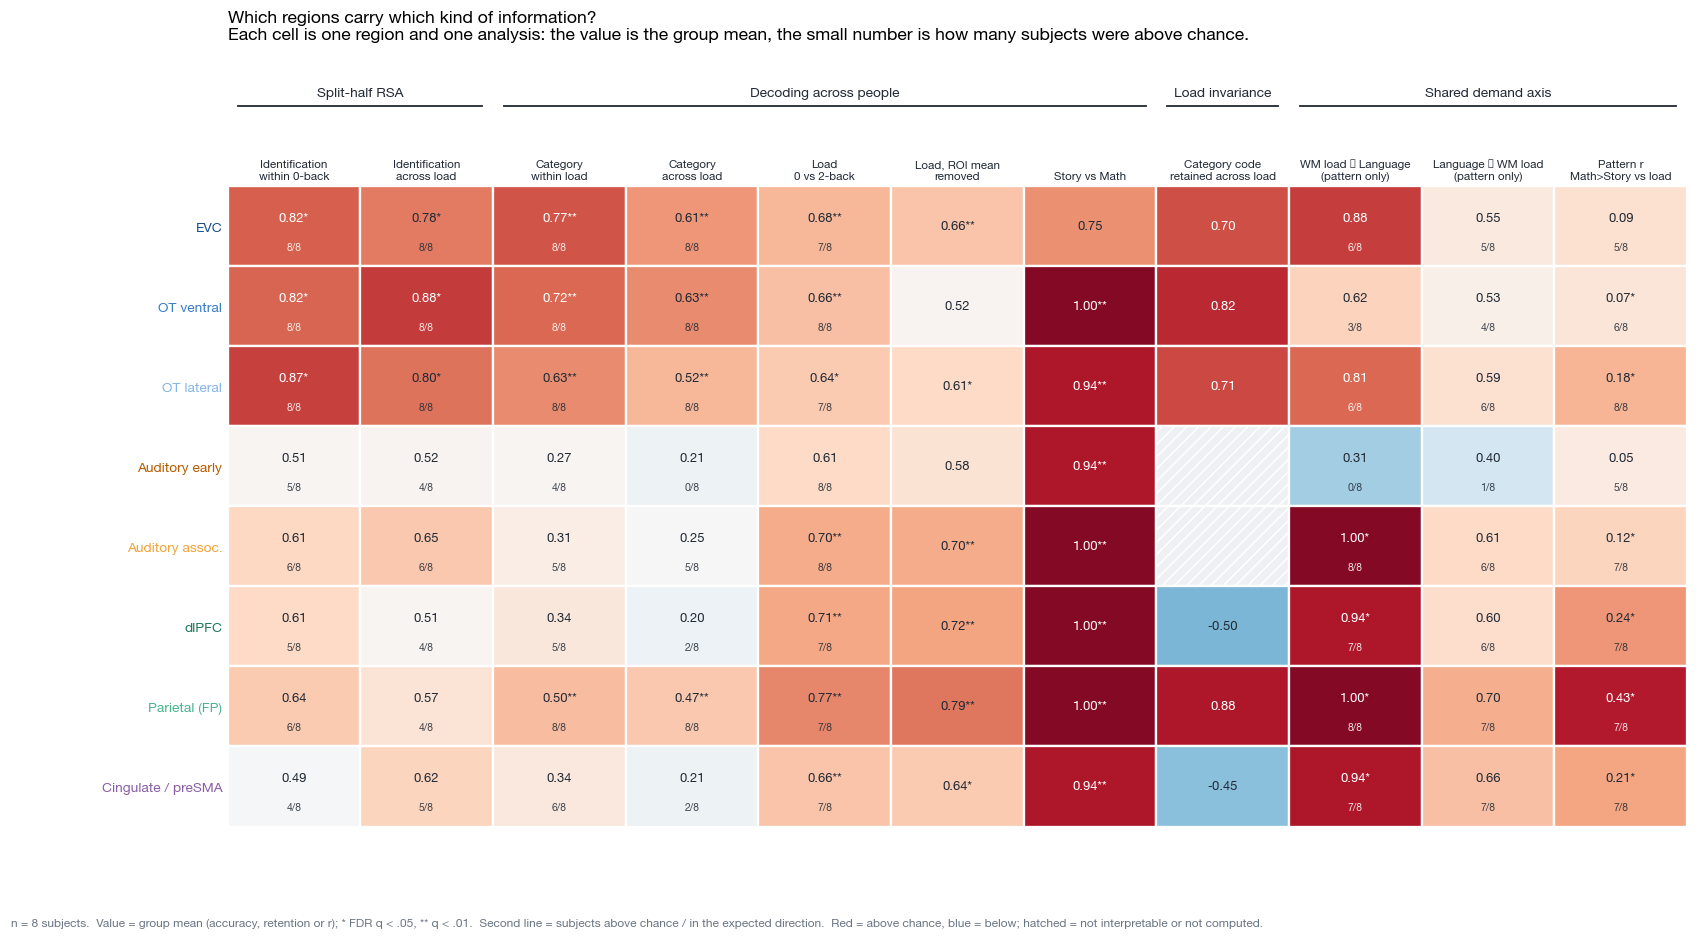

In [42]:
# =============================================================================
# STAGE 16a - ONE-PAGE SUMMARY FIGURE: ROI x analysis
# =============================================================================
# The whole project on one page. Colour is effect size relative to that analysis's own chance level (red above,
# blue below), the first line in each cell is the value with FDR stars, and the second small line is the number of
# subjects above chance - which is there to stop a red cell carried by two subjects from looking like a group
# finding. Grey hatching means the quantity was not interpretable or was not computed, which is deliberately
# distinguished from "computed and found to be zero".
# Every column is built with a try/except, so the figure still draws if an earlier stage was skipped.
n_subj = len(SUBJECTS)
cols = []     # (group, title, chance, vmax, {roi: (value, q, k_positive)})


def add(group, title, chance, vmax, getter):
    d = {}
    for roi in ROI_ORDER:
        try:
            d[roi] = getter(roi)
        except Exception:
            d[roi] = (np.nan, np.nan, None)
    cols.append((group, title, chance, vmax, d))


def _dec(names, chance):
    def g(roi):
        sub = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.isin(names)]
        per = np.mean([subj_acc[(roi, n)] for n in names], axis=0)
        return float(sub.mean_acc.mean()), float(sub.q_fdr.max()), int((per > chance).sum())
    return g


if "wm_group" in globals() and "wm_res" in globals():
    for m, t in (("id_0back", "Identification\nwithin 0-back"), ("id_cross_load", "Identification\nacross load")):
        add("Split-half RSA", t, .5, 1.0, lambda roi, m=m: (float(wm_group[(wm_group.roi == roi) & (wm_group.metric == m)].mean_acc.iloc[0]),
                                                            float(wm_group[(wm_group.roi == roi) & (wm_group.metric == m)].q_fdr.iloc[0]),
                                                            int((wm_res[wm_res.roi == roi][m] > .5).sum())))
if "wm_dec" in globals():
    add("Decoding across people", "Category\nwithin load", .25, 1.0, _dec(["category | 0-back -> 0-back", "category | 2-back -> 2-back"], .25))
    add("Decoding across people", "Category\nacross load", .25, 1.0, _dec(["category | 0-back -> 2-back", "category | 2-back -> 0-back"], .25))
    add("Decoding across people", "Load\n0 vs 2-back", .5, 1.0, _dec(["load (0- vs 2-back)"], .5))
if "amp_df" in globals():
    add("Decoding across people", "Load, ROI mean\nremoved", .5, 1.0,
        lambda roi: (float(amp_df[amp_df.roi == roi].acc_pattern_only.iloc[0]), float(amp_df[amp_df.roi == roi].q_pattern_only.iloc[0]), None))
if "lang_dec" in globals():
    add("Decoding across people", "Story vs Math", .5, 1.0, lambda roi: (float(lang_dec[lang_dec.roi == roi].mean_acc.iloc[0]), float(lang_dec[lang_dec.roi == roi].q_fdr.iloc[0]), None))
if "retention_df" in globals():
    def _ret(roi):
        r = retention_df[retention_df.roi == roi].iloc[0]
        return (float(r.retention) if r.within_code_reliable else np.nan, np.nan, None)
    add("Load invariance", "Category code\nretained across load", 0.0, 1.0, _ret)
if "xt_mean" in globals():
    for direction, title in (("WM load -> Language", "WM load → Language\n(pattern only)"), ("Language -> WM load", "Language → WM load\n(pattern only)")):
        def _xt(roi, direction=direction):
            r = xt_mean[(xt_mean.roi == roi) & (xt_mean.direction == direction) & (xt_mean.version == "pattern only")].iloc[0]
            return float(r.mean_acc), float(r.q_fdr), int(r.n_above_chance)
        add("Shared demand axis", title, .5, 1.0, _xt)
if "demand_group" in globals():
    add("Shared demand axis", "Pattern r\nMath>Story vs load", 0.0, 0.5,
        lambda roi: (float(demand_group[demand_group.roi == roi].mean_r.iloc[0]), float(demand_group[demand_group.roi == roi].q_fdr.iloc[0]),
                     int(demand_group[demand_group.roi == roi].n_positive.iloc[0])))

fig, ax = plt.subplots(figsize=(1.32 * len(cols) + 2.6, 0.62 * len(ROI_ORDER) + 2.6))
ax.grid(False)
cmap = plt.cm.RdBu_r
for j, (grp, title, chance, vmax, d) in enumerate(cols):
    for i, roi in enumerate(ROI_ORDER):
        v, q, k = d[roi]
        if not np.isfinite(v):
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor="#EEF0F3", hatch="///", edgecolor="white", lw=1.5))
            continue
        eff = np.clip((v - chance) / (vmax - chance), -1, 1)
        ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor=cmap(0.5 + 0.46 * eff), edgecolor="white", lw=1.5))
        txt_col = "white" if abs(eff) > .62 else INK
        ax.text(j, i - (.1 if k is not None else 0), f"{v:.2f}{stars(q)}", ha="center", va="center", fontsize=8.5, color=txt_col,
                fontweight="bold" if stars(q) else "normal")
        if k is not None:
            ax.text(j, i + .26, f"{k}/{n_subj}", ha="center", va="center", fontsize=6.8, color=txt_col, alpha=.85)
ax.set_xlim(-.5, len(cols) - .5); ax.set_ylim(len(ROI_ORDER) - .5, -.5)
ax.set_xticks(range(len(cols))); ax.set_xticklabels([c[1] for c in cols], fontsize=7.6); ax.xaxis.tick_top()
ax.set_yticks(range(len(ROI_ORDER))); ax.set_yticklabels([ROI_NAME[r] for r in ROI_ORDER], fontsize=9)
for t, r in zip(ax.get_yticklabels(), ROI_ORDER):
    t.set_color(ROI_COLORS[r]); t.set_fontweight("bold")
for sp in ax.spines.values():
    sp.set_visible(False)
ax.tick_params(length=0)
# group headers above the column titles
start = 0
for j in range(1, len(cols) + 1):
    if j == len(cols) or cols[j][0] != cols[start][0]:
        ax.annotate(cols[start][0], xy=((start + j - 1) / 2, 1.14), xycoords=("data", "axes fraction"), ha="center", fontsize=9, fontweight="bold", color=INK)
        ax.plot([start - .42, j - 1 + .42], [1.125, 1.125], transform=ax.get_xaxis_transform(), color=INK, lw=1.2, clip_on=False)
        start = j
fig.text(0.01, 0.0, f"n = {n_subj} subjects.  Value = group mean (accuracy, retention or r); * FDR q < .05, ** q < .01.  Second line = subjects above chance / in the expected direction.  "
         "Red = above chance, blue = below; hatched = not interpretable or not computed.", fontsize=7.8, color=MUTED, ha="left", va="top")
ax.set_title("Which regions carry which kind of information?\n"
             "Each cell is one region and one analysis: the value is the group mean, the small number is how many subjects were above chance.",
             loc="left", pad=96, fontsize=11.5)
save_fig(fig, "summary_roi_by_analysis.png")


In [43]:
# =============================================================================
# STAGE 16b - PLAIN-LANGUAGE READOUT
# =============================================================================
# One short paragraph per ROI, in words, generated from the tables above rather than written by hand - so it cannot
# drift out of date when a number changes. It adds no new test and introduces no new threshold: "reliable" means
# FDR q < 0.05 within that analysis family, exactly as in the tables. The text and a tidy one-row-per-ROI table are
# written to derivatives/novelty/ for use in the report.
def _row(df, **kw):
    if df is None:
        return None
    q = df
    for k, v in kw.items():
        q = q[q[k] == v]
    return q.iloc[0] if len(q) else None


have = lambda n: n in globals() and isinstance(globals()[n], pd.DataFrame)
lines, table = [], []
for roi in ROI_ORDER:
    parts = [f"{ROI_NAME[roi]} ({ROI_GROUP[roi].lower()})"]
    rec = dict(roi=roi)
    # category
    cat = wm_dec[(wm_dec.roi == roi) & wm_dec.analysis.str.startswith("category")]
    cat_ok = bool((cat.q_fdr < .05).all())
    if cat_ok and have("retention_df"):
        r = _row(retention_df, roi=roi)
        s = f"  category: reliable in all four load pairings (within {r.within_acc:.2f}, across load {r.cross_acc:.2f}; chance 0.25)"
        if r.within_code_reliable and np.isfinite(r.retention):
            s += f"; keeps {100 * r.retention:.0f}% of its above-chance accuracy across load (95% CI {100 * r.retention_ci_lo:.0f}-{100 * r.retention_ci_hi:.0f}%)"
        if r.p_tost < .05:
            s += f"; the loss across load is equivalent to zero for margins >= {r.m_min:.2f}"
        parts.append(s + ".")
        rec["category"] = f"reliable, within {r.within_acc:.2f} / across {r.cross_acc:.2f}"
    elif (cat.q_fdr < .05).any():
        parts.append(f"  category: reliable in {int((cat.q_fdr < .05).sum())} of 4 load pairings only (best {cat.mean_acc.max():.2f}).")
        rec["category"] = "partial"
    else:
        parts.append(f"  category: not reliably decodable (best {cat.mean_acc.max():.2f}, chance 0.25).")
        rec["category"] = "none"
    if have("loco_summary"):
        ls = loco_summary[loco_summary.roi == roi]
        if len(ls) and bool(ls.all_four_reliable.any()):
            surv = bool(ls[ls.all_four_reliable].survives_every_drop.all())
            parts.append("  one-category check: " + ("the code survives dropping each category in turn." if surv else
                         "the code does NOT survive dropping every category (see leave-one-category-out; worst drop: "
                         + ", ".join(sorted(set(ls[ls.all_four_reliable & ~ls.survives_every_drop].worst_drop))) + ")."))
    # load
    ld = _row(wm_dec, roi=roi, analysis="load (0- vs 2-back)")
    am = _row(amp_df, roi=roi) if have("amp_df") else None
    if ld.q_fdr < .05:
        kind = ""
        if am is not None:
            kind = " It is carried by the spatial pattern (survives ROI-mean removal)." if am.q_pattern_only < .05 else \
                   f" It is mostly an average-activation effect (ROI-mean change positive in {am.n_subjects_positive}/{len(SUBJECTS)} subjects)."
        parts.append(f"  load: decodable ({ld.mean_acc:.2f}, q = {ld.q_fdr:.3f}).{kind}")
        rec["load"] = f"{ld.mean_acc:.2f}" + (" pattern" if am is not None and am.q_pattern_only < .05 else " amplitude")
    else:
        parts.append(f"  load: not reliably decodable ({ld.mean_acc:.2f}, q = {ld.q_fdr:.3f}).")
        rec["load"] = "none"
    # language and demand axis
    if have("lang_dec"):
        l = _row(lang_dec, roi=roi)
        parts.append(f"  Story vs Math: {l.mean_acc:.2f} ({'reliable' if l.q_fdr < .05 else 'not reliable'}).")
    if have("xt_mean"):
        a = _row(xt_mean, roi=roi, direction="WM load -> Language", version="pattern only")
        b = _row(xt_mean, roi=roi, direction="Language -> WM load", version="pattern only")
        parts.append(f"  cross-task, pattern only: WM→Language {a.mean_acc:.2f} ({a.n_above_chance}/{a.n_subjects} subjects), "
                     f"Language→WM {b.mean_acc:.2f} ({b.n_above_chance}/{b.n_subjects}).")
        rec["xtask_pattern"] = f"{a.mean_acc:.2f} / {b.mean_acc:.2f}"
    if have("demand_group"):
        dgr = _row(demand_group, roi=roi)
        parts.append(f"  shared load/Math pattern: r = {dgr.mean_r:.2f} ({dgr.n_positive}/{dgr.n_subjects} subjects positive; "
                     f"{'reliable' if dgr.q_fdr < .05 else 'not reliable'}).")
        rec["demand_r"] = round(float(dgr.mean_r), 3)
    lines.append("\n".join(parts)); table.append(rec)
readout = "\n\n".join(lines)
print(readout)
print(f"\n(n = {len(SUBJECTS)} subjects; smallest possible sign-flip p = {2 / 2 ** len(SUBJECTS):.4f}. 'Reliable' = FDR q < .05 within the analysis family. Exploratory.)")
findings = pd.DataFrame(table)
findings.to_csv(os.path.join(NOVELTY_DIR, "findings_by_roi.csv"), index=False)
with open(os.path.join(NOVELTY_DIR, "findings_readout.txt"), "w") as fh:
    fh.write(readout)


EVC (visual)
  category: reliable in all four load pairings (within 0.77, across load 0.61; chance 0.25); keeps 70% of its above-chance accuracy across load (95% CI 61-79%).
  one-category check: the code survives dropping each category in turn.
  load: decodable (0.68, q = 0.002). It is carried by the spatial pattern (survives ROI-mean removal).
  Story vs Math: 0.75 (not reliable).
  cross-task, pattern only: WM→Language 0.88 (6/8 subjects), Language→WM 0.55 (5/8).
  shared load/Math pattern: r = 0.09 (5/8 subjects positive; not reliable).

OT ventral (visual)
  category: reliable in all four load pairings (within 0.72, across load 0.63; chance 0.25); keeps 82% of its above-chance accuracy across load (95% CI 73-87%).
  one-category check: the code survives dropping each category in turn.
  load: decodable (0.66, q = 0.004). It is mostly an average-activation effect (ROI-mean change positive in 0/8 subjects).
  Story vs Math: 1.00 (reliable).
  cross-task, pattern only: WM→Language 0